# Kidney Perturbation Analysis

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 28.01.2026
- Date of Last Modification: 01.02.2026 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import pickle
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scanpy as sc
import scipy.sparse as sp
import torch
from datasets import load_from_disk

#from app.count_decoder import apply_count_decoder
from app.infer import embed_dataset, harmonize_tokenize_embed_pipeline, perturb_dataset
from nichejepa.preprocessors import construct_neighbor_graph

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## 1.2 Define Config/Params

In [3]:
# Define paths
model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11012026_190057_836' # cross-tissue model
#model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614' # benchmarking model
gene_ensembl_map_file_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
kidney_perturbation_folder_path = '/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/kidney_perturbation'
cache_directory_path = f'{kidney_perturbation_folder_path}/cache'
results_directory_path = f'{kidney_perturbation_folder_path}/results'
tokenized_data_directory_path = f'{kidney_perturbation_folder_path}/tokenized_data'

In [4]:
cell_type_key = "scANVI_pred"
niche_key = "NEMO_neighborhood_annotation"
batch_key = 'Study_slice_id'

emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_genes = None
top_k = None

## 1.3 Run Notebook Setup

In [5]:
torch.set_printoptions(threshold=float('inf'))

In [6]:
os.makedirs(tokenized_data_directory_path, exist_ok=True)
os.makedirs(f'{results_directory_path}/figures', exist_ok=True)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [9]:
sc.settings.figdir = f'{results_directory_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(6, 4),
    facecolor='white',
    fontsize=10
)

## 1.4 Define Functions

In [10]:
def cosine_sim_per_row(A, B, eps=1e-12):
    """
    Row-wise cosine similarity between A and B (shape: [n, d]).
    Handles zero-norm rows safely via eps.
    """
    A = np.asarray(A)
    B = np.asarray(B)

    A_norm = np.linalg.norm(A, axis=1, keepdims=True)
    B_norm = np.linalg.norm(B, axis=1, keepdims=True)

    A_unit = A / np.maximum(A_norm, eps)
    B_unit = B / np.maximum(B_norm, eps)

    return np.sum(A_unit * B_unit, axis=1)

In [11]:
def analyze_embedding_cos_sims(
    adata,
    pairs=None,
    bins=50,
    show=True,
    save_dir=None,
    prefix="",
    eps=1e-12,
    ignore_zeros=False,
):
    """
    Compute row-wise cosine similarities for multiple (A_key, B_key) pairs in adata.obsm,
    print mean/min, and optionally plot + save histograms.

    Parameters
    ----------
    ignore_zeros : bool
        If True, compute mean/min over nonzero cosine similarities only.

    Returns
    -------
    results : dict[str, np.ndarray]
        Mapping from name -> cosine similarity vector (length n_obs).
    summary : dict[str, dict[str, float]]
        Mapping from name -> {"mean": ..., "min": ...}
    """
    if pairs is None:
        pairs = [
            ("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
            ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
            ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb"),
        ]

    results = {}
    summary = {}

    for A_key, B_key, name in pairs:
        A = adata.obsm[A_key]
        B = adata.obsm[B_key]

        sims = cosine_sim_per_row(A, B, eps=eps)

        if ignore_zeros:
            nz = sims != 0
            if np.any(nz):
                mean_v = float(np.mean(sims[nz]))
                min_v = float(np.min(sims[nz]))
            else:
                mean_v = float("nan")
                min_v = float("nan")
        else:
            mean_v = float(np.mean(sims))
            min_v = float(np.min(sims))

        results[name] = sims
        summary[name] = {"mean": mean_v, "min": min_v}

        suffix = " (nonzero)" if ignore_zeros else ""
        print(f"{name}{suffix}: mean={mean_v:.6f}  min={min_v:.6f}")

        plt.figure()
        plt.hist(sims, bins=bins)
        plt.title(f"{prefix}{name} cosine similarity")
        plt.xlabel("cosine similarity")
        plt.ylabel("count")
        plt.tight_layout()

        if save_dir is not None:
            fname = f"{prefix}{name}_cos_sim_hist.png" if prefix else f"{name}_cos_sim_hist.png"
            plt.savefig(f"{save_dir.rstrip('/')}/{fname}", dpi=200)

        if show:
            plt.show()
        else:
            plt.close()

    return results, summary

In [12]:
def summarize_cosine_sim_by_label(
    adata,
    label_key,
    labels=None,
    pairs=None,
    agg="mean",
    sort_by=None,
    ascending=True,
    eps=1e-12,
    ignore_zeros=False,
):
    """
    Compute cosine similarity (row-wise) between embedding pairs in adata.obsm,
    aggregate per label in adata.obs[label_key], and return a sorted DataFrame.

    Parameters
    ----------
    ignore_zeros : bool
        If True, aggregate only over nonzero cosine similarities.
    """
    if pairs is None:
        pairs = [
            ("cell_emb", "cell_emb_perturb_case1", "cell_emb_cos_sim"),
            ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb_cos_sim"),
            ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb_cos_sim"),
        ]

    if labels is None:
        labels = sorted(pd.unique(adata.obs[label_key]))

    if isinstance(agg, str):
        agg_name = agg.lower()
        if agg_name == "min":
            agg_fn = np.min
        elif agg_name == "mean":
            agg_fn = np.mean
        elif agg_name == "median":
            agg_fn = np.median
        else:
            raise ValueError("agg must be 'min', 'mean', 'median', or a callable")
    elif callable(agg):
        agg_fn = agg
    else:
        raise ValueError("agg must be 'min', 'mean', 'median', or a callable")

    rows = []
    for label in labels:
        adata_sub = adata[adata.obs[label_key] == label]

        row = {
            "label": label,
            "n_cells": int(adata_sub.n_obs),
        }

        for A_key, B_key, out_col in pairs:
            sims = cosine_sim_per_row(
                adata_sub.obsm[A_key],
                adata_sub.obsm[B_key],
                eps=eps,
            )

            if ignore_zeros:
                sims = sims[sims != 0]

            if sims.size == 0:
                row[out_col] = float("nan")
            else:
                row[out_col] = float(agg_fn(sims))

        rows.append(row)

    df = pd.DataFrame(rows)

    if sort_by is not None:
        df = df.sort_values(by=sort_by, ascending=ascending).reset_index(drop=True)

    return df


In [13]:
def plot_perturbation_counts(
    dataset,
    flag_prefix="pert_flag_idx_",
    count_column="perturbation_count",
    batch_size=50_000,
    num_proc=None,
    add_column=True,
):
    """
    Count how many perturbations affect each cell in a Hugging Face Dataset
    and plot a bar chart of the counts.

    Parameters
    ----------
    dataset : datasets.Dataset
        Hugging Face dataset with perturbation flag columns.
    flag_prefix : str
        Prefix of perturbation flag columns.
    count_column : str
        Name of the output column containing per-cell perturbation counts.
    batch_size : int
        Batch size for dataset.map.
    num_proc : int or None
        Number of processes for parallel map.
    add_column : bool
        Whether to add the count column back to the dataset.

    Returns
    -------
    dataset : datasets.Dataset
        Dataset with added count column (if add_column=True).
    counts : np.ndarray
        Array of per-cell perturbation counts.
    """

    # 1) find perturbation flag columns
    flag_cols = [c for c in dataset.column_names if c.startswith(flag_prefix)]
    if not flag_cols:
        raise ValueError(f"No columns found starting with '{flag_prefix}'")

    # 2) compute per-cell counts
    def add_counts(batch):
        flags = np.stack(
            [np.asarray(batch[c], dtype=np.bool_) for c in flag_cols],
            axis=1,
        )
        batch[count_column] = flags.sum(axis=1).astype(np.int32)
        return batch

    dataset_out = dataset
    if add_column:
        dataset_out = dataset.map(
            add_counts,
            batched=True,
            batch_size=batch_size,
            num_proc=num_proc,
        )

    # 3) collect counts
    if add_column:
        counts = np.asarray(dataset_out[count_column], dtype=np.int32)
    else:
        # compute counts without modifying dataset
        counts = np.concatenate(
            dataset.map(
                add_counts,
                batched=True,
                batch_size=batch_size,
                num_proc=num_proc,
                remove_columns=dataset.column_names,
            )[count_column]
        )

    # 4) plot bar chart
    values, frequencies = np.unique(counts, return_counts=True)

    plt.figure()
    plt.bar(values, frequencies)
    plt.xlabel("Number of perturbations affecting the cell")
    plt.ylabel("Number of cells")
    plt.title("Perturbation count per cell")
    plt.xticks(values)
    plt.tight_layout()
    plt.show()

    return dataset_out, counts

In [14]:
def plot_cells_per_perturbation(
    dataset,
    flag_prefix="pert_flag_idx_",
    batch_size=50_000,
):
    """
    Plot how many cells are affected by each perturbation.

    X-axis: perturbation index
    Y-axis: number of affected cells
    """

    # 1) find perturbation flag columns (keep order!)
    flag_cols = sorted(
        [c for c in dataset.column_names if c.startswith(flag_prefix)],
        key=lambda x: int(x.split("_")[-1]),
    )

    if not flag_cols:
        raise ValueError(f"No columns found starting with '{flag_prefix}'")

    n_flags = len(flag_cols)
    counts = np.zeros(n_flags, dtype=np.int64)

    # 2) iterate in batches (streaming-friendly, no dataset copy)
    for batch in dataset.iter(batch_size=batch_size):
        flags = np.stack(
            [np.asarray(batch[c], dtype=np.bool_) for c in flag_cols],
            axis=1,
        )
        counts += flags.sum(axis=0)

    # 3) plot
    x = np.arange(n_flags)

    plt.figure()
    plt.bar(x, counts)
    plt.xlabel("Perturbation index")
    plt.ylabel("Number of affected cells")
    plt.title("Cells affected per perturbation")
    plt.xticks(x)
    plt.tight_layout()
    plt.show()

    return counts

# 2. Analysis

## 2.1 Load Data

In [15]:
# Load original raw data
adata = sc.read_h5ad(
    "/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/NEMO_UpdatedTokenisationandEmbedding_November22nd25/Labeltransfer/forshare/nemokidneyxeniumatlas_annotated.h5ad")
adata

AnnData object with n_obs × n_vars = 1517894 × 4949
    obs: 'cell_id', 'Study_slice_id', 'NEMO_K_SLICE_ID', 'NEMO_K_PATIENT_ID', 'Corpus_ID', 'Study_patient_id', 'Data_source', 'Platform', 'Tissue_subregion', 'Status', 'Diagnosis', 'Type', 'Age', 'Age_grouping', 'Sex', 'eGFR', 'eGFR_group', 'BMI', 'Obesity_status', 'eGFR baseline', 'eGFR change', 'RCC_Treatment', 'batch', 'NEMO_cell_label', 'NEMO_neighborhood_label', 'tech', 'scANVI_pred', 'scANVI_confidence', 'slice', 'NEMO_neighborhood_annotation', 'leiden', 'highlight_neigh'
    uns: 'Data_source_colors', 'NEMO_K_PATIENT_ID_colors', 'NEMO_cell_label_colors', 'NEMO_neighborhood_annotation_colors', 'NEMO_neighborhood_label_colors', 'Obesity_status_colors', 'Sex_colors', 'eGFR_group_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'rank_genes_groups', 'scANVI_pred_colors', 'umap'
    obsm: 'X_umap', 'cell_emb', 'cell_umap', 'neighborhood_emb', 'neighborhood_umap', 'spatial'
    layers: 'counts', 'lognorm'
    obsp: 'connectiv

In [16]:
# Check columns
adata.obs.head(1)

,cell_id,Study_slice_id,NEMO_K_SLICE_ID,NEMO_K_PATIENT_ID,Corpus_ID,Study_patient_id,Data_source,Platform,Tissue_subregion,Status,...,batch,NEMO_cell_label,NEMO_neighborhood_label,tech,scANVI_pred,scANVI_confidence,slice,NEMO_neighborhood_annotation,leiden,highlight_neigh
CV9-KID-0-FT-5-S4_1007_batch22_0-slice0,1007_batch22_0,CV9-KID-0-FT-5-S4,K002,P002,xhk1007-CV9-41b_1p,CV9,DIAMOND,Xenium 5k,na,Healthy,...,CV9-KID-0-FT-5-S4_with_emb_NEMO_common_qc,72,4,Xenium 5k,Vascular mural cell,0.485031,0,Distal nephron neighborhood,13,0


In [17]:
# List samples
# CV*** -> pre-treatment
# DI*** -> post-treatment
adata.obs[['Study_slice_id', 'Data_source']].drop_duplicates()

,Study_slice_id,Data_source
CV9-KID-0-FT-5-S4_1007_batch22_0-slice0,CV9-KID-0-FT-5-S4,DIAMOND
CV1-KID-0-FT-5-S6_aaaajpak-1-slice1,CV1-KID-0-FT-5-S6,DIAMOND
CV7-KID-0-FT-5-S5_aaabiano-1-slice2,CV7-KID-0-FT-5-S5,DIAMOND
DI15-KID-0-FT-3_aaaaifma-1-slice3,DI15-KID-0-FT-3,ACED
CV1-KID-0-FT-5-S5_aaachdbk-1-slice4,CV1-KID-0-FT-5-S5,DIAMOND
DI13-KID-0-FT-3_aaabbfck-1-slice5,DI13-KID-0-FT-3,ACED
CV9-KID-0-FT-5_aaaalbcc-1-slice6,CV9-KID-0-FT-5,DIAMOND
DI14-KID-0-FT-2_aaabhged-1-slice7,DI14-KID-0-FT-2,ACED
CV5-KID-0-FT-5_aaaabcmf-1-slice8,CV5-KID-0-FT-5,DIAMOND
CV6-KID-0-FT-5-S3_1007_batch24_0-slice9,CV6-KID-0-FT-5-S3,DIAMOND


In [18]:
# Compute sample-wise neighbor graph, concatenate, and store in adata.obsp['spatial_connectivities']
adata = construct_neighbor_graph(
    adata,
    n_neighs=10,
    radius=None,
    delaunay=False,
    include_self_loop=False,
    compute_neighbor_counts=False,
    batch_key=batch_key
)

# Compute raw neighborhood counts
adata.layers['counts_neighborhood'] = (
    adata.obsp['spatial_connectivities'].T @ adata.layers['counts'])
print(adata.layers['counts_neighborhood'][:30].toarray())
adata.layers['counts_neighborhood'] += adata.layers['counts'] # add counts from the index cell
print(adata.layers['counts_neighborhood'][:30].toarray())

# Compute lognorm neighborhood counts (performing same normalization as on raw counts)
adata.X = adata.layers["counts_neighborhood"].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["lognorm_neighborhood"] = adata.X.copy()
adata.X = adata.layers["lognorm"].copy()

/nfs/team361/sb75/nichejepa/src/nichejepa/preprocessors/graph.py:109: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  first_idx = adata.obs.reset_index().groupby(batch_key).head(1).index



Processing batch CV9-KID-0-FT-5-S4...
Loading data...
Computing spatial neighborhood graph...


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/squidpy/gr/_utils.py:203: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data



Processing batch CV1-KID-0-FT-5-S6...
Loading data...
Computing spatial neighborhood graph...


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/squidpy/gr/_utils.py:203: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data



Processing batch CV7-KID-0-FT-5-S5...
Loading data...
Computing spatial neighborhood graph...


... (22 outputs left out)

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/squidpy/gr/_utils.py:203: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data



Processing batch DI16-KID-0-FT-1...
Loading data...
Computing spatial neighborhood graph...


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/squidpy/gr/_utils.py:203: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


[[ 0.  5.  0. ...  0.  0.  0.]
 [ 0. 10.  0. ...  0.  0.  2.]
 [ 0. 10.  0. ...  0.  0.  4.]
 ...
 [ 0. 11.  0. ...  0.  1.  1.]
 [ 0. 11.  0. ...  0.  1.  1.]
 [ 0.  9.  0. ...  0.  0.  1.]]
[[ 0.  5.  0. ...  0.  0.  0.]
 [ 0. 10.  0. ...  0.  0.  4.]
 [ 0. 10.  0. ...  0.  0.  4.]
 ...
 [ 0. 11.  0. ...  0.  1.  1.]
 [ 0. 12.  0. ...  0.  1.  1.]
 [ 0. 10.  0. ...  0.  1.  1.]]


In [19]:
# Validate that everything is ok
print(adata.obsp['spatial_connectivities'].sum(1))
n = 30
print(adata.layers['counts_neighborhood'][:30].toarray())
print(adata.layers['lognorm_neighborhood'][:30].toarray())
print(adata.layers['counts'][:30].toarray())
print(adata.layers['lognorm'][:30].toarray())
print(adata.X[:30].toarray())

[[10.]
 [10.]
 [10.]
 ...
 [10.]
 [10.]
 [10.]]
[[ 0.  5.  0. ...  0.  0.  0.]
 [ 0. 10.  0. ...  0.  0.  4.]
 [ 0. 10.  0. ...  0.  0.  4.]
 ...
 [ 0. 11.  0. ...  0.  1.  1.]
 [ 0. 12.  0. ...  0.  1.  1.]
 [ 0. 10.  0. ...  0.  1.  1.]]
[[0.         2.42056404 0.         ... 0.         0.         0.        ]
 [0.         2.80856107 0.         ... 0.         0.         1.97884936]
 [0.         2.83849962 0.         ... 0.         0.         2.0063387 ]
 ...
 [0.         3.0930666  0.         ... 0.         1.06923267 1.06923267]
 [0.         2.91903288 0.         ... 0.         0.90027532 0.90027532]
 [0.         3.15882137 0.         ... 0.         1.17997202 1.17997202]]
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 2.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 1. 0.]]
[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         3.58765993]
 [0.         0

In [20]:
# Add ensembl IDs to AnnData object
with open(gene_ensembl_map_file_path, "rb") as f:
    gene_ensembl_map_dict = pickle.load(f)

gene_names = [gene_name for gene_name in adata.var_names.tolist()]
adata.var.index = gene_names

harmonized_gene_names = []
matching_ensembl_ids = []
for gene_name in gene_names:
    if gene_name in gene_ensembl_map_dict.keys():
        harmonized_gene_names.append(gene_name)
        matching_ensembl_ids.append(gene_ensembl_map_dict[gene_name])

adata.var['ensembl_id'] = matching_ensembl_ids
adata.var

,ensembl_id
A2ML1,ENSG00000166535
AAMP,ENSG00000127837
AAR2,ENSG00000131043
AARSD1,ENSG00000266967
ABAT,ENSG00000183044
...,...
ZSCAN26,ENSG00000197062
ZSWIM6,ENSG00000130449
ZUP1,ENSG00000153975
ZYG11B,ENSG00000162378


In [21]:
# Write AnnData to disk
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

## 2.2 Compute Differential Genes Between Pre- and Post-treatment Conditions

Check https://docs.google.com/spreadsheets/d/1i6p3QRTE5Lh32AejWE6Xg2Sye6p3yP7vDdrCMDbLj_I/edit?gid=1921994032#gid=1921994032 for perturbation cases to be tested.

In [ ]:
# Load processed AnnData
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

### 2.2.1 Perturbation Case 1

In [ ]:
sid = adata.obs["Study_slice_id"].astype(str)

adata.obs["DI12_vs_CV"] = np.nan
adata.obs.loc[sid.eq("DI12-KID-0-FT-4"), "DI12_vs_CV"] = "DI12"
adata.obs.loc[sid.str.startswith("CV"), "DI12_vs_CV"] = "CV"

adata.obs["DI12_vs_CV"] = adata.obs["DI12_vs_CV"].astype("category")
adata.obs["DI12_vs_CV"].value_counts(dropna=False)

In [ ]:
# Compute differential genes for cell counts (across all cells -> global)
sc.tl.rank_genes_groups(
    adata,
    groupby="DI12_vs_CV",
    groups=["DI12"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case1_global_pre_post_cell_counts",
)

# Retrieve differential genes for cell counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI12", key="rank_genes_groups_case1_global_pre_post_cell_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_global_pre_post_cell_counts.csv")

In [ ]:
# Compute differential genes for cell counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI12 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI12_vs_CV"].isin(["DI12", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI12/CV cells)", "n_DI12": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI12_vs_CV"].value_counts()
    n_di12 = int(counts.get("DI12", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di12 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI12": n_di12,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case1_niche={cat}_pre_post_cell_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI12_vs_CV",
        groups=["DI12"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for cell counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI12", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_niche_{cat}_pre_post_cell_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI12": n_di12,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case1_pre_post_cell_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case1_pre_post_cell_counts_summary_by_niche"]

In [ ]:
# Compute differential genes for neighborhood counts
adata.X = adata.layers['lognorm_neighborhood'].copy()
sc.tl.rank_genes_groups(
    adata,
    groupby="DI12_vs_CV",
    groups=["DI12"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case1_global_pre_post_neighborhood_counts",
)

# Retrieve differential genes for neighborhood counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI12", key="rank_genes_groups_case1_global_pre_post_neighborhood_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_pre_post_neighborhood_counts.csv")

In [ ]:
# Compute differential genes for neighborhood counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI12 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI12_vs_CV"].isin(["DI12", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI12/CV cells)", "n_DI12": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI12_vs_CV"].value_counts()
    n_di12 = int(counts.get("DI12", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di12 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI12": n_di12,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case1_niche={cat}_pre_post_neighborhood_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI12_vs_CV",
        groups=["DI12"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for cell counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI12", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_niche_{cat}_pre_post_neighborhood_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI12": n_di12,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case1_pre_post_neighborhood_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case1_pre_post_neighborhood_counts_summary_by_niche"]

In [ ]:
adata.X = adata.layers['lognorm'].copy()

In [ ]:
# Write AnnData to disk
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

### 2.2.2 Perturbation Case 2

In [ ]:
# Load processed AnnData
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

In [ ]:
sid = adata.obs["Study_slice_id"].astype(str)

adata.obs["DI10_vs_CV"] = np.nan
adata.obs.loc[sid.eq("DI10-KID-0-FT-5"), "DI10_vs_CV"] = "DI10"
adata.obs.loc[sid.str.startswith("CV"), "DI10_vs_CV"] = "CV"

adata.obs["DI10_vs_CV"] = adata.obs["DI10_vs_CV"].astype("category")
adata.obs["DI10_vs_CV"].value_counts(dropna=False)

In [ ]:
# Compute differential genes for cell counts (across all cells -> global)
sc.tl.rank_genes_groups(
    adata,
    groupby="DI10_vs_CV",
    groups=["DI10"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case2_global_pre_post_cell_counts",
)

# Retrieve differential genes for cell counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI10", key="rank_genes_groups_case2_global_pre_post_cell_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_global_pre_post_cell_counts.csv")

In [ ]:
# Compute differential genes for cell counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI10 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI10_vs_CV"].isin(["DI10", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI10/CV cells)", "n_DI10": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI10_vs_CV"].value_counts()
    n_di10 = int(counts.get("DI10", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di10 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI10": n_di10,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case2_niche={cat}_pre_post_cell_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI10_vs_CV",
        groups=["DI10"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for cell counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI10", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_niche_{cat}_pre_post_cell_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI10": n_di10,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case2_pre_post_cell_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case2_pre_post_cell_counts_summary_by_niche"]

In [ ]:
# Compute differential genes for neighborhood counts (across all cells -> global)
adata.X = adata.layers['lognorm_neighborhood'].copy()
sc.tl.rank_genes_groups(
    adata,
    groupby="DI10_vs_CV",
    groups=["DI10"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case2_global_pre_post_neighborhood_counts",
)

# Retrieve differential genes for neighborhood counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI10", key="rank_genes_groups_case2_global_pre_post_neighborhood_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_global_pre_post_neighborhood_counts.csv")

In [ ]:
# Compute differential genes for neighborhood counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI10 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI10_vs_CV"].isin(["DI10", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI10/CV cells)", "n_DI10": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI10_vs_CV"].value_counts()
    n_di10 = int(counts.get("DI10", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di10 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI10": n_di10,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case2_niche={cat}_pre_post_neighborhood_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI10_vs_CV",
        groups=["DI10"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for neighborhood counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI10", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_niche_{cat}_pre_post_neighborhood_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI10": n_di10,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case2_pre_post_neighborhood_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case2_pre_post_neighborhood_counts_summary_by_niche"]

In [ ]:
adata.X = adata.layers['lognorm'].copy()

In [ ]:
# Write AnnData to disk
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

### 2.2.3 Perturbation Case 3

Same as in perturbation case 2.

### 2.2.4 Perturbation Case 4

In [ ]:
uns_key = "rank_genes_groups_case1_global_pre_post_cell_counts"

# 1) Figure out what groups exist in that DE result (so you pick the right one)
groups = list(adata.uns[uns_key]["names"].dtype.names)
print("Available groups:", groups)

# pick one (edit as needed)
group = groups[0]   # e.g. "pre" or "post"

# 2) Load DE table from that uns key
de = sc.get.rank_genes_groups_df(adata, group=group, key=uns_key)
# expected cols include: names, logfoldchanges, pvals, pvals_adj, scores (depends on how you ran it)

# 3) Compute #cells expressing each gene (expression > 0)
expr = adata.X > 0
n_cells_expressing = np.asarray(expr.sum(axis=0)).ravel()

cell_counts = pd.Series(n_cells_expressing, index=adata.var_names, name="n_cells_expressing")
de["n_cells_expressing"] = de["names"].map(cell_counts)

# 4) Plot: logFC vs number of expressing cells
plt.figure(figsize=(6, 5))
plt.scatter(de["logfoldchanges"], de["n_cells_expressing"], s=10, alpha=0.5)
plt.axvline(0, color="grey", linestyle="--", linewidth=1)

plt.xlabel(f"log fold change ({group} vs reference)")
plt.ylabel("Number of cells expressing gene")
plt.tight_layout()
plt.show()

In [ ]:
n_cells = 100000
de[de['n_cells_expressing'] > n_cells][:50]

## 2.3 Tokenize Data & Retrieve Embeddings

### 2.3.1 Global Embeddings

In [22]:
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

In [23]:
# Check that indices are unique
assert len(np.unique(list(adata.obs_names))) == len(adata)

In [24]:
# Overwrite cell IDs with unique indices
adata.obs['cell_id'] = adata.obs_names

In [25]:
# Make sure raw counts are stored in adata.X
adata.X = adata.layers['counts'].copy()

In [26]:
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    gene_perturb_df=None,               
    nproc=4,
    processing_mode='parallel',
    save_dataset_path=f"{tokenized_data_directory_path}/nemokidneyxeniumatlas",
    num_shards=32,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    use_generator=True,
    add_neigh_cell_ids=True,
    min_cells_per_gene=0,
    ignore_spc_tokens=True)

Start processing sample: CV9-KID-0-FT-5-S4...
Harmonizing sample CV9-KID-0-FT-5-S4...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...


/nfs/team361/sb75/nichejepa/src/app/infer.py:783: ImplicitModificationWarning: Trying to modify index of attribute `.var` of view, initializing view as actual.
  adata.var.index = adata_gene_names


Number of genes with matching ensembl IDs: 4949.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 10 genes.
Filtering genes expressed in less than 0 cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11012026_190057_836/token_dictionary.pkl.


STEP 4: ADDING SPECIAL VALUES...
Harmonized sample CV9-KID-0-FT-5-S4.
Tokenizing sample CV9-KID-0-FT-5-S4...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:663: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


... (120 outputs left out)

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1138: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
11859it [4:56:39,  1.50s/it]


Embedded tokenized data.


/nfs/team361/sb75/nichejepa/src/app/infer.py:1617: ImplicitModificationWarning: Setting element `.obsm['cell_emb']` of view, initializing view as actual.
  adata.obsm[key] = values


In [27]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.3.2 GP Embeddings

Get (unperturbed) embeddings for specific GPs.

In [ ]:
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [ ]:
dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas")

In [30]:
angiogenesis_gp_genes = [
    'ACE', 'ACVRL1', 'ADGRL4', 'ANGPT2', 'AVPR1A', 'BCL6B', 'CAVIN2', 'CD34', 'CD36', 'CD79B', 'CD93', 'CDH5', 'CLDN5', 'CLEC14A', 'DLL4', 'DNASE1L3', 'EGFL7', 'ENG', 'ENTPD1', 'ERG', 'ESM1', 'ETS1', 'FCN2', 'FLI1', 'FLT4', 'GIMAP4', 'GIMAP5', 'GIMAP8', 'HSPG2', 'ICAM2', 'IL18R1', 'IL33', 'IL3RA', 'KDR', 'MEF2C', 'MMRN2', 'NOS3', 'NOTCH4', 'PDGFB', 'PECAM1', 'PLVAP', 'PRKCH', 'RGS5', 'ROBO4', 'SELE', 'SELP', 'SH2D3C', 'SHANK3', 'SOX17', 'SOX18', 'TEK', 'THBD', 'TIE1', 'TNFRSF1B'
]

glom_vasc_interface_gp_genes = [
    'ADAMTS19', 'ADCYAP1', 'ADGRD1', 'ADORA1', 'ADRA1A', 'APLN', 'APLNR', 'APOL3', 'ARC', 'BMP7', 'CA10', 'CALR3', 'CBLN1', 'CDC14A', 'CDH13', 'CDKN1C', 'CHRM3', 'CNGB3', 'COL25A1', 'CR1', 'CRB2', 'CRTAC1', 'DACH2', 'DDIT4L', 'DNAH9', 'DOK7', 'ERVFRD-1', 'F2RL3', 'F5', 'F8', 'FFAR1', 'FGF1', 'FLNC', 'FMN2', 'FOXC1', 'FOXC2', 'FOXD2', 'FRZB', 'FYN', 'GH1', 'GLRA3', 'GLT8D2', 'GNAO1', 'HDAC9', 'HOPX', 'HOXA13', 'HS3ST3A1', 'HTR2A', 'IDO1', 'IFNA2', 'IFNA8', 'IL12A', 'IL13RA2', 'IL1RAP', 'INMT', 'KCNA4', 'KCNB1', 'KCNH2', 'KCNH3', 'KIF1A', 'KLK6', 'LGR5', 'LMX1B', 'LOX', 'LTK', 'MAP1A', 'MAP2', 'MCM6', 'MEGF10', 'MEIS2', 'MSLN', 'MYLK3', 'NEBL', 'NGF', 'NHLH2', 'NKX2-8', 'NLGN3', 'NLRP5', 'NPTX2', 'NRSN1', 'NXF3', 'NXN', 'P2RY1', 'PDGFD', 'PDPN', 'PGF', 'PKD2L1', 'PLCE1', 'POU1F1', 'PPFIA4', 'PTGER4', 'PTGIS', 'PTPRQ', 'RIMS3', 'RXFP1', 'S1PR5', 'SEMA7A', 'SERPINI2', 'SNCA', 'SPOCK1', 'STX11', 'SULF1', 'TACR1', 'TACR3', 'TBX3', 'TBXA2R', 'TIAM1', 'TIMP4', 'TMEM130', 'TNFRSF8', 'TNNT2', 'TPPP3', 'TYRO3', 'VIPR1', 'VSTM2B', 'WFDC1', 'WT1', 'ZNF804A'
]

In [ ]:
for gp_name in ['angiogenesis', 'glom_vasc_interface']:

    if gp_name == 'angiogenesis':
        gp_genes = angiogenesis_gp_genes
    elif gp_name == 'glom_vasc_interface':
        gp_genes = glom_vasc_interface_gp_genes

    # Retrieve embeddings for GP
    output_embed = embed_dataset(
        dataset=dataset,
        model_folder_path=model_folder_path,
        emb_layer=None,
        agg_excluded_genes=adata.var[~adata.var_names.isin(gp_genes)]['ensembl_id'].tolist(),
        top_k=None,
        batch_size=128,
        pin_memory=False,
        num_workers=12,
        include_spatial_cell_emb=True,
        return_token_embeddings=False,
        ignore_spc_tokens=True)
    
    for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
        adata.obsm[f'{emb_key}_{gp_name}'] = output_embed[emb_key]
    
    adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

## 2.4 Perform Perturbations

In [ ]:
# Load AnnData with embeddings from model
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [ ]:
# Load tokenized data
dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas")

In [ ]:
# Filter dataset for perturbation (only keep pre-treatment cells)
pre_treatment_cell_ids = adata[adata.obs['Data_source'] == 'DIAMOND'].obs['cell_id']
pre_treatment_cell_ids_set = set(pre_treatment_cell_ids)
pretreatment_dataset = dataset.filter(
    lambda x: x["cell_id"] in pre_treatment_cell_ids_set
)
pretreatment_dataset

In [ ]:
pretreatment_adata = adata[adata.obs_names.isin(pre_treatment_cell_ids)]
pretreatment_adata

In [ ]:
pretreatment_adata.obsm

### 2.4.1 Perturbation Case 1 (Original 1)

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI12-KID-0-FT-4

In [58]:
# Retrieve gene ensembl IDs
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDCD1'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'CTLA4'])

            ensembl_id
PDCD1  ENSG00000188389
            ensembl_id
CTLA4  ENSG00000163599


In [59]:
# Define perturbation
perturbed_cell_id = ['all', 'all', 'all', 'all']
perturbed_ensembl_id = ['ENSG00000163599', 'ENSG00000163599', 'ENSG00000188389', 'ENSG00000188389'] # ['all'] * len(perturbed_cell_id)
perturbation_target = ['cell', 'neighborhood', 'cell', 'neighborhood'] # ['neighborhood'] * len(perturbed_cell_id)
perturbation_type = ['knockout', 'knockout', 'knockout', 'knockout'] # ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan, np.nan, np.nan, np.nan] # [np.nan] * len(perturbed_cell_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,all,ENSG00000163599,cell,knockout,NaN
1,all,ENSG00000163599,neighborhood,knockout,NaN
2,all,ENSG00000188389,cell,knockout,NaN
3,all,ENSG00000188389,neighborhood,knockout,NaN


In [98]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True,
    pad_gene_tokens=True,
    adjust_positions=True)
perturbed_dataset

Applying perturbations using dataframe:
  perturbed_cell_id perturbed_ensembl_id perturbation_target  \
0               all      ENSG00000163599                cell   
1               all      ENSG00000163599        neighborhood   
2               all      ENSG00000188389                cell   
3               all      ENSG00000188389        neighborhood   

  perturbation_type  foldchange perturbed_gene_token  
0          knockout         NaN                10985  
1          knockout         NaN                10985  
2          knockout         NaN                15995  
3          knockout         NaN                15995  


Filter: 100%|██████████| 1081189/1081189 [02:28<00:00, 7303.35 examples/s]


Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'pert_flag_idx_0', 'pert_flag_idx_1', 'pert_flag_idx_2', 'pert_flag_idx_3'],
    num_rows: 33093
})

In [117]:
perturbed_dataset[4]['gene_tokens'][:256]

tensor([ 2992,  8200, 10954,  3452,  4583,  6648,  9688, 13452,  4266,   436,
         6893,  4038, 18692,  8893, 14897, 15795,  9476, 14864,  7857,  2174,
          984,  5272,  6975,  1363,  4471,   990,  6061, 14132,  7242,   366,
         6101,   145,   641,  2328, 13357, 10921,  9924, 13351, 13728,  5515,
         7049, 17193,  8167, 12260,  2865,  1114, 12309, 15417, 10232,  1823,
        15648,  1675, 13236,  9964,  8909,   796,  6494,  2438,  2200,  7137,
         3794,  1551,  6449,  6368,   146, 11552,   568,   682,  2068,  3323,
          386, 15140,  3179,  6392,  8418,   936,  4845, 13719,  1259,  5186,
         6304,  2862,  1358,  7354,  9875,  3819,  5164, 10101,   762,  5070,
         1060,   628,  8283,  4934, 11254,  5628,   127, 11099, 15775,  7561,
         8279,  5866,  8713,  6046,  6032, 17966, 12387,  1285,  9240,  4971,
         5816,  1009, 14821, 18558,  3729,  5274, 10461,  1833,  5399, 10286,
        19466,  5900,  8276,  3634, 10397, 14688,  7568, 15477, 

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case1")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case1")

In [102]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
    (pos_embed): Embedding(2817, 384, padd

Special token pad ratio 0.0


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:626: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
INFO:root:Dataloader and -sampler created.
INFO:root:Loaded pretrained target encoder from epoch 3 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1132: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
259it [09:14,  2.14s/it]


In [103]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}_tmp'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}_tmp"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.2 Perturbation Case 2 (Original 2)

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [ ]:
# Retrieve gene ensembl IDs
print(pretreatment_adata.var[pretreatment_adata.var_names == 'CTLA4'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDCD1'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'KDR'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'FLT4'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDGFRA'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDGFRB'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'KIT'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'CSF3R'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'FLT3'])

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * 18
perturbed_ensembl_id = [
    'ENSG00000163599',
    'ENSG00000163599',
    'ENSG00000188389',
    'ENSG00000188389',
    'ENSG00000128052',
    'ENSG00000128052',
    'ENSG00000037280',
    'ENSG00000037280',
    'ENSG00000134853',
    'ENSG00000134853',
    'ENSG00000113721',
    'ENSG00000113721',
    'ENSG00000157404',
    'ENSG00000157404',
    'ENSG00000119535',
    'ENSG00000119535',
    'ENSG00000122025',
    'ENSG00000122025',]
perturbation_target = ['cell', 'neighborhood'] * 9
perturbation_type = ['knockout'] * 18
foldchange = [np.nan] * 18

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case2")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case2")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case2'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case2"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.3 Perturbation Case 3 (Original 3)

- Cell & Neighborhood
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [ ]:
# Retrieve gene ensembl IDs
print(pretreatment_adata.var[pretreatment_adata.var_names == 'KDR'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'FLT4'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDGFRA'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDGFRB'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'KIT'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'CSF3R'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'FLT3'])

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * 14
perturbed_ensembl_id = [
    'ENSG00000128052',
    'ENSG00000128052',
    'ENSG00000037280',
    'ENSG00000037280',
    'ENSG00000134853',
    'ENSG00000134853',
    'ENSG00000113721',
    'ENSG00000113721',
    'ENSG00000157404',
    'ENSG00000157404',
    'ENSG00000119535',
    'ENSG00000119535',
    'ENSG00000122025',
    'ENSG00000122025',]
perturbation_target = ['cell', 'neighborhood'] * 7
perturbation_type = ['knockout'] * 14
foldchange = [np.nan] * 14

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case3")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case3")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case3'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case3"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.4 Perturbation Case 4 (Top DEG Untreated <-> Treated)

In [ ]:
de['names'][:10]

In [ ]:
# Retrieve gene ensembl IDs
for gene in de['names'][:10].tolist():
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])

Knockout Perturbation:
- Cell & Neighborhood
    - Highly Differential Genes from Pert 1 Case
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * 20
perturbed_ensembl_id = [
    'ENSG00000100345',
    'ENSG00000100345',
    'ENSG00000121966',
    'ENSG00000121966',
    'ENSG00000123358',
    'ENSG00000123358',
    'ENSG00000137801',
    'ENSG00000137801',
    'ENSG00000178209',
    'ENSG00000178209',
    'ENSG00000254772',
    'ENSG00000254772',
    'ENSG00000196230',
    'ENSG00000196230',
    'ENSG00000184640',
    'ENSG00000184640',
    'ENSG00000084070',
    'ENSG00000084070',
    'ENSG00000164924',
    'ENSG00000164924',
]
perturbation_target = ['cell', 'neighborhood'] * 10 
perturbation_type = ['knockout'] * 20 
foldchange = [np.nan] * 20

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case4")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case4")

In [ ]:
# Filter for quick check
#perturbed_dataset = perturbed_dataset.select(range(10000))

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case4'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case4"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.5 Perturbation Case 5 (Housekeeping)

In [ ]:
# ChatGPT 5.2 
# "[...] Out of this list of genes from a Xenium spatial transcriptomics dataset for healthy kidney, can you provide me 10 housekeeping genes as a list?"
print(str(adata.var.index.tolist()[:]))

In [ ]:
housekeeping_genes = [
    "HPRT1",
    "PGK1",
    "TBP",
    "NONO",
    "UBE2I",
    "YWHAZ",
    "SOD1",
    "GUSB",
    "RAN",
    "ATP5F1A",
]

In [ ]:
# Retrieve gene ensembl IDs
for gene in housekeeping_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * 20
perturbed_ensembl_id = [
    'ENSG00000165704',
    'ENSG00000165704',
    'ENSG00000102144',
    'ENSG00000102144',
    'ENSG00000112592',
    'ENSG00000112592',
    'ENSG00000147140',
    'ENSG00000147140',
    'ENSG00000103275',
    'ENSG00000103275',
    'ENSG00000164924',
    'ENSG00000164924',
    'ENSG00000142168',
    'ENSG00000142168',
    'ENSG00000169919',
    'ENSG00000169919',
    'ENSG00000132341',
    'ENSG00000132341',
    'ENSG00000152234',
    'ENSG00000152234',
]
perturbation_target = ['cell', 'neighborhood'] * 10 
perturbation_type = ['knockout'] * 20 
foldchange = [np.nan] * 20

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case5")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case5")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case5'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case5"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.6 Perturbation Case 6 (VEGFR2 signalling axis)

Knockout Perturbation:
- Cell & Neighborhood
    - KDR (ENSG00000128052)
    - VEGFA (ENSG00000112715)
    - VEGFB (ENSG00000173511)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [50]:
pert_case = 6
pert_genes = [
    'KDR',
    'VEGFA',
    'VEGFB'
]

In [51]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

          ensembl_id
KDR  ENSG00000128052
            ensembl_id
VEGFA  ENSG00000112715
            ensembl_id
VEGFB  ENSG00000173511


In [52]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,all,ENSG00000128052,cell,knockout,NaN
1,all,ENSG00000128052,neighborhood,knockout,NaN
2,all,ENSG00000112715,cell,knockout,NaN
3,all,ENSG00000112715,neighborhood,knockout,NaN
4,all,ENSG00000173511,cell,knockout,NaN
5,all,ENSG00000173511,neighborhood,knockout,NaN


In [25]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

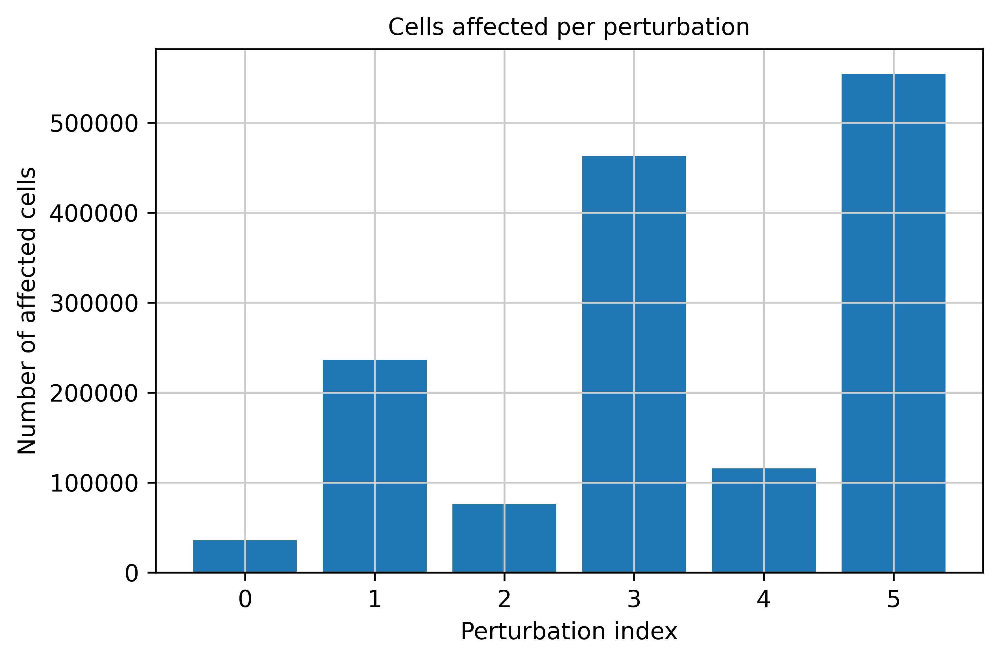

In [26]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

#### 2.4.6.1 Global Embeddings

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

#### 2.4.6.2 GP Embeddings

In [ ]:
gp_name = 'angiogenesis'
angiogenesis_gp_genes = ['ACE', 'ACVRL1', 'ADGRL4', 'ANGPT2', 'AVPR1A', 'BCL6B', 'CAVIN2', 'CD34', 'CD36', 'CD79B', 'CD93', 'CDH5', 'CLDN5', 'CLEC14A', 'DLL4', 'DNASE1L3', 'EGFL7', 'ENG', 'ENTPD1', 'ERG', 'ESM1', 'ETS1', 'FCN2', 'FLI1', 'FLT4', 'GIMAP4', 'GIMAP5', 'GIMAP8', 'HSPG2', 'ICAM2', 'IL18R1', 'IL33', 'IL3RA', 'KDR', 'MEF2C', 'MMRN2', 'NOS3', 'NOTCH4', 'PDGFB', 'PECAM1', 'PLVAP', 'PRKCH', 'RGS5', 'ROBO4', 'SELE', 'SELP', 'SH2D3C', 'SHANK3', 'SOX17', 'SOX18', 'TEK', 'THBD', 'TIE1', 'TNFRSF1B']

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=adata.var[~adata.var_names.isin(angiogenesis_gp_genes)]['ensembl_id'].tolist(),
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
    (pos_embed): Embedding(2817, 384, padd

Special token pad ratio 0.0


/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
INFO:root:Dataloader and -sampler created.
INFO:root:Loaded pretrained target encoder from epoch 3 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/torch/utils/_contextlib.py:87: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  """
72it [02:09,  1.76s/it]

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}_{gp_name}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}_{gp_name}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.7 Perturbation Case 7 (VEGFR3 Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - FLT4 (ENSG00000037280)
    - VEGFC (ENSG00000150630)
    - VEGFD (ENSG00000165197)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 7
pert_genes = [
    'FLT4',
    'VEGFC',
    'VEGFD',
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.8 Perturbation Case 8 (PDGFRA Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - PDGFRA (ENSG00000134853)
    - PDGFA (ENSG00000197461)
    - PDGFC (ENSG00000145431)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 8
pert_genes = [
    'PDGFRA',
    'PDGFA',
    'PDGFC',
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.9 Perturbation Case 9 (PDGFRB Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - PDGFRB (ENSG00000113721)
    - PDGFB (ENSG00000100311)
    - PDGFD (ENSG00000170962)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 9
pert_genes = [
    'PDGFRB',
    'PDGFB',
    'PDGFD'
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.10 Perturbation Case 10 (KIT Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - KIT (ENSG00000157404)
    - KITLG (ENSG00000049130)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 10
pert_genes = [
    'KIT',
    'KITLG'
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.11 Perturbation Case 11 (FLT3 Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - FLT3 (ENSG00000122025)
    - FLT3LG (ENSG00000090554)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 11
pert_genes = [
    'FLT3',
    'FLT3LG'
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.12 Perturbation Case 12 (RET Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - RET (ENSG00000165731)
    - GDNF (ENSG00000168621)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 12
pert_genes = [
    'RET',
    'GDNF'
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.13 Perturbation Case 13 (CSF1R Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - CSF1R (ENSG00000182578)
    - CSF1 (ENSG00000184371)
    - IL34 (ENSG00000157368)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 13
pert_genes = [
    'CSF1R',
    'CSF1',
    'IL34'
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.14 Perturbation Case 14 (All Signaling Axes)

Knockout Perturbation:
- Cell & Neighborhood
    'KDR',
    'VEGFA',
    'VEGFB',
    'FLT4',
    'VEGFC',
    'VEGFD',
    'PDGFRA',
    'PDGFA',
    'PDGFC',
    'PDGFRB',
    'PDGFB',
    'PDGFD',
    'KIT',
    'KITLG',
    'FLT3',
    'FLT3LG',
    'RET',
    'GDNF',
    'CSF1R',
    'CSF1',
    'IL34',
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 14
pert_genes = [
    'KDR',
    'VEGFA',
    'VEGFB',
    'FLT4',
    'VEGFC',
    'VEGFD',
    'PDGFRA',
    'PDGFA',
    'PDGFC',
    'PDGFRB',
    'PDGFB',
    'PDGFD',
    'KIT',
    'KITLG',
    'FLT3',
    'FLT3LG',
    'RET',
    'GDNF',
    'CSF1R',
    'CSF1',
    'IL34',
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [123]:
pretreatment_dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
    num_rows: 1081189
})

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True,
    pad_gene_tokens=True,
    adjust_positions=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.4.14.1 Global Embeddings

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}_tmp'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}_tmp"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

#### 2.4.14.2 GP Embeddings

In [ ]:
gp_name = 'angiogenesis'

In [ ]:
if gp_name == 'angiogenesis':
    gp_genes = angiogenesis_gp_genes
elif gp_name == 'glom_vasc_interface':
    gp_genes = glom_vasc_interface_gp_genes

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=adata.var[~adata.var_names.isin(gp_genes)]['ensembl_id'].tolist(),
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
    (pos_embed): Embedding(2817, 384, padd

Special token pad ratio 0.0


/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
INFO:root:Dataloader and -sampler created.
INFO:root:Loaded pretrained target encoder from epoch 3 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/torch/utils/_contextlib.py:87: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  """
72it [02:09,  1.76s/it]

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}_{gp_name}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}_{gp_name}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

### 2.4.15 Perturbation Case 15 (50% Random Genes)

In [21]:
random.seed(42)
all_genes = pretreatment_adata.var_names.tolist()
sampled_genes = random.sample(all_genes, k=len(all_genes)//2)

In [22]:
pert_case = 15
pert_genes = sampled_genes

In [36]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

           ensembl_id
ERN1  ENSG00000178607
            ensembl_id
RNF26  ENSG00000173456
           ensembl_id
GAD1  ENSG00000128683
           ensembl_id
RELN  ENSG00000189056
           ensembl_id
PLAU  ENSG00000122861
            ensembl_id
CLIC6  ENSG00000159212
            ensembl_id
IL17F  ENSG00000112116
            ensembl_id
TEKT1  ENSG00000167858
            ensembl_id
CD320  ENSG00000167775
             ensembl_id
TUBB2B  ENSG00000137285
          ensembl_id
CTH  ENSG00000116761
           ensembl_id
CD93  ENSG00000125810
             ensembl_id
COL5A1  ENSG00000130635
            ensembl_id
SLIT3  ENSG00000184347
          ensembl_id
NIN  ENSG00000100503
            ensembl_id
KDM1A  ENSG00000004487
              ensembl_id
HNRNPH1  ENSG00000169045
            ensembl_id
BIRC7  ENSG00000101197
            ensembl_id
PTOV1  ENSG00000104960
            ensembl_id
XRCC3  ENSG00000126215
             ensembl_id
LILRA1  ENSG00000104974
              ensembl_id
TNFSF18  ENSG0000

In [37]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,all,ENSG00000178607,cell,knockout,NaN
1,all,ENSG00000178607,neighborhood,knockout,NaN
2,all,ENSG00000173456,cell,knockout,NaN
3,all,ENSG00000173456,neighborhood,knockout,NaN
4,all,ENSG00000128683,cell,knockout,NaN
...,...,...,...,...,...
4943,all,ENSG00000125813,neighborhood,knockout,NaN
4944,all,ENSG00000198522,cell,knockout,NaN
4945,all,ENSG00000198522,neighborhood,knockout,NaN
4946,all,ENSG00000183346,cell,knockout,NaN


In [39]:
pretreatment_dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
    num_rows: 1081189
})

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [23]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
cols_to_remove = [c for c in perturbed_dataset.column_names if c.startswith("pert_flag_idx")]
perturbed_dataset = perturbed_dataset.remove_columns(cols_to_remove)
perturbed_dataset

In [28]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
    (pos_embed): Embedding(2817, 384, padd

Special token pad ratio 0.0


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:626: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
INFO:root:Dataloader and -sampler created.
INFO:root:Loaded pretrained target encoder from epoch 3 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1132: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
8447it [4:07:55,  1.76s/it]


In [29]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [48]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.16 Perturbation Case 16 (10% Random Genes)

In [ ]:
random.seed(42)
all_genes = pretreatment_adata.var_names.tolist()
sampled_genes = random.sample(all_genes, k=len(all_genes)//10)

In [ ]:
pert_case = 16
pert_genes = sampled_genes

In [ ]:
len(pert_genes)

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
pretreatment_dataset

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

## 2.5 Analyze Perturbations

In [ ]:
# Load AnnData with embeddings from model (including perturbation embeddings)
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [ ]:
# Compute highly variable genes
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=500,
    flavor="seurat_v3",
    layer="counts" # important: HVGs from raw counts
)

# Subset to HVGs (optional)
# adata_hvg = adata[:, adata.var["highly_variable"]].copy()

In [ ]:
adata.obsm

### 2.5.1 Perturbation Case 1 (Original 1)

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI12-KID-0-FT-4

In [104]:
pert_case = 1
pert_genes = [
    'CTLA4',
    'PDCD1']

In [105]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

            ensembl_id
CTLA4  ENSG00000163599
            ensembl_id
PDCD1  ENSG00000188389


In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.1.1 Individual Perturbations

In [ ]:
for pert_idx in range(len(pert_genes)*2):

    ind_pert_filtered_dataset = perturbed_dataset.filter(
        lambda x: x[f"pert_flag_idx_{pert_idx}"])

    ind_pert_cell_ids = list(ind_pert_filtered_dataset['cell_id'])
    print(len(ind_pert_cell_ids))
    
    adata_sub_ind_pert = adata[adata.obs_names.isin(ind_pert_cell_ids)]

    results, summary = analyze_embedding_cos_sims(
    adata_sub_ind_pert,
    pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
           ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
           ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")]
    )
    
    df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
        adata_sub_ind_pert,
        pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
               ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
               ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")],
        label_key=cell_type_key,
        agg="mean",
        sort_by="cell_emb",
        ascending=True,
    )
    df_cos_sim_sorted_cell_type

    df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
        adata_sub_ind_pert,
        pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
               ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
               ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")],
        label_key=niche_key,
        agg="mean",
        sort_by="cell_emb",
        ascending=True,
    )
    df_cos_sim_sorted_niche

    print(f"==== Perturbation index: {pert_idx} ====")
    print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
    print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
    print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
    print("========================================")
    print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
    print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
    print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
    print("========================================")
    print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
    print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
    print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")
    print("========================================")

#### 2.5.1.2 Cell Perturbations

In [106]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

Filter: 100%|██████████| 33093/33093 [00:05<00:00, 5783.47 examples/s]


In [107]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

3464


In [108]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.997727  min=0.955812


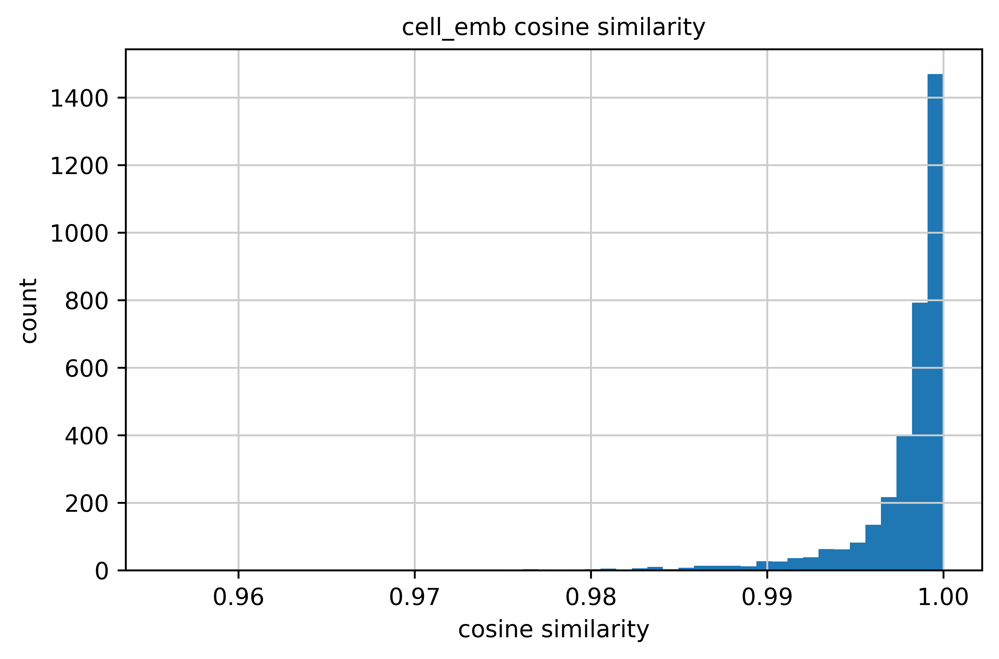

spatial_cell_emb: mean=0.999842  min=0.993771


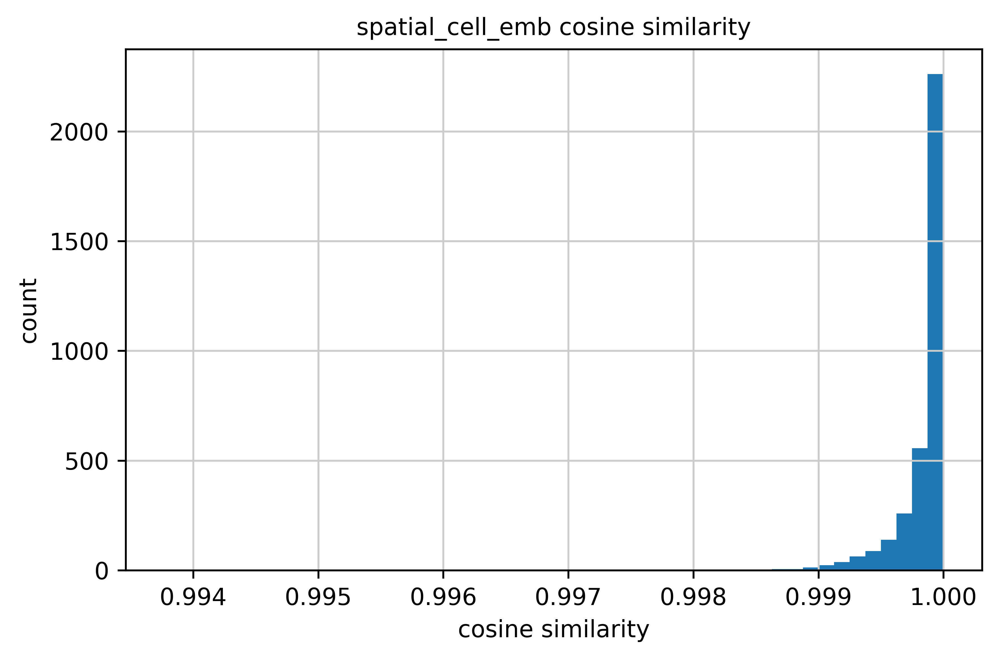

neighborhood_emb: mean=0.999964  min=0.992715


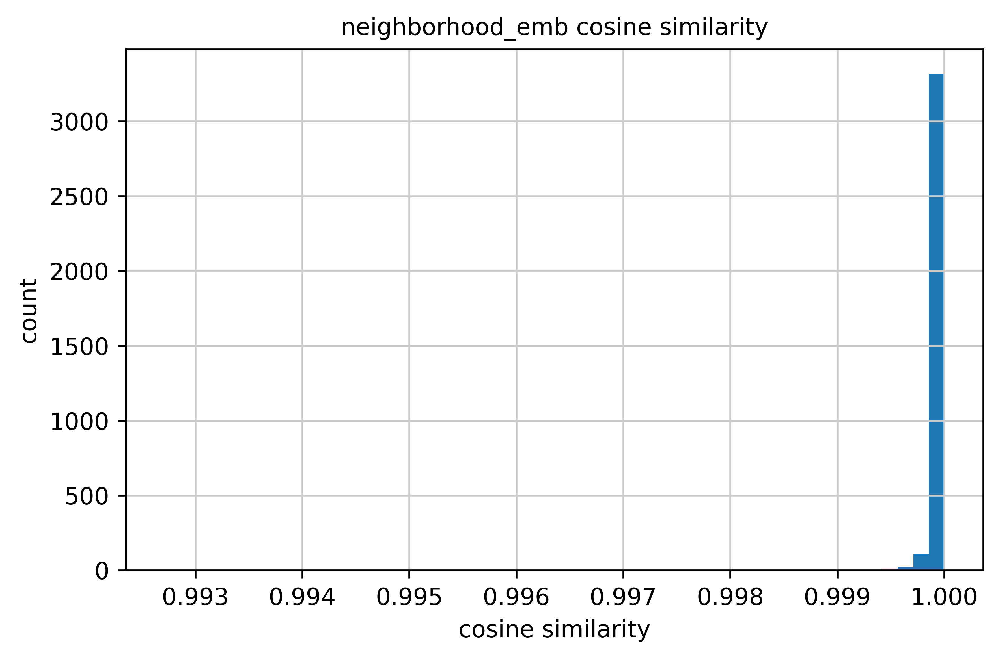

In [109]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}_tmp", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}_tmp", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}_tmp", "neighborhood_emb")]
)

In [110]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}_tmp", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}_tmp", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}_tmp", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Natural killer cell,1,0.984622,0.999650,0.999974
1,Ascending thin limb,2,0.991988,0.999771,0.999992
2,CD14+ monocyte,2,0.992446,0.999539,0.999936
3,Descending thin limb,17,0.993735,0.999550,0.999964
4,Memory B cell,32,0.993884,0.999547,0.999948
5,Connecting tubule,56,0.995635,0.999599,0.999970
6,Neuron,16,0.995817,0.999773,0.999977
7,Principal cell,36,0.996519,0.999784,0.999972
8,Vascular mural cell,107,0.996734,0.999776,0.999975
9,Glomerular endothelial cell,51,0.996821,0.999798,0.999971


In [111]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}_tmp", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}_tmp", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}_tmp", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Fibrovascular neighborhood,749,0.996685,0.999754,0.999941
1,Loop of Henle neighborhood,255,0.996852,0.999834,0.999985
2,Proximal nephron neighborhood,771,0.997838,0.999857,0.999985
3,Injured proximal nephron neighborhood,903,0.998003,0.999815,0.999937
4,Glomerular neighborhood,195,0.998414,0.999935,0.999992
5,Distal nephron neighborhood,591,0.998631,0.999946,0.999991


In [112]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99772704
Spatial cell embedding average: 0.9998416
Neighborhood embedding average: 0.9999644
Lowest cell embedding average per cell type: 0.9846219420433044
Lowest spatial cell embedding average per cell type: 0.9995391368865967
Lowest neighborhood embedding average per cell type: 0.999916672706604
Lowest cell embedding average per niche: 0.996685266494751
Lowest spatial cell embedding average per niche: 0.9997535943984985
Lowest neighborhood embedding average per niche: 0.9999367594718933


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


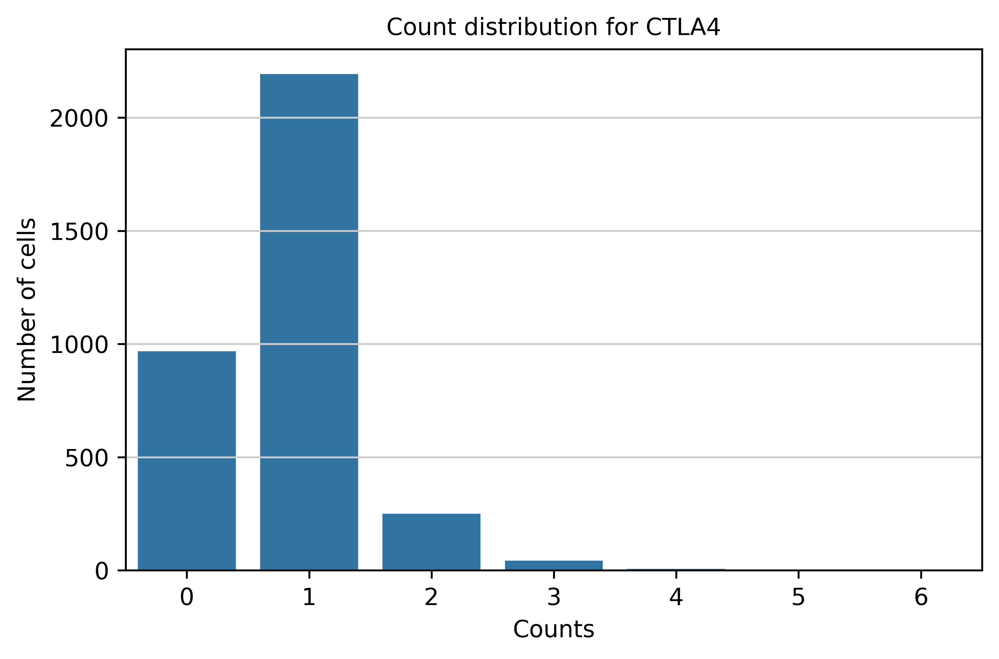

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


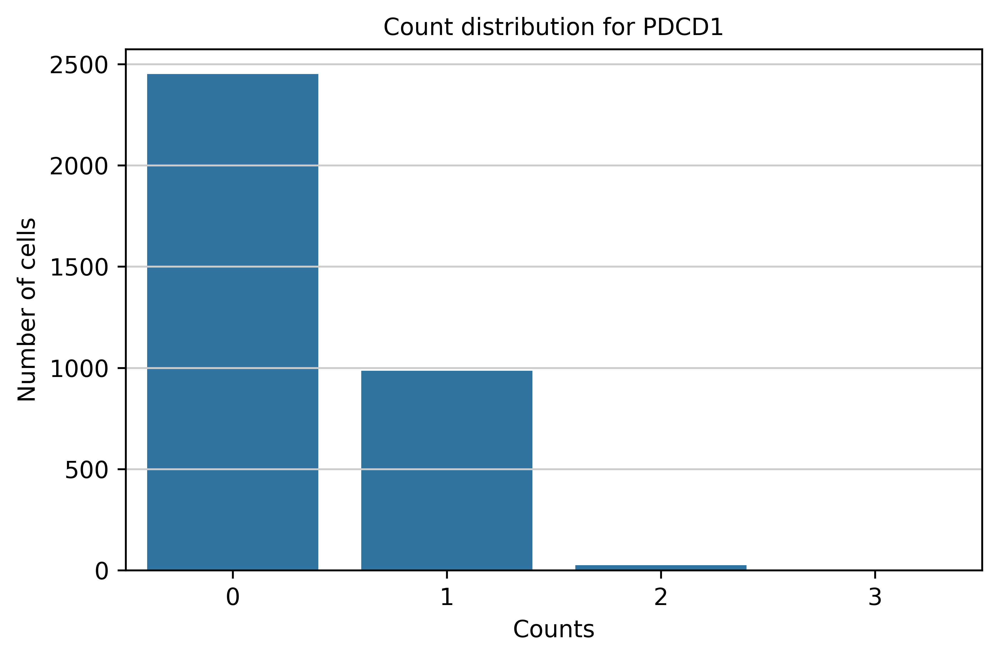

In [162]:
# Retrieve cell counts
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


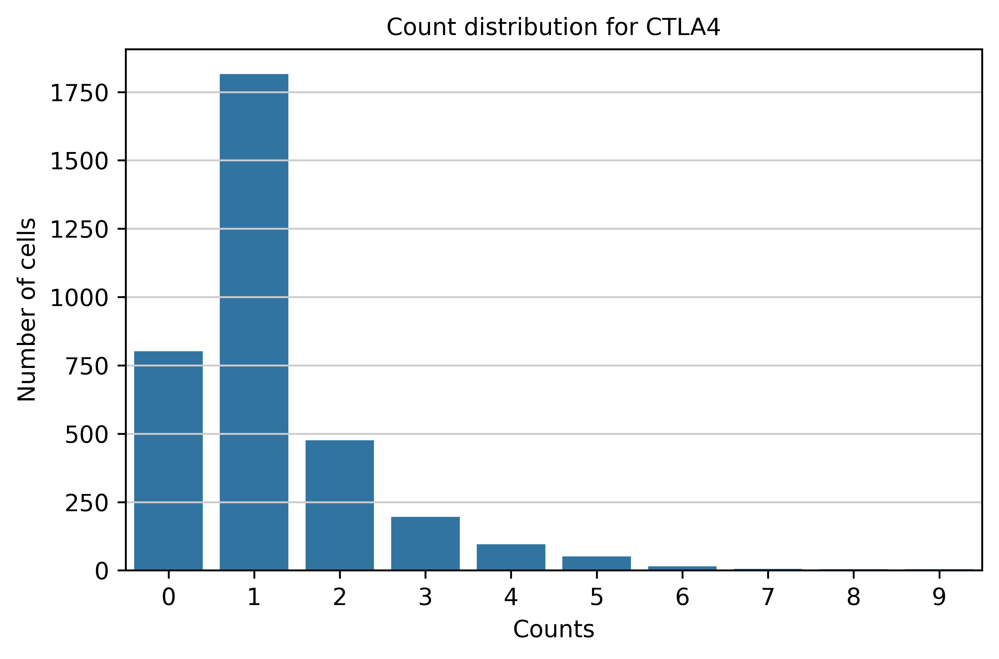

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


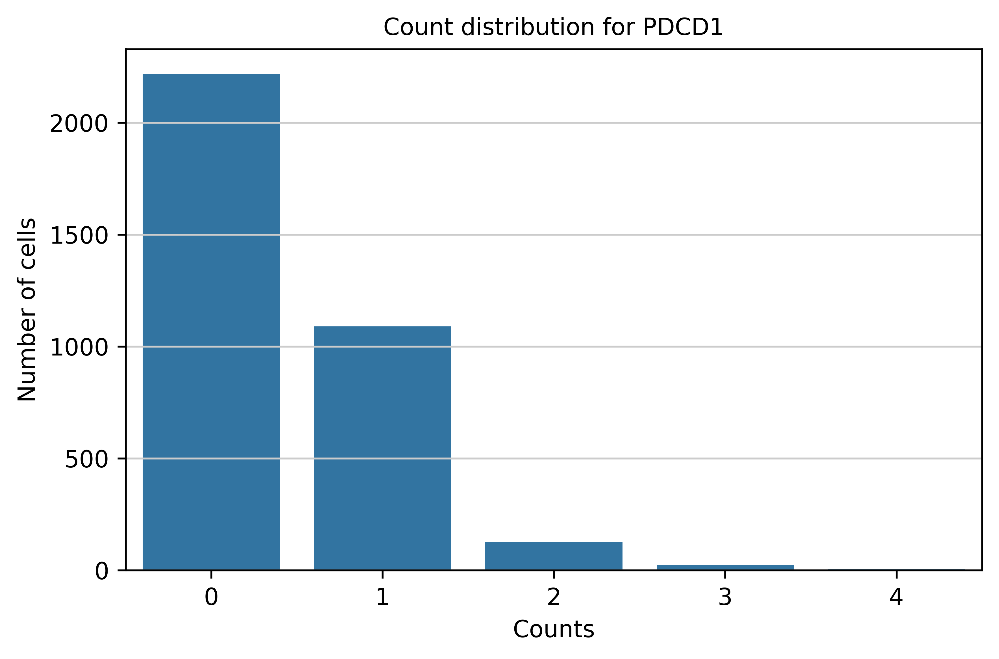

In [163]:
# Retrieve cell neighborhood counts
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].layers['counts_neighborhood']
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

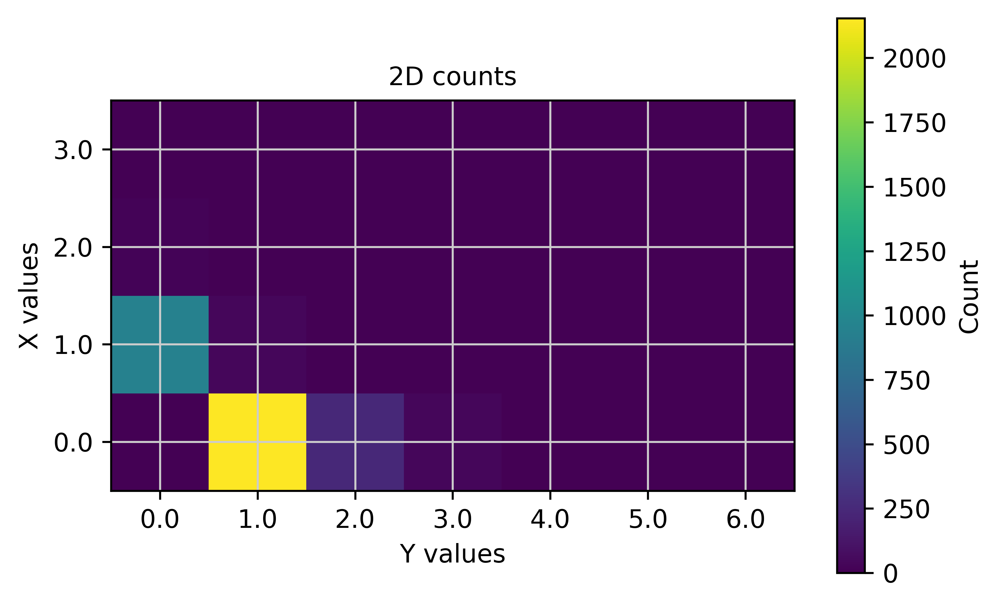

In [165]:
x = adata_sub_cell_pert[:, adata_sub_cell_pert.var_names.isin(['PDCD1'])].layers['counts'].toarray().flatten()
y = adata_sub_cell_pert[:, adata_sub_cell_pert.var_names.isin(['CTLA4'])].layers['counts'].toarray().flatten()

x_vals, y_vals = np.unique(x), np.unique(y)
count_matrix = np.zeros((len(x_vals), len(y_vals)), dtype=int)

for xi, yi in zip(x, y):
    count_matrix[np.where(x_vals == xi)[0][0],
                 np.where(y_vals == yi)[0][0]] += 1

plt.imshow(count_matrix, origin="lower")
plt.colorbar(label="Count")
plt.xticks(range(len(y_vals)), y_vals)
plt.yticks(range(len(x_vals)), x_vals)
plt.xlabel("Y values")
plt.ylabel("X values")
plt.title("2D counts")
plt.show()

#### 2.5.1.3 Neighborhood Perturbations

In [166]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [167]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

33093


In [168]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999784  min=0.955204


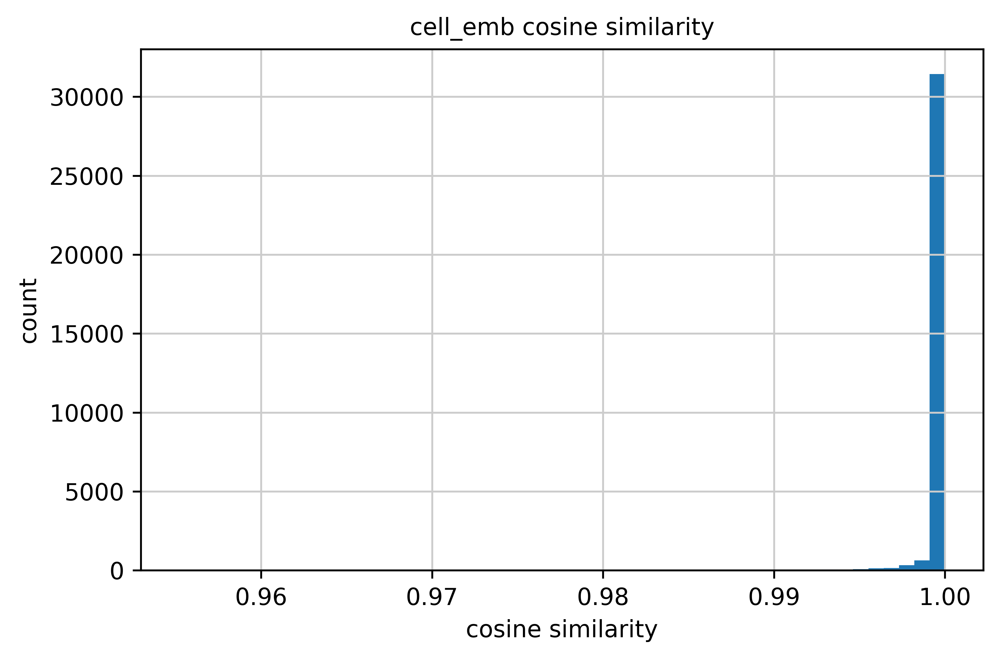

spatial_cell_emb: mean=0.999969  min=0.977921


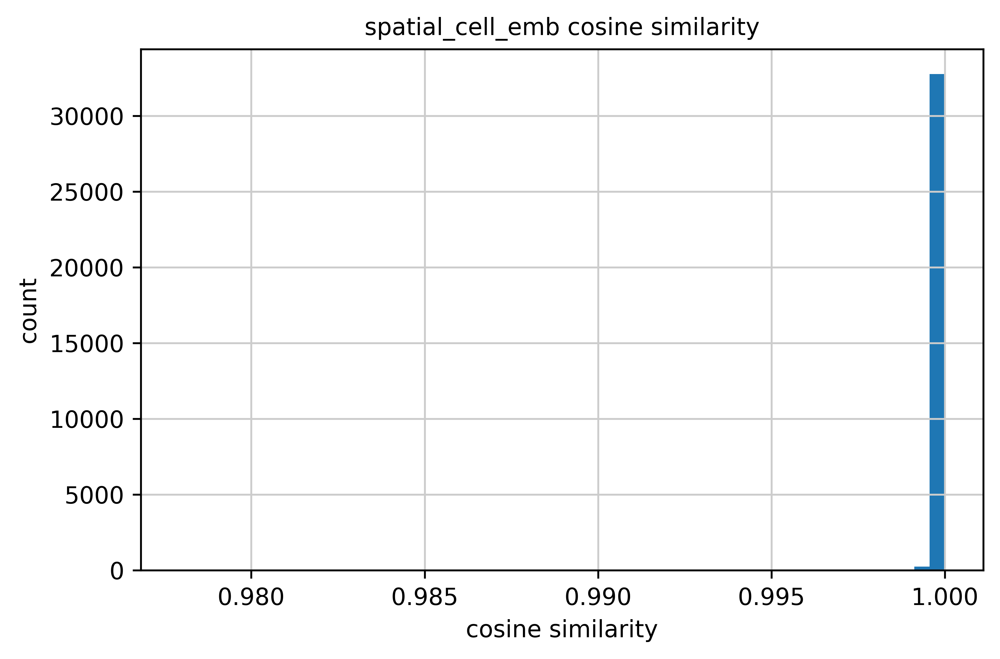

neighborhood_emb: mean=0.999980  min=0.980379


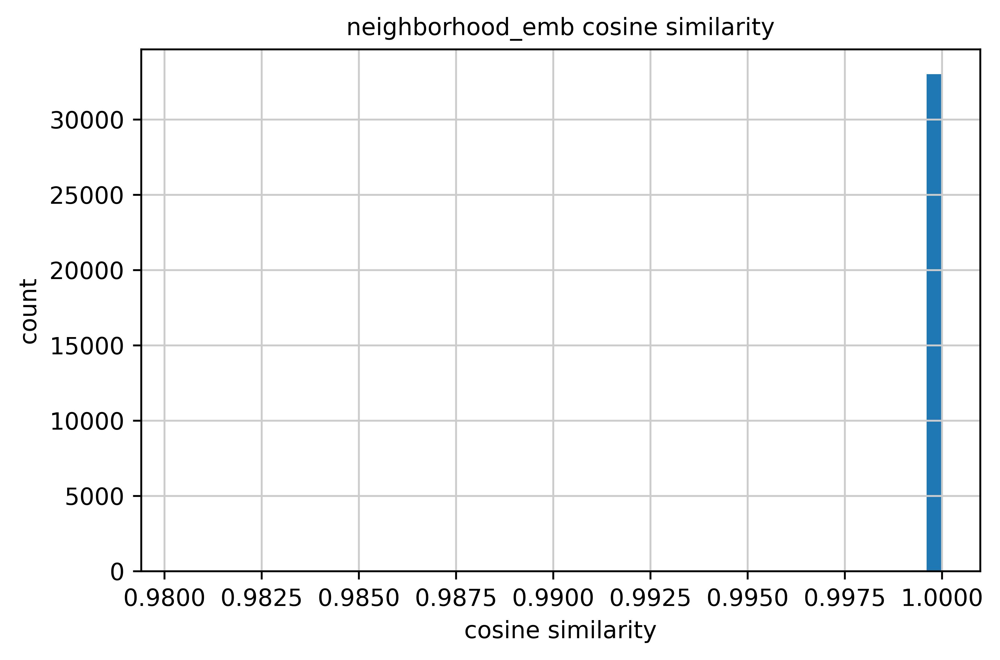

In [169]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [170]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Natural killer cell,10,0.998529,0.999948,0.999975
1,CD14+ monocyte,13,0.998851,0.999902,0.999956
2,Neuron,81,0.999183,0.999942,0.999979
3,Conventional dendritic cell,468,0.999246,0.999942,0.999962
4,CD4+ T cell,1526,0.999342,0.999932,0.999969
5,Memory B cell,304,0.999375,0.999929,0.999966
6,Ascending thin limb,35,0.999545,0.999983,0.999994
7,Macrophage,3553,0.999548,0.999962,0.999980
8,CD8+ T cell,1908,0.999625,0.999944,0.999967
9,Descending thin limb,304,0.999654,0.999960,0.999980


In [171]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Fibrovascular neighborhood,7519,0.999693,0.999952,0.999968
1,Loop of Henle neighborhood,2651,0.999711,0.999978,0.999992
2,Injured proximal nephron neighborhood,6411,0.999755,0.999961,0.999972
3,Proximal nephron neighborhood,8391,0.999816,0.999965,0.999977
4,Glomerular neighborhood,1906,0.999858,0.999990,0.999995
5,Distal nephron neighborhood,6215,0.999890,0.999991,0.999995


In [172]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.9997841
Spatial cell embedding average: 0.9999688
Neighborhood embedding average: 0.99997956
Lowest cell embedding average per cell type: 0.9985294342041016
Lowest spatial cell embedding average per cell type: 0.9999016523361206
Lowest neighborhood embedding average per cell type: 0.9999416470527649
Lowest cell embedding average per niche: 0.9996925592422485
Lowest spatial cell embedding average per niche: 0.9999520182609558
Lowest neighborhood embedding average per niche: 0.9999675154685974


### 2.5.2 Perturbation Case 2 (Original 2)

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [173]:
pert_case = 2
pert_genes = [
    'CTLA4',
    'PDCD1',
    'KDR',
    'FLT4',
    'PDGFRA',
    'PDGFRB',
    'KIT',
    'CSF3R',
    'FLT3']

In [174]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

            ensembl_id  highly_variable  highly_variable_rank     means  \
CTLA4  ENSG00000163599             True                 359.0  0.005836   

       variances  variances_norm  
CTLA4   0.007755         1.22414  
            ensembl_id  highly_variable  highly_variable_rank     means  \
PDCD1  ENSG00000188389            False                   NaN  0.002927   

       variances  variances_norm  
PDCD1   0.003121        0.986409  
          ensembl_id  highly_variable  highly_variable_rank     means  \
KDR  ENSG00000128052             True                 225.0  0.042929   

     variances  variances_norm  
KDR   0.070335        1.363115  
           ensembl_id  highly_variable  highly_variable_rank     means  \
FLT4  ENSG00000037280             True                 129.0  0.071771   

      variances  variances_norm  
FLT4   0.152284        1.610407  
             ensembl_id  highly_variable  highly_variable_rank     means  \
PDGFRA  ENSG00000134853             True            

In [175]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.2.1 Individual Perturbations

2493
cell_emb: mean=0.997574  min=0.955204


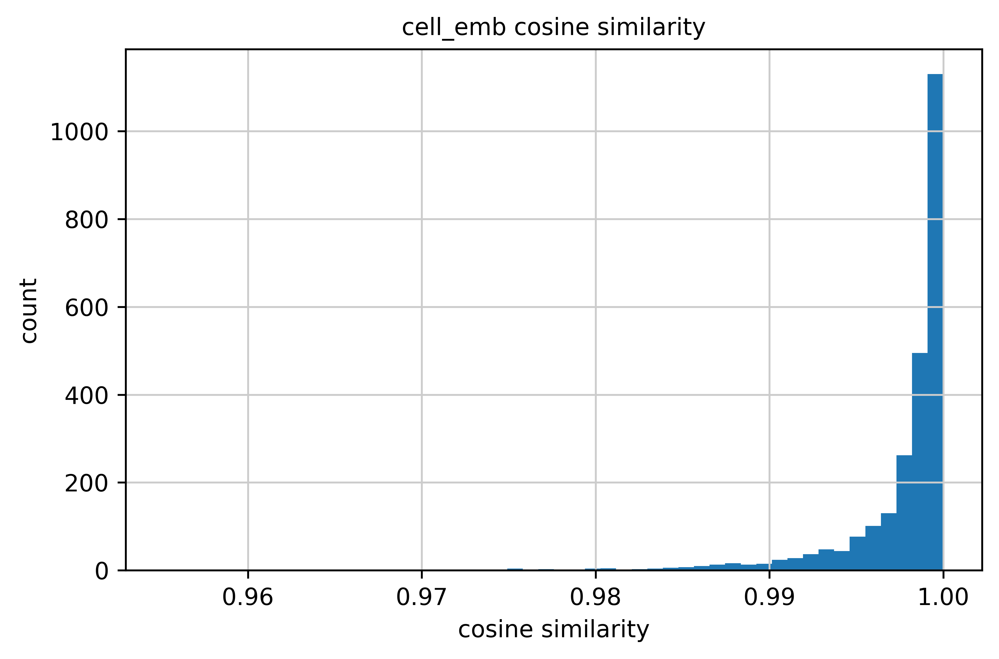

spatial_cell_emb: mean=0.999843  min=0.993725


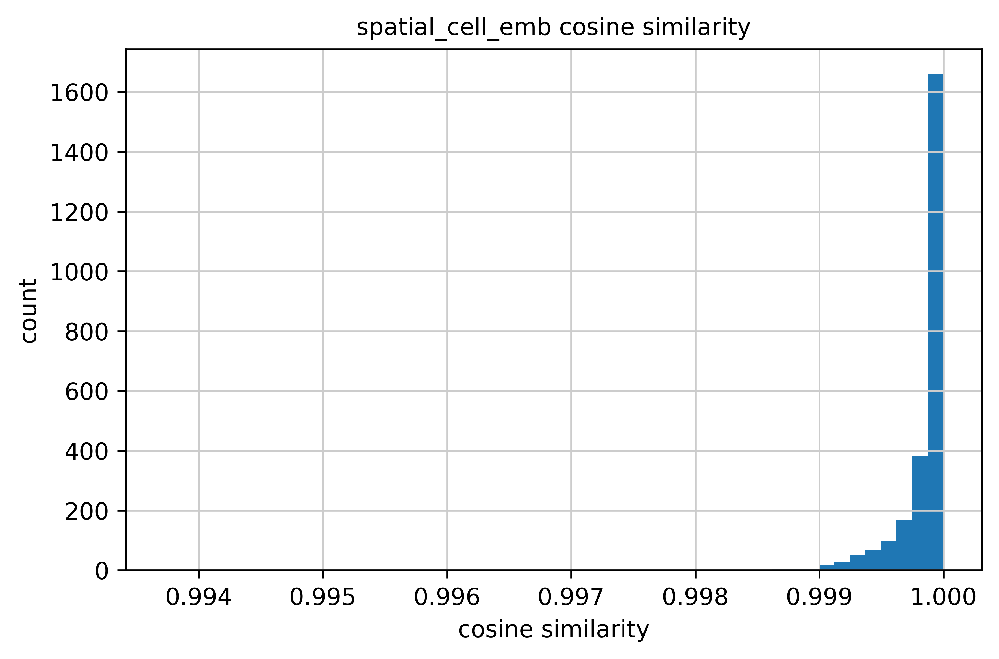

neighborhood_emb: mean=0.999968  min=0.992637


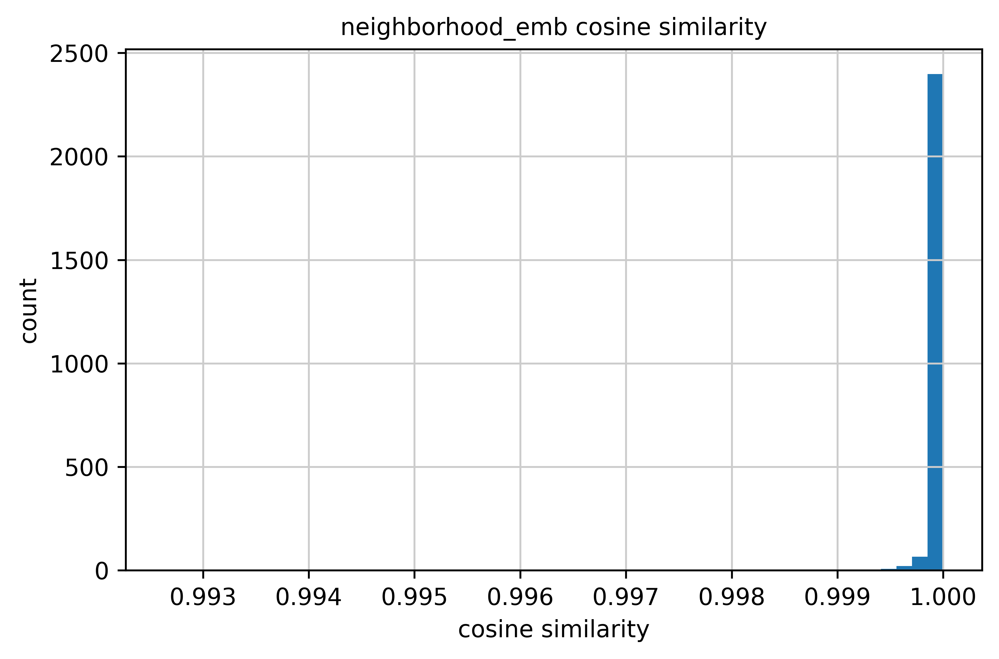

==== Perturbation index: 0 ====
Cell embedding average: 0.99757445
Spatial cell embedding average: 0.9998435
Neighborhood embedding average: 0.99996805
Lowest cell embedding average per cell type: 0.9852946996688843
Lowest spatial cell embedding average per cell type: 0.9993847608566284
Lowest neighborhood embedding average per cell type: 0.9999208450317383
Lowest cell embedding average per niche: 0.9959985017776489
Lowest spatial cell embedding average per niche: 0.9997599720954895
Lowest neighborhood embedding average per niche: 0.9999431371688843
22237
cell_emb: mean=0.999942  min=0.970907


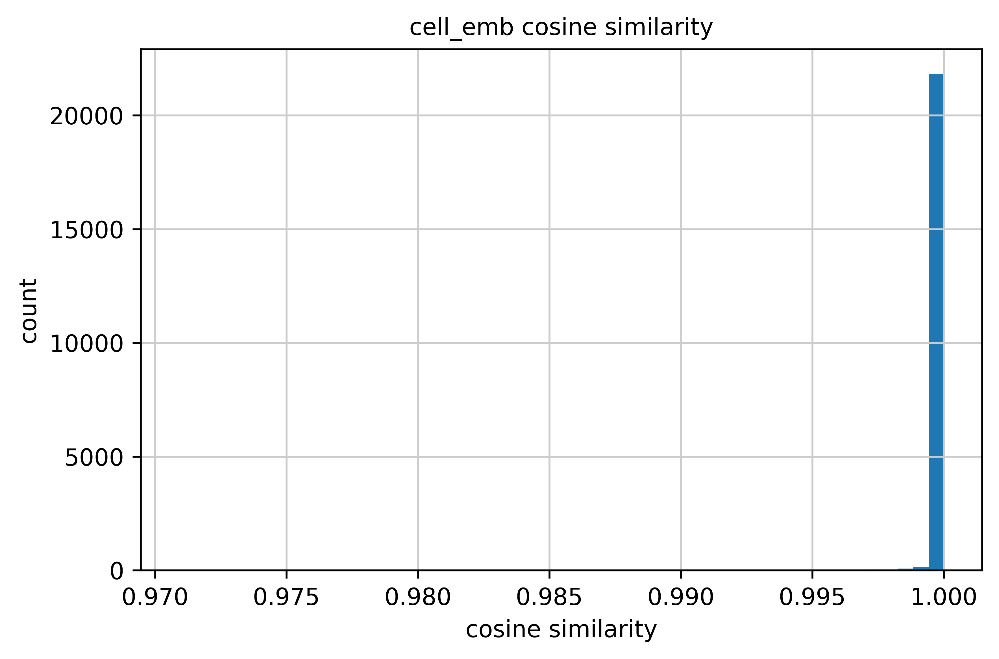

spatial_cell_emb: mean=0.999974  min=0.977921


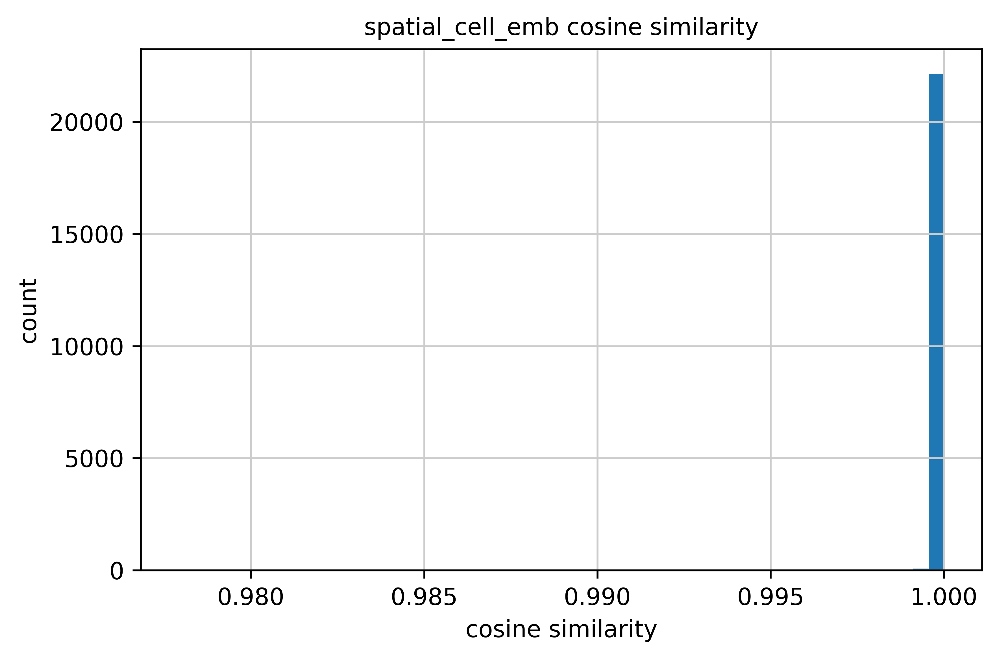

neighborhood_emb: mean=0.999975  min=0.980379


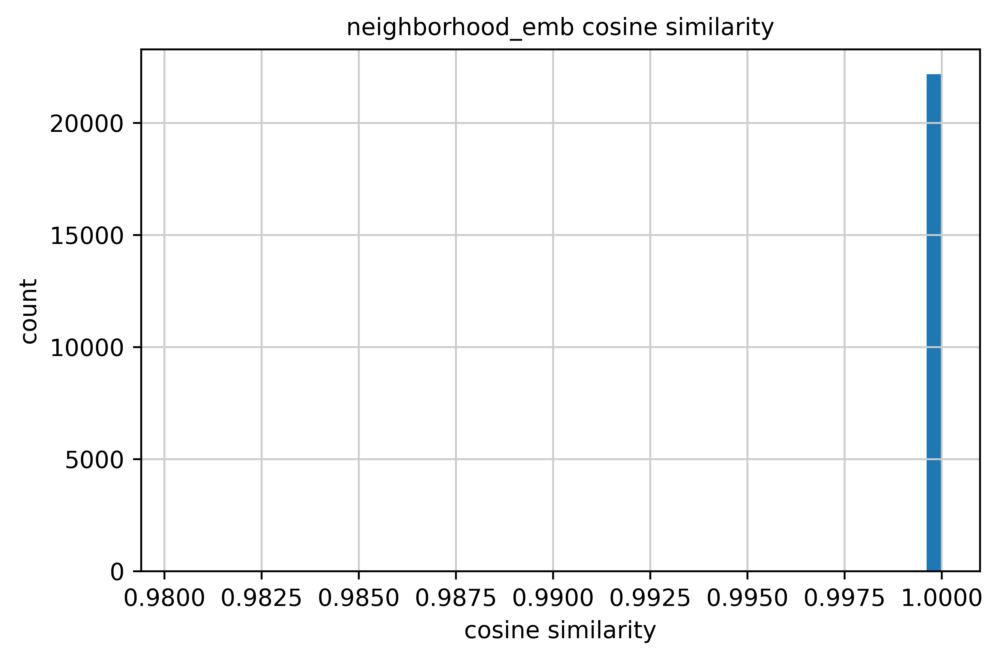

==== Perturbation index: 1 ====
Cell embedding average: 0.9999415
Spatial cell embedding average: 0.99997365
Neighborhood embedding average: 0.9999752
Lowest cell embedding average per cell type: 0.9996057748794556
Lowest spatial cell embedding average per cell type: 0.9999055862426758
Lowest neighborhood embedding average per cell type: 0.99991375207901
Lowest cell embedding average per niche: 0.9998378157615662
Lowest spatial cell embedding average per niche: 0.9999597072601318
Lowest neighborhood embedding average per niche: 0.9999639987945557
1009
cell_emb: mean=0.998822  min=0.971063


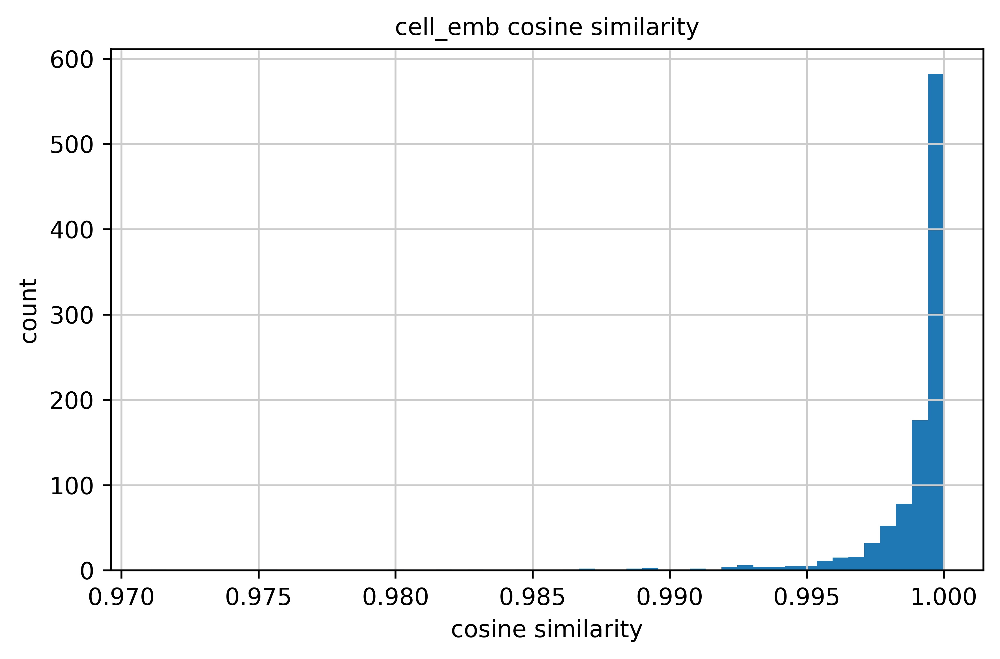

spatial_cell_emb: mean=0.999876  min=0.996837


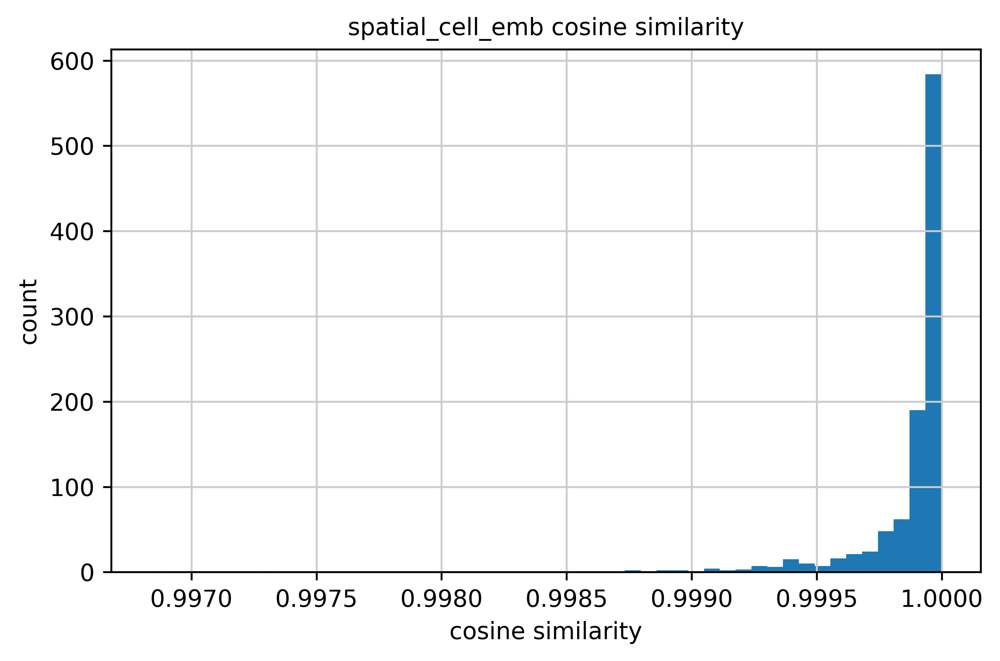

neighborhood_emb: mean=0.999979  min=0.996824


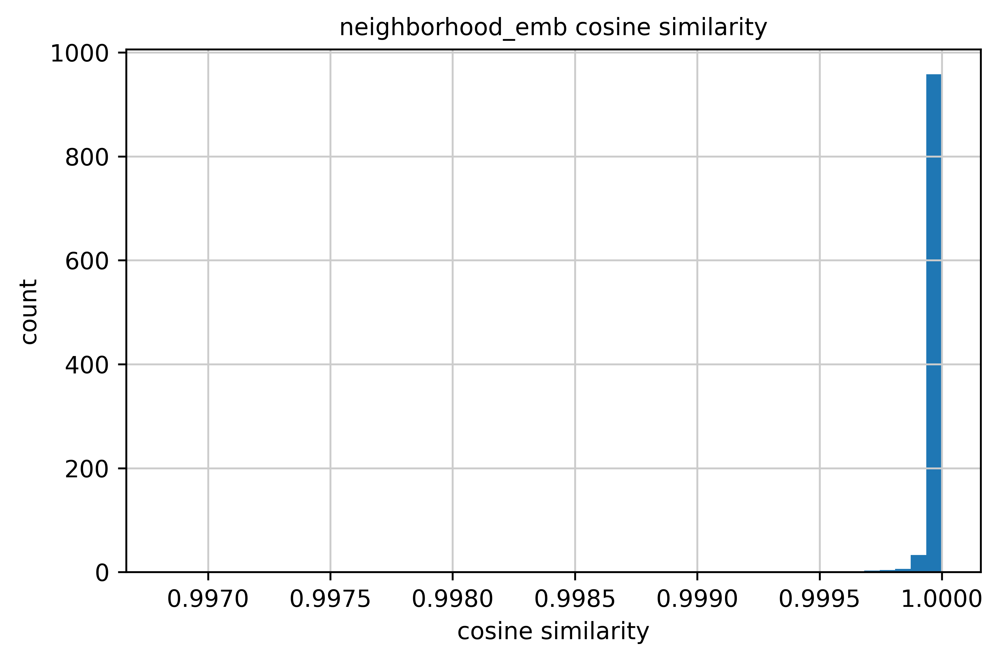

==== Perturbation index: 2 ====
Cell embedding average: 0.9988216
Spatial cell embedding average: 0.9998764
Neighborhood embedding average: 0.99997884
Lowest cell embedding average per cell type: 0.9943354725837708
Lowest spatial cell embedding average per cell type: 0.9993242025375366
Lowest neighborhood embedding average per cell type: 0.9998973608016968
Lowest cell embedding average per niche: 0.9982123970985413
Lowest spatial cell embedding average per niche: 0.9997572302818298
Lowest neighborhood embedding average per niche: 0.9999558925628662
9796
cell_emb: mean=0.999949  min=0.972285


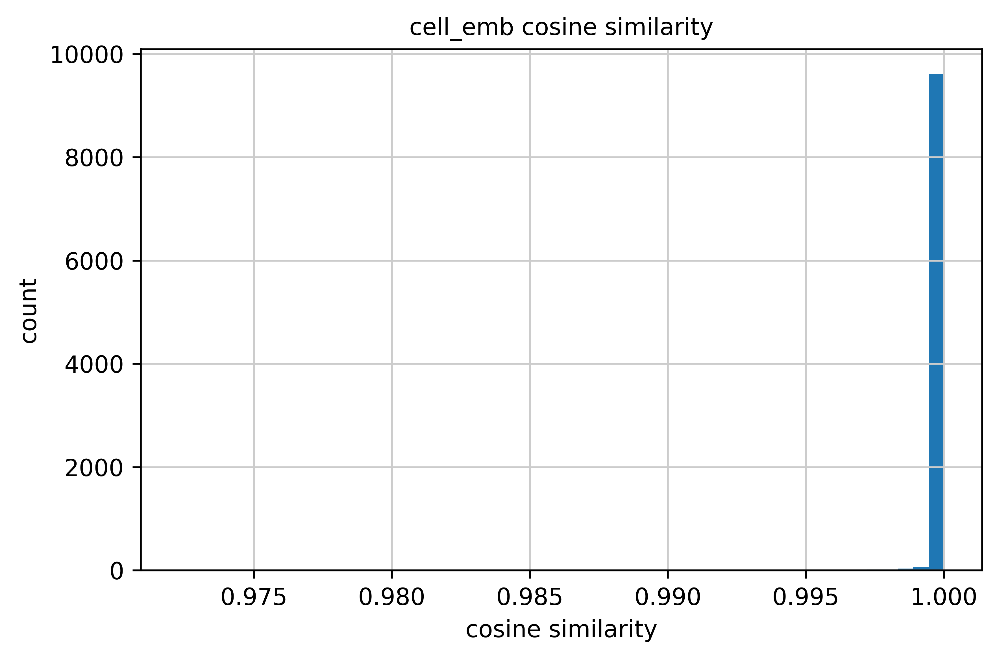

spatial_cell_emb: mean=0.999983  min=0.996952


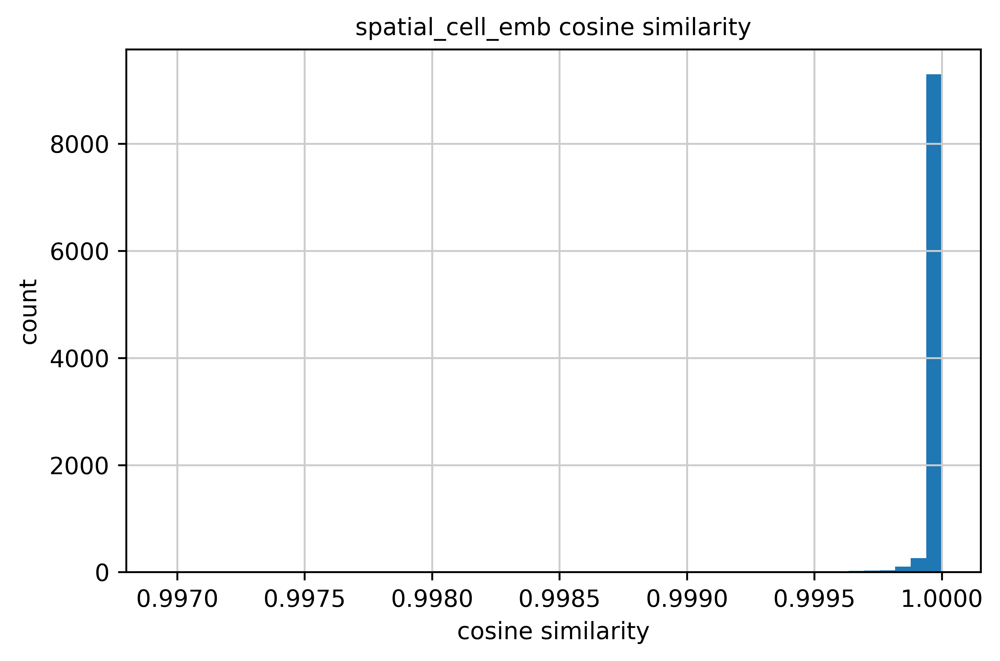

neighborhood_emb: mean=0.999983  min=0.996393


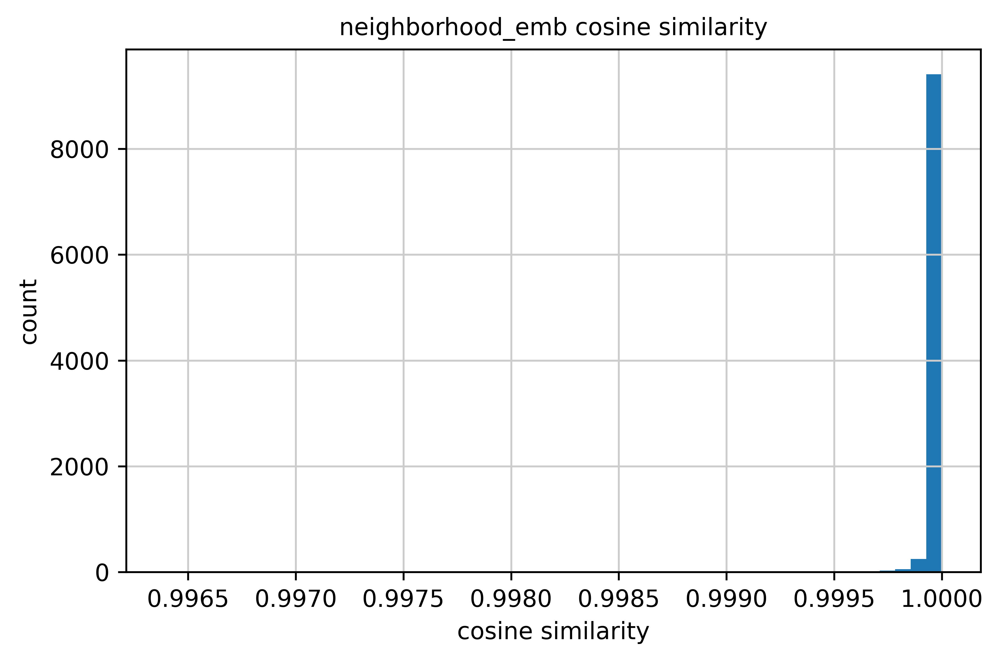

==== Perturbation index: 3 ====
Cell embedding average: 0.99994904
Spatial cell embedding average: 0.99998283
Neighborhood embedding average: 0.99998343
Lowest cell embedding average per cell type: 0.9997444748878479
Lowest spatial cell embedding average per cell type: 0.9999337196350098
Lowest neighborhood embedding average per cell type: 0.9999117851257324
Lowest cell embedding average per niche: 0.9998562932014465
Lowest spatial cell embedding average per niche: 0.9999668598175049
Lowest neighborhood embedding average per niche: 0.9999703764915466
35802
cell_emb: mean=0.999997  min=0.990414


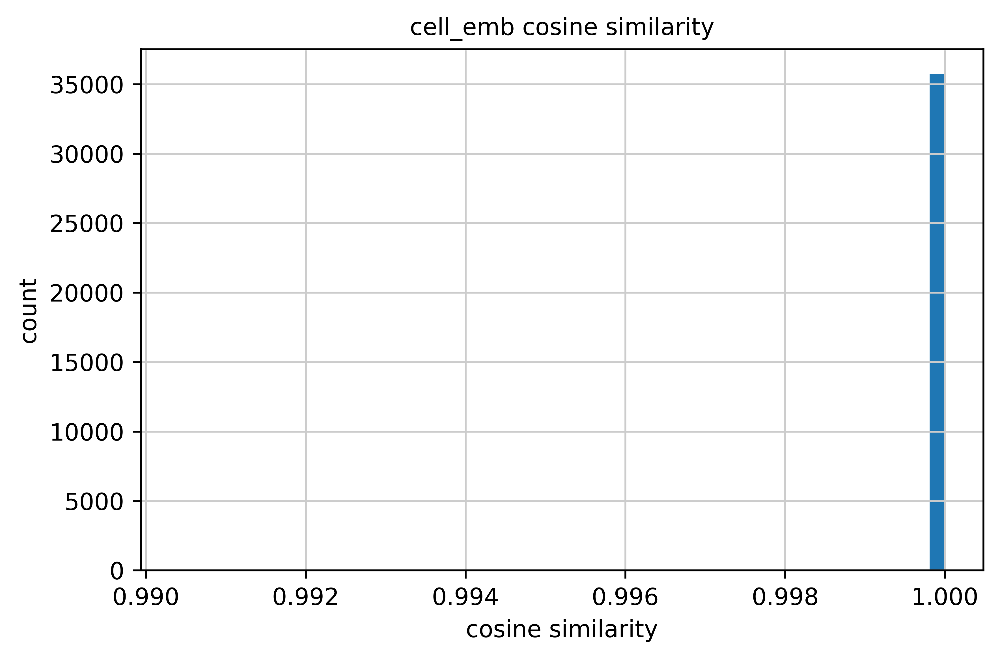

spatial_cell_emb: mean=1.000000  min=0.998865


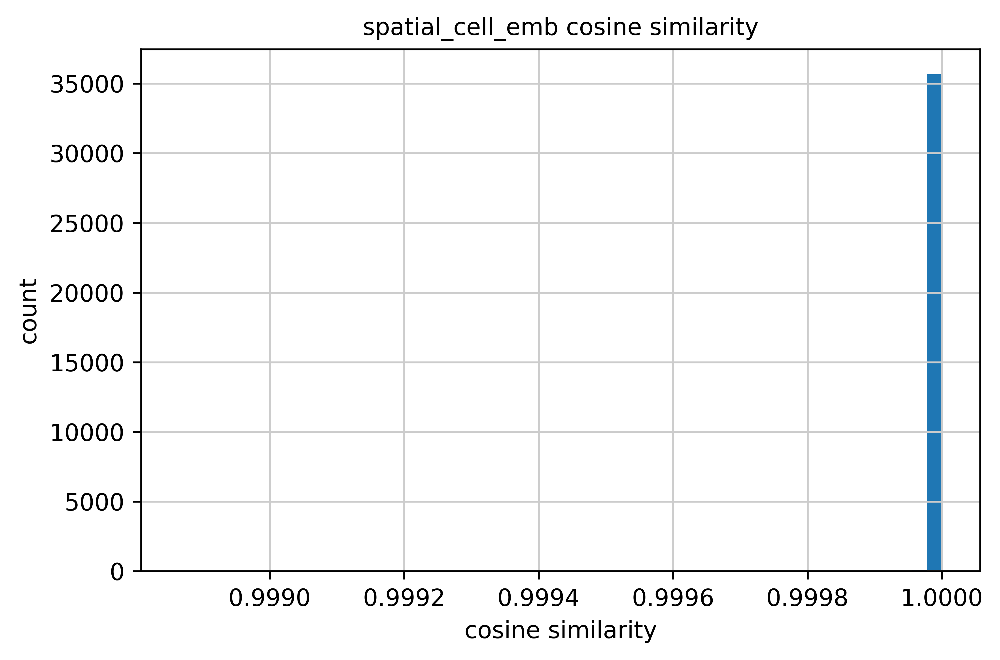

neighborhood_emb: mean=1.000000  min=0.998977


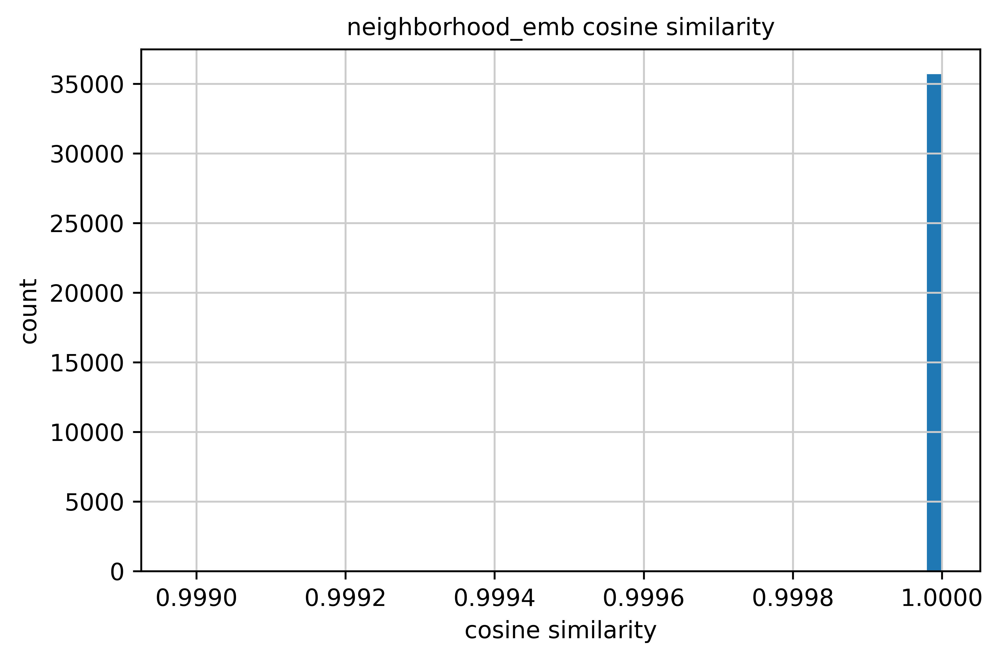

==== Perturbation index: 4 ====
Cell embedding average: 0.9999966
Spatial cell embedding average: 0.9999996
Neighborhood embedding average: 0.9999997
Lowest cell embedding average per cell type: 0.9998518228530884
Lowest spatial cell embedding average per cell type: 0.999964714050293
Lowest neighborhood embedding average per cell type: 0.9999862909317017
Lowest cell embedding average per niche: 0.9999653697013855
Lowest spatial cell embedding average per niche: 0.9999942779541016
Lowest neighborhood embedding average per niche: 0.9999953508377075
236227
cell_emb: mean=0.999995  min=0.966245


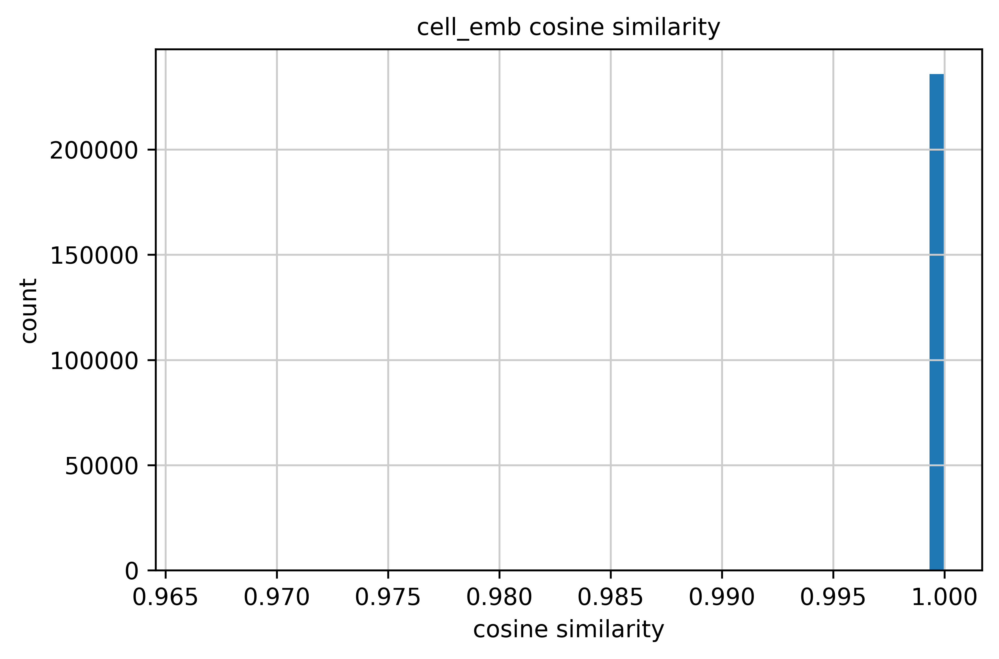

spatial_cell_emb: mean=1.000000  min=0.993416


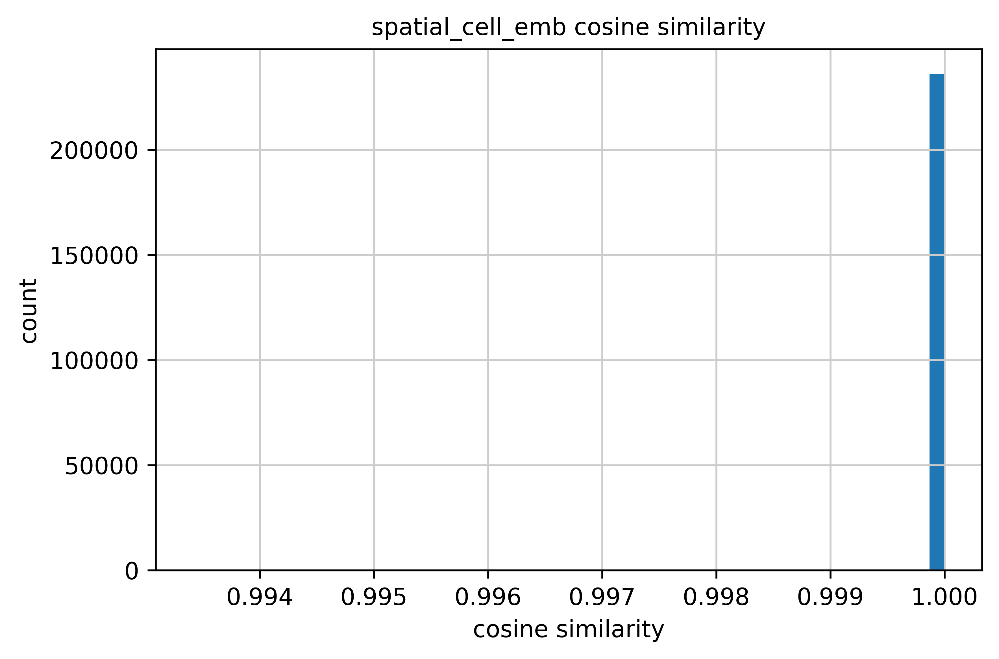

neighborhood_emb: mean=1.000000  min=0.995103


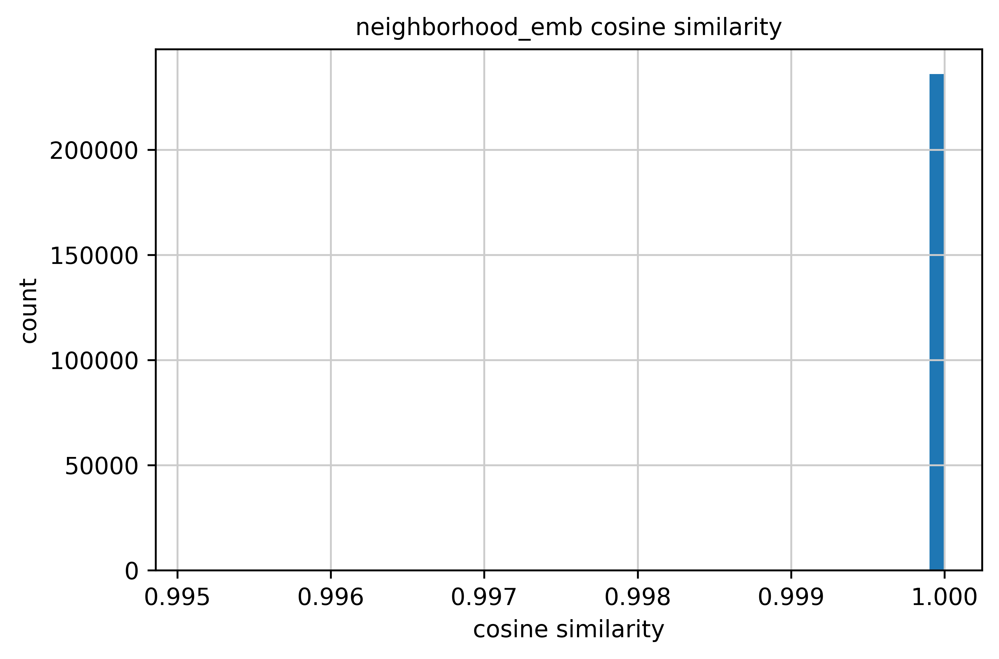

==== Perturbation index: 5 ====
Cell embedding average: 0.99999475
Spatial cell embedding average: 0.9999995
Neighborhood embedding average: 0.99999964
Lowest cell embedding average per cell type: 0.9999207854270935
Lowest spatial cell embedding average per cell type: 0.9999916553497314
Lowest neighborhood embedding average per cell type: 0.999995231628418
Lowest cell embedding average per niche: 0.9999479055404663
Lowest spatial cell embedding average per niche: 0.9999933838844299
Lowest neighborhood embedding average per niche: 0.9999953508377075
52825
cell_emb: mean=0.999997  min=0.988984


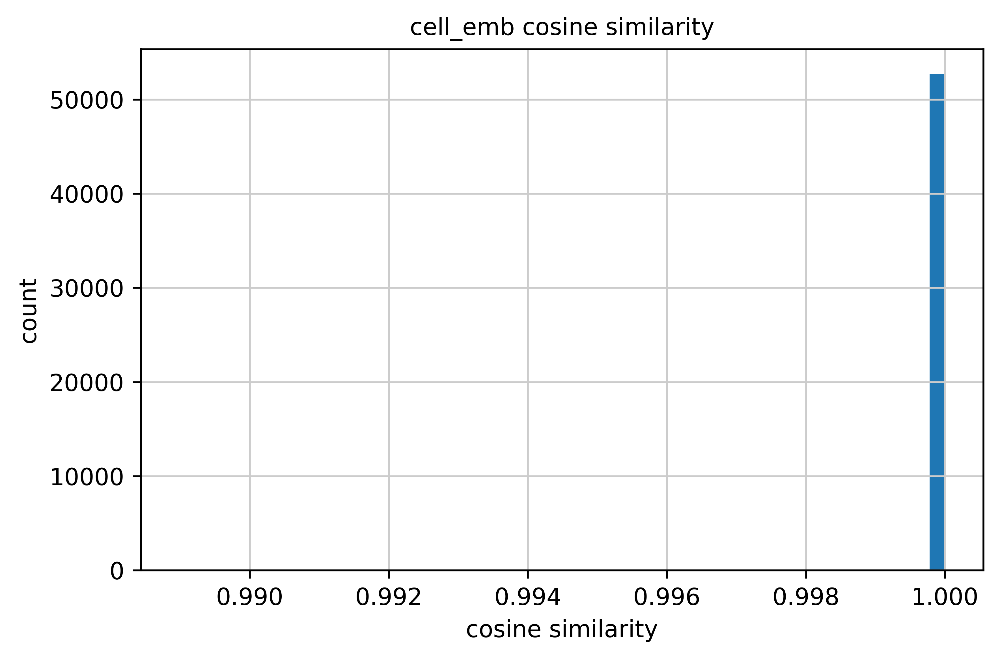

spatial_cell_emb: mean=1.000000  min=0.997615


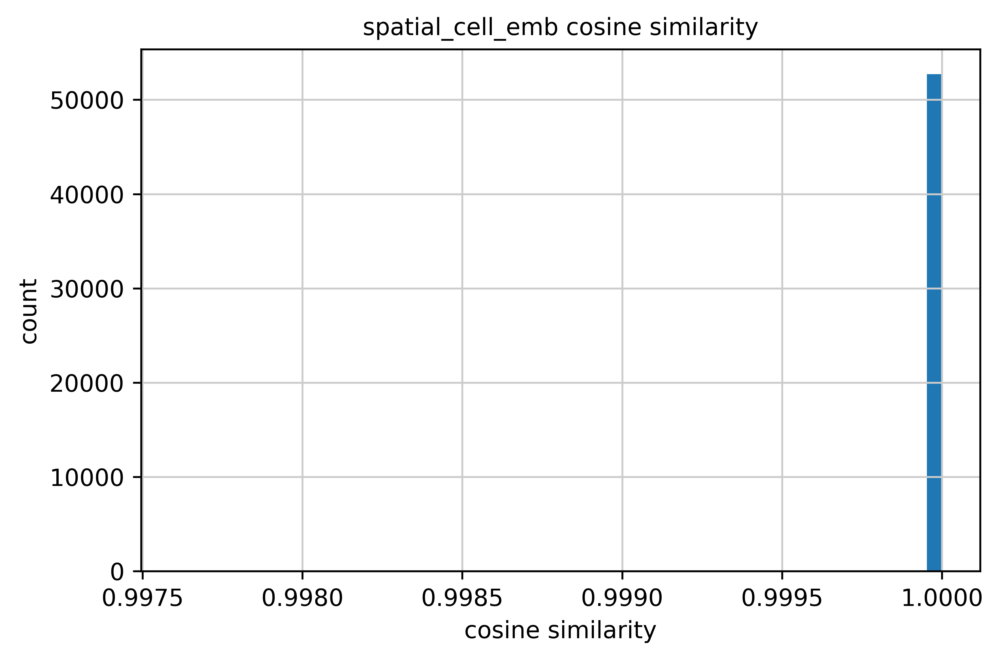

neighborhood_emb: mean=1.000000  min=0.997238


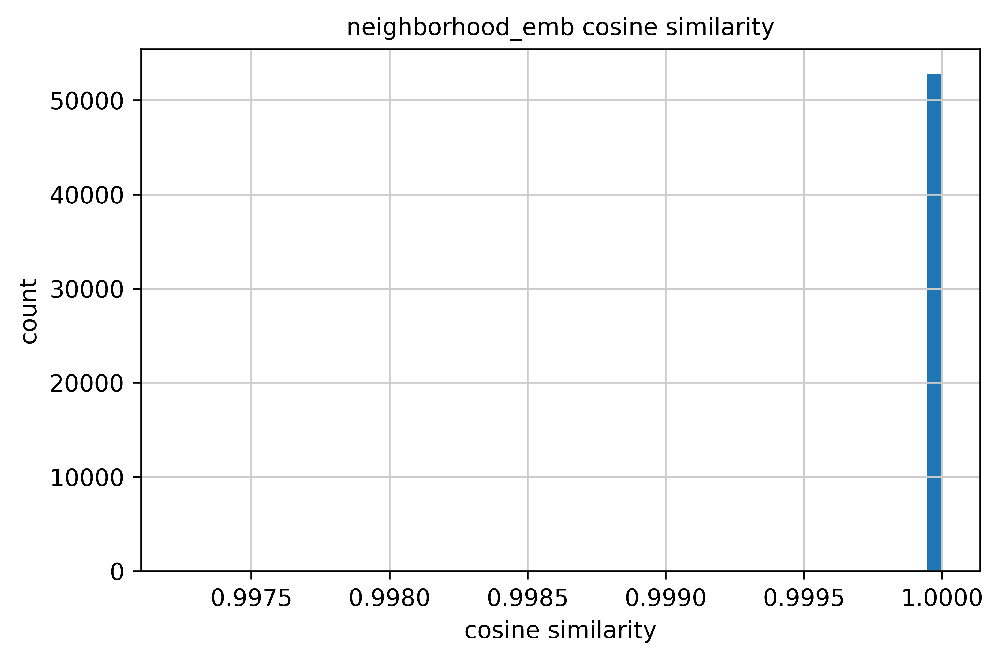

==== Perturbation index: 6 ====
Cell embedding average: 0.9999969
Spatial cell embedding average: 0.9999996
Neighborhood embedding average: 0.9999996
Lowest cell embedding average per cell type: 0.9998556971549988
Lowest spatial cell embedding average per cell type: 0.9999908208847046
Lowest neighborhood embedding average per cell type: 0.9999940395355225
Lowest cell embedding average per niche: 0.999955415725708
Lowest spatial cell embedding average per niche: 0.9999917149543762
Lowest neighborhood embedding average per niche: 0.9999933242797852
315348
cell_emb: mean=0.999993  min=0.970907


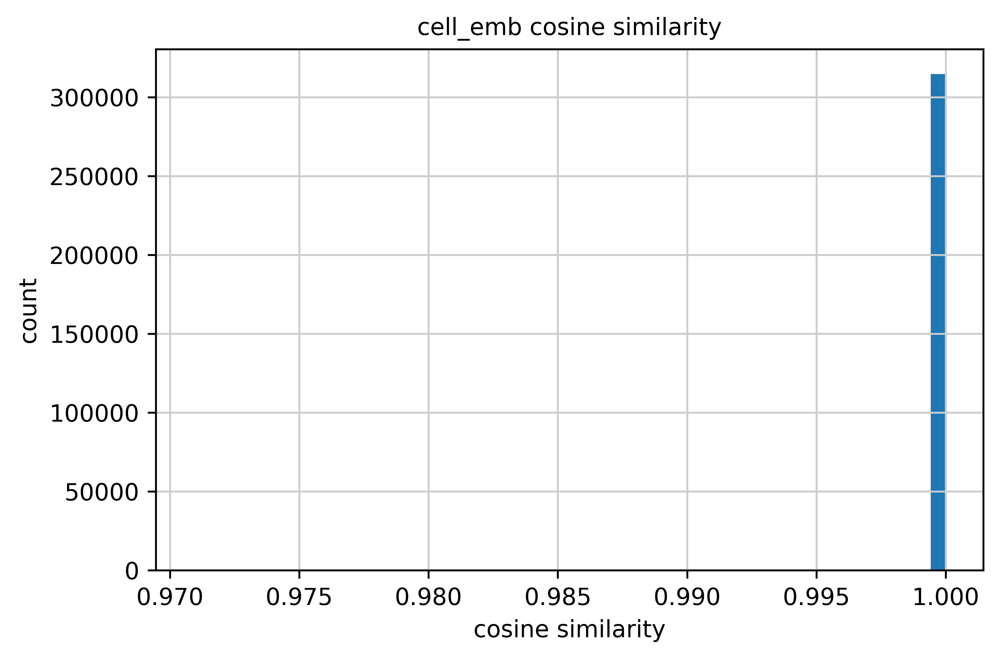

spatial_cell_emb: mean=0.999999  min=0.986335


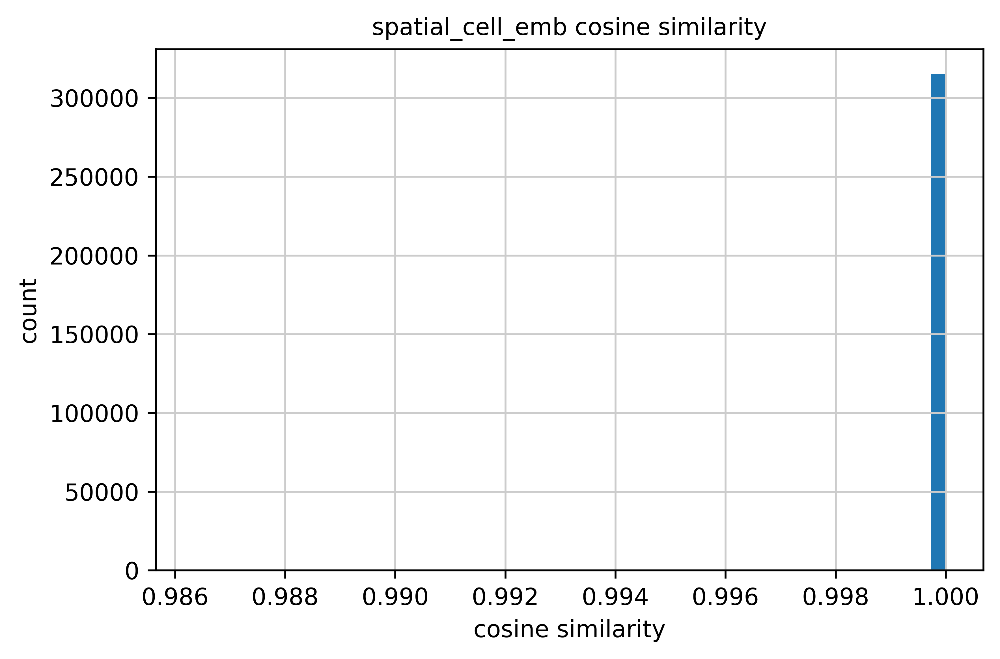

neighborhood_emb: mean=0.999999  min=0.988252


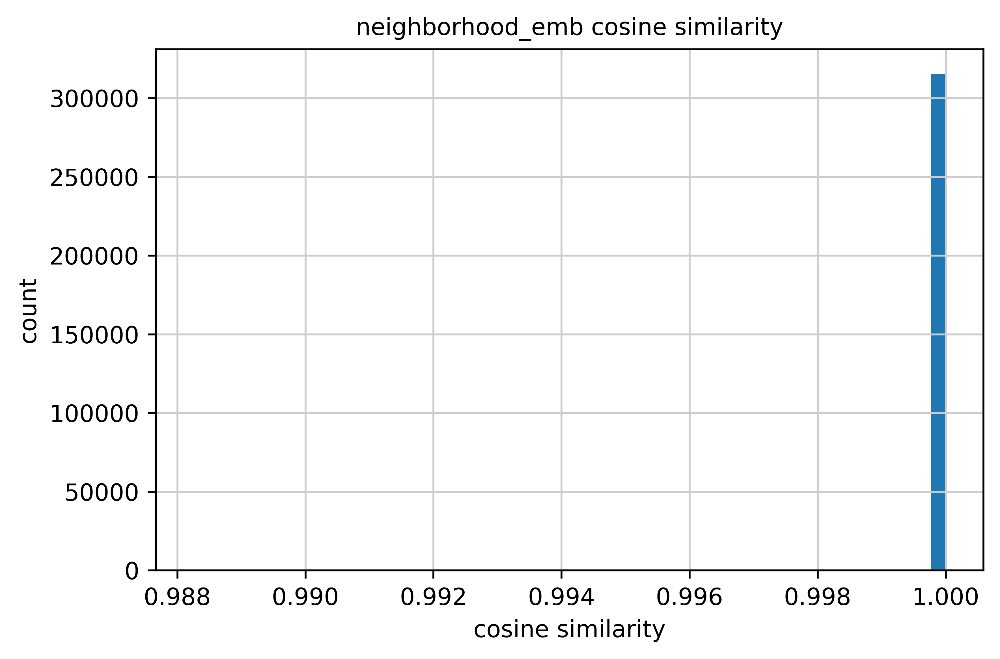

==== Perturbation index: 7 ====
Cell embedding average: 0.99999344
Spatial cell embedding average: 0.9999991
Neighborhood embedding average: 0.9999994
Lowest cell embedding average per cell type: 0.9998842477798462
Lowest spatial cell embedding average per cell type: 0.9999889135360718
Lowest neighborhood embedding average per cell type: 0.9999909400939941
Lowest cell embedding average per niche: 0.9999405741691589
Lowest spatial cell embedding average per niche: 0.9999900460243225
Lowest neighborhood embedding average per niche: 0.9999927282333374
60505
cell_emb: mean=0.999992  min=0.972048


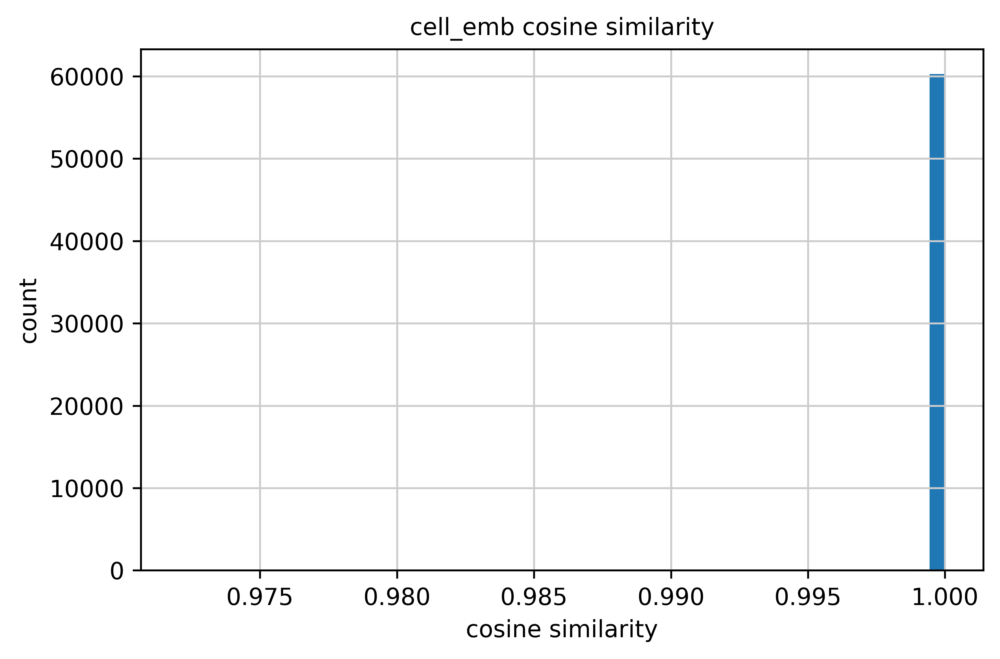

spatial_cell_emb: mean=0.999999  min=0.996211


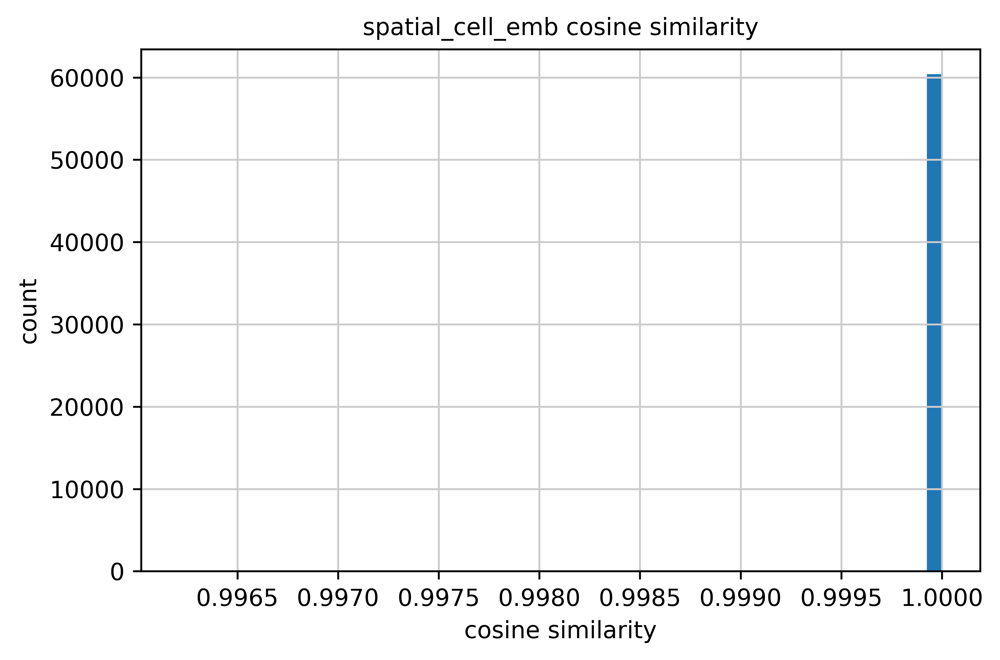

neighborhood_emb: mean=0.999999  min=0.994824


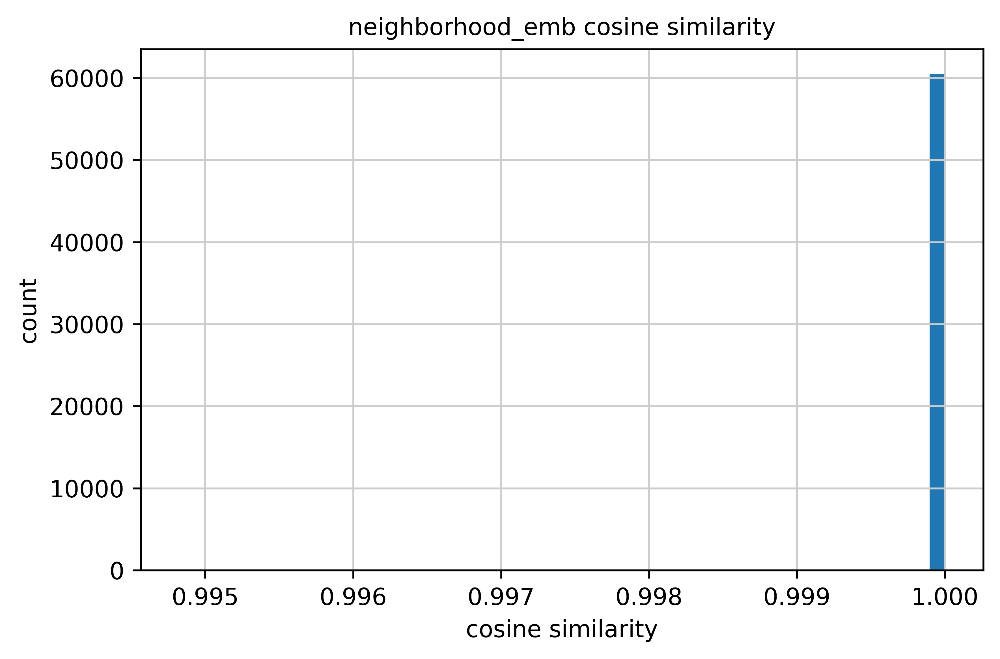

==== Perturbation index: 8 ====
Cell embedding average: 0.99999166
Spatial cell embedding average: 0.9999991
Neighborhood embedding average: 0.9999994
Lowest cell embedding average per cell type: 0.9998887777328491
Lowest spatial cell embedding average per cell type: 0.9999933838844299
Lowest neighborhood embedding average per cell type: 0.9999955892562866
Lowest cell embedding average per niche: 0.9999783635139465
Lowest spatial cell embedding average per niche: 0.9999957084655762
Lowest neighborhood embedding average per niche: 0.9999964237213135
355480
cell_emb: mean=0.999993  min=0.971063


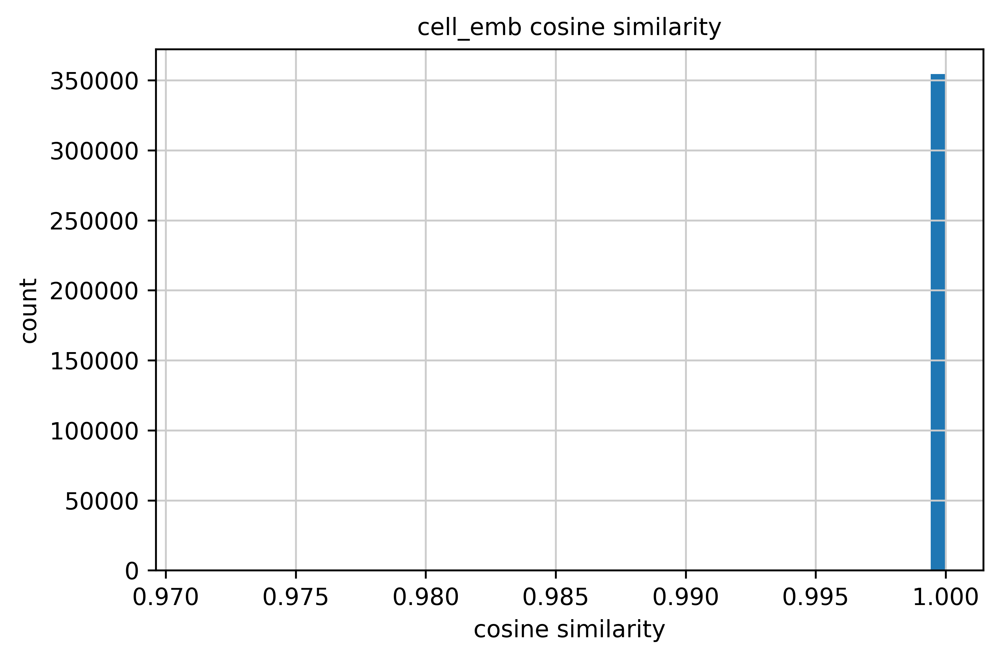

spatial_cell_emb: mean=0.999999  min=0.989158


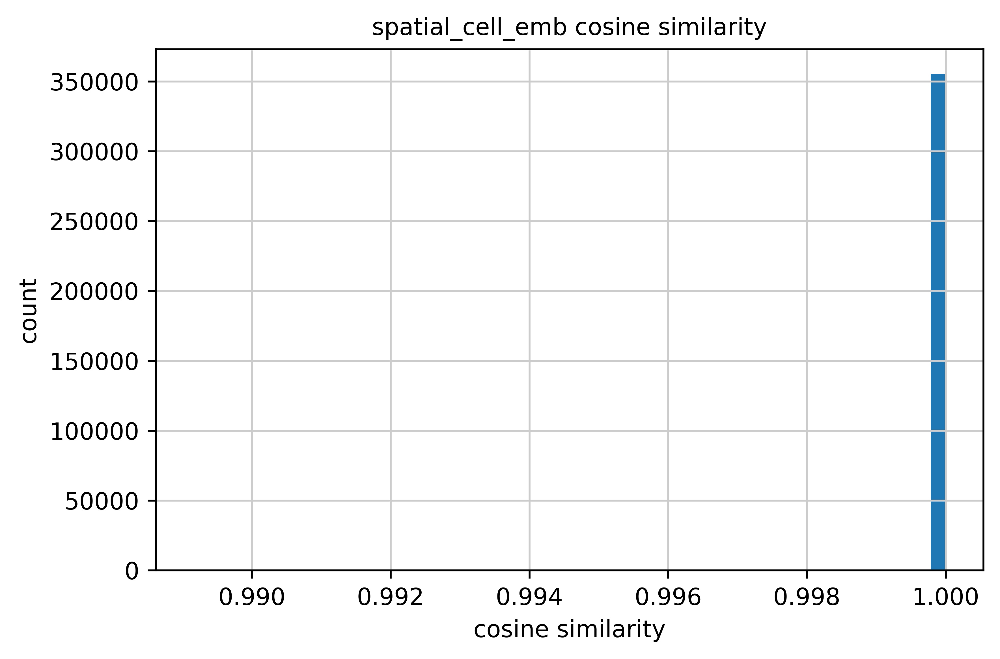

neighborhood_emb: mean=1.000000  min=0.990892


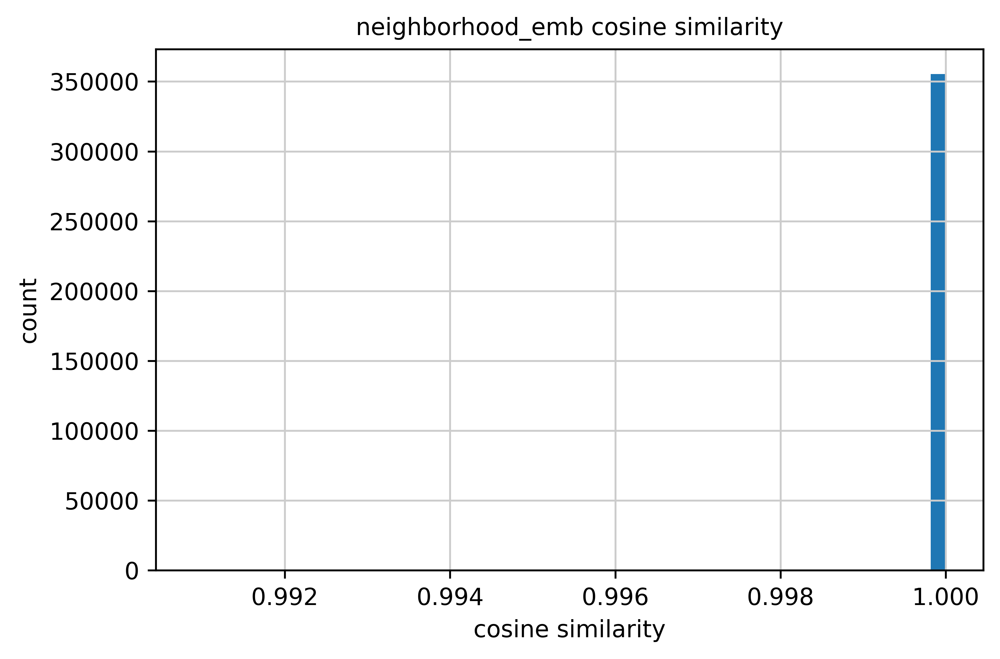

==== Perturbation index: 9 ====
Cell embedding average: 0.9999927
Spatial cell embedding average: 0.9999994
Neighborhood embedding average: 0.9999996
Lowest cell embedding average per cell type: 0.9998807907104492
Lowest spatial cell embedding average per cell type: 0.9999926686286926
Lowest neighborhood embedding average per cell type: 0.9999954104423523
Lowest cell embedding average per niche: 0.9999540448188782
Lowest spatial cell embedding average per niche: 0.9999935626983643
Lowest neighborhood embedding average per niche: 0.9999954104423523
94060
cell_emb: mean=0.999996  min=0.986887


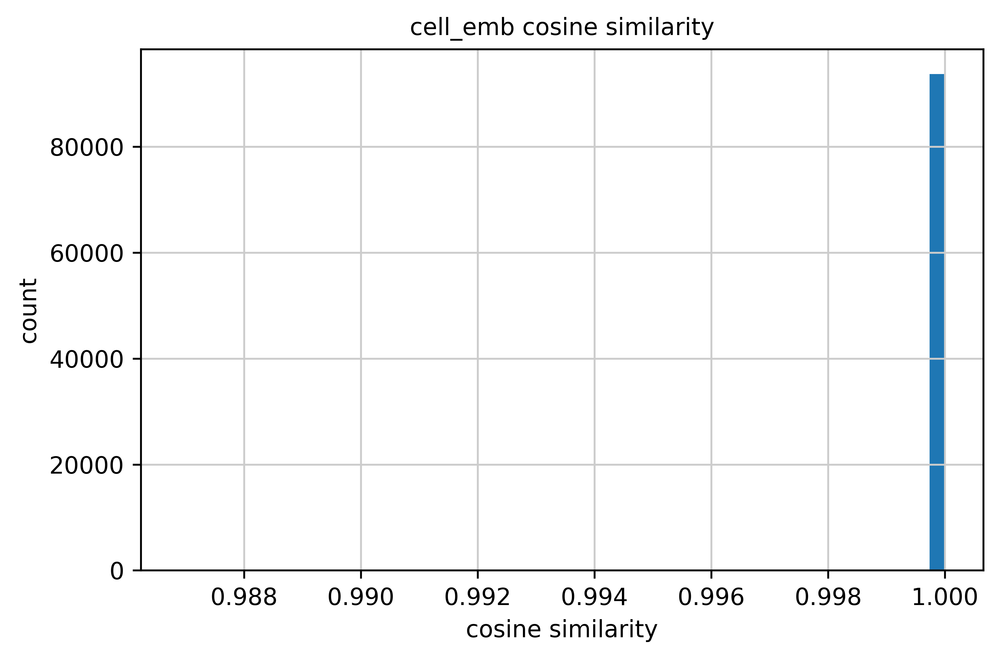

spatial_cell_emb: mean=0.999999  min=0.996837


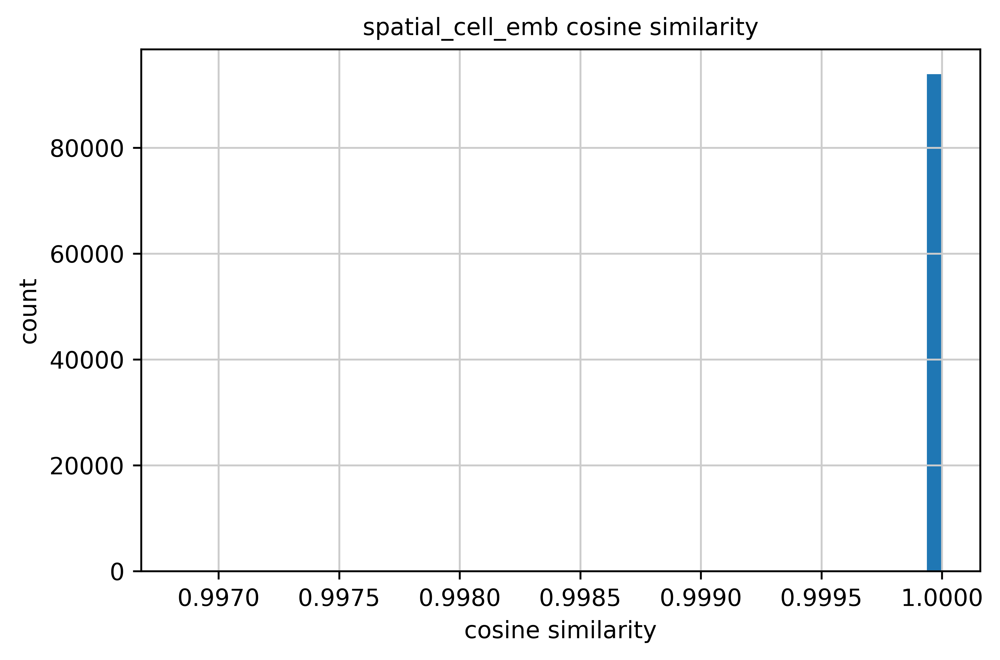

neighborhood_emb: mean=1.000000  min=0.996824


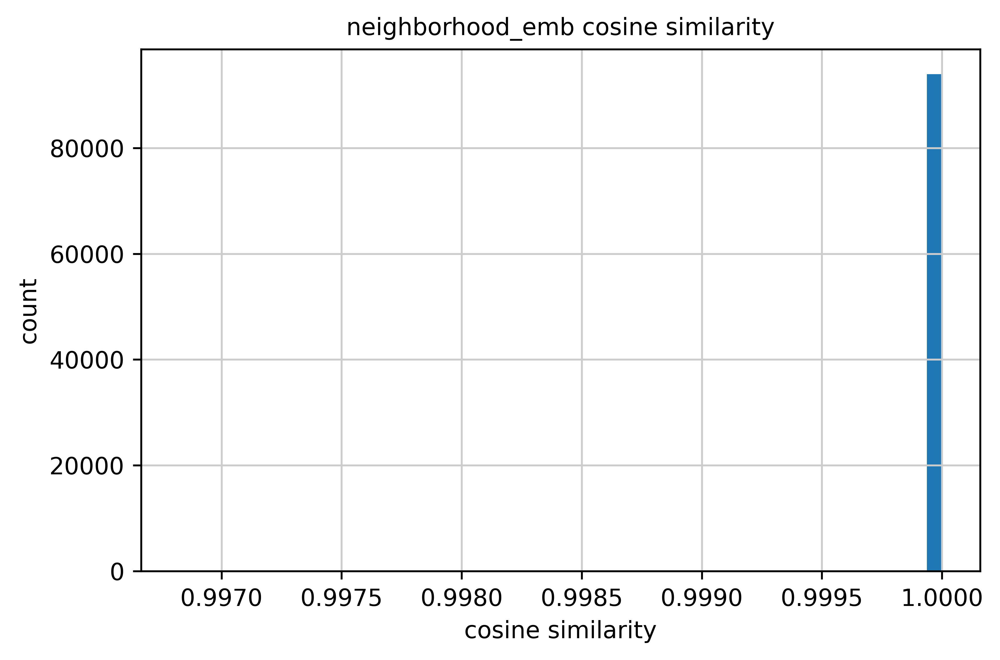

==== Perturbation index: 10 ====
Cell embedding average: 0.99999577
Spatial cell embedding average: 0.99999934
Neighborhood embedding average: 0.9999996
Lowest cell embedding average per cell type: 0.99993896484375
Lowest spatial cell embedding average per cell type: 0.9999896883964539
Lowest neighborhood embedding average per cell type: 0.9999915361404419
Lowest cell embedding average per niche: 0.999980092048645
Lowest spatial cell embedding average per niche: 0.999995768070221
Lowest neighborhood embedding average per niche: 0.9999963641166687
479290
cell_emb: mean=0.999993  min=0.971063


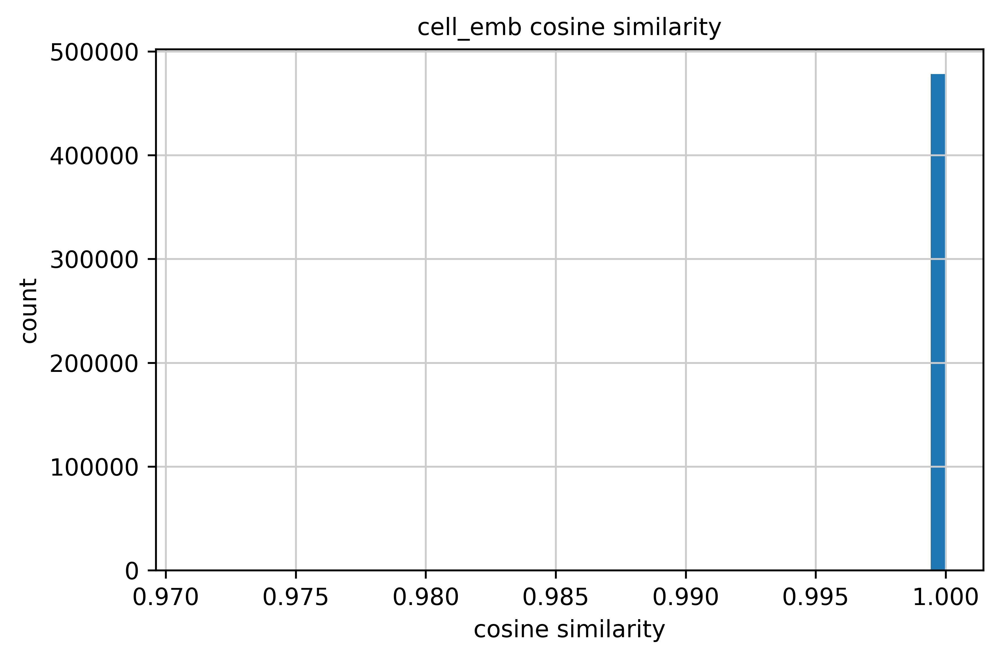

spatial_cell_emb: mean=0.999999  min=0.994352


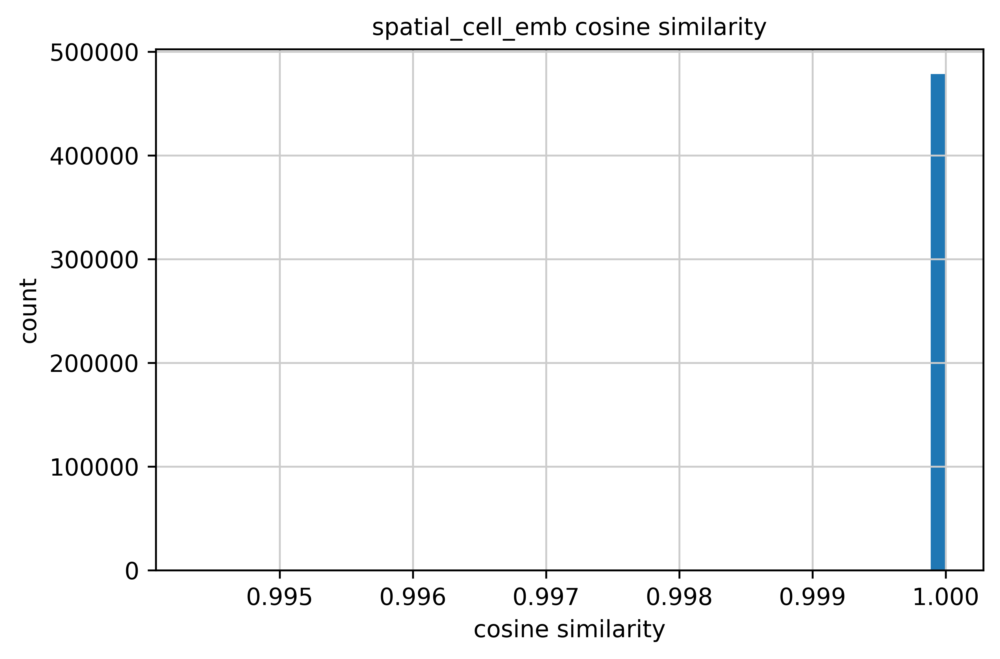

neighborhood_emb: mean=1.000000  min=0.994351


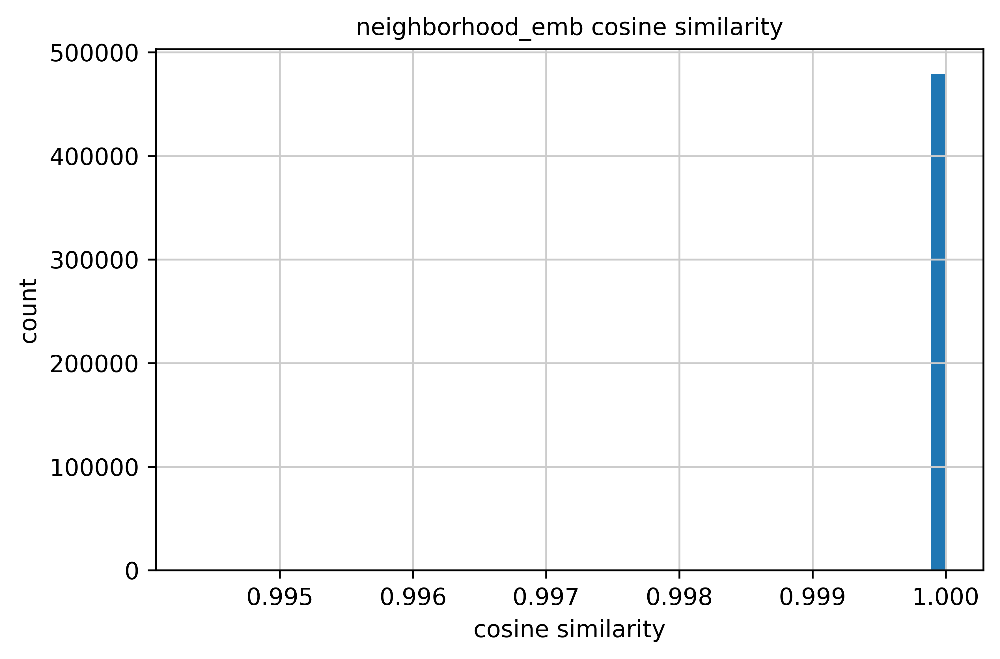

==== Perturbation index: 11 ====
Cell embedding average: 0.99999285
Spatial cell embedding average: 0.99999946
Neighborhood embedding average: 0.9999997
Lowest cell embedding average per cell type: 0.9998997449874878
Lowest spatial cell embedding average per cell type: 0.9999871850013733
Lowest neighborhood embedding average per cell type: 0.9999849200248718
Lowest cell embedding average per niche: 0.999960720539093
Lowest spatial cell embedding average per niche: 0.999993622303009
Lowest neighborhood embedding average per niche: 0.9999952912330627
9412
cell_emb: mean=0.999997  min=0.990868


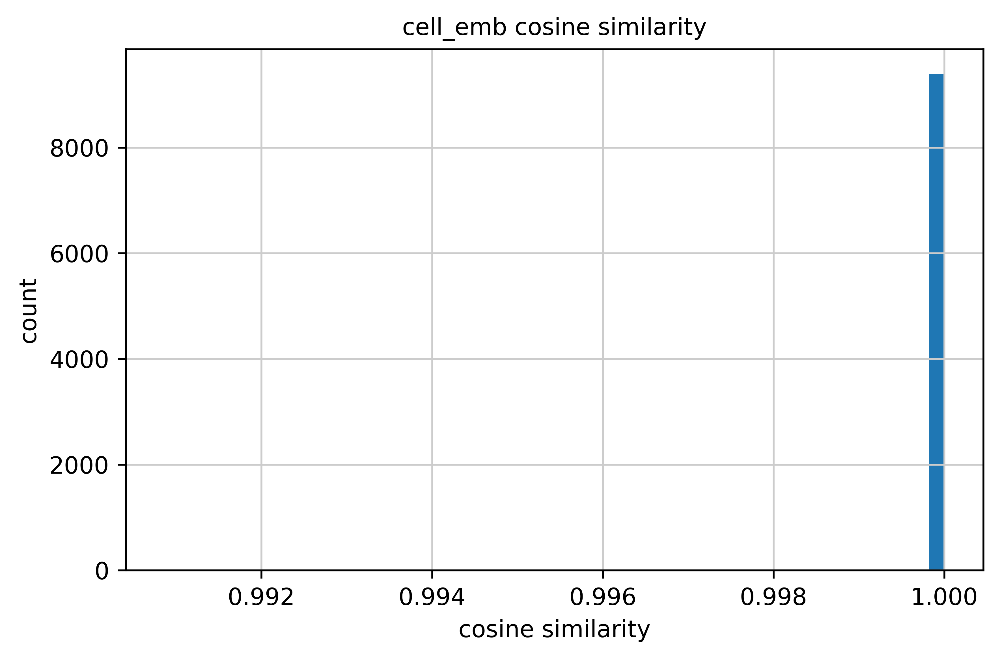

spatial_cell_emb: mean=1.000000  min=0.999723


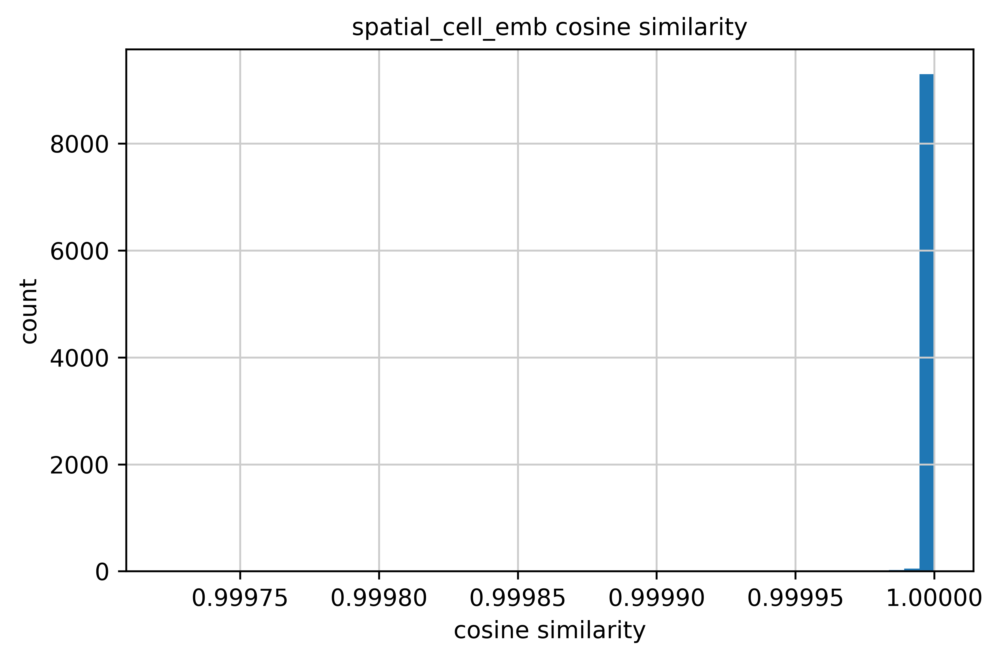

neighborhood_emb: mean=1.000000  min=0.999722


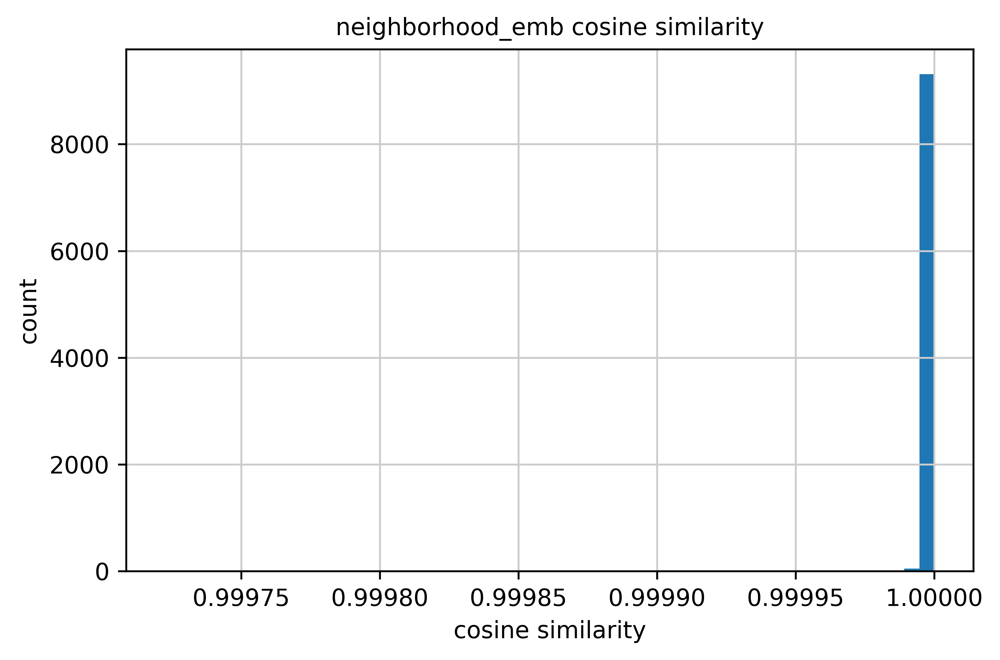

==== Perturbation index: 12 ====
Cell embedding average: 0.9999974
Spatial cell embedding average: 0.9999997
Neighborhood embedding average: 0.9999998
Lowest cell embedding average per cell type: 0.9999107122421265
Lowest spatial cell embedding average per cell type: 0.999991774559021
Lowest neighborhood embedding average per cell type: 0.9999915361404419
Lowest cell embedding average per niche: 0.9999962449073792
Lowest spatial cell embedding average per niche: 0.999994695186615
Lowest neighborhood embedding average per niche: 0.9999943971633911
82338
cell_emb: mean=0.999995  min=0.983733


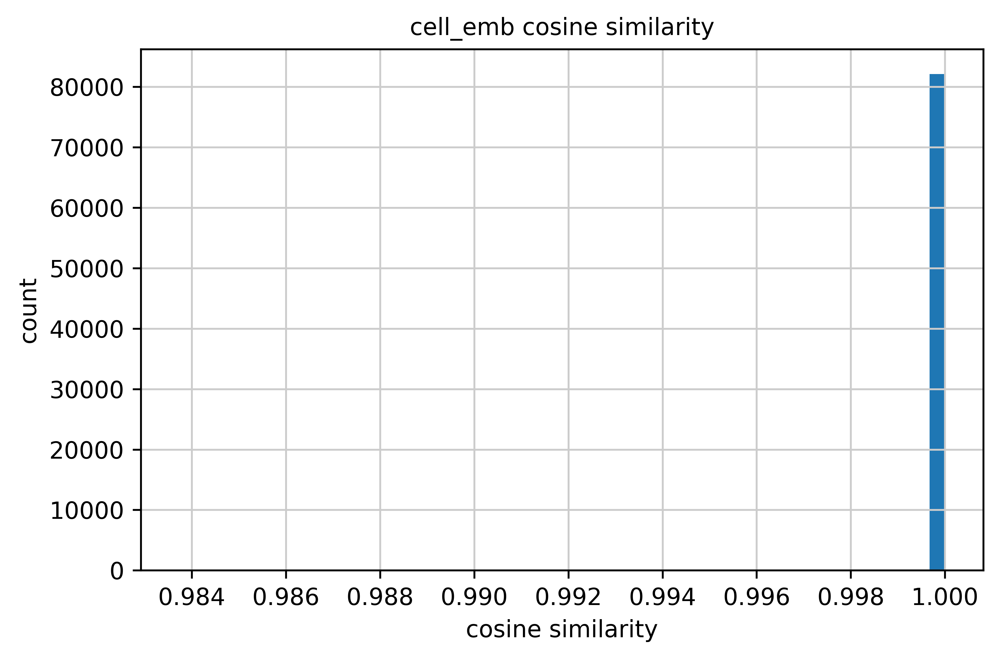

spatial_cell_emb: mean=0.999999  min=0.994352


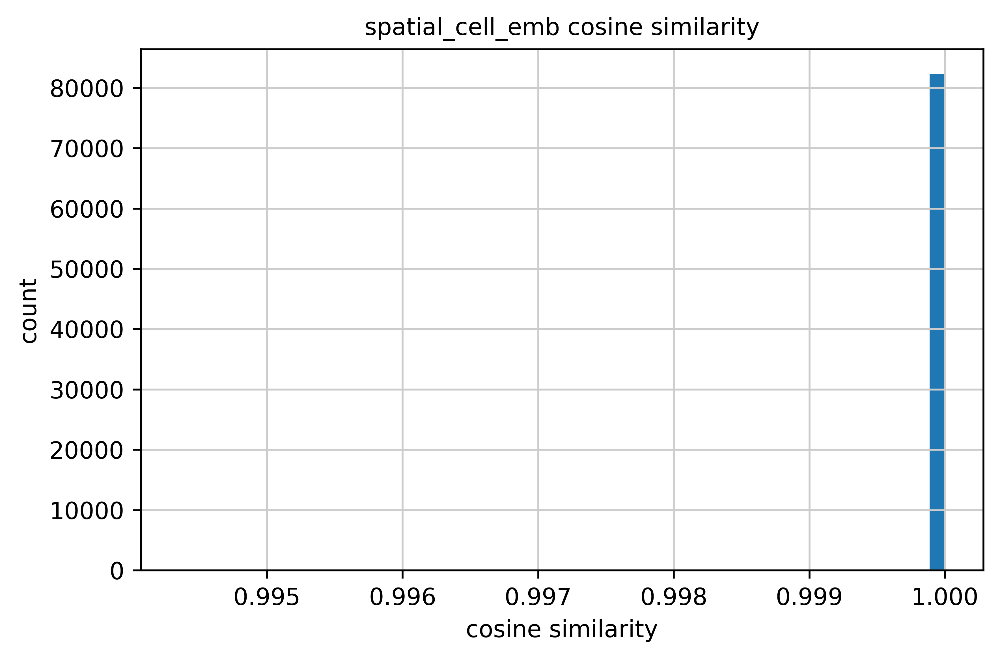

neighborhood_emb: mean=1.000000  min=0.994351


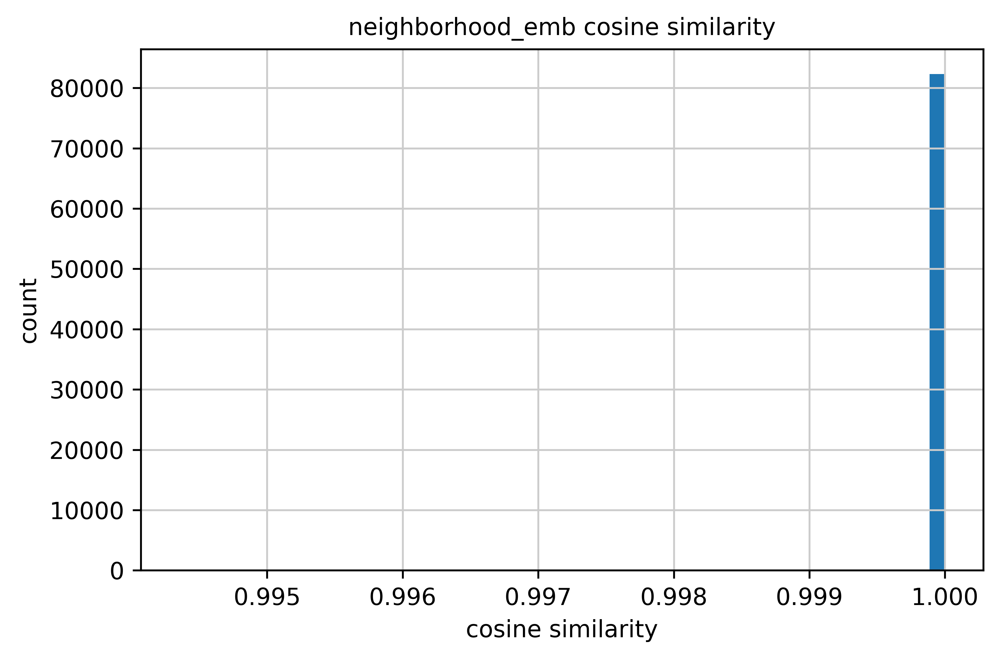

==== Perturbation index: 13 ====
Cell embedding average: 0.9999952
Spatial cell embedding average: 0.99999934
Neighborhood embedding average: 0.99999964
Lowest cell embedding average per cell type: 0.9998871684074402
Lowest spatial cell embedding average per cell type: 0.9999915361404419
Lowest neighborhood embedding average per cell type: 0.9999935030937195
Lowest cell embedding average per niche: 0.9999539852142334
Lowest spatial cell embedding average per niche: 0.999994158744812
Lowest neighborhood embedding average per niche: 0.9999955892562866
2725
cell_emb: mean=0.999976  min=0.992035


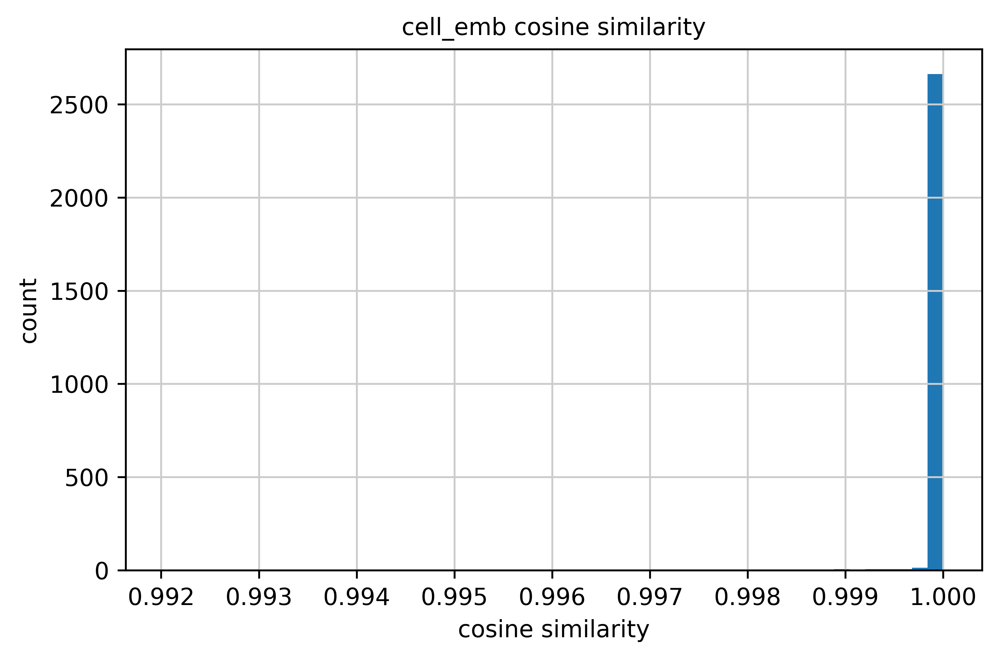

spatial_cell_emb: mean=0.999998  min=0.999615


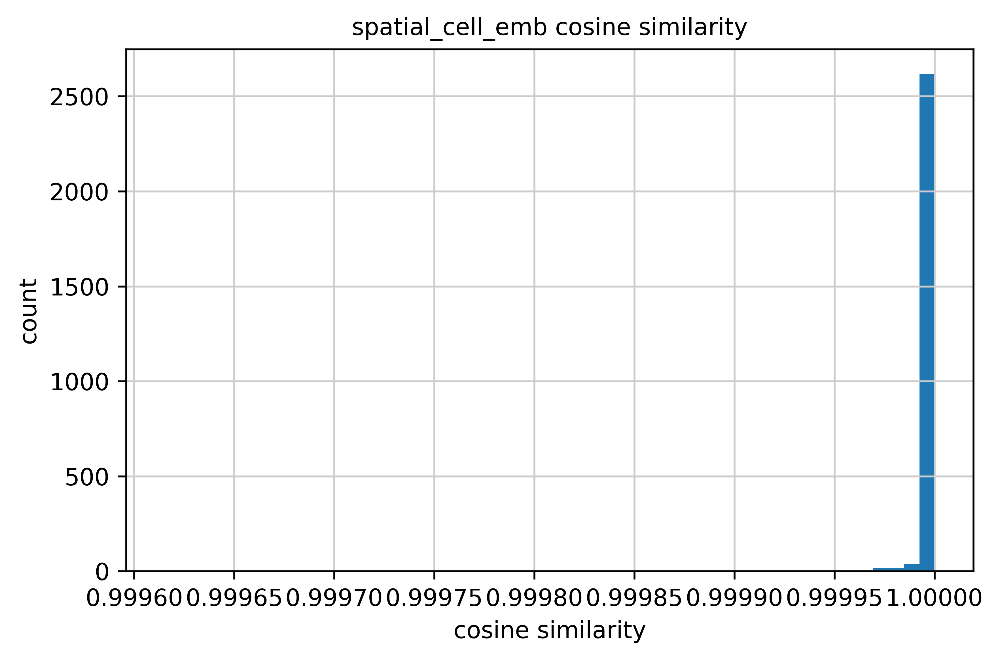

neighborhood_emb: mean=0.999999  min=0.999872


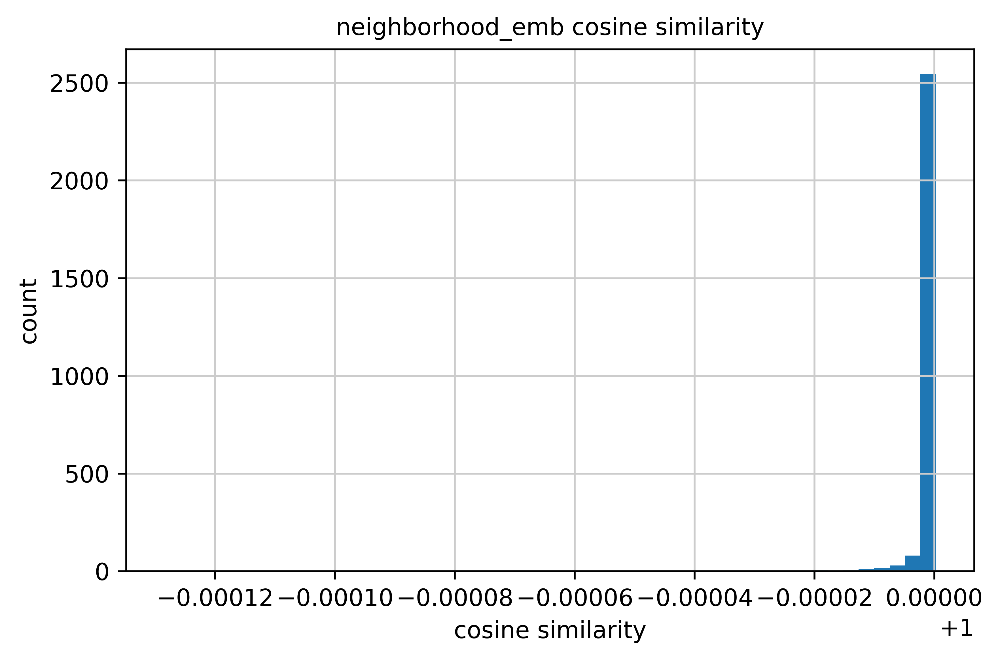

==== Perturbation index: 14 ====
Cell embedding average: 0.9999758
Spatial cell embedding average: 0.99999845
Neighborhood embedding average: 0.9999991
Lowest cell embedding average per cell type: 0.9998856782913208
Lowest spatial cell embedding average per cell type: 0.9999939799308777
Lowest neighborhood embedding average per cell type: 0.9999940991401672
Lowest cell embedding average per niche: 0.999907374382019
Lowest spatial cell embedding average per niche: 0.9999905824661255
Lowest neighborhood embedding average per niche: 0.9999936819076538


Filter: 100%|███████████████████████████████████████████| 742831/742831 [03:11<00:00, 3875.50 examples/s]


26328
cell_emb: mean=0.999990  min=0.984128


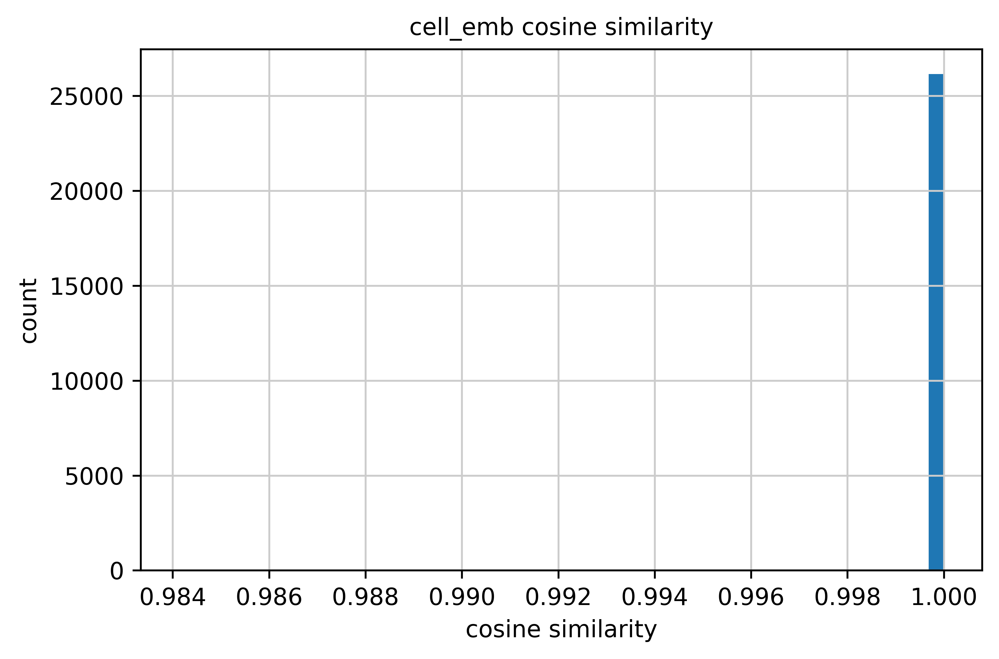

spatial_cell_emb: mean=0.999999  min=0.998865


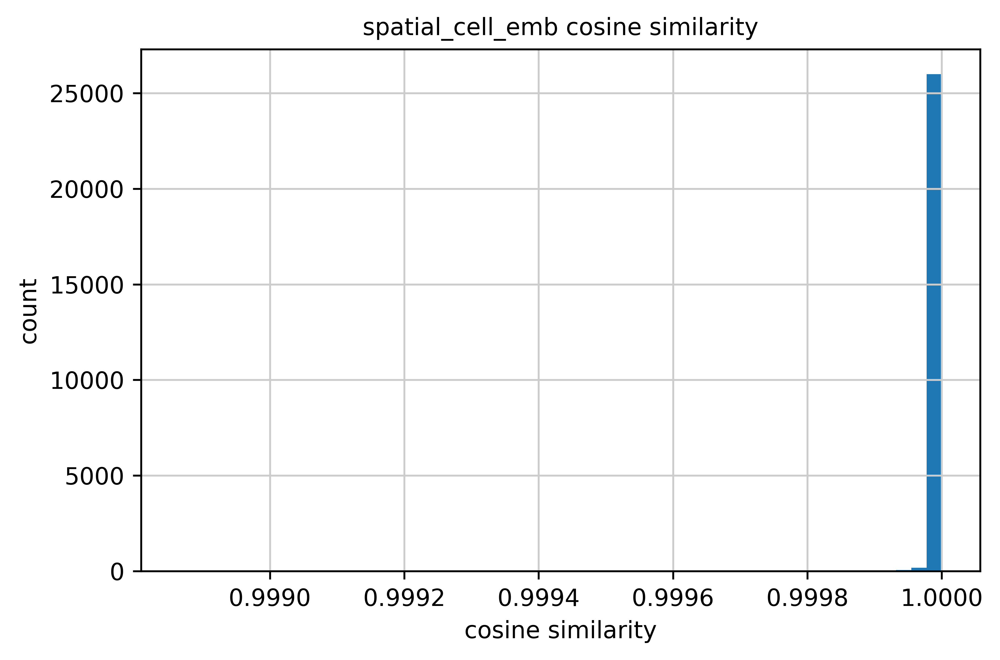

neighborhood_emb: mean=0.999999  min=0.999199


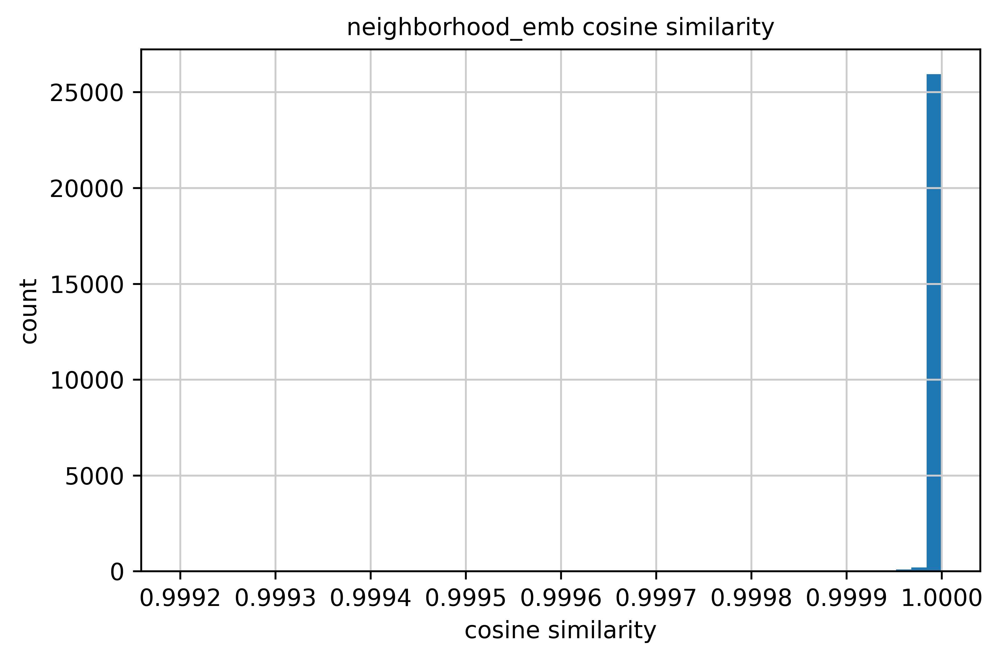

==== Perturbation index: 15 ====
Cell embedding average: 0.9999899
Spatial cell embedding average: 0.99999857
Neighborhood embedding average: 0.9999991
Lowest cell embedding average per cell type: 0.9998867511749268
Lowest spatial cell embedding average per cell type: 0.999987006187439
Lowest neighborhood embedding average per cell type: 0.9999831914901733
Lowest cell embedding average per niche: 0.9999371767044067
Lowest spatial cell embedding average per niche: 0.9999910593032837
Lowest neighborhood embedding average per niche: 0.9999929070472717
681
cell_emb: mean=0.999943  min=0.992841


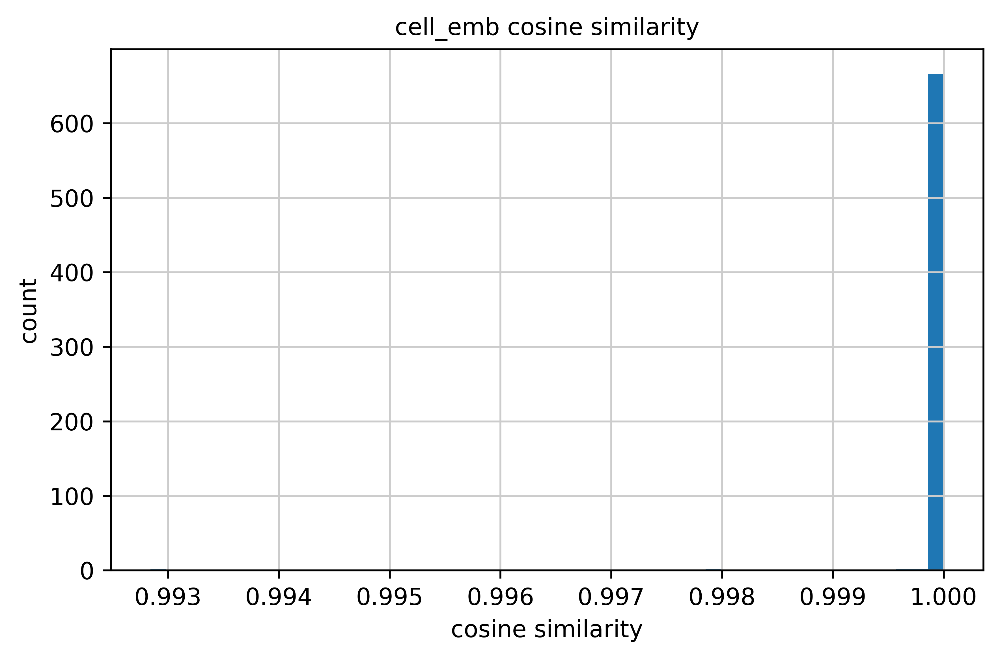

spatial_cell_emb: mean=0.999995  min=0.999536


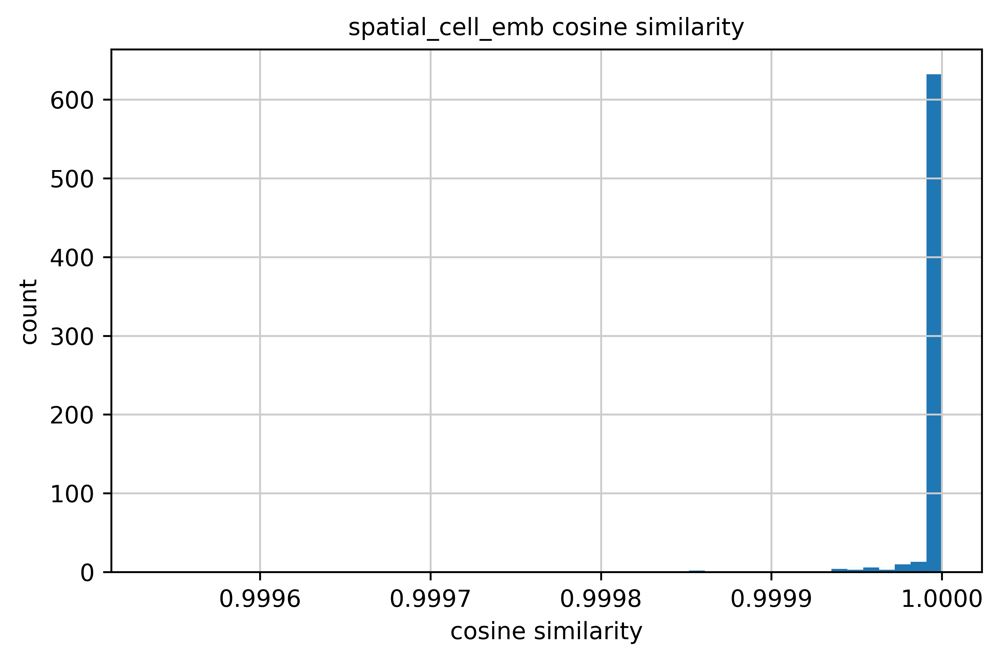

neighborhood_emb: mean=0.999997  min=0.999506


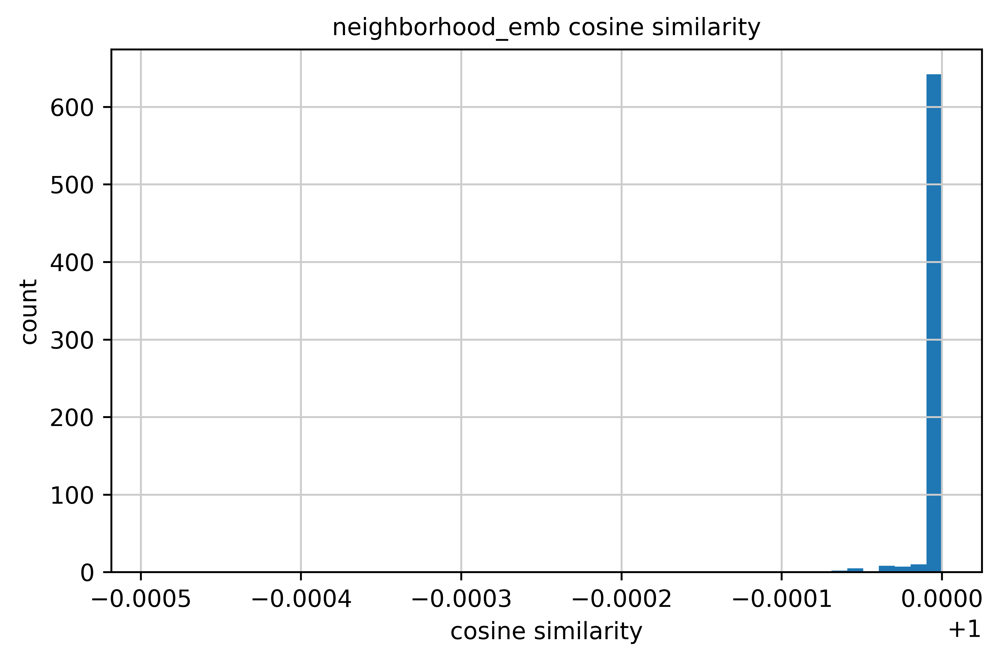

==== Perturbation index: 16 ====
Cell embedding average: 0.99994266
Spatial cell embedding average: 0.99999505
Neighborhood embedding average: 0.9999966
Lowest cell embedding average per cell type: 0.9997933506965637
Lowest spatial cell embedding average per cell type: 0.9999648332595825
Lowest neighborhood embedding average per cell type: 0.9999799728393555
Lowest cell embedding average per niche: 0.9998716115951538
Lowest spatial cell embedding average per niche: 0.9999825954437256
Lowest neighborhood embedding average per niche: 0.9999831914901733
6571
cell_emb: mean=0.999971  min=0.986873


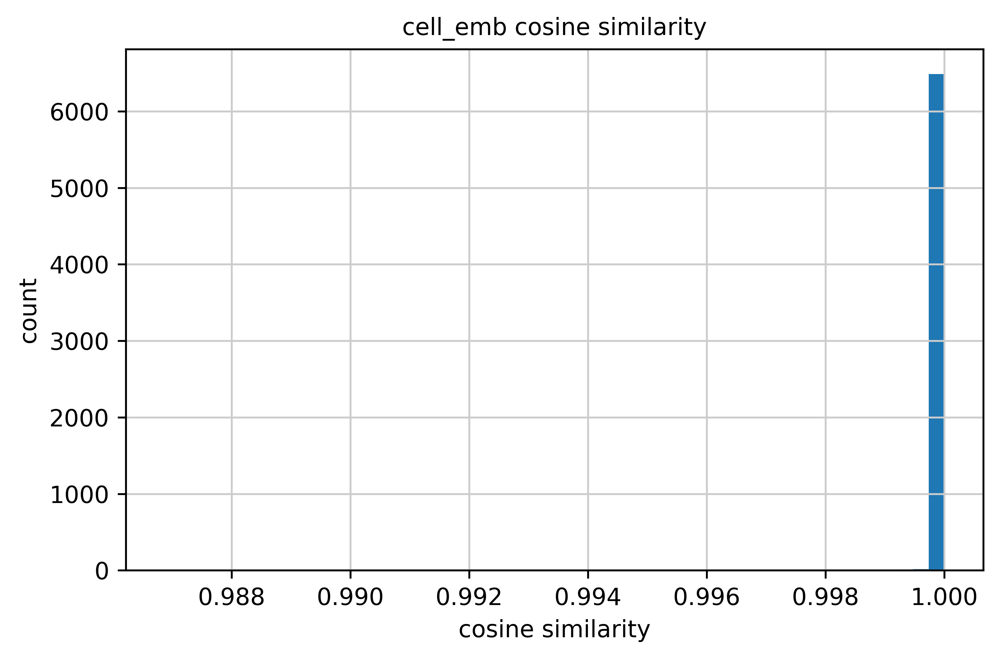

spatial_cell_emb: mean=0.999996  min=0.999101


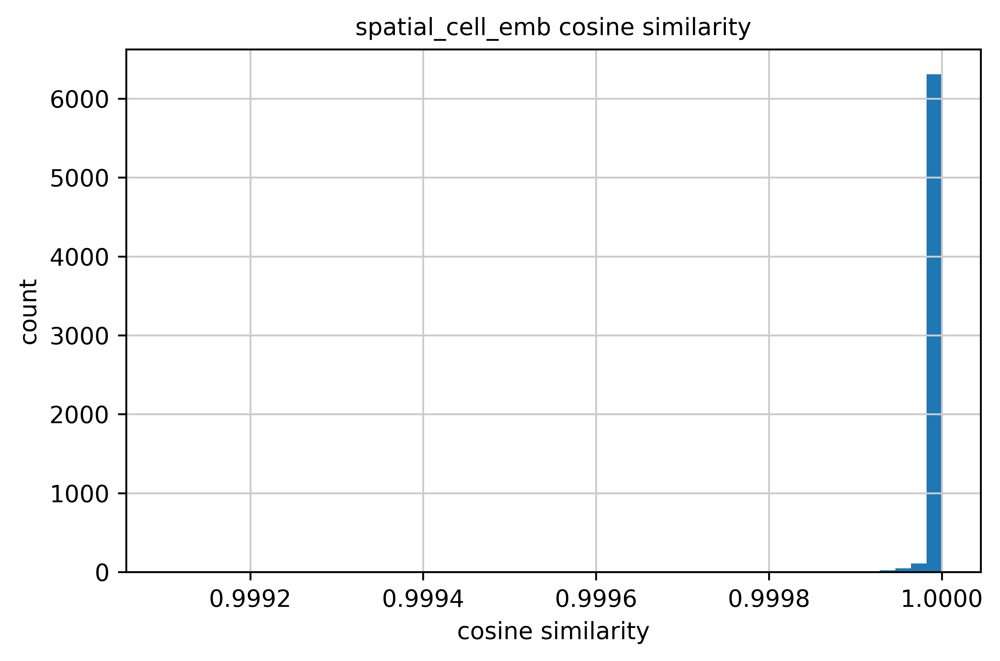

neighborhood_emb: mean=0.999997  min=0.999563


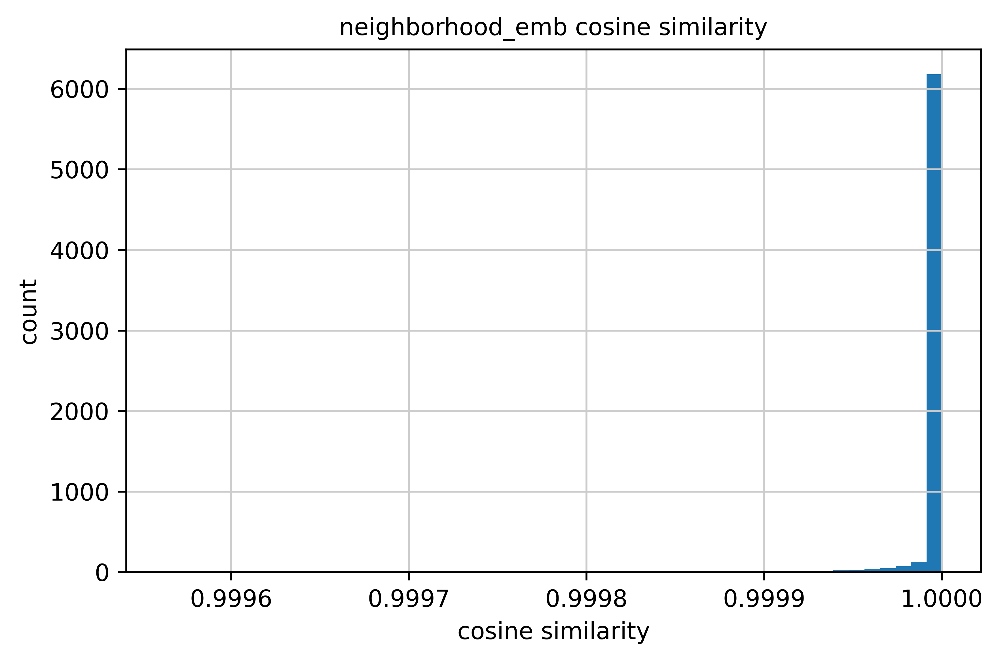

==== Perturbation index: 17 ====
Cell embedding average: 0.99997133
Spatial cell embedding average: 0.9999958
Neighborhood embedding average: 0.9999973
Lowest cell embedding average per cell type: 0.9994736909866333
Lowest spatial cell embedding average per cell type: 0.9998238682746887
Lowest neighborhood embedding average per cell type: 0.9999095797538757
Lowest cell embedding average per niche: 0.9998809099197388
Lowest spatial cell embedding average per niche: 0.9999812841415405
Lowest neighborhood embedding average per niche: 0.9999875426292419


In [176]:
for pert_idx in range(len(pert_genes)*2):

    ind_pert_filtered_dataset = perturbed_dataset.filter(
        lambda x: x[f"pert_flag_idx_{pert_idx}"])

    ind_pert_cell_ids = list(ind_pert_filtered_dataset['cell_id'])
    print(len(ind_pert_cell_ids))
    
    adata_sub_ind_pert = adata[adata.obs_names.isin(ind_pert_cell_ids)]

    results, summary = analyze_embedding_cos_sims(
    adata_sub_ind_pert,
    pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
           ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
           ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")]
    )
    
    df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
        adata_sub_ind_pert,
        pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
               ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
               ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")],
        label_key=cell_type_key,
        agg="mean",
        sort_by="cell_emb",
        ascending=True,
    )
    df_cos_sim_sorted_cell_type

    df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
        adata_sub_ind_pert,
        pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
               ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
               ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")],
        label_key=niche_key,
        agg="mean",
        sort_by="cell_emb",
        ascending=True,
    )
    df_cos_sim_sorted_niche

    print(f"==== Perturbation index: {pert_idx} ====")
    print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
    print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
    print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
    print("========================================")
    print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
    print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
    print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
    print("========================================")
    print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
    print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
    print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")
    print("========================================")

#### 2.5.2.2 Cell Perturbations

In [177]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [178]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

199168


In [179]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.997339  min=0.875217


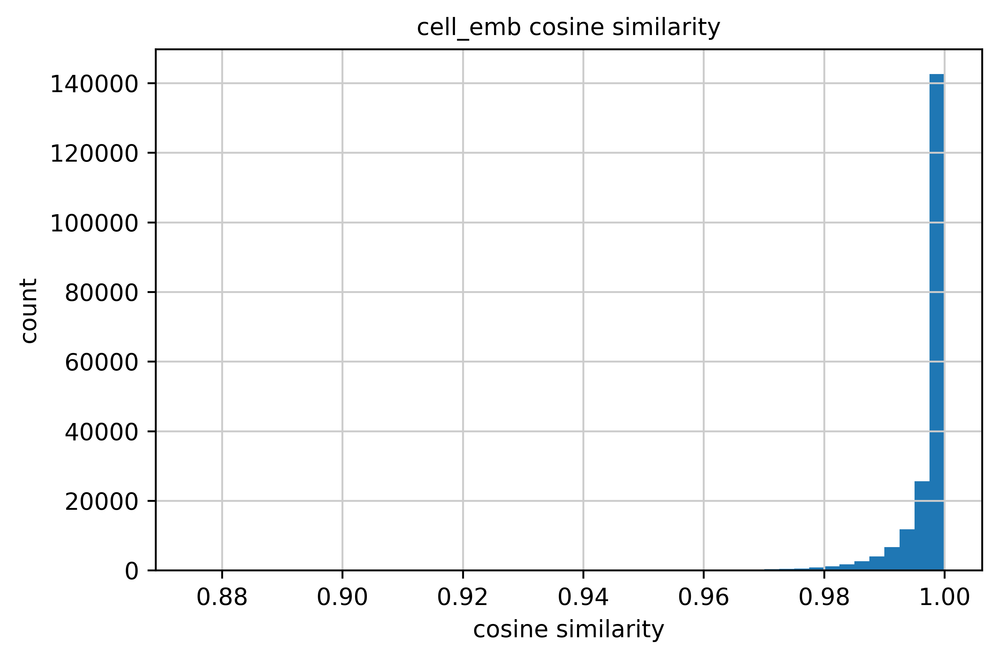

spatial_cell_emb: mean=0.999468  min=0.981702


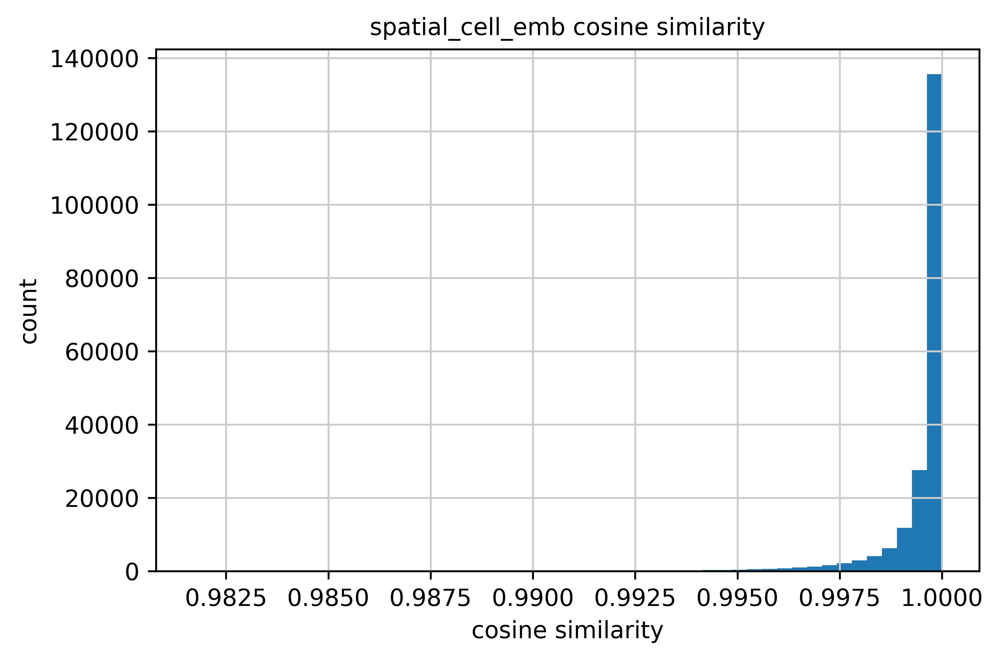

neighborhood_emb: mean=0.999600  min=0.981631


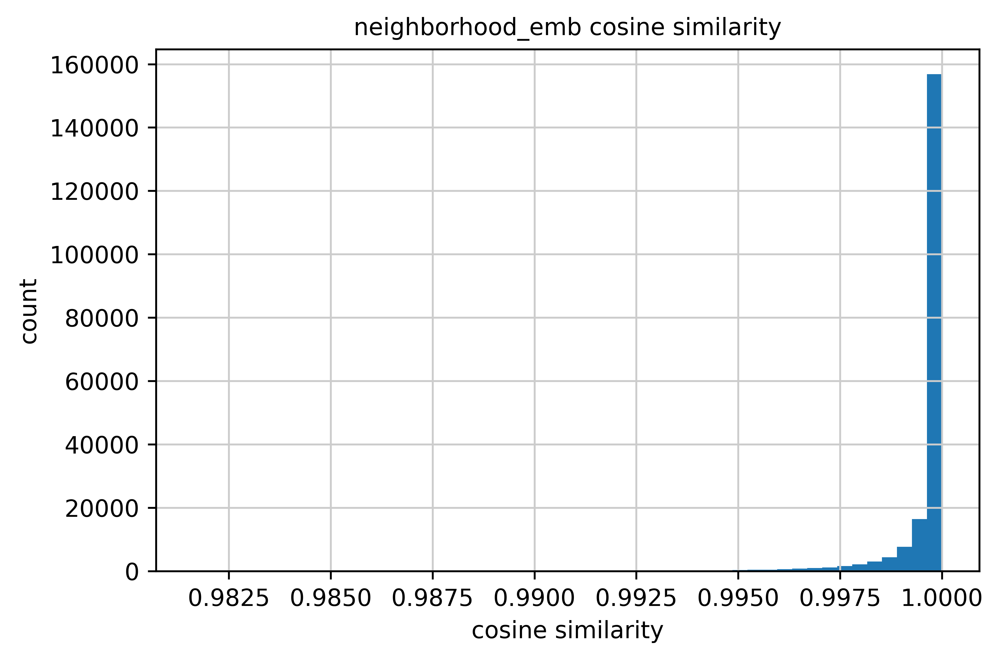

In [180]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [181]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Memory B cell,163,0.990315,0.998823,0.999529
1,Neuron,422,0.991932,0.999040,0.999544
2,CD4+ T cell,915,0.993124,0.998995,0.999386
3,Descending thin limb,493,0.993649,0.999301,0.999590
4,CD16+ monocyte,10,0.994352,0.999665,0.999849
5,Vascular mural cell,28614,0.995113,0.999397,0.999638
6,CD8+ T cell,1718,0.995289,0.999244,0.999390
7,Fibroblast,656,0.995606,0.999187,0.999290
8,Natural killer cell,69,0.995656,0.999549,0.999614
9,Proximal tubule segment 2,620,0.995695,0.999651,0.999859


In [182]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Proximal nephron neighborhood,47594,0.996458,0.999587,0.999798
1,Loop of Henle neighborhood,15872,0.996928,0.999515,0.999661
2,Fibrovascular neighborhood,39597,0.997026,0.999313,0.999477
3,Injured proximal nephron neighborhood,6470,0.997383,0.999312,0.999448
4,Glomerular neighborhood,54354,0.997971,0.999785,0.999869
5,Distal nephron neighborhood,35281,0.998086,0.998998,0.999058


In [183]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.9973395
Spatial cell embedding average: 0.99946755
Neighborhood embedding average: 0.99960023
Lowest cell embedding average per cell type: 0.9903149008750916
Lowest spatial cell embedding average per cell type: 0.9987409114837646
Lowest neighborhood embedding average per cell type: 0.9987947940826416
Lowest cell embedding average per niche: 0.9964577555656433
Lowest spatial cell embedding average per niche: 0.9989978075027466
Lowest neighborhood embedding average per niche: 0.9990584254264832


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


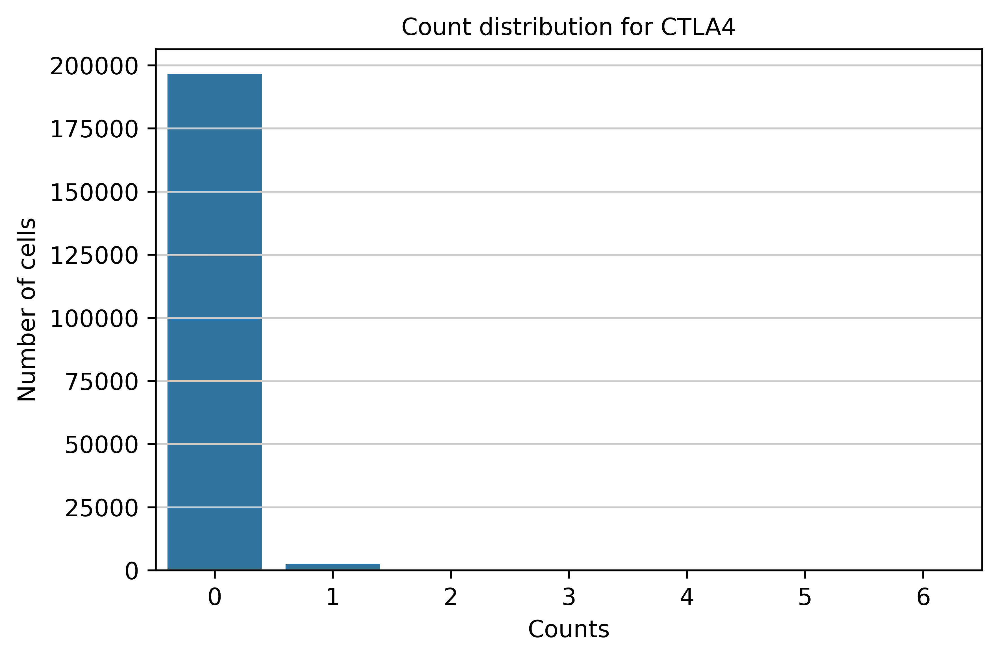

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


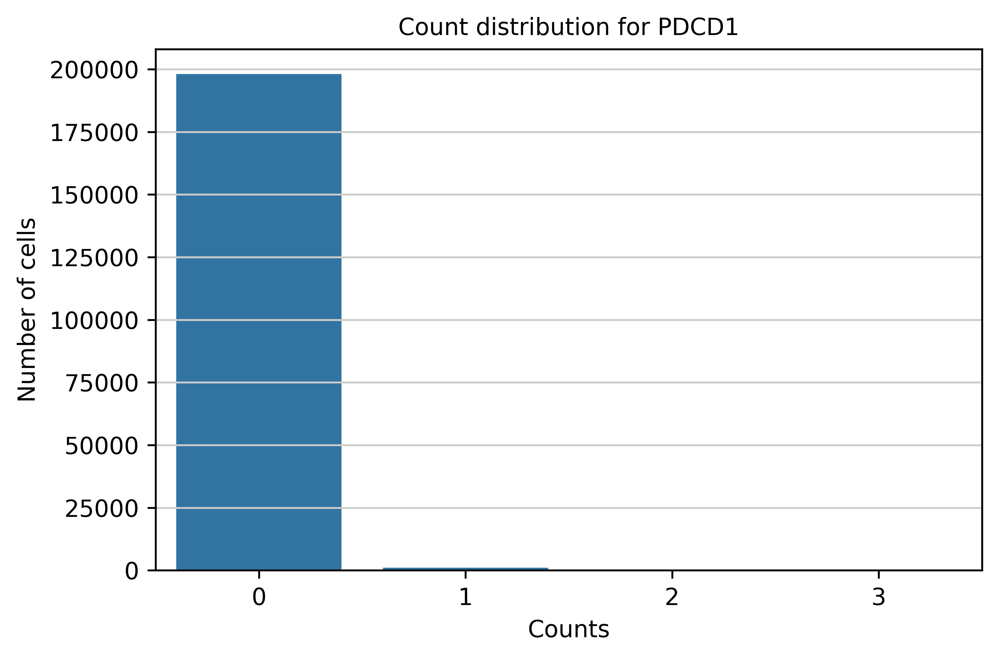

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


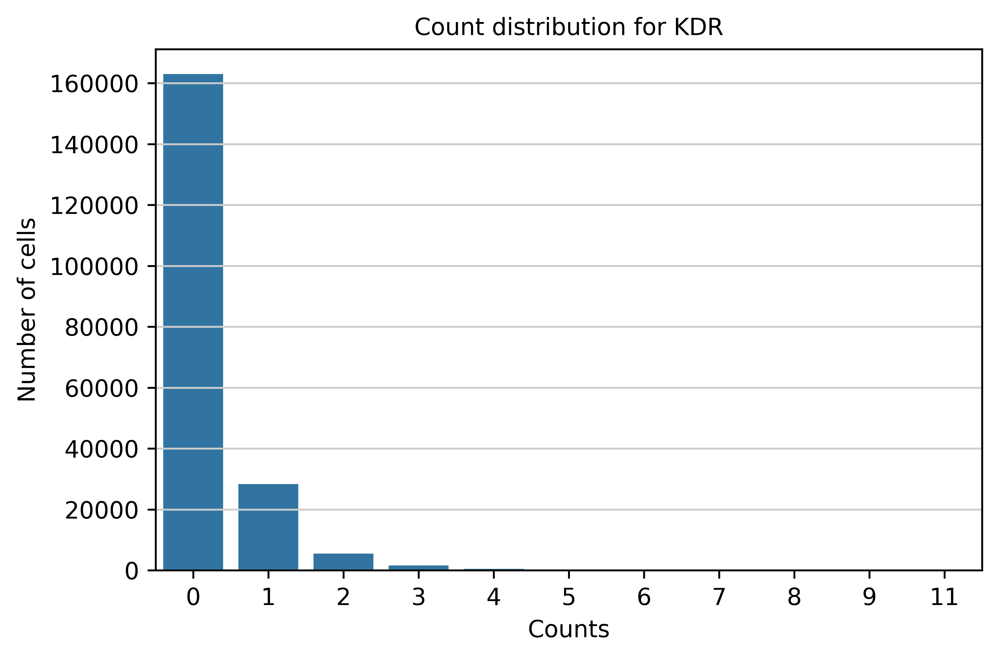

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


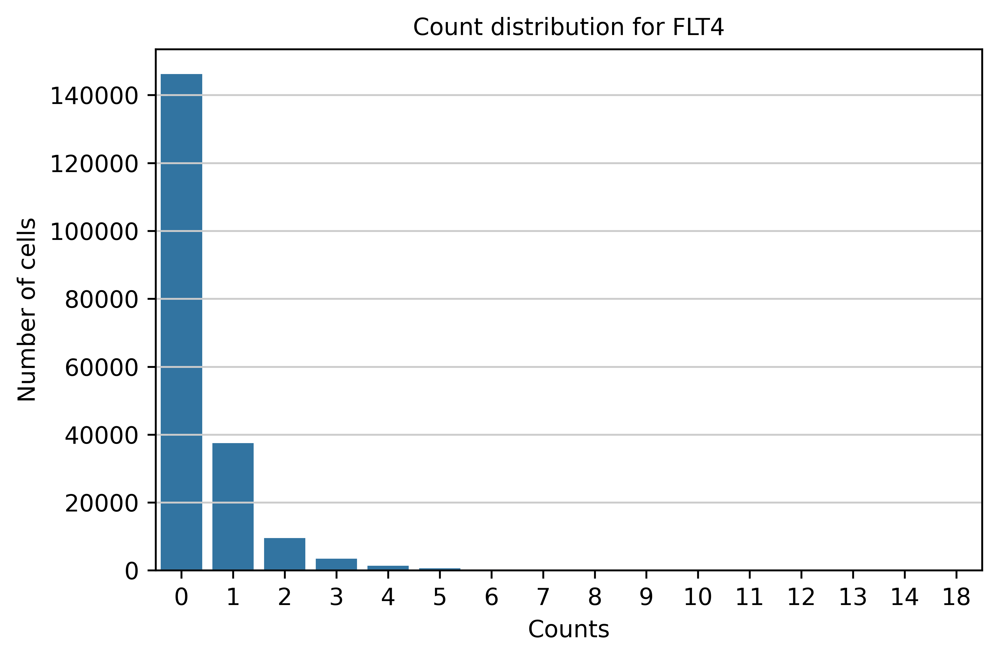

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


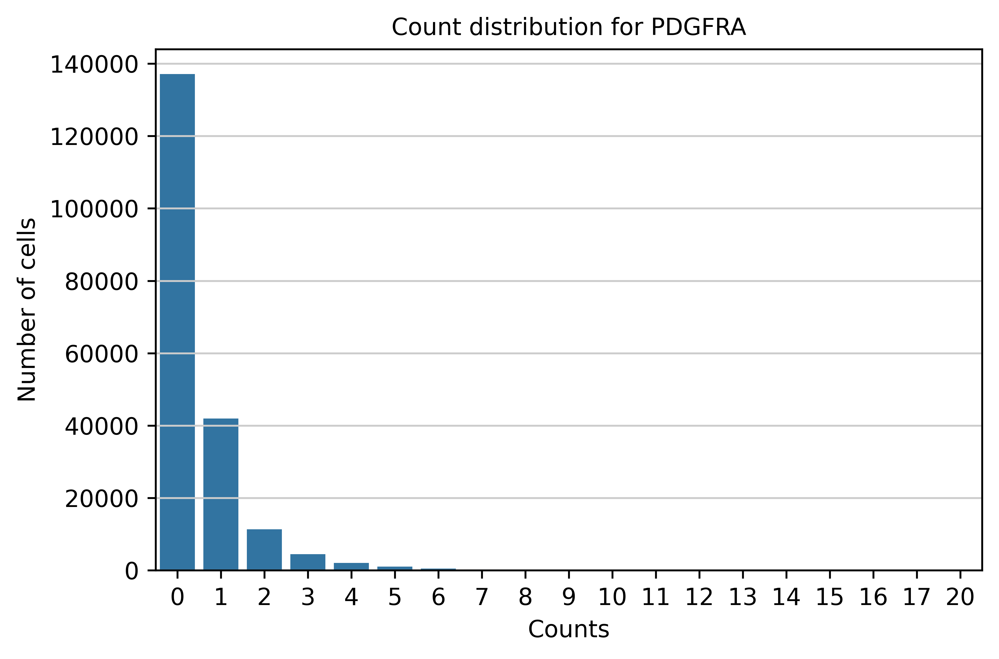

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


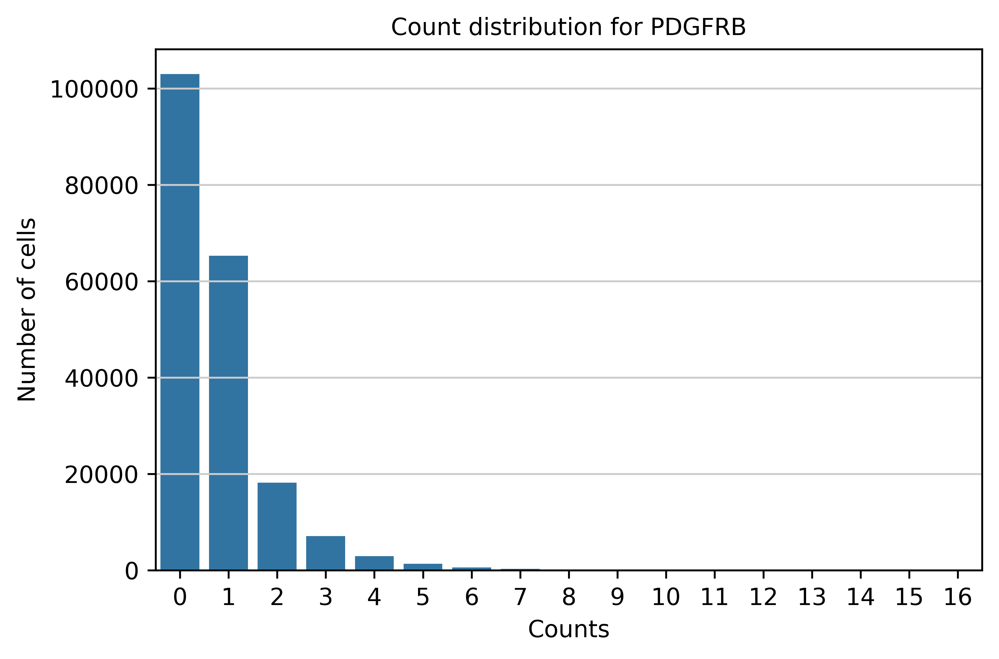

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


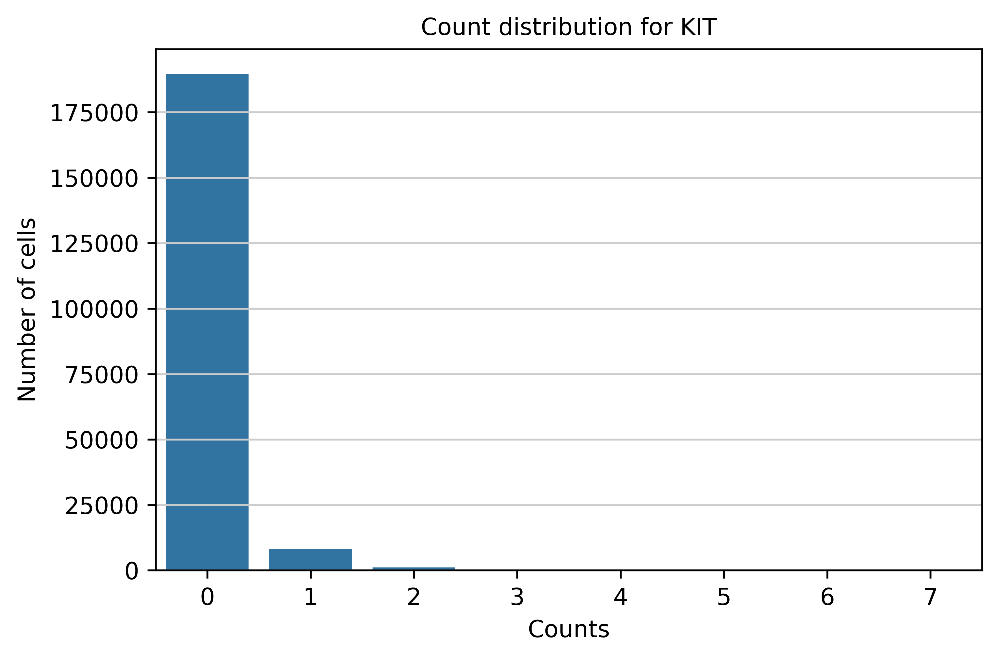

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


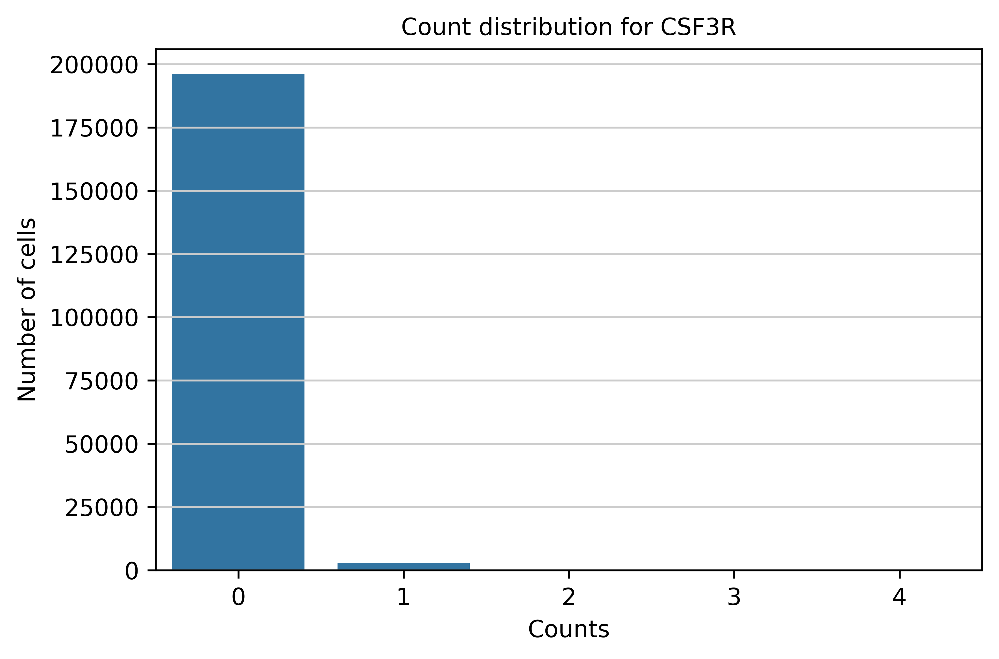

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


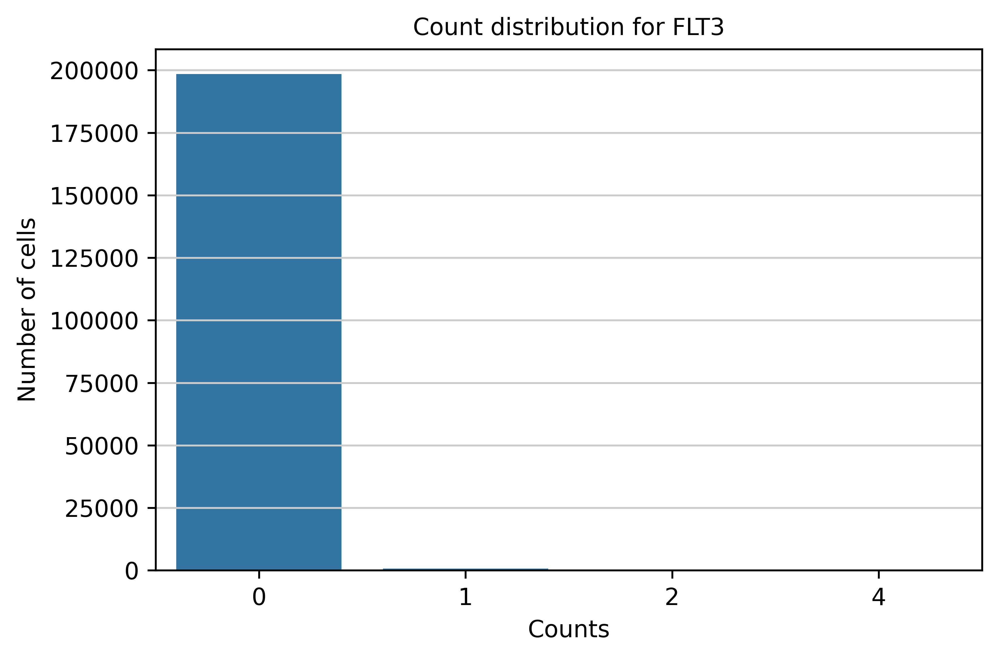

In [184]:
# Retrieve cell counts
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


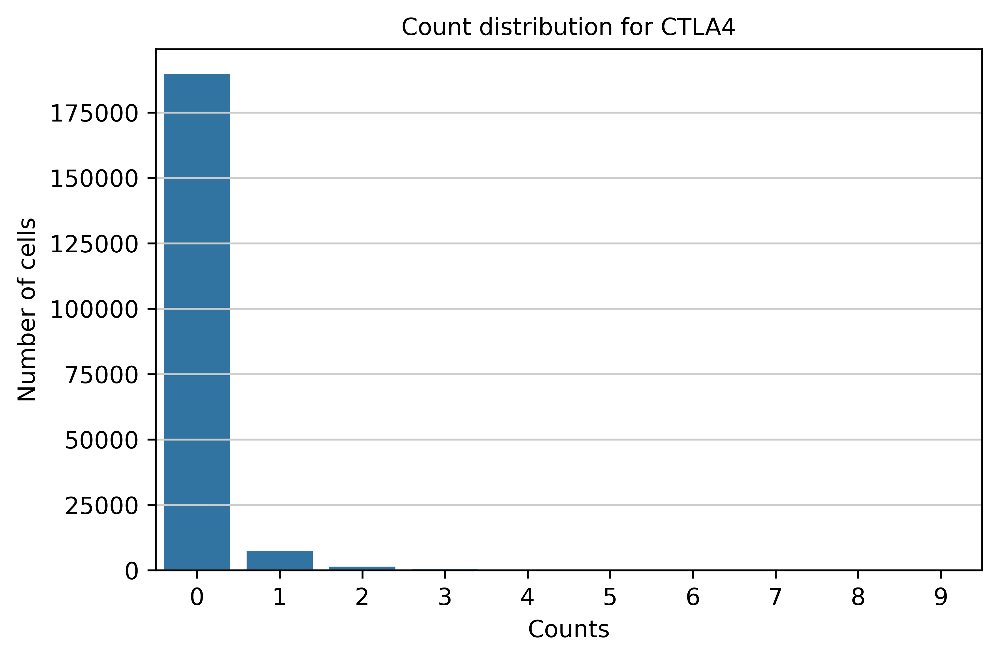

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


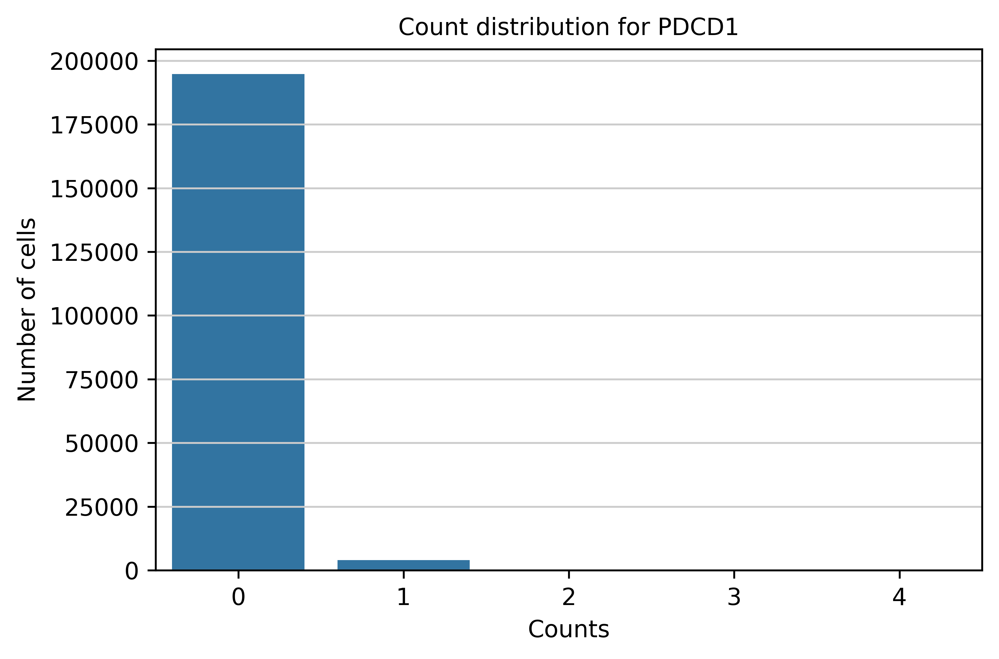

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


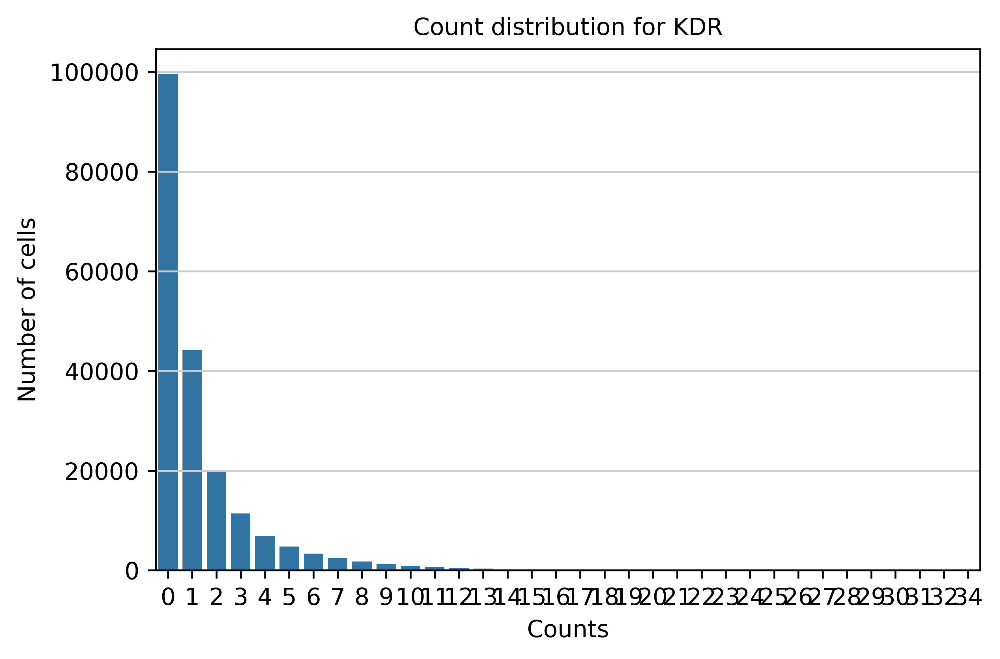

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


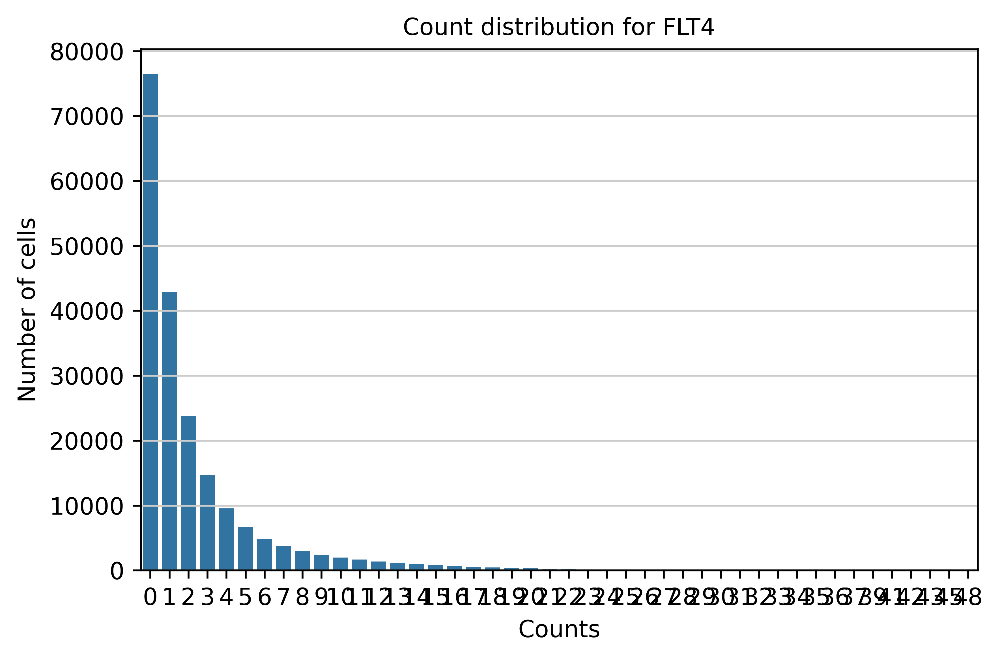

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


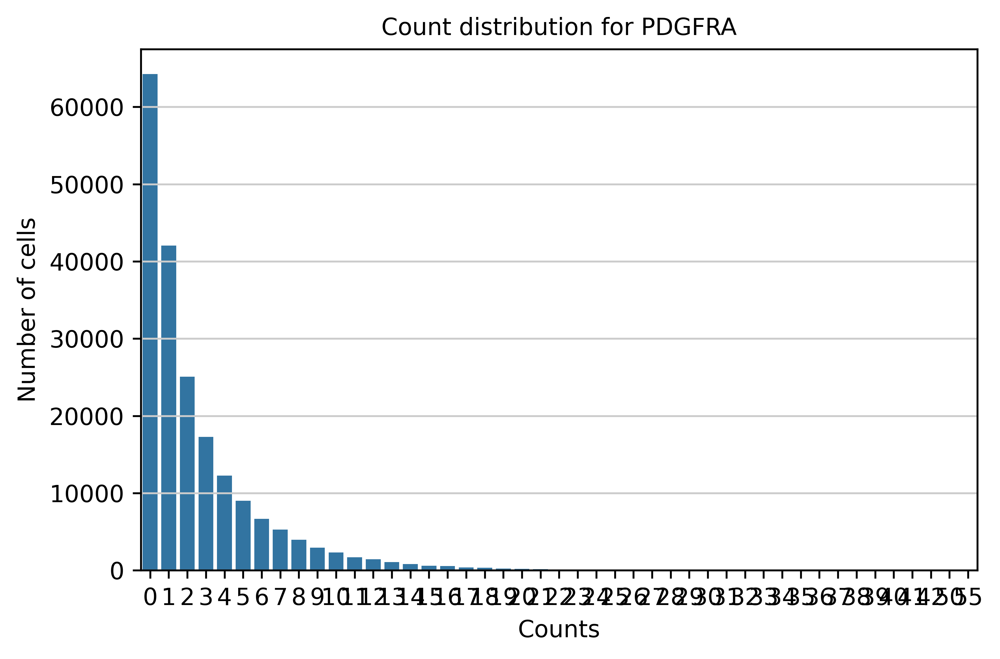

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


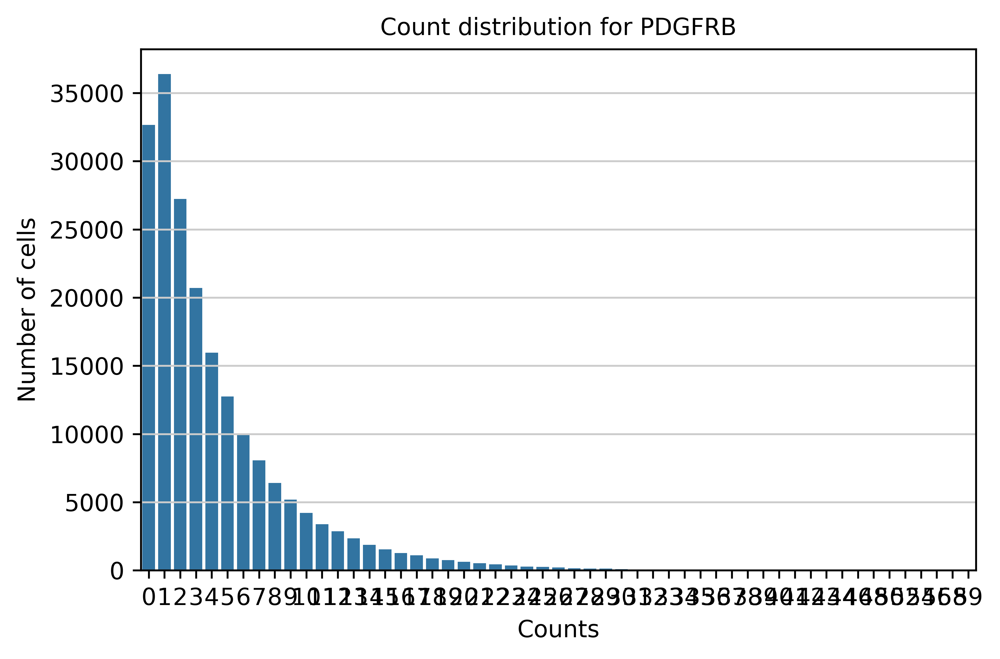

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


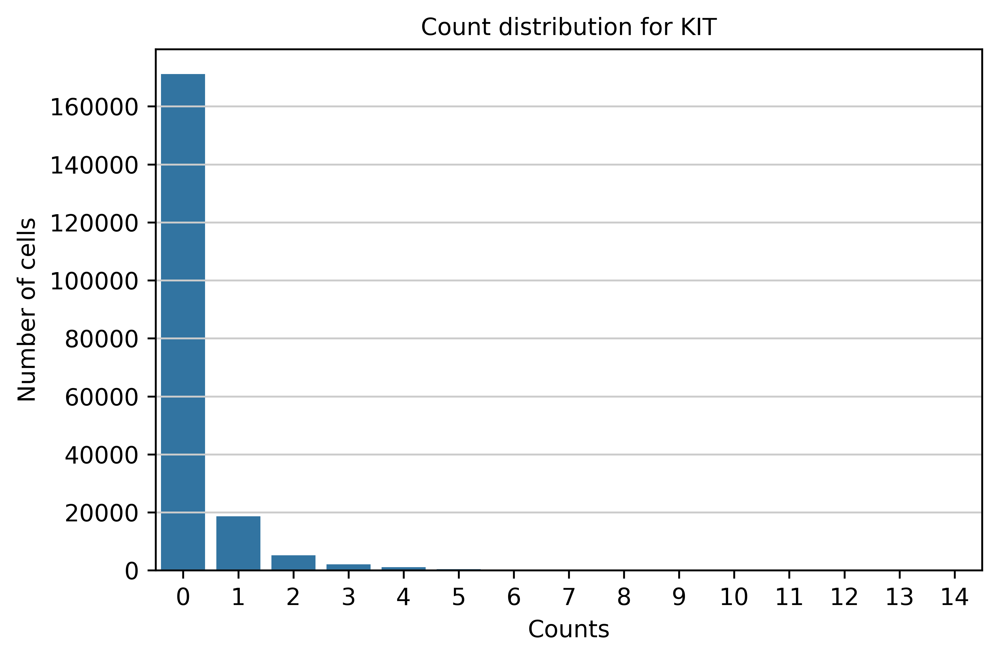

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


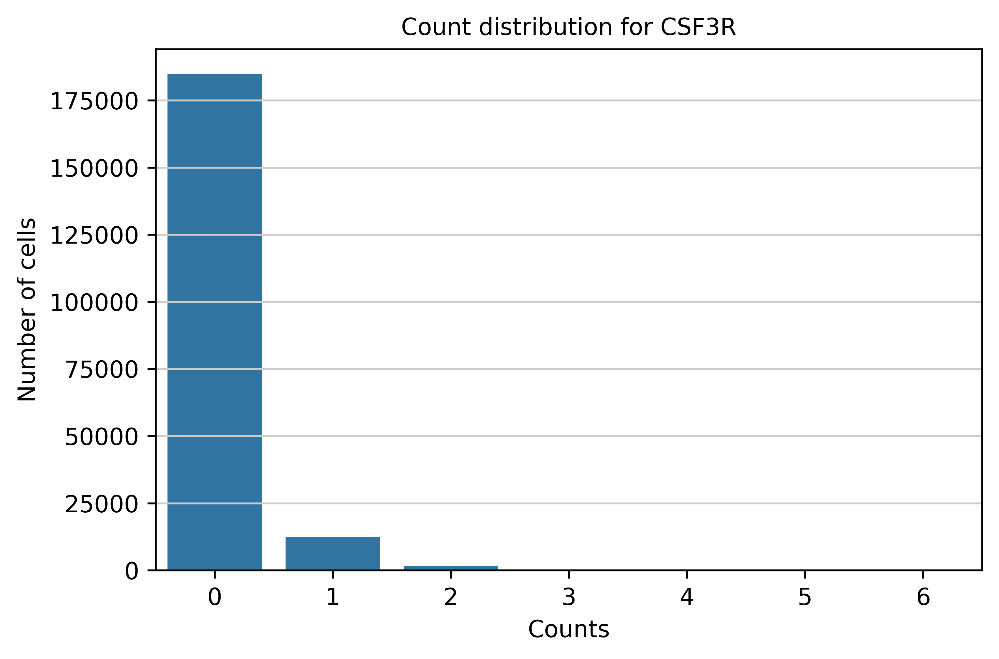

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


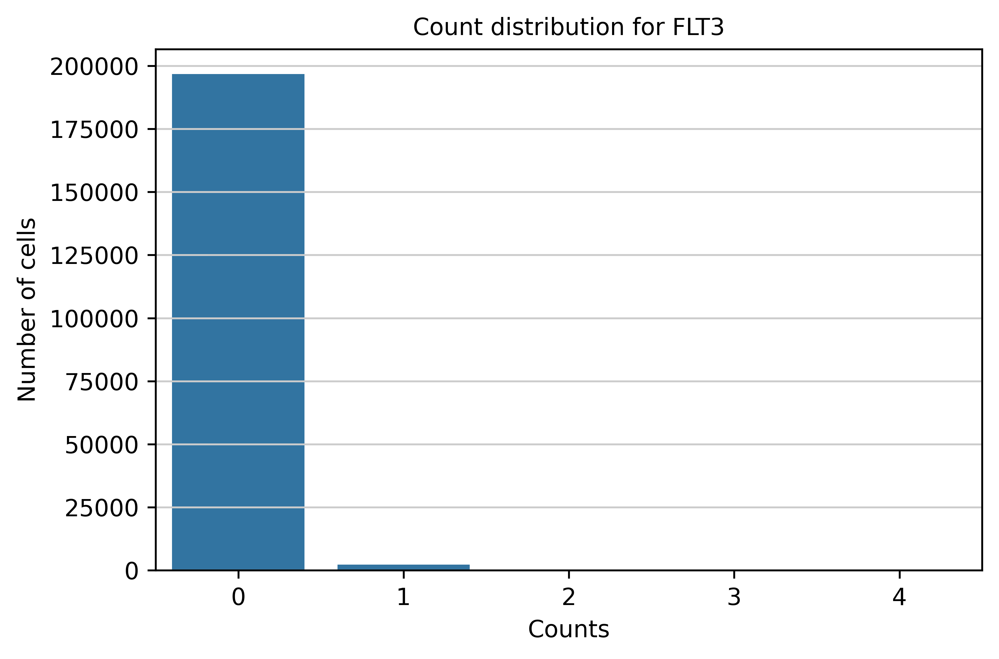

In [185]:
# Retrieve cell neighborhood counts
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].layers['counts_neighborhood']
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

#### 2.5.2.3 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999784  min=0.955204


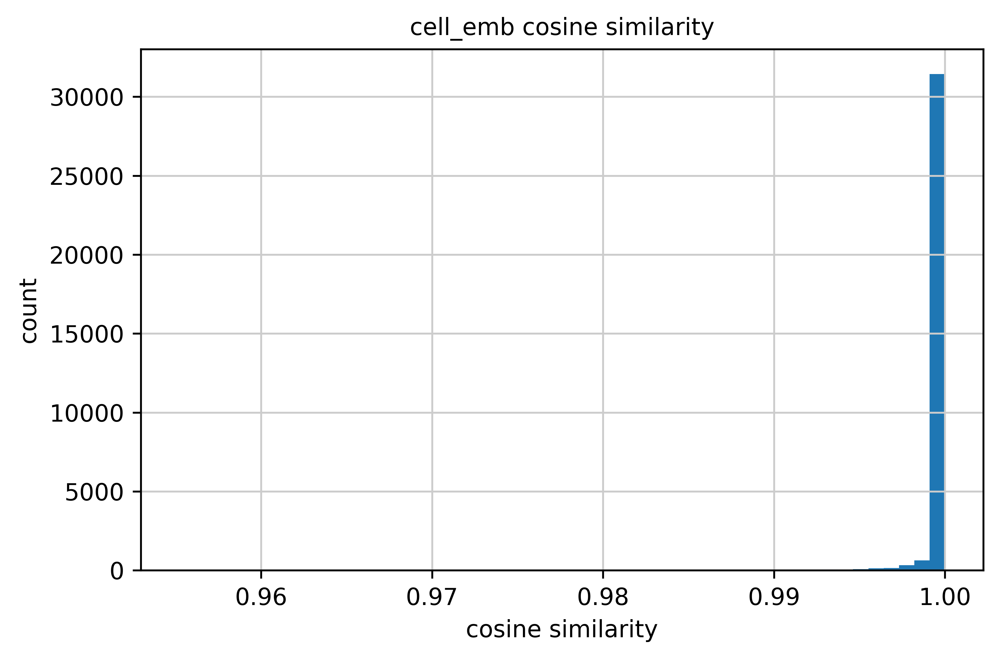

spatial_cell_emb: mean=0.999969  min=0.977921


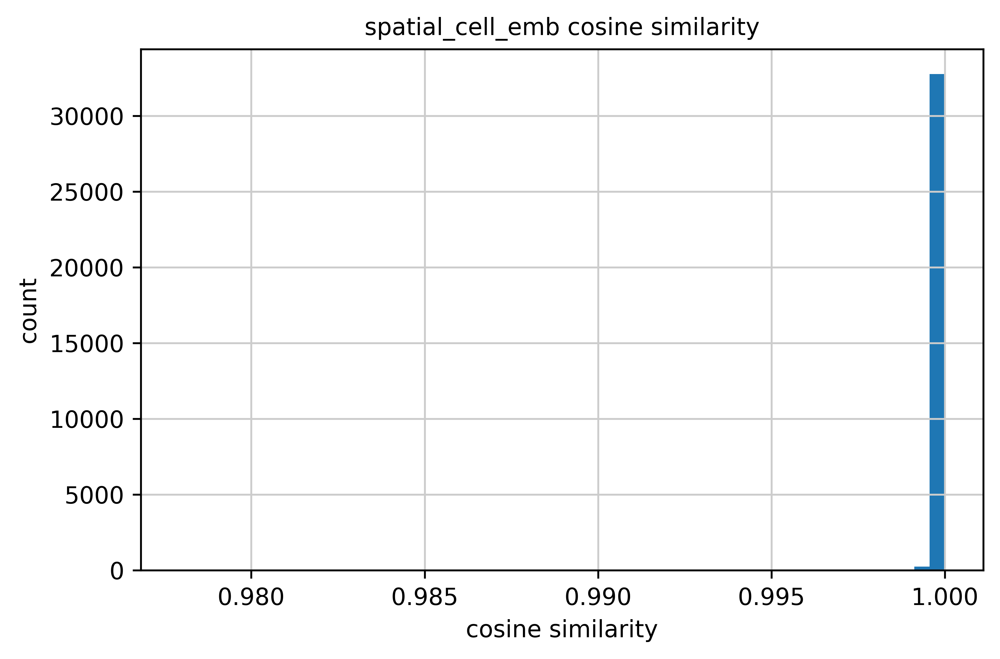

neighborhood_emb: mean=0.999980  min=0.980379


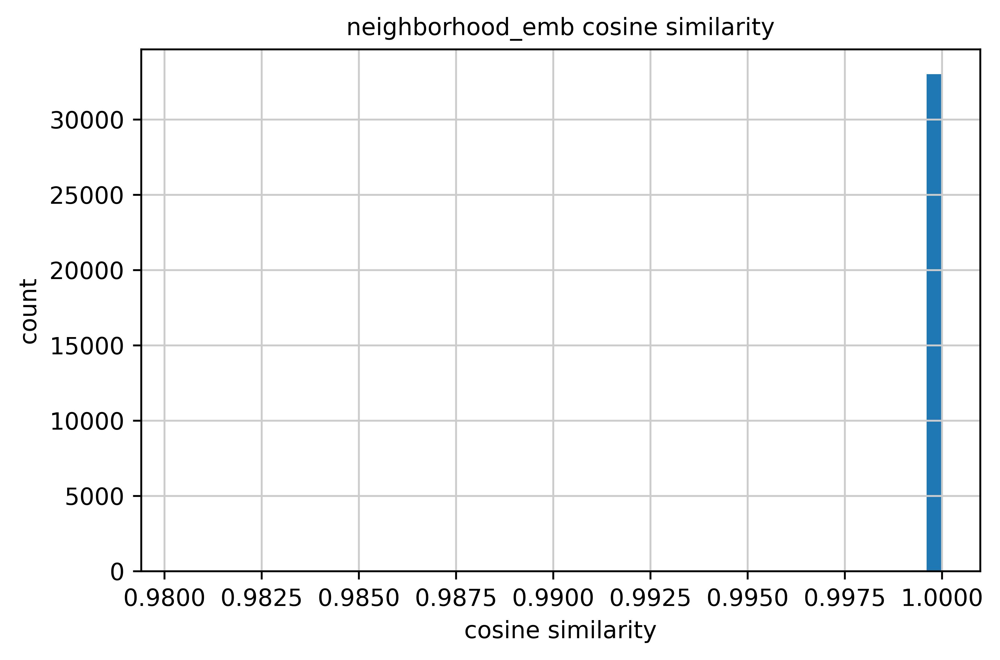

In [169]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [170]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Natural killer cell,10,0.998529,0.999948,0.999975
1,CD14+ monocyte,13,0.998851,0.999902,0.999956
2,Neuron,81,0.999183,0.999942,0.999979
3,Conventional dendritic cell,468,0.999246,0.999942,0.999962
4,CD4+ T cell,1526,0.999342,0.999932,0.999969
5,Memory B cell,304,0.999375,0.999929,0.999966
6,Ascending thin limb,35,0.999545,0.999983,0.999994
7,Macrophage,3553,0.999548,0.999962,0.999980
8,CD8+ T cell,1908,0.999625,0.999944,0.999967
9,Descending thin limb,304,0.999654,0.999960,0.999980


In [171]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Fibrovascular neighborhood,7519,0.999693,0.999952,0.999968
1,Loop of Henle neighborhood,2651,0.999711,0.999978,0.999992
2,Injured proximal nephron neighborhood,6411,0.999755,0.999961,0.999972
3,Proximal nephron neighborhood,8391,0.999816,0.999965,0.999977
4,Glomerular neighborhood,1906,0.999858,0.999990,0.999995
5,Distal nephron neighborhood,6215,0.999890,0.999991,0.999995


In [172]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.9997841
Spatial cell embedding average: 0.9999688
Neighborhood embedding average: 0.99997956
Lowest cell embedding average per cell type: 0.9985294342041016
Lowest spatial cell embedding average per cell type: 0.9999016523361206
Lowest neighborhood embedding average per cell type: 0.9999416470527649
Lowest cell embedding average per niche: 0.9996925592422485
Lowest spatial cell embedding average per niche: 0.9999520182609558
Lowest neighborhood embedding average per niche: 0.9999675154685974


### 2.5.3 Perturbation Case 3 (Original 3)

Knockout Perturbation:
- Cell & Neighborhood
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [186]:
pert_case = 3 
pert_genes = [
    'KDR',
    'FLT4',
    'PDGFRA',
    'PDGFRB',
    'KIT',
    'CSF3R',
    'FLT3']

In [187]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

          ensembl_id  highly_variable  highly_variable_rank     means  \
KDR  ENSG00000128052             True                 225.0  0.042929   

     variances  variances_norm  
KDR   0.070335        1.363115  
           ensembl_id  highly_variable  highly_variable_rank     means  \
FLT4  ENSG00000037280             True                 129.0  0.071771   

      variances  variances_norm  
FLT4   0.152284        1.610407  
             ensembl_id  highly_variable  highly_variable_rank     means  \
PDGFRA  ENSG00000134853             True                 188.0  0.107361   

        variances  variances_norm  
PDGFRA   0.226664        1.465978  
             ensembl_id  highly_variable  highly_variable_rank     means  \
PDGFRB  ENSG00000113721             True                 348.0  0.157412   

        variances  variances_norm  
PDGFRB   0.314816        1.230433  
          ensembl_id  highly_variable  highly_variable_rank     means  \
KIT  ENSG00000157404             True          

In [188]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.3.1 Cell Perturbations

In [189]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [190]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

196634


In [191]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.997342  min=0.875217


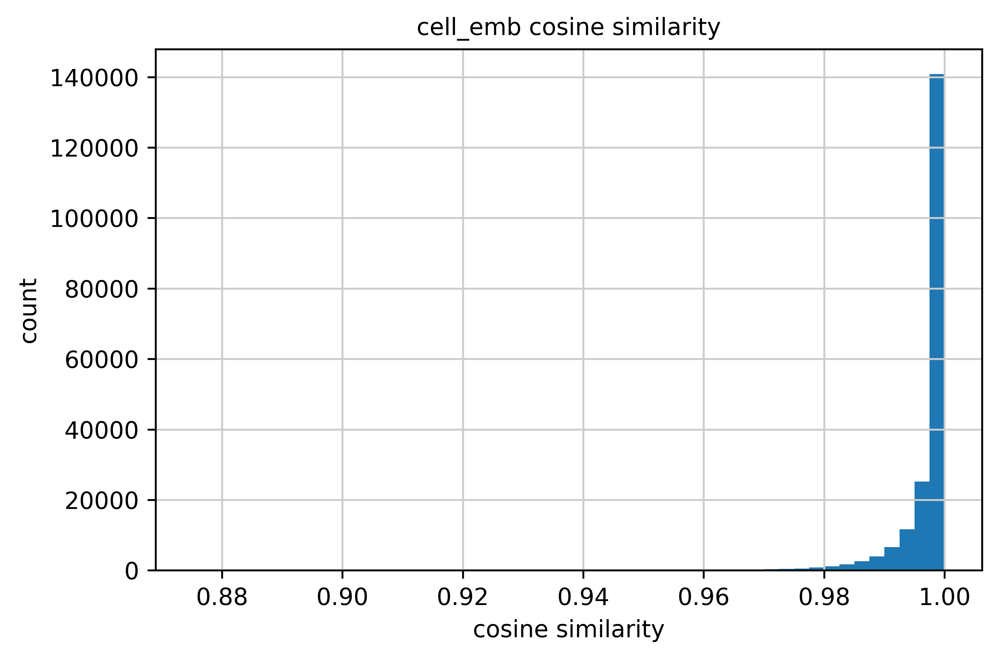

spatial_cell_emb: mean=0.999467  min=0.981702


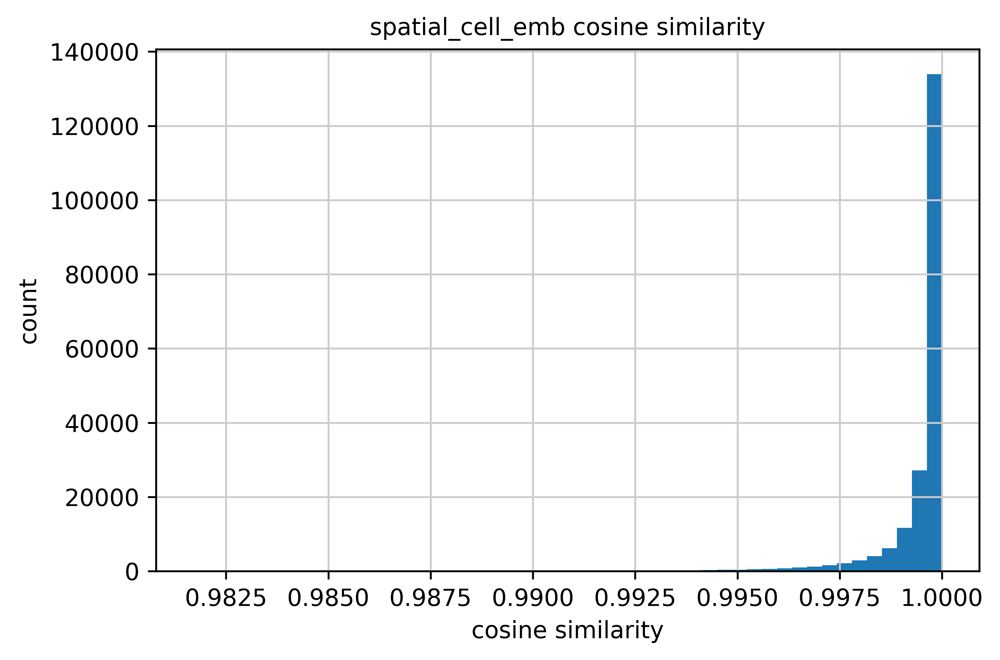

neighborhood_emb: mean=0.999600  min=0.981631


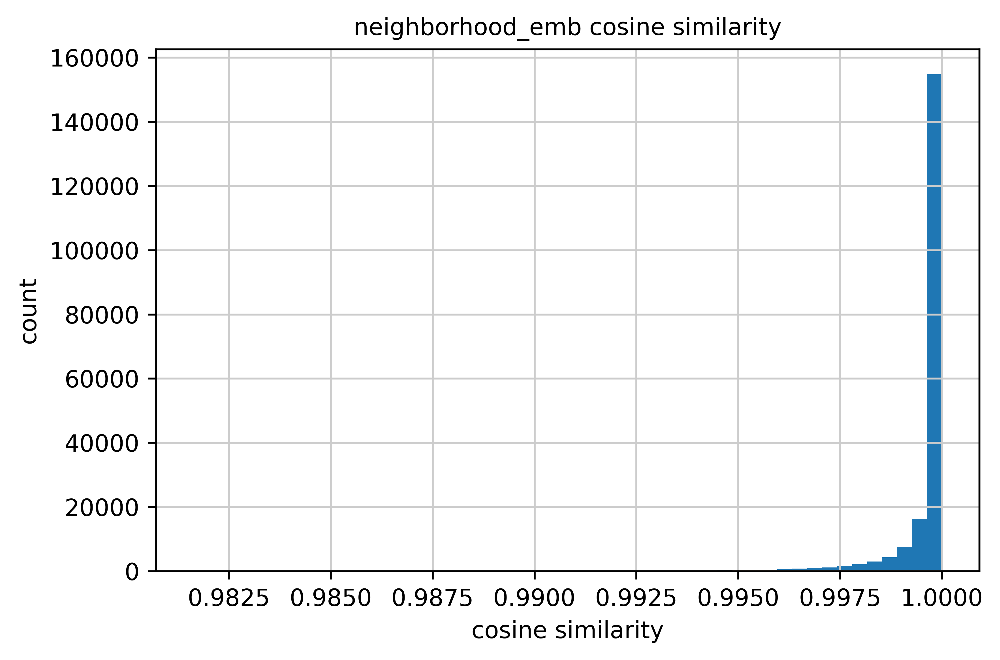

In [192]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [193]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Memory B cell,131,0.989400,0.998680,0.999456
1,CD4+ T cell,609,0.991297,0.998802,0.999269
2,Neuron,412,0.991902,0.999027,0.999536
3,Descending thin limb,476,0.993644,0.999300,0.999583
4,CD16+ monocyte,10,0.994352,0.999665,0.999849
5,CD8+ T cell,1376,0.994627,0.999175,0.999315
6,Vascular mural cell,28561,0.995116,0.999397,0.999638
7,Conventional dendritic cell,554,0.995562,0.999224,0.999355
8,Proximal tubule segment 2,581,0.995562,0.999648,0.999854
9,Fibroblast,656,0.995606,0.999187,0.999291


In [194]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Proximal nephron neighborhood,47007,0.996447,0.999586,0.999797
1,Loop of Henle neighborhood,15658,0.996936,0.999513,0.999658
2,Fibrovascular neighborhood,39050,0.997044,0.999313,0.999476
3,Injured proximal nephron neighborhood,5750,0.997327,0.999283,0.999416
4,Glomerular neighborhood,54259,0.997972,0.999785,0.999869
5,Distal nephron neighborhood,34910,0.998085,0.998998,0.999058


In [195]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99734217
Spatial cell embedding average: 0.99946743
Neighborhood embedding average: 0.99959975
Lowest cell embedding average per cell type: 0.9893999099731445
Lowest spatial cell embedding average per cell type: 0.9986795783042908
Lowest neighborhood embedding average per cell type: 0.9987947940826416
Lowest cell embedding average per niche: 0.9964470863342285
Lowest spatial cell embedding average per niche: 0.9989975094795227
Lowest neighborhood embedding average per niche: 0.9990578293800354


#### 2.5.3.2 Neighborhood Perturbations

In [196]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [197]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

737081


In [198]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999291  min=0.875217


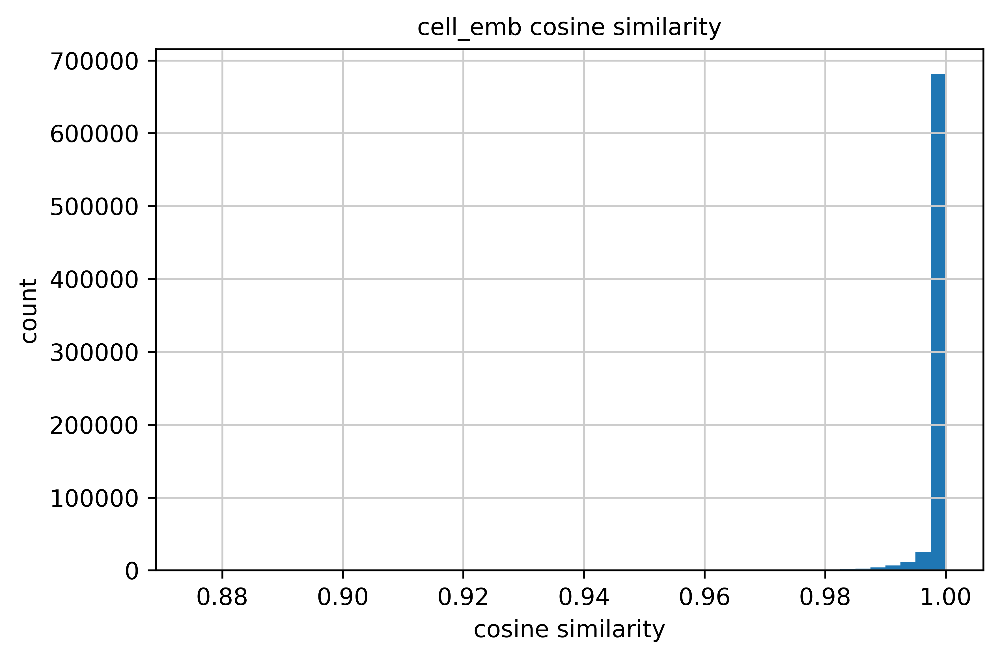

spatial_cell_emb: mean=0.999635  min=0.978212


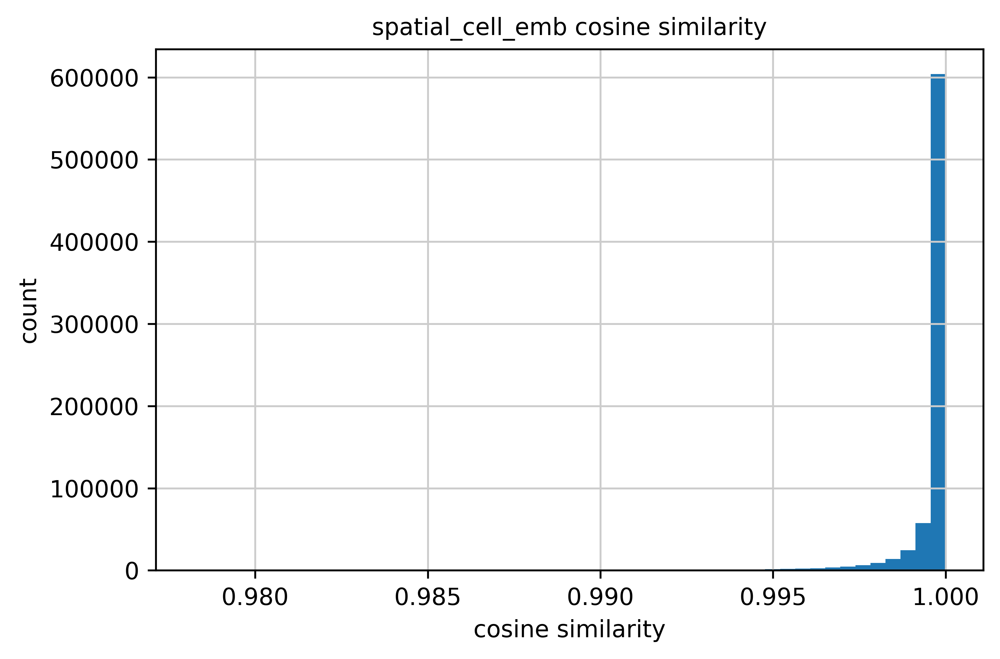

neighborhood_emb: mean=0.999691  min=0.980377


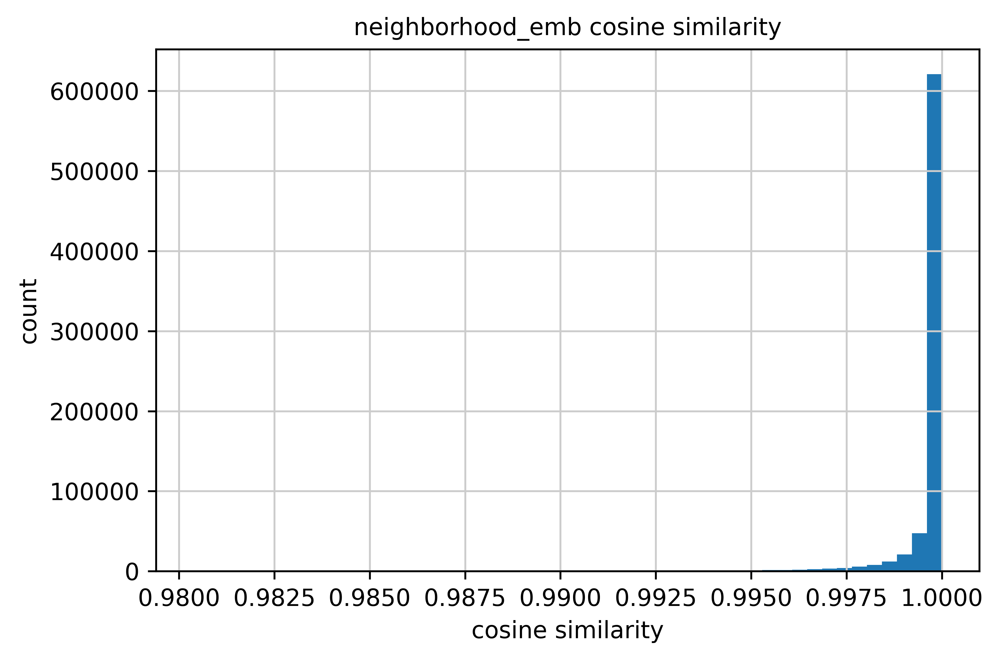

In [199]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [200]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Fibroblast,811,0.996445,0.999300,0.999386
1,Vascular mural cell,57058,0.997555,0.999595,0.999719
2,Mesangial cell,13331,0.997639,0.999794,0.999846
3,Lymphatic endothelium,675,0.997659,0.999448,0.999596
4,Myofibroblast,64902,0.998010,0.999376,0.999441
5,Neuron,2111,0.998420,0.999514,0.999640
6,Natural killer cell,229,0.998755,0.999548,0.999581
7,Neutrophil,1510,0.998788,0.999531,0.999579
8,Basophil / Mast cell,55,0.998851,0.998857,0.998895
9,Macrophage,32073,0.998916,0.999482,0.999518


In [201]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Glomerular neighborhood,103106,0.998933,0.999826,0.999867
1,Injured proximal nephron neighborhood,17936,0.999143,0.999483,0.999550
2,Fibrovascular neighborhood,138124,0.999164,0.999488,0.999564
3,Proximal nephron neighborhood,264691,0.999369,0.999798,0.999854
4,Loop of Henle neighborhood,85698,0.999440,0.999739,0.999783
5,Distal nephron neighborhood,127526,0.999476,0.999248,0.999306


In [202]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99929094
Spatial cell embedding average: 0.9996346
Neighborhood embedding average: 0.99969137
Lowest cell embedding average per cell type: 0.9964454174041748
Lowest spatial cell embedding average per cell type: 0.9988565444946289
Lowest neighborhood embedding average per cell type: 0.9988947510719299
Lowest cell embedding average per niche: 0.9989330768585205
Lowest spatial cell embedding average per niche: 0.9992484450340271
Lowest neighborhood embedding average per niche: 0.999305784702301


### 2.5.4 Perturbation Case 4 (Top DEG Untreated <-> Treated)

Knockout Perturbation:
- Top 10 differentially expressed genes with enough counts
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [213]:
pert_case = 4
pert_genes = [
    'MYH9',
    'CXCR4',
    'NR4A1',
    'THBS1',
    'PLEC',
    'EEF1G',
    'TUBB',
    'SEPTIN9',
    'SMAP2',
    'YWHAZ']

In [214]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

           ensembl_id  highly_variable  highly_variable_rank     means  \
MYH9  ENSG00000100345            False                   NaN  0.819873   

      variances  variances_norm  
MYH9   2.583143        0.694623  
            ensembl_id  highly_variable  highly_variable_rank     means  \
CXCR4  ENSG00000121966             True                  70.0  0.252166   

       variances  variances_norm  
CXCR4   0.968808        1.917838  
            ensembl_id  highly_variable  highly_variable_rank     means  \
NR4A1  ENSG00000123358             True                 192.0  0.953956   

       variances  variances_norm  
NR4A1   7.219805        1.456233  
            ensembl_id  highly_variable  highly_variable_rank     means  \
THBS1  ENSG00000137801             True                  91.0  0.326305   

       variances  variances_norm  
THBS1   1.332106        1.767337  
           ensembl_id  highly_variable  highly_variable_rank     means  \
PLEC  ENSG00000178209            False        

In [215]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.4.1 Cell Perturbations

In [216]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [217]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

837586


In [218]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [219]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

KeyError: 'cell_emb_perturb_case4'

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

#### 2.5.4.2 Neighborhood Perturbations

In [209]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

Filter: 100%|████████████████████████████████████████| 1079667/1079667 [00:49<00:00, 21638.55 examples/s]


In [210]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

1079667


In [211]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [212]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

KeyError: 'cell_emb_perturb_case4'

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

### 2.5.5 Perturbation Case 5 (Housekeeping)

Knockout Perturbation:
- 10 housekeeping genes
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [222]:
pert_case = 5
pert_genes = [
    "HPRT1",
    "PGK1",
    "TBP",
    "NONO",
    "UBE2I",
    "YWHAZ",
    "SOD1",
    "GUSB",
    "RAN",
    "ATP5F1A",
]

In [223]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

            ensembl_id  highly_variable  highly_variable_rank     means  \
HPRT1  ENSG00000165704            False                   NaN  0.007568   

       variances  variances_norm  
HPRT1   0.007922        0.957873  
           ensembl_id  highly_variable  highly_variable_rank    means  \
PGK1  ENSG00000102144            False                   NaN  0.18462   

      variances  variances_norm  
PGK1   0.249603        0.780754  
          ensembl_id  highly_variable  highly_variable_rank     means  \
TBP  ENSG00000112592            False                   NaN  0.012415   

     variances  variances_norm  
TBP   0.012739        0.937518  
           ensembl_id  highly_variable  highly_variable_rank     means  \
NONO  ENSG00000147140            False                   NaN  0.179486   

      variances  variances_norm  
NONO   0.251883        0.820001  
            ensembl_id  highly_variable  highly_variable_rank     means  \
UBE2I  ENSG00000103275            False                   N

In [224]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.5.1 Cell Perturbations

In [225]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [226]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

659864


In [227]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.999471  min=0.966756


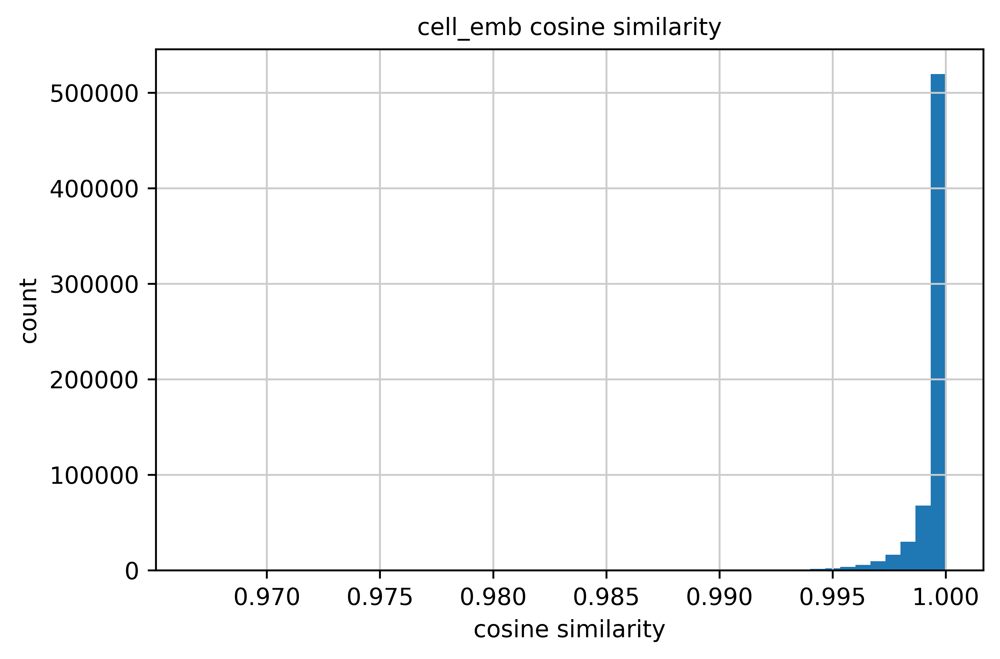

spatial_cell_emb: mean=0.999667  min=0.992534


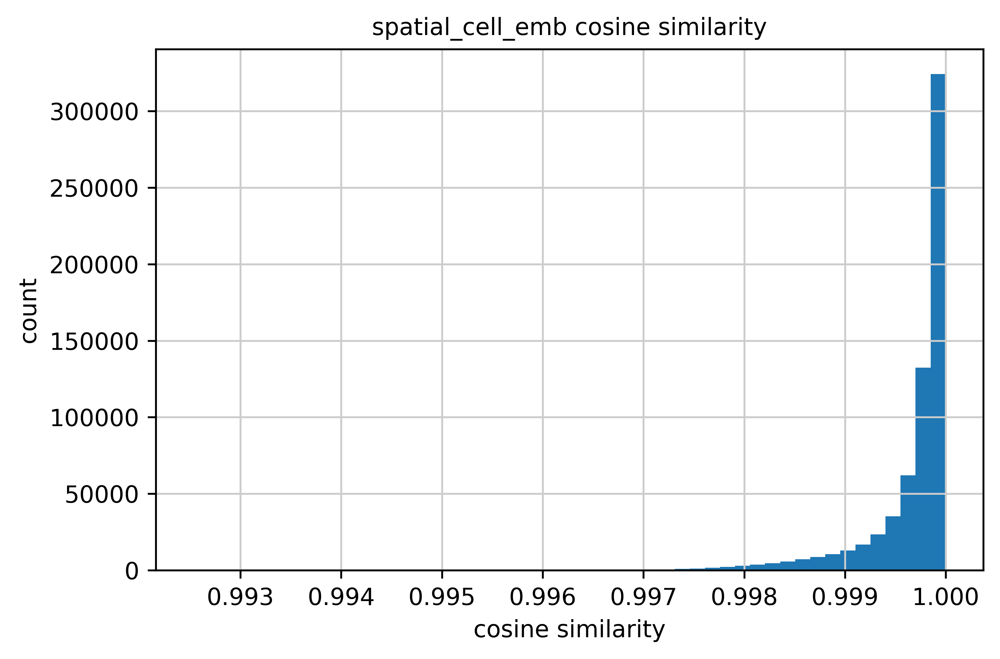

neighborhood_emb: mean=0.999739  min=0.994024


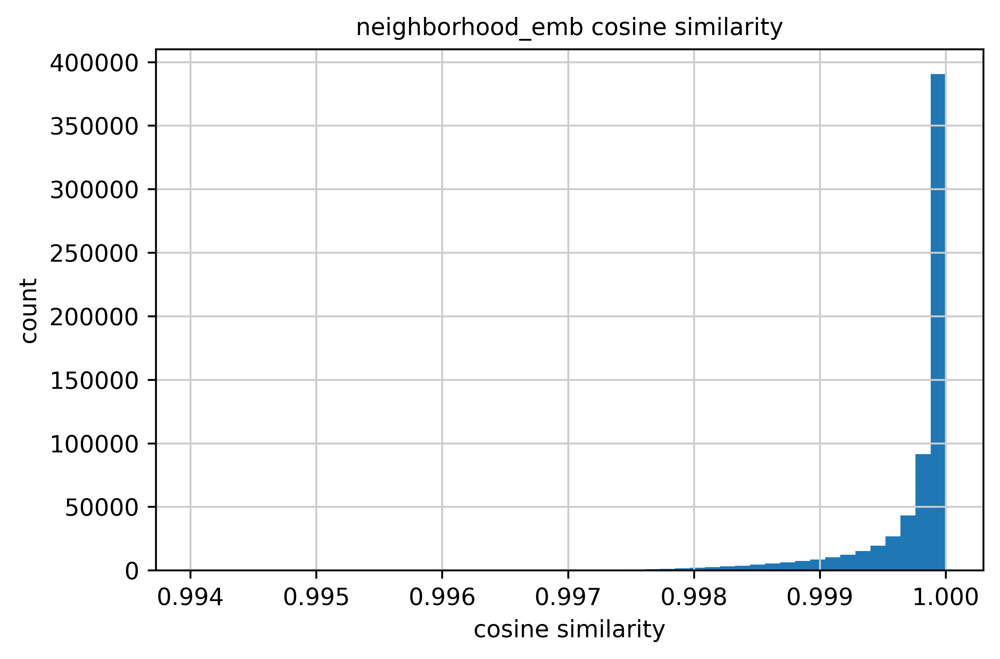

In [228]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [229]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,CD4+ T cell,5169,0.998202,0.999499,0.999869
1,Memory B cell,1067,0.998382,0.999571,0.999892
2,Neuron,1104,0.998849,0.999656,0.999883
3,Proximal tubule segment 2,17399,0.999058,0.999689,0.999844
4,CD16+ monocyte,53,0.999066,0.999546,0.999707
5,Descending thin limb,7360,0.999132,0.999732,0.999870
6,Distal convoluted tubule 1,23403,0.999260,0.999550,0.999622
7,CDH13+ stromal cell,8414,0.999285,0.999670,0.999779
8,Intercalated cell type A,38573,0.999302,0.999660,0.999717
9,Injured proximal tubule,42233,0.999336,0.999461,0.999521


In [230]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Proximal nephron neighborhood,282500,0.999332,0.999543,0.999643
1,Fibrovascular neighborhood,91104,0.999521,0.999686,0.999762
2,Loop of Henle neighborhood,87236,0.999525,0.999804,0.999862
3,Distal nephron neighborhood,123313,0.999584,0.999688,0.999720
4,Injured proximal nephron neighborhood,11822,0.999670,0.999869,0.999930
5,Glomerular neighborhood,63889,0.999685,0.999930,0.999967


In [231]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.999471
Spatial cell embedding average: 0.99966747
Neighborhood embedding average: 0.99973917
Lowest cell embedding average per cell type: 0.998202383518219
Lowest spatial cell embedding average per cell type: 0.9994611144065857
Lowest neighborhood embedding average per cell type: 0.9995210766792297
Lowest cell embedding average per niche: 0.999332070350647
Lowest spatial cell embedding average per niche: 0.9995427131652832
Lowest neighborhood embedding average per niche: 0.9996431469917297


#### 2.5.5.2 Neighborhood Perturbations

In [232]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

Filter: 100%|█████████████████████████████████████████| 1071987/1071987 [04:52<00:00, 3667.88 examples/s]


In [233]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

1071987


In [234]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999674  min=0.966756


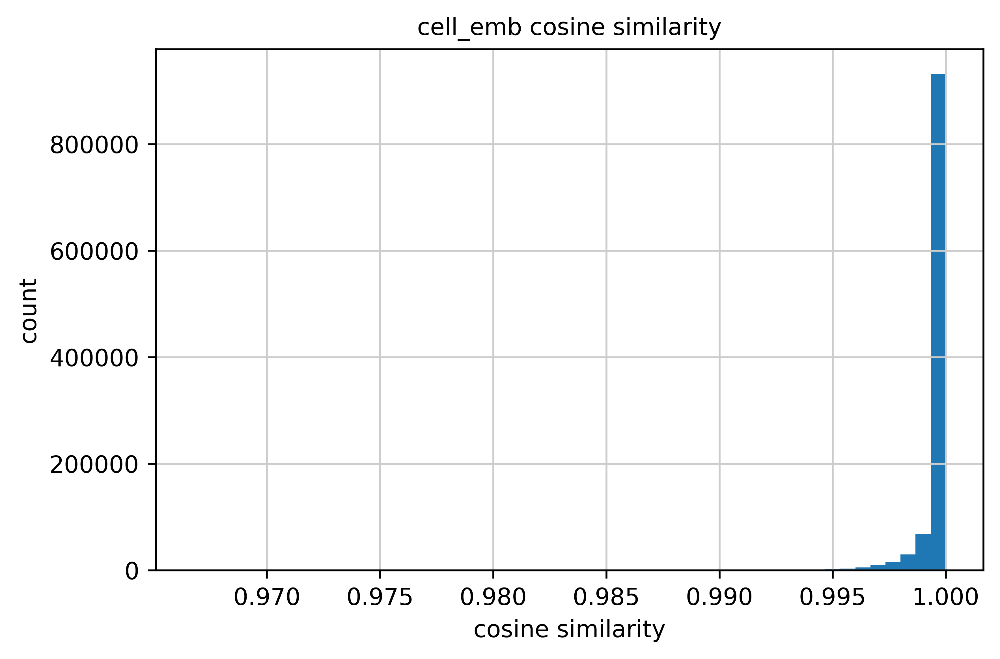

spatial_cell_emb: mean=0.999758  min=0.992534


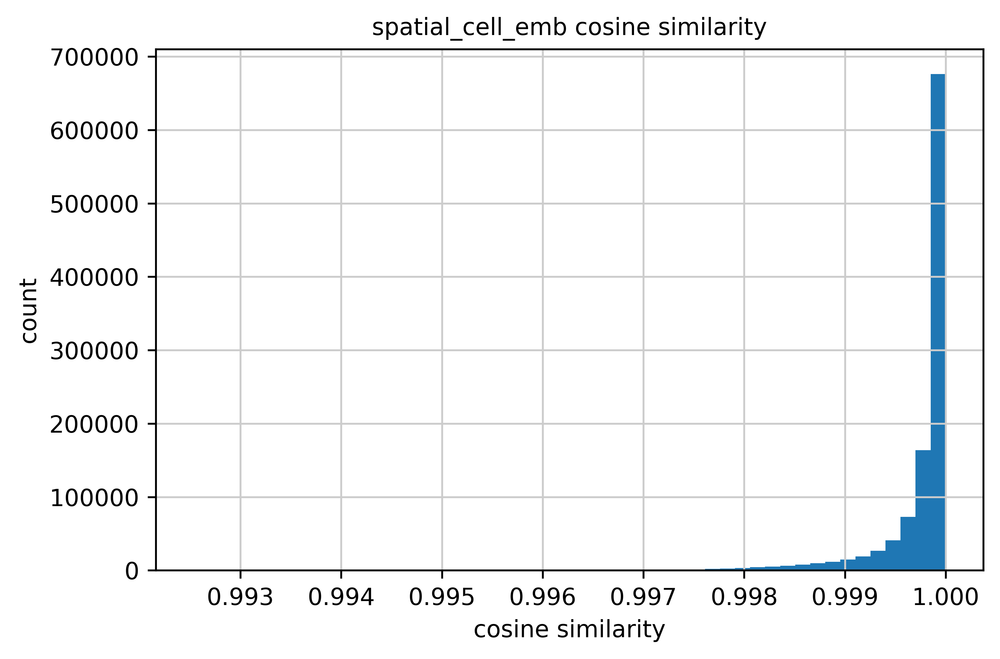

neighborhood_emb: mean=0.999800  min=0.994024


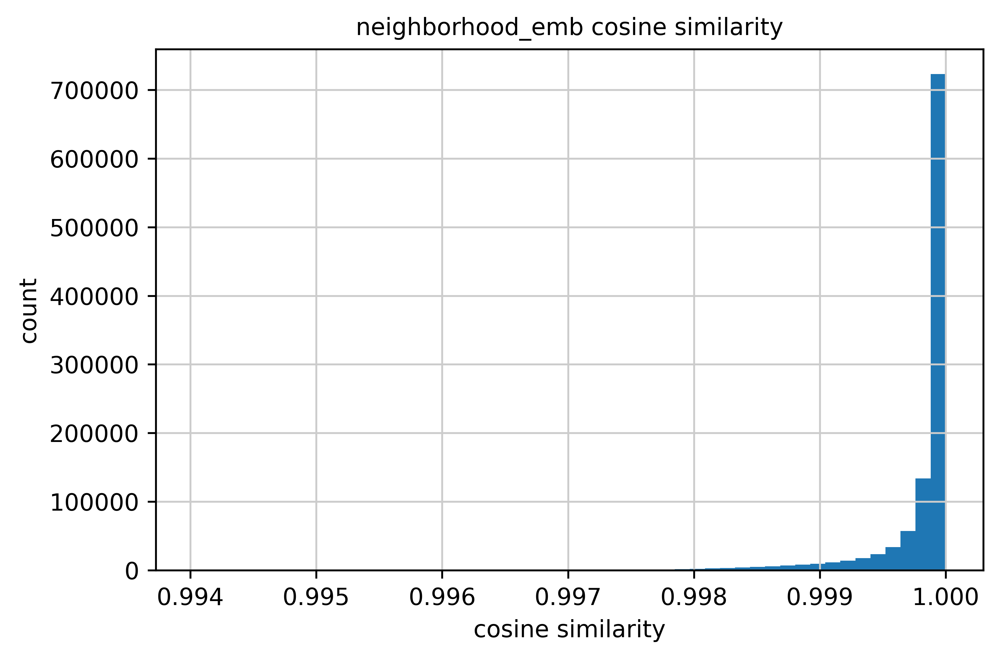

In [235]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [236]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Distal convoluted tubule 1,33992,0.999491,0.999653,0.999699
1,CD4+ T cell,18319,0.999493,0.999807,0.999905
2,Intercalated cell type A,53487,0.999497,0.999730,0.999769
3,Injured proximal tubule,56784,0.999506,0.999573,0.999617
4,Memory B cell,3692,0.999532,0.999825,0.999912
5,CD16+ monocyte,114,0.999566,0.999744,0.999818
6,Proximal tubule segment 2,39486,0.999585,0.999822,0.999887
7,Intercalated cell type B,5401,0.999603,0.999758,0.999781
8,Proximal tubule segment 3,143525,0.999606,0.999647,0.999687
9,Descending thin limb,17174,0.999628,0.999843,0.999897


In [237]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Proximal nephron neighborhood,488950,0.999614,0.999690,0.999747
1,Distal nephron neighborhood,155310,0.999669,0.999719,0.999743
2,Loop of Henle neighborhood,141841,0.999708,0.999845,0.999877
3,Fibrovascular neighborhood,159729,0.999726,0.999784,0.999824
4,Glomerular neighborhood,105062,0.999808,0.999949,0.999969
5,Injured proximal nephron neighborhood,21095,0.999815,0.999910,0.999940


In [238]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99967444
Spatial cell embedding average: 0.9997584
Neighborhood embedding average: 0.99980015
Lowest cell embedding average per cell type: 0.9994906783103943
Lowest spatial cell embedding average per cell type: 0.9995729923248291
Lowest neighborhood embedding average per cell type: 0.9996165633201599
Lowest cell embedding average per niche: 0.9996140599250793
Lowest spatial cell embedding average per niche: 0.9996901750564575
Lowest neighborhood embedding average per niche: 0.9997426271438599


### 2.5.6 Perturbation Case 6 (VEGFR2 Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - KDR (ENSG00000128052)
    - VEGFA (ENSG00000112715)
    - VEGFB (ENSG00000173511)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [249]:
pert_case = 6
pert_genes = [
    'KDR',
    'VEGFA',
    'VEGFB'
]

In [250]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

          ensembl_id  highly_variable  highly_variable_rank     means  \
KDR  ENSG00000128052             True                 225.0  0.042929   

     variances  variances_norm  
KDR   0.070335        1.363115  
            ensembl_id  highly_variable  highly_variable_rank     means  \
VEGFA  ENSG00000112715             True                 372.0  0.087134   

       variances  variances_norm  
VEGFA   0.145142        1.210803  
            ensembl_id  highly_variable  highly_variable_rank     means  \
VEGFB  ENSG00000173511            False                   NaN  0.167887   

       variances  variances_norm  
VEGFB    0.25403        0.908226  


In [251]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.6.1 Cell Perturbations

In [252]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [253]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

204082


In [254]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.999354  min=0.881457


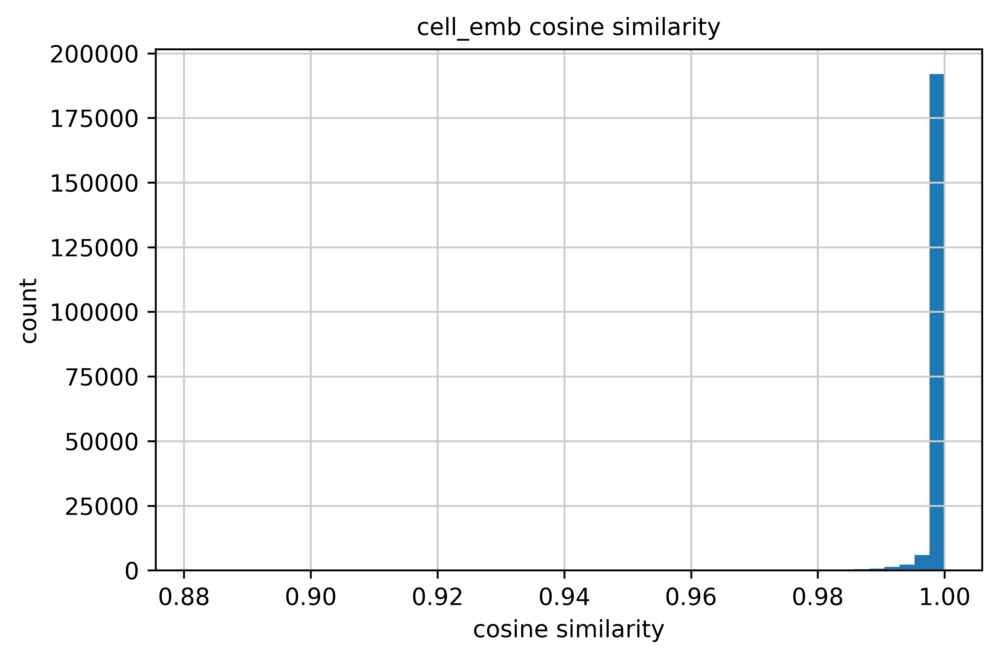

spatial_cell_emb: mean=0.999917  min=0.987092


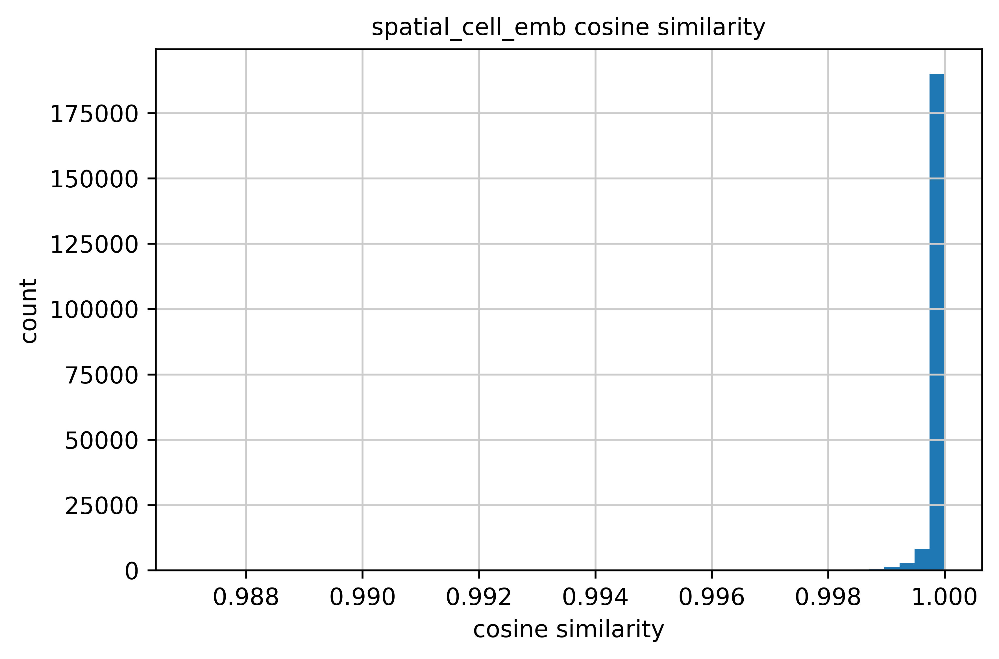

neighborhood_emb: mean=0.999970  min=0.987619


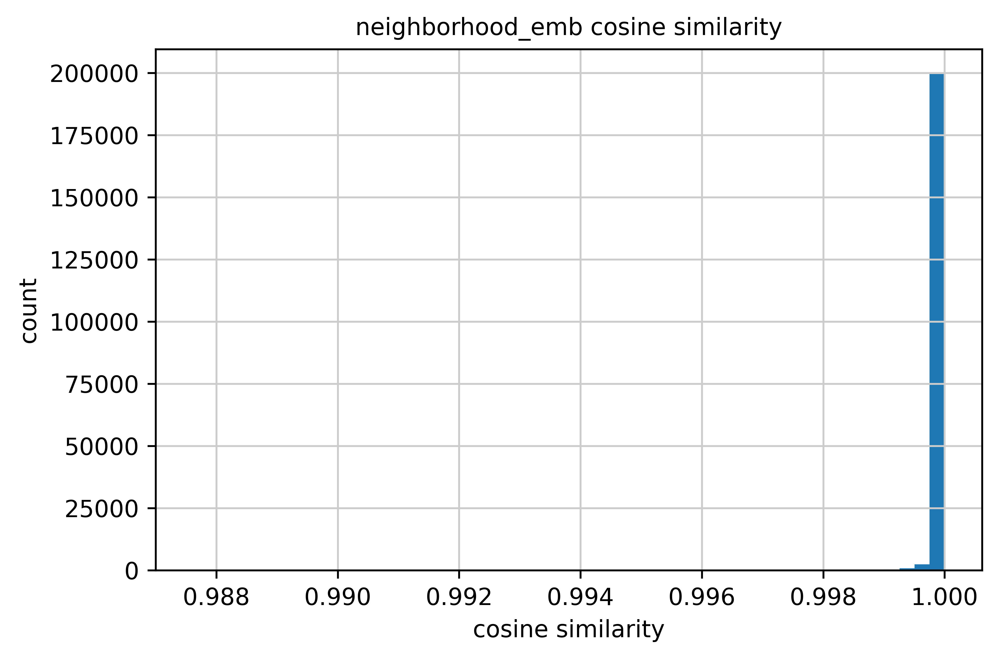

In [255]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [256]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,CD16+ monocyte,8,0.996285,0.999845,0.999973
1,CD4+ T cell,678,0.996383,0.999663,0.999959
2,Memory B cell,143,0.996764,0.999676,0.999975
3,Neuron,205,0.996790,0.999634,0.999940
4,Descending thin limb,1339,0.998381,0.999830,0.999965
5,CD14+ monocyte,26,0.998398,0.999882,0.999966
6,Glomerular endothelial cell,13190,0.998602,0.999844,0.999954
7,CD8+ T cell,1018,0.998634,0.999887,0.999971
8,Connecting tubule,10399,0.998691,0.999803,0.999909
9,Proximal tubule segment 2,1865,0.998699,0.999825,0.999979


In [257]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Proximal nephron neighborhood,69056,0.999211,0.999908,0.999984
1,Glomerular neighborhood,37200,0.999242,0.999897,0.999942
2,Injured proximal nephron neighborhood,3319,0.999295,0.999884,0.999941
3,Fibrovascular neighborhood,26423,0.999387,0.999923,0.999980
4,Loop of Henle neighborhood,21808,0.999421,0.999937,0.999982
5,Distal nephron neighborhood,46276,0.999611,0.999936,0.999961


In [258]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99935395
Spatial cell embedding average: 0.9999169
Neighborhood embedding average: 0.99996966
Lowest cell embedding average per cell type: 0.9962849617004395
Lowest spatial cell embedding average per cell type: 0.999634325504303
Lowest neighborhood embedding average per cell type: 0.9999074935913086
Lowest cell embedding average per niche: 0.99921053647995
Lowest spatial cell embedding average per niche: 0.999883770942688
Lowest neighborhood embedding average per niche: 0.9999406933784485


#### 2.5.6.2 Neighborhood Perturbations

In [259]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [260]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

795618


In [261]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999834  min=0.881457


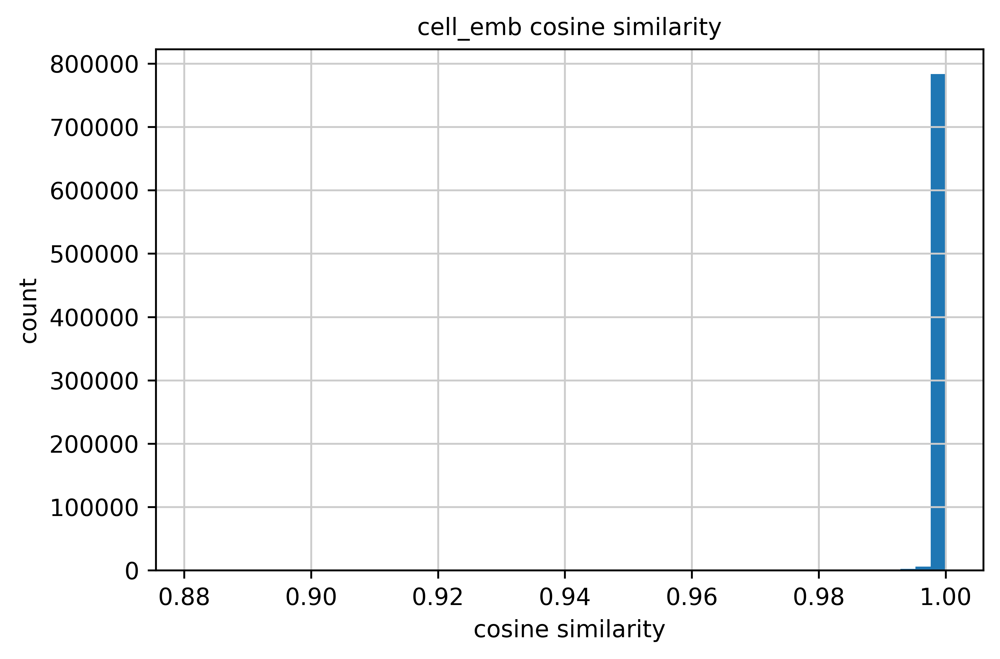

spatial_cell_emb: mean=0.999964  min=0.978809


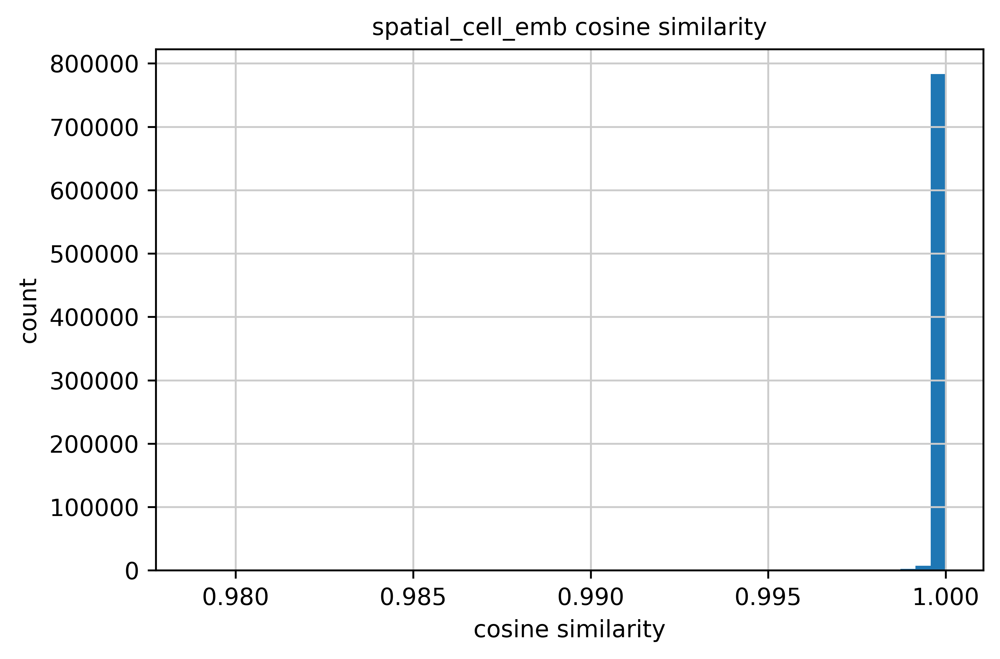

neighborhood_emb: mean=0.999976  min=0.982448


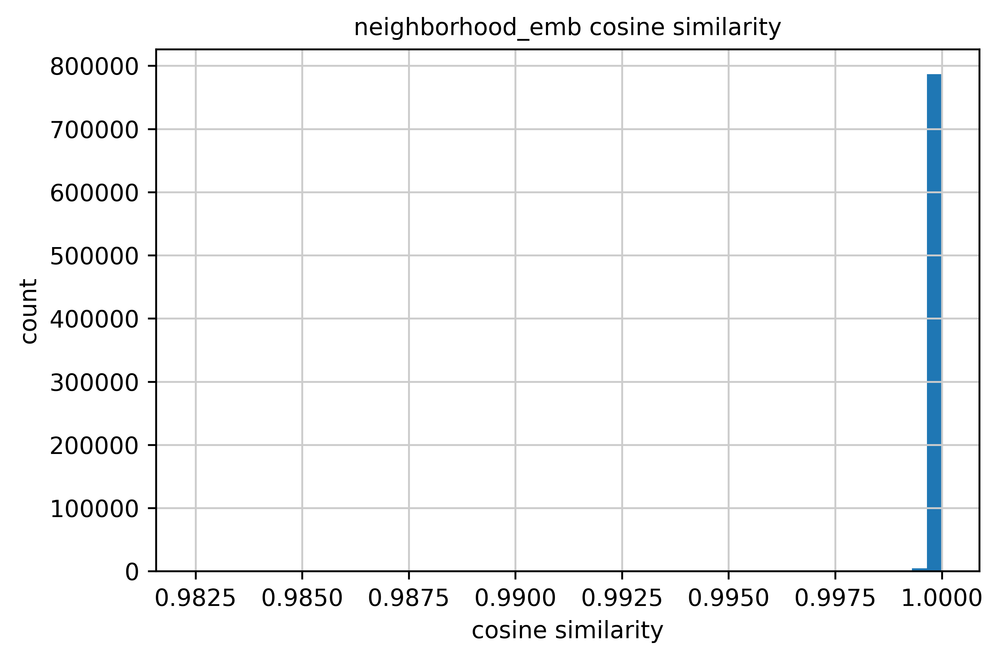

In [262]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [263]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Principal cell,22911,0.999784,0.999928,0.999940
1,Connecting tubule,39604,0.999656,0.999917,0.999944
2,Parietal epithelial cell,5662,0.999821,0.999939,0.999944
3,CD4+ T cell,9910,0.999752,0.999927,0.999945
4,Podocyte,31008,0.999721,0.999934,0.999945
5,Glomerular endothelial cell,39056,0.999528,0.999922,0.999957
6,Mesangial cell,12861,0.999839,0.999954,0.999958
7,Neuron,1901,0.999654,0.999929,0.999960
8,Descending thin limb,11114,0.999805,0.999947,0.999961
9,Memory B cell,1939,0.999761,0.999944,0.999963


In [264]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Injured proximal nephron neighborhood,3319,0.999295,0.999884,0.999941
1,Glomerular neighborhood,37200,0.999242,0.999897,0.999942
2,Distal nephron neighborhood,46276,0.999611,0.999936,0.999961
3,Fibrovascular neighborhood,26423,0.999387,0.999923,0.999980
4,Loop of Henle neighborhood,21808,0.999421,0.999937,0.999982
5,Proximal nephron neighborhood,69056,0.999211,0.999908,0.999984


In [265]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.9998342
Spatial cell embedding average: 0.9999635
Neighborhood embedding average: 0.99997604
Lowest cell embedding average per cell type: 0.9995280504226685
Lowest spatial cell embedding average per cell type: 0.9999165534973145
Lowest neighborhood embedding average per cell type: 0.9999397993087769
Lowest cell embedding average per niche: 0.99921053647995
Lowest spatial cell embedding average per niche: 0.999883770942688
Lowest neighborhood embedding average per niche: 0.9999406933784485


### 2.5.7 Perturbation Case 7 (VEGFR3 Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - FLT4 (ENSG00000037280)
    - VEGFC (ENSG00000150630)
    - VEGFD (ENSG00000165197)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [266]:
pert_case = 7
pert_genes = [
    'FLT4',
    'VEGFC',
    'VEGFD',
]

In [267]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

           ensembl_id  highly_variable  highly_variable_rank     means  \
FLT4  ENSG00000037280             True                 129.0  0.071771   

      variances  variances_norm  
FLT4   0.152284        1.610407  
            ensembl_id  highly_variable  highly_variable_rank     means  \
VEGFC  ENSG00000150630            False                   NaN  0.009151   

       variances  variances_norm  
VEGFC   0.010977        1.095519  
            ensembl_id  highly_variable  highly_variable_rank     means  \
VEGFD  ENSG00000165197            False                   NaN  0.003576   

       variances  variances_norm  
VEGFD   0.004005        1.036417  


In [268]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.7.1 Cell Perturbations

In [269]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [270]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

60057


In [271]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.999137  min=0.944688


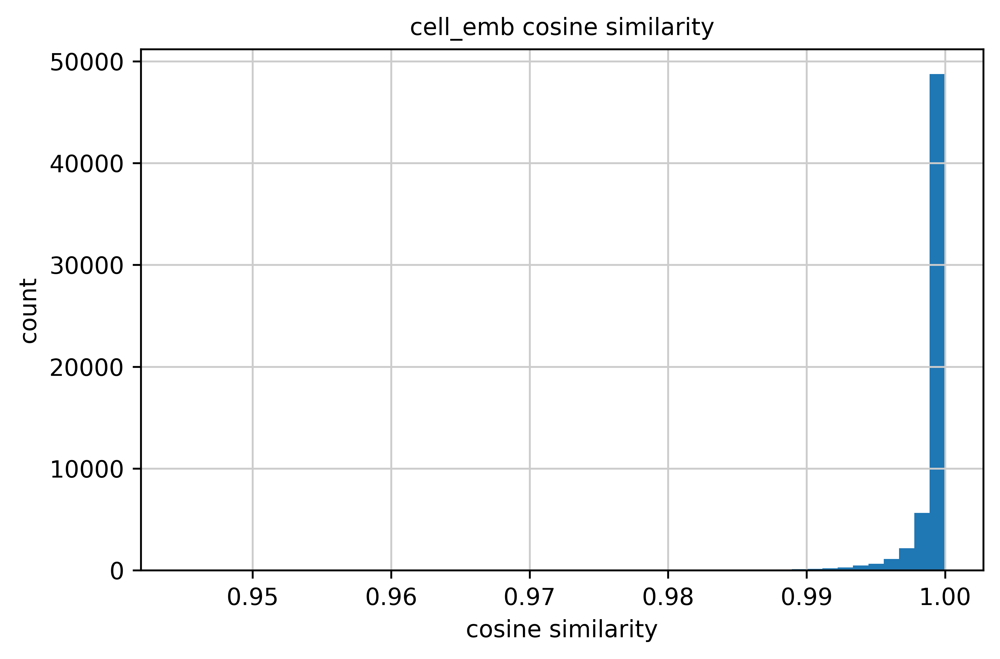

spatial_cell_emb: mean=0.999879  min=0.994835


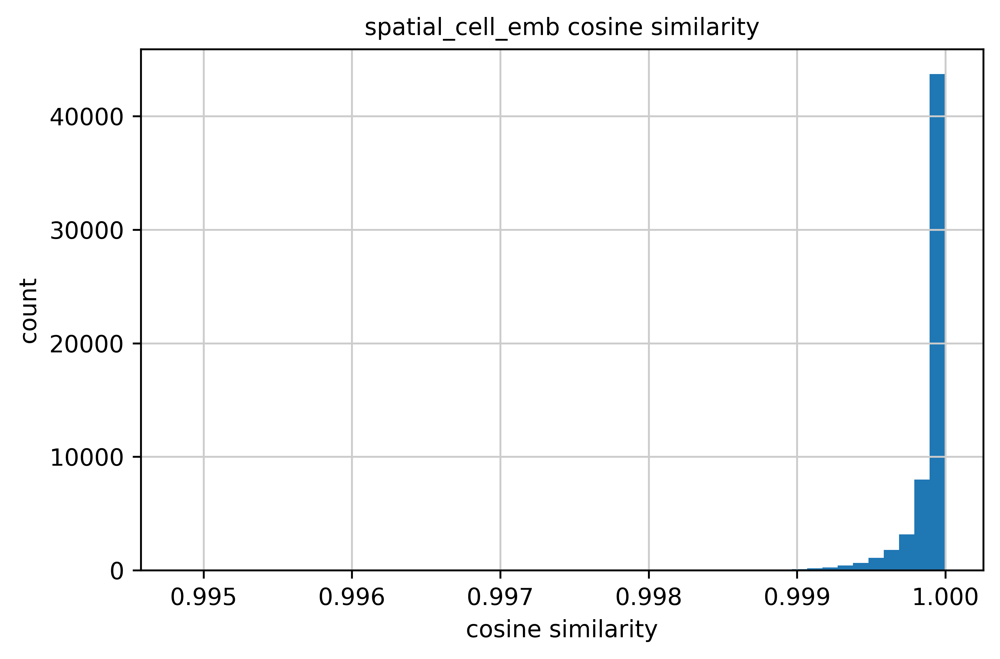

neighborhood_emb: mean=0.999973  min=0.998778


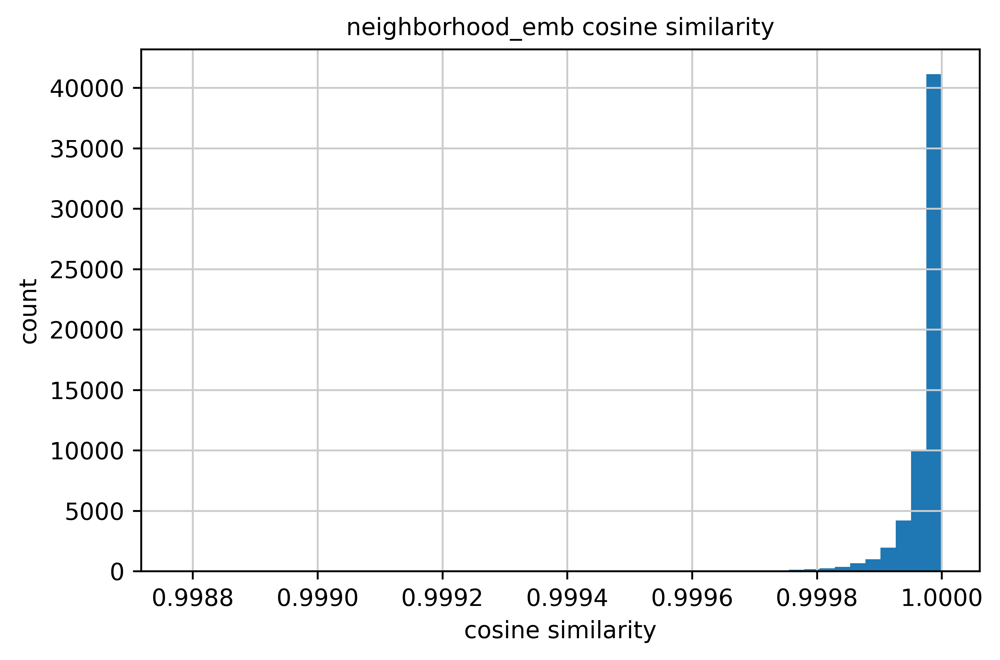

In [272]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [273]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Memory B cell,54,0.990856,0.998845,0.999959
1,Neuron,101,0.995762,0.999459,0.999967
2,CD4+ T cell,233,0.995831,0.999550,0.999957
3,Descending thin limb,120,0.996750,0.999702,0.999975
4,Conventional dendritic cell,60,0.997634,0.999841,0.999969
5,CD16+ monocyte,4,0.997688,0.999786,0.999978
6,Proximal tubule segment 2,225,0.997776,0.999747,0.999982
7,CD8+ T cell,284,0.998034,0.999837,0.999965
8,Fibroblast,30,0.998041,0.999941,0.999978
9,Lymphatic endothelium,593,0.998045,0.999804,0.999911


In [274]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Injured proximal nephron neighborhood,1219,0.998655,0.999863,0.999947
1,Proximal nephron neighborhood,13317,0.998659,0.999815,0.999989
2,Loop of Henle neighborhood,4268,0.998951,0.999871,0.999989
3,Fibrovascular neighborhood,8558,0.999034,0.999866,0.999976
4,Distal nephron neighborhood,8955,0.999398,0.999936,0.999988
5,Glomerular neighborhood,23740,0.999403,0.999901,0.999956


In [275]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99913746
Spatial cell embedding average: 0.999879
Neighborhood embedding average: 0.9999732
Lowest cell embedding average per cell type: 0.9908562898635864
Lowest spatial cell embedding average per cell type: 0.9988449215888977
Lowest neighborhood embedding average per cell type: 0.9999114871025085
Lowest cell embedding average per niche: 0.9986554384231567
Lowest spatial cell embedding average per niche: 0.9998148083686829
Lowest neighborhood embedding average per niche: 0.9999474287033081


#### 2.5.7.2 Neighborhood Perturbations

In [276]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [277]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

378145


In [278]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999863  min=0.944688


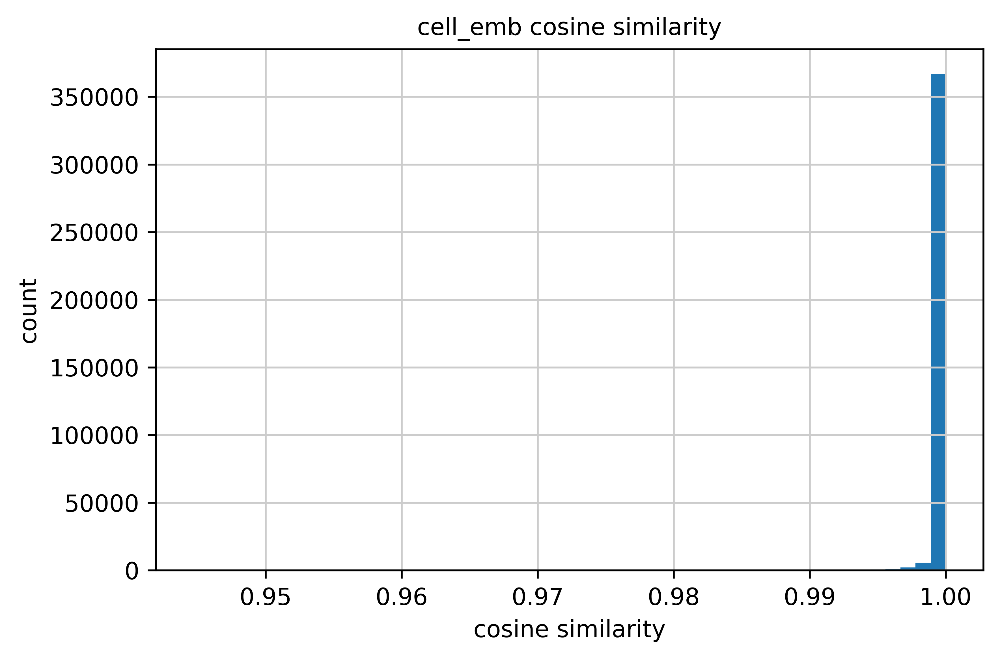

spatial_cell_emb: mean=0.999970  min=0.994835


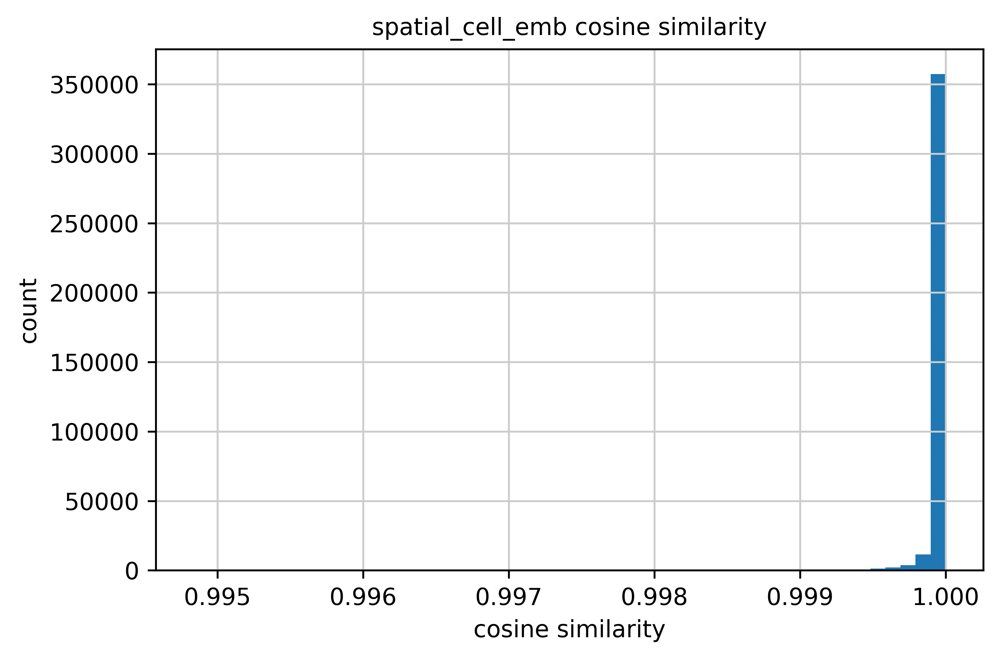

neighborhood_emb: mean=0.999984  min=0.997948


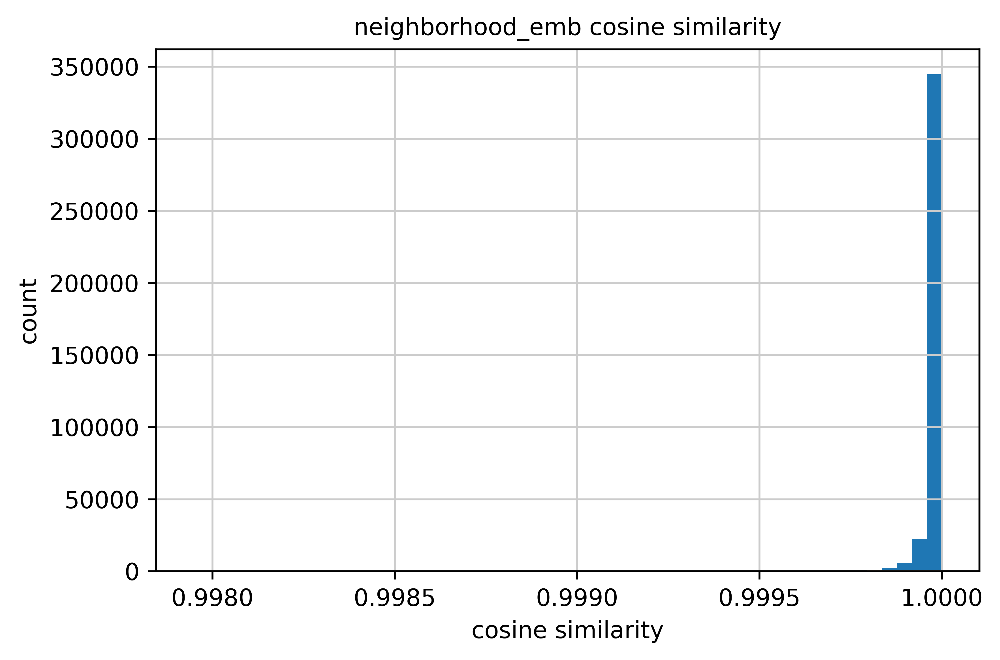

In [279]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [280]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Lymphatic endothelium,651,0.998219,0.999817,0.999915
1,Podocyte,28723,0.999829,0.999957,0.999962
2,Naive B cell,741,0.999811,0.999956,0.999964
3,Mesangial cell,11801,0.999903,0.999970,0.999970
4,Memory B cell,874,0.999435,0.999905,0.999971
5,CD4+ T cell,4199,0.999769,0.999951,0.999972
6,Neuron,886,0.999517,0.999917,0.999972
7,Parietal epithelial cell,4533,0.999952,0.999975,0.999973
8,Glomerular endothelial cell,30846,0.999700,0.999932,0.999974
9,CD8+ T cell,3591,0.999844,0.999970,0.999979


In [281]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Injured proximal nephron neighborhood,1219,0.998655,0.999863,0.999947
1,Glomerular neighborhood,23740,0.999403,0.999901,0.999956
2,Fibrovascular neighborhood,8558,0.999034,0.999866,0.999976
3,Distal nephron neighborhood,8955,0.999398,0.999936,0.999988
4,Loop of Henle neighborhood,4268,0.998951,0.999871,0.999989
5,Proximal nephron neighborhood,13317,0.998659,0.999815,0.999989


In [282]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99986297
Spatial cell embedding average: 0.9999699
Neighborhood embedding average: 0.999984
Lowest cell embedding average per cell type: 0.99821937084198
Lowest spatial cell embedding average per cell type: 0.9998172521591187
Lowest neighborhood embedding average per cell type: 0.999915361404419
Lowest cell embedding average per niche: 0.9986554384231567
Lowest spatial cell embedding average per niche: 0.9998148083686829
Lowest neighborhood embedding average per niche: 0.9999474287033081


### 2.5.8 Perturbation Case 8 (PDGFRA Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - PDGFRA (ENSG00000134853)
    - PDGFA (ENSG00000197461)
    - PDGFC (ENSG00000145431)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [290]:
pert_case = 8
pert_genes = [
    'PDGFRA',
    'PDGFA',
    'PDGFC',
]

In [291]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

             ensembl_id  highly_variable  highly_variable_rank     means  \
PDGFRA  ENSG00000134853             True                 188.0  0.107361   

        variances  variances_norm  
PDGFRA   0.226664        1.465978  
            ensembl_id  highly_variable  highly_variable_rank     means  \
PDGFA  ENSG00000197461            False                   NaN  0.055647   

       variances  variances_norm  
PDGFA   0.068691        0.979758  
            ensembl_id  highly_variable  highly_variable_rank    means  \
PDGFC  ENSG00000145431            False                   NaN  0.01708   

       variances  variances_norm  
PDGFC   0.018474         0.98437  


In [292]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.8.1 Cell Perturbations

In [297]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [298]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

105877


In [299]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.997372  min=0.893402


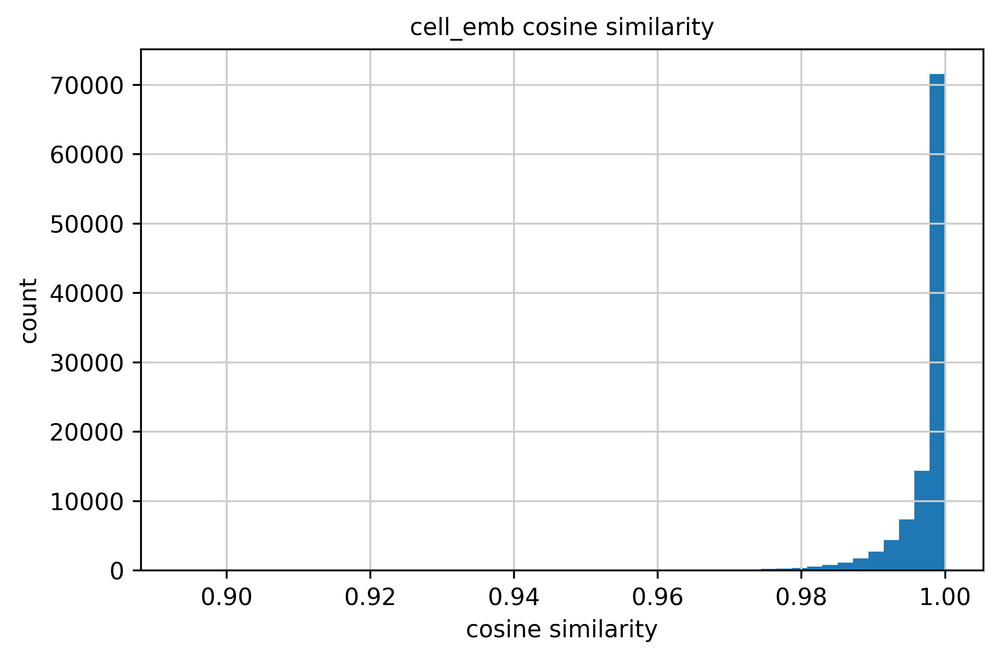

spatial_cell_emb: mean=0.999432  min=0.981702


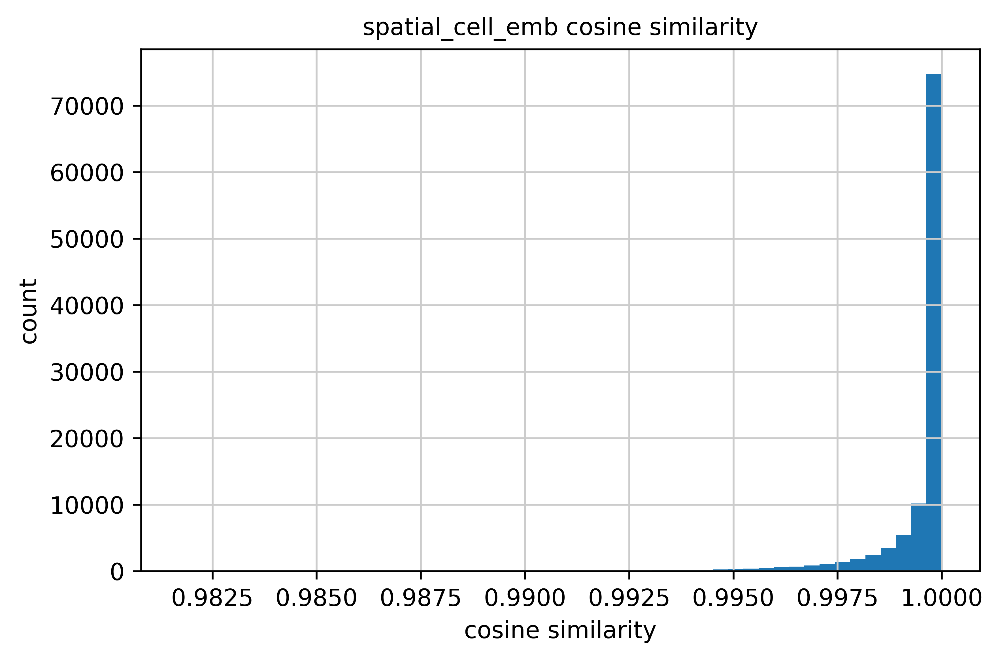

neighborhood_emb: mean=0.999512  min=0.982405


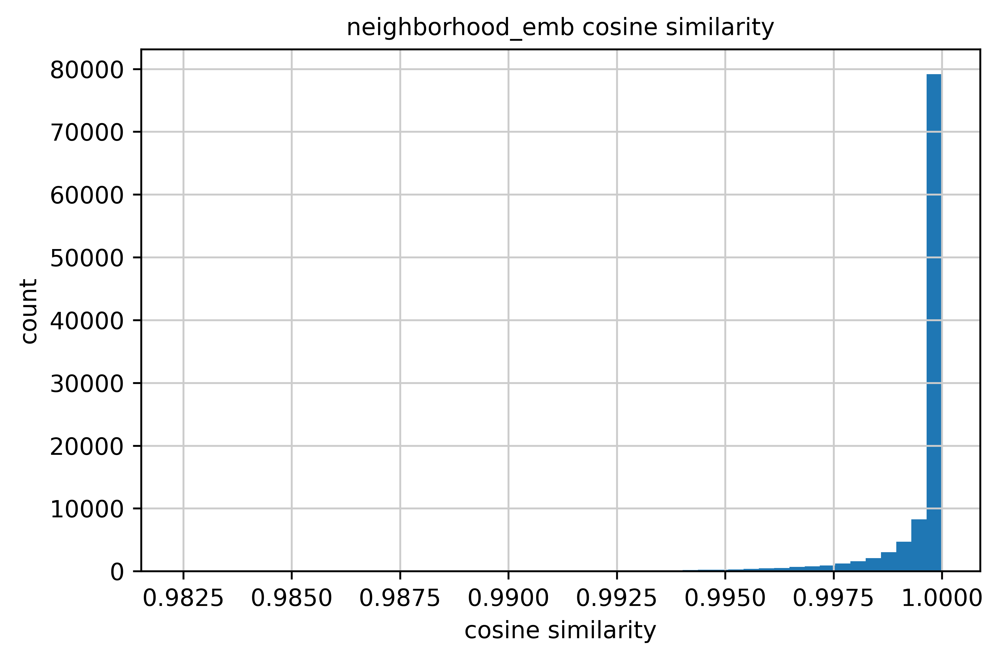

In [300]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [301]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,CD4+ T cell,392,0.989017,0.998635,0.999162
1,Memory B cell,78,0.990253,0.999053,0.999382
2,Neuron,136,0.990871,0.998925,0.999297
3,CD8+ T cell,779,0.993416,0.999124,0.999252
4,Neutrophil,189,0.993611,0.999148,0.999258
5,Conventional dendritic cell,319,0.994089,0.999125,0.999237
6,Natural killer cell,19,0.994541,0.999783,0.999832
7,Naive B cell,185,0.994925,0.998909,0.999017
8,Basophil / Mast cell,7,0.995105,0.999439,0.999564
9,CD16+ monocyte,6,0.995445,0.998816,0.999082


In [302]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Fibrovascular neighborhood,22052,0.996914,0.999253,0.999364
1,Injured proximal nephron neighborhood,3539,0.996961,0.999254,0.999365
2,Loop of Henle neighborhood,9744,0.997071,0.999490,0.999579
3,Proximal nephron neighborhood,31806,0.997283,0.999753,0.999859
4,Glomerular neighborhood,17499,0.997797,0.999892,0.999933
5,Distal nephron neighborhood,21237,0.997840,0.998759,0.998796


In [303]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.9973724
Spatial cell embedding average: 0.99943155
Neighborhood embedding average: 0.99951243
Lowest cell embedding average per cell type: 0.9890168905258179
Lowest spatial cell embedding average per cell type: 0.9986348152160645
Lowest neighborhood embedding average per cell type: 0.9990167021751404
Lowest cell embedding average per niche: 0.9969143271446228
Lowest spatial cell embedding average per niche: 0.9987593293190002
Lowest neighborhood embedding average per niche: 0.9987959265708923


#### 2.5.8.2 Neighborhood Perturbations

In [304]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [305]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

574303


In [306]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999516  min=0.893402


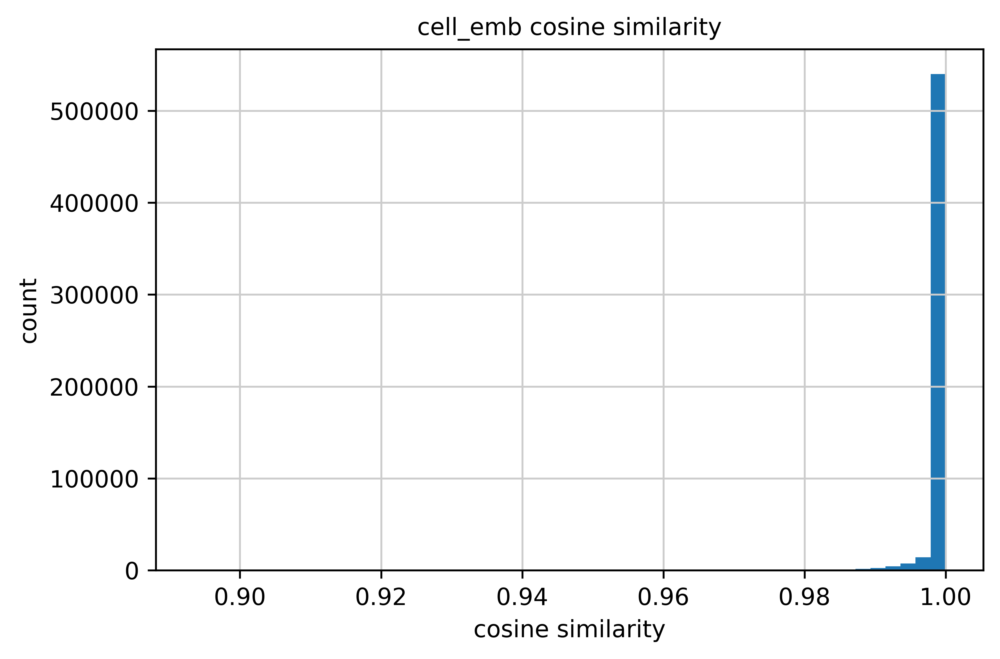

spatial_cell_emb: mean=0.999632  min=0.978212


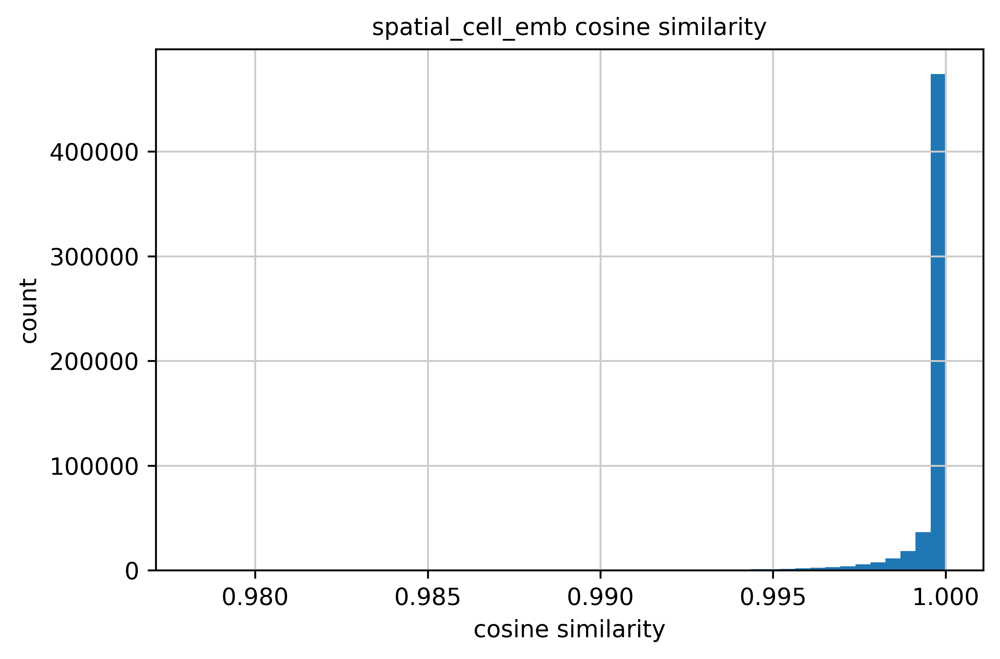

neighborhood_emb: mean=0.999674  min=0.980377


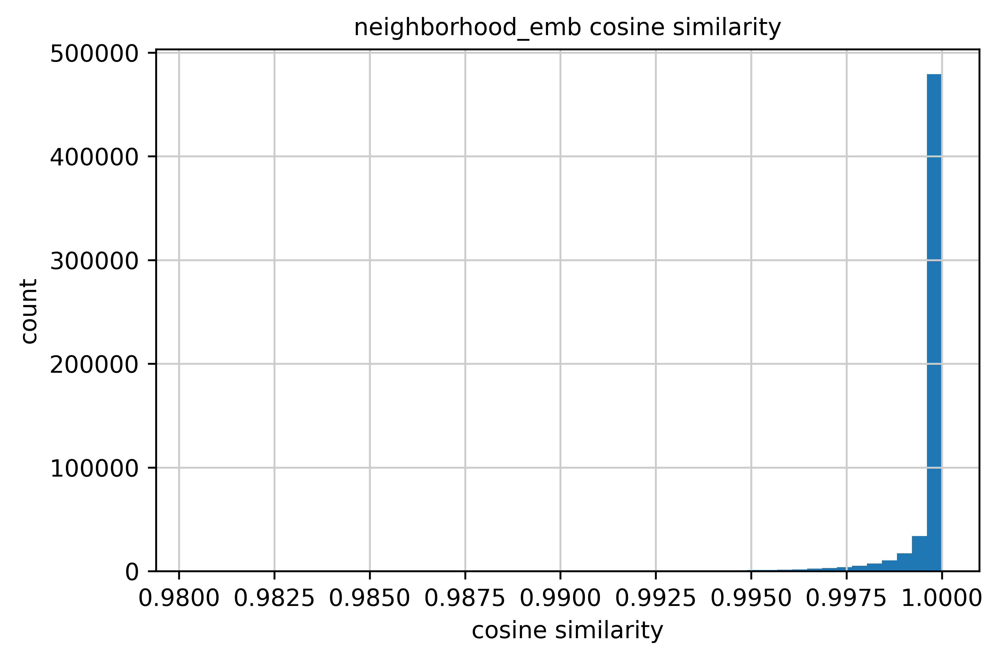

In [307]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [308]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Basophil / Mast cell,52,0.999341,0.998851,0.998859
1,Macula densa,10492,0.999762,0.998958,0.999068
2,Distal convoluted tubule 2,4929,0.999702,0.999075,0.999186
3,Ascending thin limb,497,0.999784,0.999146,0.999245
4,Principal cell,14287,0.999688,0.999183,0.999275
5,Naive B cell,1112,0.999156,0.999211,0.999288
6,Intercalated cell type A,25625,0.999717,0.999208,0.999310
7,Distal convoluted tubule 1,13791,0.999744,0.999231,0.999329
8,Medullary thick ascending limb,22170,0.999749,0.999325,0.999403
9,Memory B cell,1318,0.999423,0.999291,0.999406


In [309]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Distal nephron neighborhood,21237,0.997840,0.998759,0.998796
1,Fibrovascular neighborhood,22052,0.996914,0.999253,0.999364
2,Injured proximal nephron neighborhood,3539,0.996961,0.999254,0.999365
3,Loop of Henle neighborhood,9744,0.997071,0.999490,0.999579
4,Proximal nephron neighborhood,31806,0.997283,0.999753,0.999859
5,Glomerular neighborhood,17499,0.997797,0.999892,0.999933


### 2.5.9 Perturbation Case 9 (PDGFRB Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - PDGFRB (ENSG00000113721)
    - PDGFB (ENSG00000100311)
    - PDGFD (ENSG00000170962)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [343]:
pert_case = 9
pert_genes = [
    'PDGFRB',
    'PDGFB',
    'PDGFD'
]

In [344]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

             ensembl_id  highly_variable  highly_variable_rank     means  \
PDGFRB  ENSG00000113721             True                 348.0  0.157412   

        variances  variances_norm  
PDGFRB   0.314816        1.230433  
            ensembl_id  highly_variable  highly_variable_rank    means  \
PDGFB  ENSG00000100311            False                   NaN  0.01589   

       variances  variances_norm  
PDGFB    0.01915        1.097778  
            ensembl_id  highly_variable  highly_variable_rank     means  \
PDGFD  ENSG00000170962            False                   NaN  0.004686   

       variances  variances_norm  
PDGFD    0.00494        0.974462  


In [345]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.9.1 Cell Perturbations

In [346]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [347]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

107678


In [348]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.998166  min=0.922568


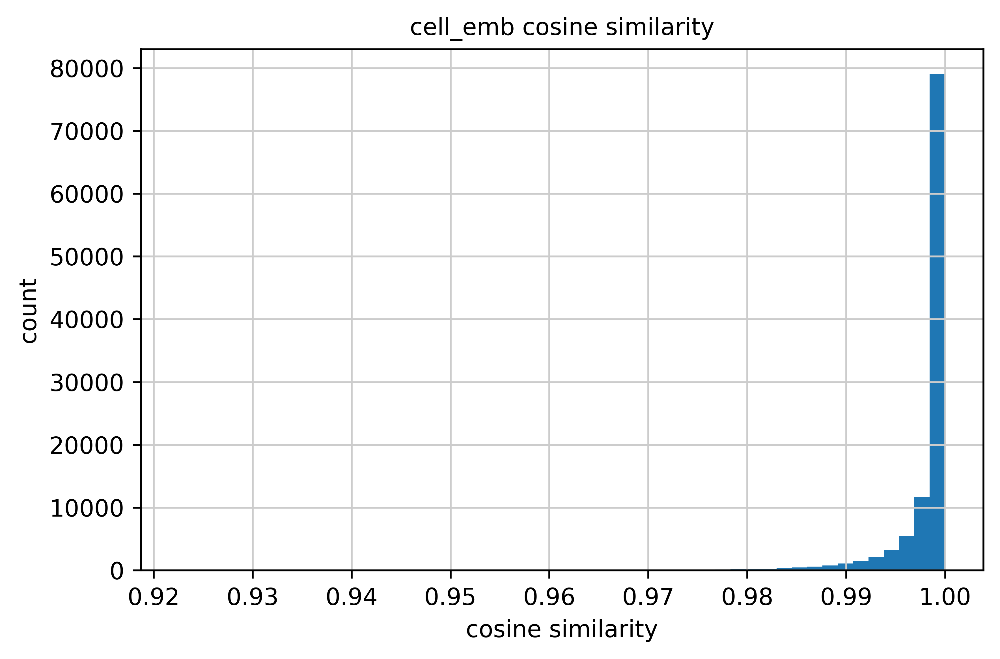

spatial_cell_emb: mean=0.999847  min=0.991752


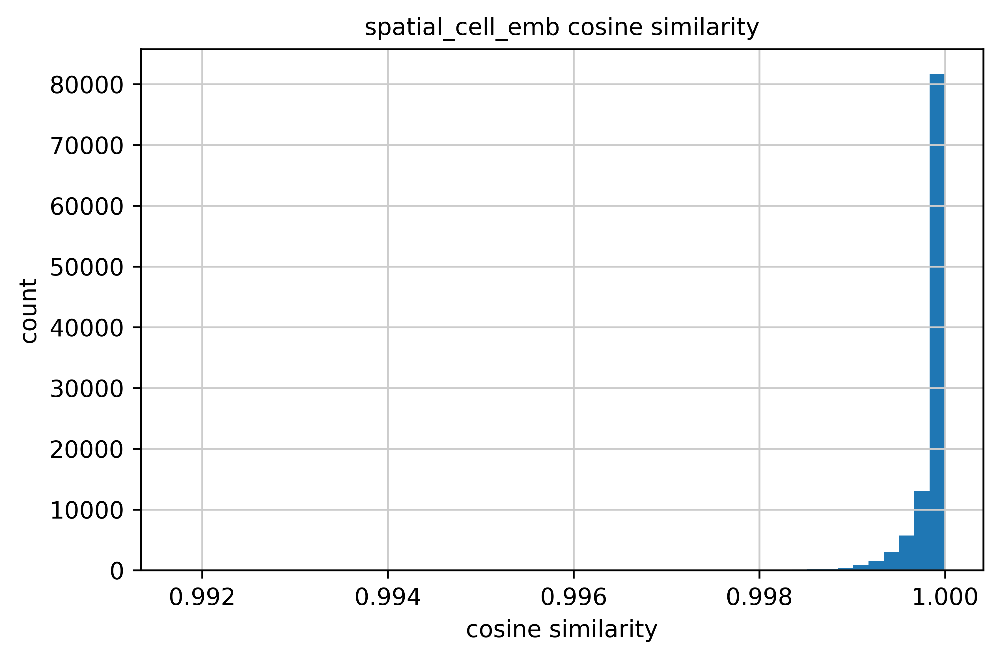

neighborhood_emb: mean=0.999938  min=0.995623


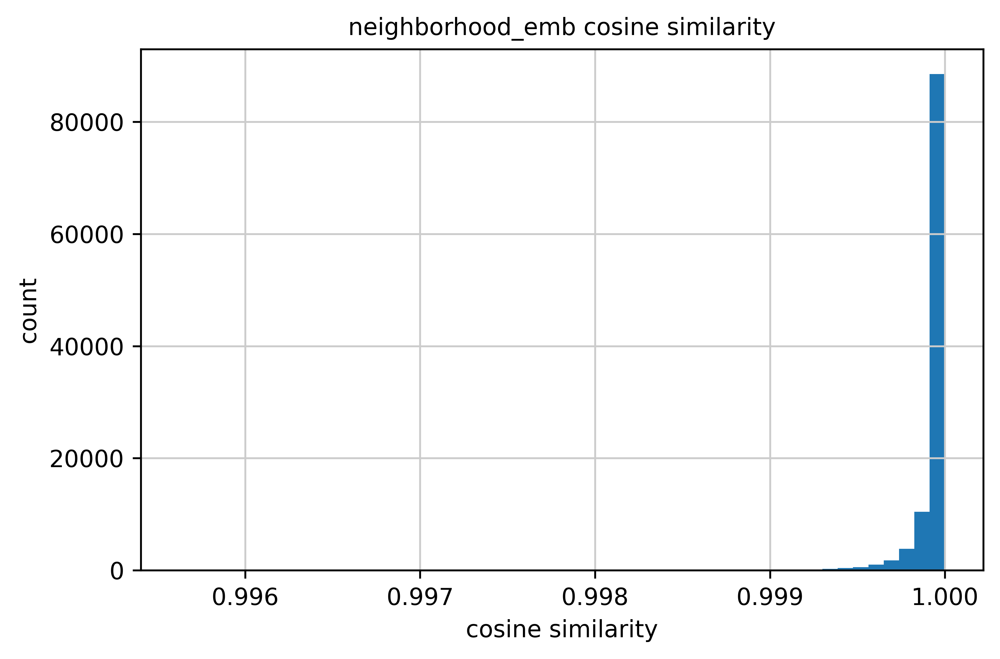

In [349]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [350]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Memory B cell,27,0.990258,0.999372,0.999874
1,Neuron,218,0.992620,0.999481,0.999864
2,CD4+ T cell,147,0.994276,0.999647,0.999913
3,Descending thin limb,440,0.994835,0.999705,0.999931
4,Proximal tubule segment 2,292,0.994883,0.999715,0.999911
5,Vascular mural cell,24949,0.996318,0.999710,0.999910
6,CDH13+ stromal cell,810,0.996368,0.999770,0.999889
7,CD14+ monocyte,16,0.997047,0.999851,0.999940
8,Natural killer cell,55,0.997056,0.999893,0.999931
9,CD8+ T cell,619,0.997185,0.999874,0.999947


In [351]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Proximal nephron neighborhood,24684,0.997284,0.999748,0.999889
1,Loop of Henle neighborhood,8143,0.997718,0.999859,0.999974
2,Fibrovascular neighborhood,24215,0.998136,0.999813,0.999929
3,Glomerular neighborhood,30801,0.998484,0.999903,0.999958
4,Injured proximal nephron neighborhood,3117,0.998840,0.999878,0.999946
5,Distal nephron neighborhood,16718,0.999022,0.999931,0.999970


In [352]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.9981663
Spatial cell embedding average: 0.9998475
Neighborhood embedding average: 0.9999383
Lowest cell embedding average per cell type: 0.9902576208114624
Lowest spatial cell embedding average per cell type: 0.9993717670440674
Lowest neighborhood embedding average per cell type: 0.999863862991333
Lowest cell embedding average per niche: 0.9972838759422302
Lowest spatial cell embedding average per niche: 0.9997475743293762
Lowest neighborhood embedding average per niche: 0.9998888969421387


#### 2.5.9.2 Neighborhood Perturbations

In [353]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [354]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

546150


In [355]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999639  min=0.922568


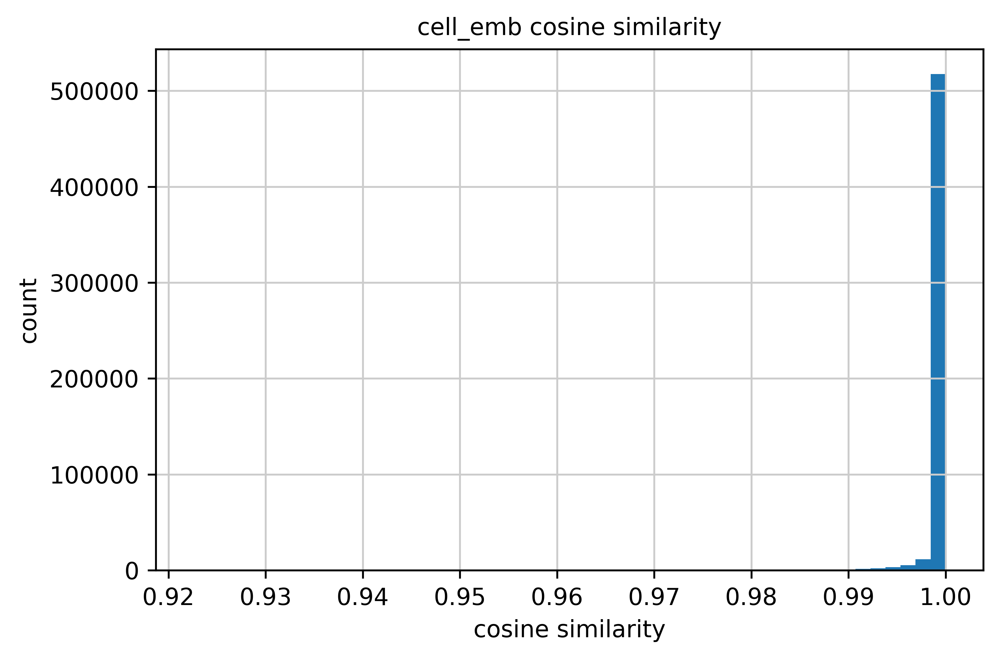

spatial_cell_emb: mean=0.999924  min=0.991752


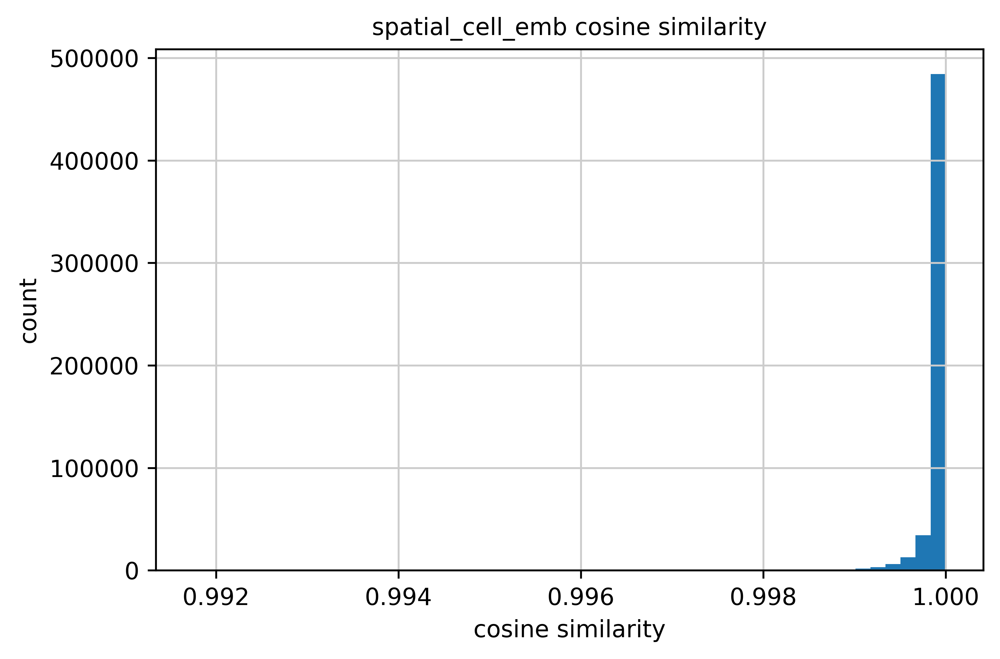

neighborhood_emb: mean=0.999945  min=0.995517


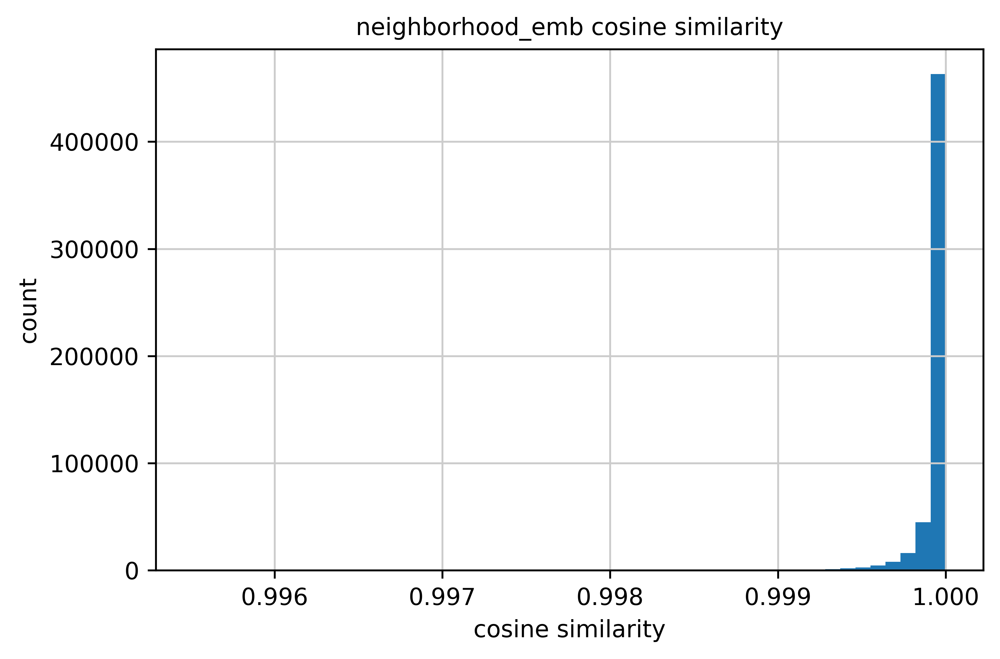

In [356]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [357]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,CD16+ monocyte,65,0.999924,0.999902,0.999894
1,Neuron,1396,0.998847,0.999838,0.999898
2,CD4+ T cell,6097,0.999862,0.999901,0.999904
3,Proximal tubule segment 1,34921,0.999911,0.999893,0.999912
4,Memory B cell,1397,0.999812,0.999906,0.999915
5,Proximal tubule segment 2,8670,0.999828,0.999898,0.999915
6,Proximal tubule segment 3,56159,0.999903,0.999900,0.999917
7,CDH13+ stromal cell,4953,0.999406,0.999890,0.999918
8,Injured proximal tubule,28684,0.999922,0.999911,0.999925
9,Vascular mural cell,51415,0.998213,0.999833,0.999928


In [358]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Proximal nephron neighborhood,24684,0.997284,0.999748,0.999889
1,Fibrovascular neighborhood,24215,0.998136,0.999813,0.999929
2,Injured proximal nephron neighborhood,3117,0.998840,0.999878,0.999946
3,Glomerular neighborhood,30801,0.998484,0.999903,0.999958
4,Distal nephron neighborhood,16718,0.999022,0.999931,0.999970
5,Loop of Henle neighborhood,8143,0.997718,0.999859,0.999974


In [359]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.9996386
Spatial cell embedding average: 0.9999245
Neighborhood embedding average: 0.99994504
Lowest cell embedding average per cell type: 0.9982132315635681
Lowest spatial cell embedding average per cell type: 0.9998332262039185
Lowest neighborhood embedding average per cell type: 0.9998935461044312
Lowest cell embedding average per niche: 0.9972838759422302
Lowest spatial cell embedding average per niche: 0.9997475743293762
Lowest neighborhood embedding average per niche: 0.9998888969421387


### 2.5.10 Perturbation Case 10 (KIT Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - KIT (ENSG00000157404)
    - KITLG (ENSG00000049130)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [381]:
pert_case = 10
pert_genes = [
    'KIT',
    'KITLG'
]

In [382]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

          ensembl_id  highly_variable  highly_variable_rank     means  \
KIT  ENSG00000157404             True                 392.0  0.011046   

     variances  variances_norm  
KIT   0.014475         1.19744  
            ensembl_id  highly_variable  highly_variable_rank     means  \
KITLG  ENSG00000049130            False                   NaN  0.015087   

       variances  variances_norm  
KITLG   0.017994        1.087373  


In [383]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.10.1 Cell Perturbations

In [384]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

Filter: 100%|███████████████████████████████████████████| 178033/178033 [00:37<00:00, 4744.12 examples/s]


In [385]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

21282


In [386]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.999583  min=0.964750


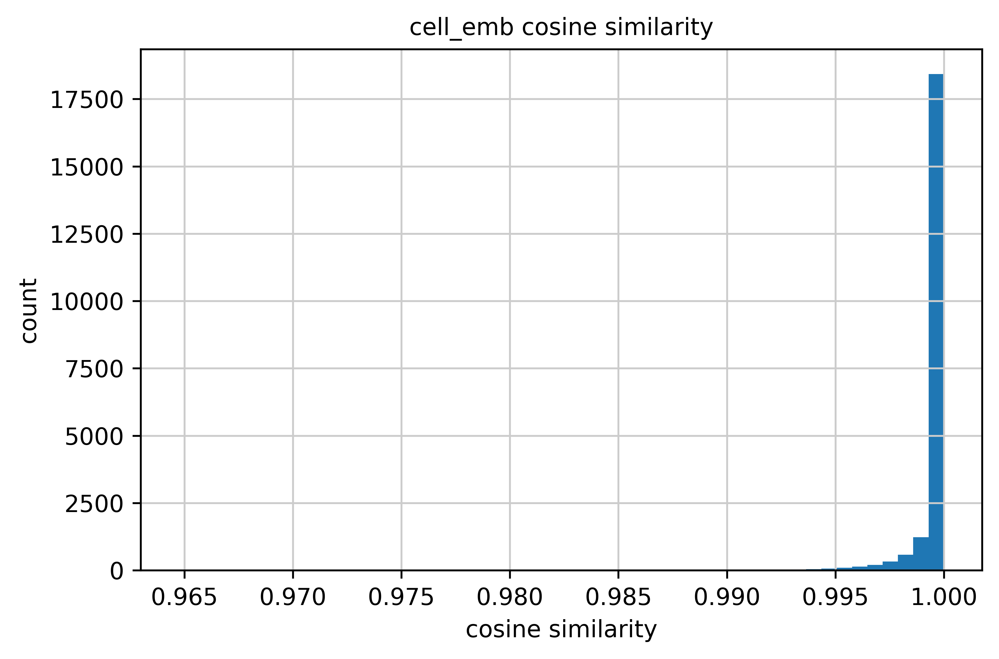

spatial_cell_emb: mean=0.999952  min=0.995474


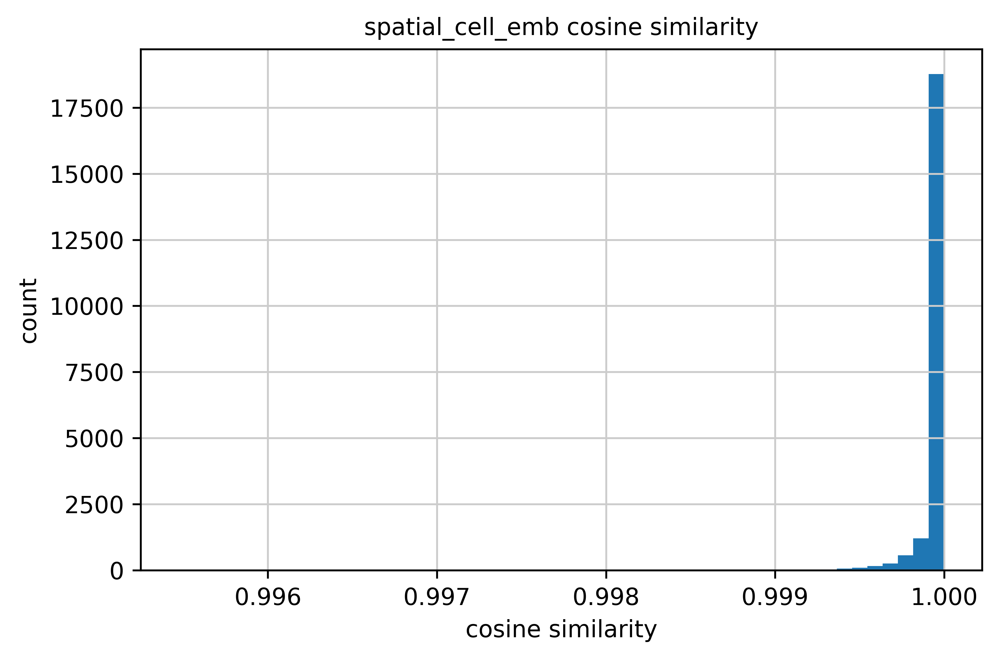

neighborhood_emb: mean=0.999994  min=0.999142


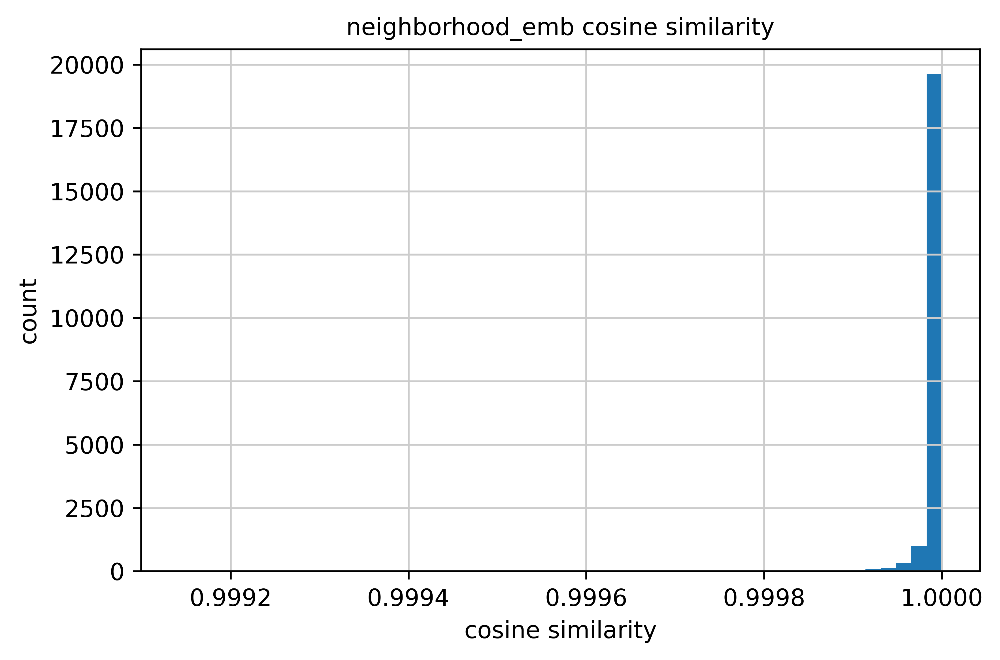

In [387]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [388]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,CD4+ T cell,34,0.998235,0.999753,0.999991
1,Neuron,36,0.998296,0.999773,0.999989
2,Vascular mural cell,656,0.998893,0.999907,0.999993
3,Glomerular endothelial cell,263,0.998912,0.999903,0.999993
4,Proximal tubule segment 2,39,0.998957,0.999818,0.999992
5,Descending thin limb,59,0.999030,0.999917,0.999993
6,Memory B cell,2,0.999177,0.999948,0.999994
7,Basophil / Mast cell,31,0.999227,0.999942,0.999997
8,Mesangial cell,147,0.999274,0.999961,0.999997
9,Distal convoluted tubule 2,940,0.999288,0.999925,0.999987


In [389]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Proximal nephron neighborhood,3369,0.999104,0.999889,0.999992
1,Loop of Henle neighborhood,1251,0.999361,0.999935,0.999995
2,Glomerular neighborhood,931,0.999374,0.999953,0.999997
3,Fibrovascular neighborhood,4152,0.999460,0.999934,0.999988
4,Injured proximal nephron neighborhood,260,0.999631,0.999946,0.999990
5,Distal nephron neighborhood,11319,0.999811,0.999980,0.999996


In [390]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.999583
Spatial cell embedding average: 0.9999522
Neighborhood embedding average: 0.9999935
Lowest cell embedding average per cell type: 0.9982353448867798
Lowest spatial cell embedding average per cell type: 0.9997525811195374
Lowest neighborhood embedding average per cell type: 0.9999868869781494
Lowest cell embedding average per niche: 0.9991037845611572
Lowest spatial cell embedding average per niche: 0.9998889565467834
Lowest neighborhood embedding average per niche: 0.9999882578849792


#### 2.5.10.2 Neighborhood Perturbations

In [391]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

Filter: 100%|██████████████████████████████████████████| 178033/178033 [00:06<00:00, 27557.23 examples/s]


In [392]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

178033


In [393]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999950  min=0.964750


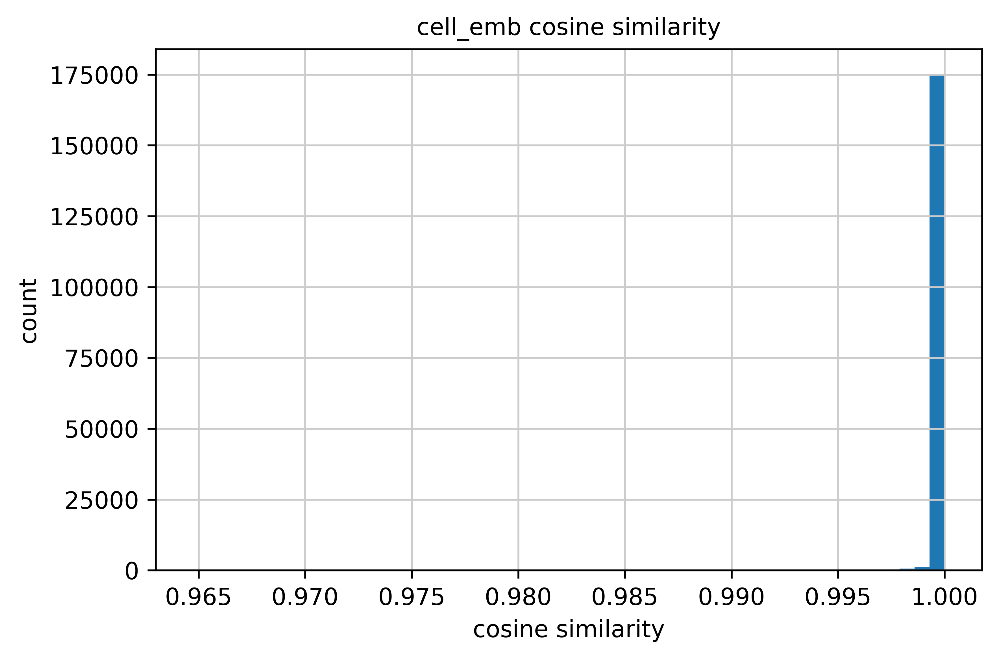

spatial_cell_emb: mean=0.999990  min=0.995474


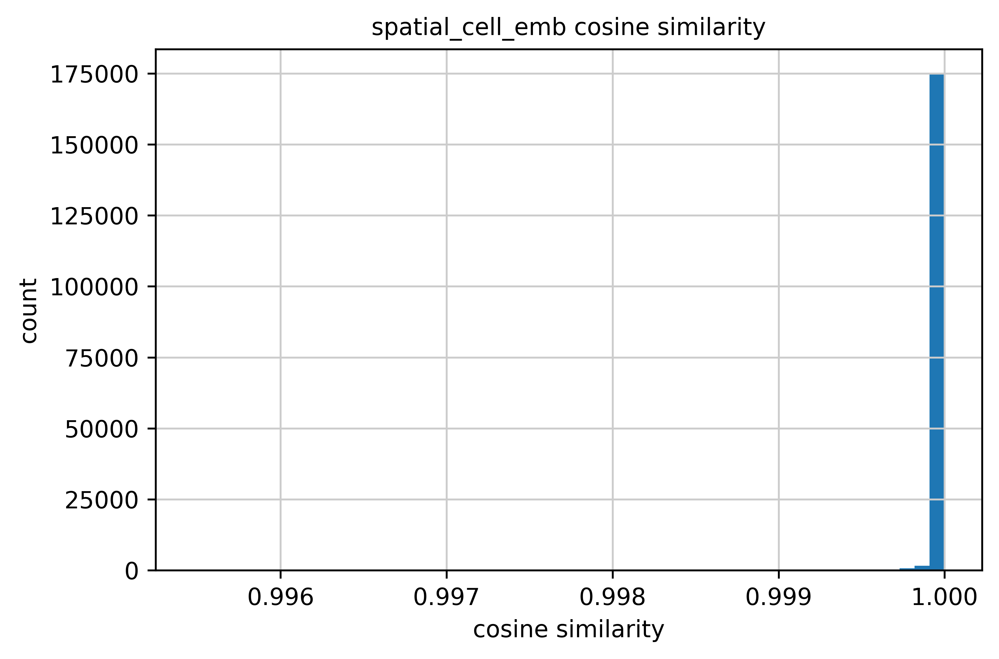

neighborhood_emb: mean=0.999994  min=0.997783


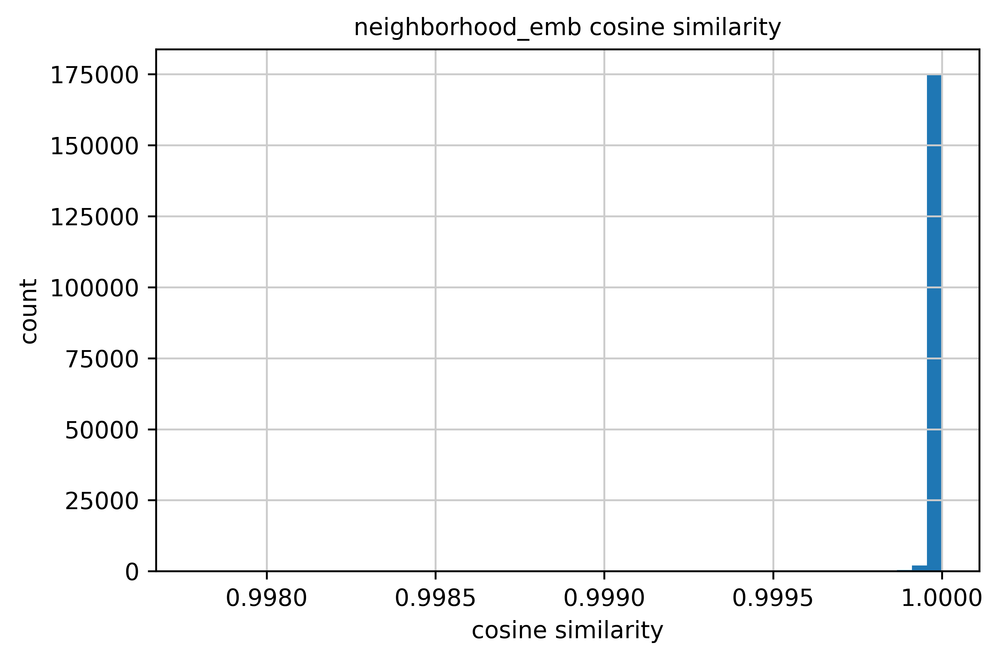

In [394]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [395]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,CD4+ T cell,1456,0.999959,0.999981,0.999984
1,Neuron,299,0.999795,0.999960,0.999985
2,Memory B cell,346,0.999995,0.999988,0.999985
3,Ascending thin limb,98,0.999999,0.999989,0.999989
4,Descending thin limb,1332,0.999957,0.999988,0.999990
5,Proximal tubule segment 2,1667,0.999976,0.999988,0.999991
6,Distal convoluted tubule 2,4425,0.999849,0.999979,0.999991
7,Glomerular endothelial cell,4574,0.999937,0.999987,0.999992
8,CD14+ monocyte,32,1.000000,0.999993,0.999992
9,Vascular mural cell,8522,0.999915,0.999987,0.999992


In [396]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Fibrovascular neighborhood,4152,0.999460,0.999934,0.999988
1,Injured proximal nephron neighborhood,260,0.999631,0.999946,0.999990
2,Proximal nephron neighborhood,3369,0.999104,0.999889,0.999992
3,Loop of Henle neighborhood,1251,0.999361,0.999935,0.999995
4,Distal nephron neighborhood,11319,0.999811,0.999980,0.999996
5,Glomerular neighborhood,931,0.999374,0.999953,0.999997


In [397]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99995005
Spatial cell embedding average: 0.99999
Neighborhood embedding average: 0.99999404
Lowest cell embedding average per cell type: 0.9994153380393982
Lowest spatial cell embedding average per cell type: 0.9999560117721558
Lowest neighborhood embedding average per cell type: 0.9999843835830688
Lowest cell embedding average per niche: 0.9991037845611572
Lowest spatial cell embedding average per niche: 0.9998889565467834
Lowest neighborhood embedding average per niche: 0.9999882578849792


### 2.5.11 Perturbation Case 11 (FLT3 Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - FLT3 (ENSG00000122025)
    - FLT3LG (ENSG00000090554)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [398]:
pert_case = 11
pert_genes = [
    'FLT3',
    'FLT3LG'
]

In [399]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

           ensembl_id  highly_variable  highly_variable_rank     means  \
FLT3  ENSG00000122025            False                   NaN  0.001206   

      variances  variances_norm  
FLT3   0.001265         0.98422  
             ensembl_id  highly_variable  highly_variable_rank     means  \
FLT3LG  ENSG00000090554            False                   NaN  0.017757   

        variances  variances_norm  
FLT3LG   0.020211        1.034442  


In [400]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.11.1 Cell Perturbations

In [401]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

Filter: 100%|███████████████████████████████████████████| 117516/117516 [00:24<00:00, 4806.73 examples/s]


In [402]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

12295


In [403]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.999152  min=0.956459


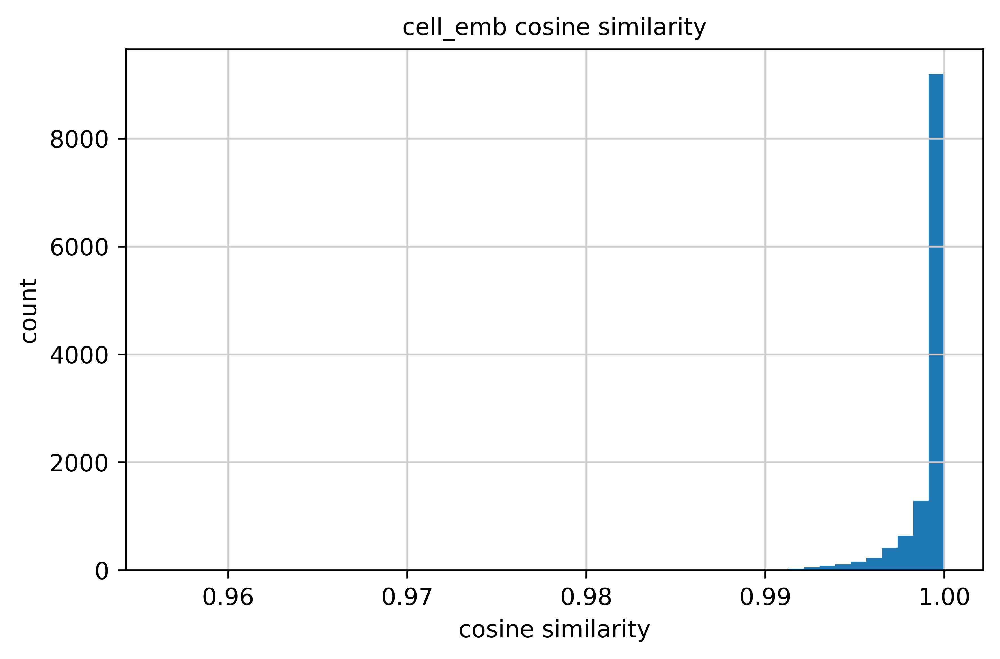

spatial_cell_emb: mean=0.999954  min=0.996895


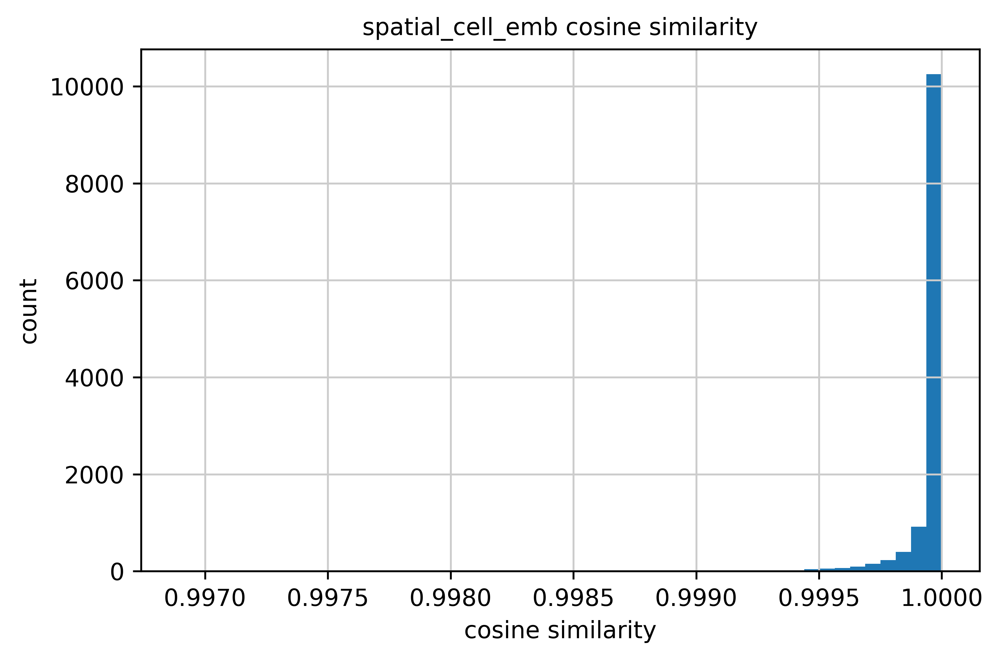

neighborhood_emb: mean=0.999995  min=0.999588


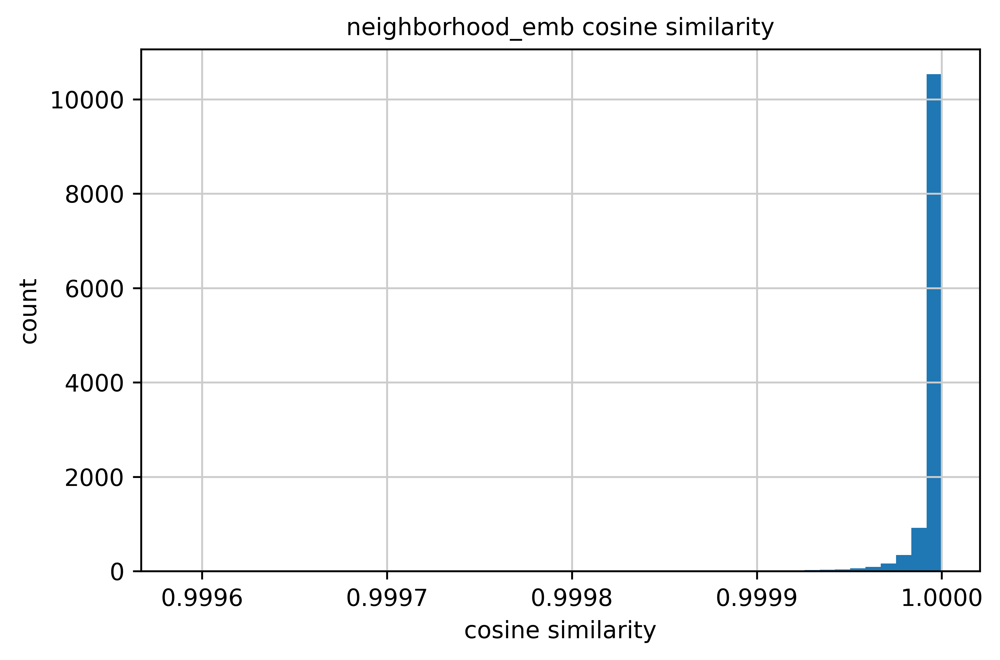

In [404]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [405]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Memory B cell,23,0.996560,0.999661,0.999976
1,Neuron,16,0.997119,0.999788,0.999989
2,CD4+ T cell,280,0.997367,0.999854,0.999978
3,Proximal tubule segment 2,76,0.997983,0.999808,0.999991
4,Descending thin limb,90,0.998203,0.999866,0.999990
5,CD8+ T cell,362,0.998412,0.999942,0.999989
6,Natural killer cell,13,0.998439,0.999943,0.999996
7,CD16+ monocyte,2,0.998547,0.999998,1.000000
8,Vascular mural cell,1030,0.998662,0.999932,0.999995
9,Neutrophil,48,0.998952,0.999971,0.999995


In [406]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Loop of Henle neighborhood,1019,0.998633,0.999933,0.999996
1,Fibrovascular neighborhood,2529,0.998973,0.999943,0.999993
2,Injured proximal nephron neighborhood,825,0.998980,0.999938,0.999977
3,Proximal nephron neighborhood,3330,0.999078,0.999939,0.999996
4,Glomerular neighborhood,1758,0.999410,0.999977,0.999998
5,Distal nephron neighborhood,2834,0.999478,0.999981,0.999997


In [407]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99915236
Spatial cell embedding average: 0.99995434
Neighborhood embedding average: 0.99999475
Lowest cell embedding average per cell type: 0.9965596199035645
Lowest spatial cell embedding average per cell type: 0.9996606707572937
Lowest neighborhood embedding average per cell type: 0.9999756217002869
Lowest cell embedding average per niche: 0.9986332058906555
Lowest spatial cell embedding average per niche: 0.9999325275421143
Lowest neighborhood embedding average per niche: 0.9999769330024719


#### 2.5.11.2 Neighborhood Perturbations

In [408]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

Filter: 100%|██████████████████████████████████████████| 117516/117516 [00:03<00:00, 32839.52 examples/s]


In [409]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

117516


In [410]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999911  min=0.956459


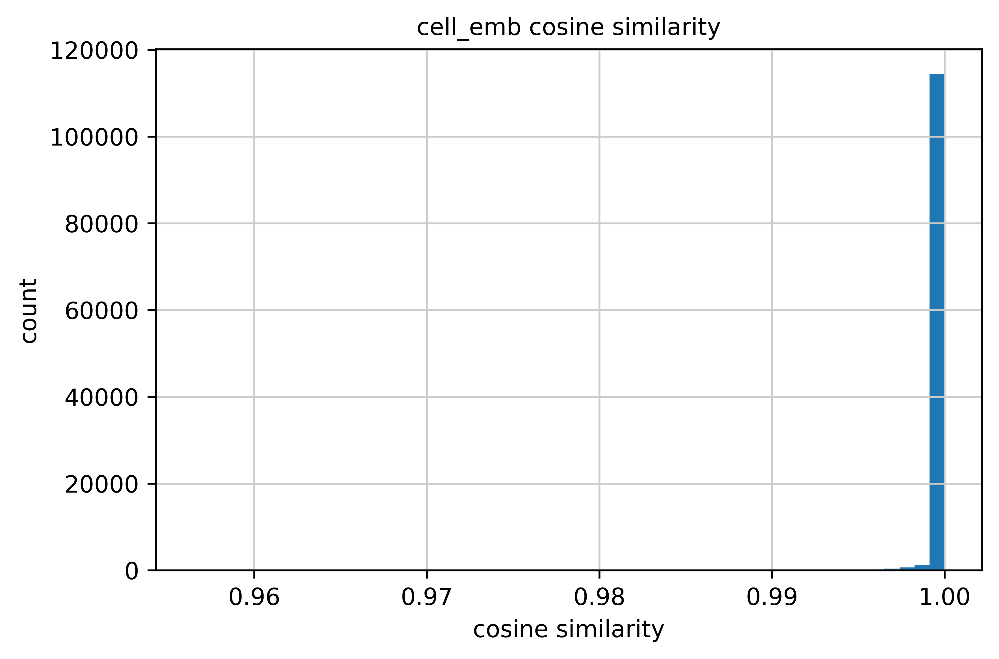

spatial_cell_emb: mean=0.999992  min=0.996895


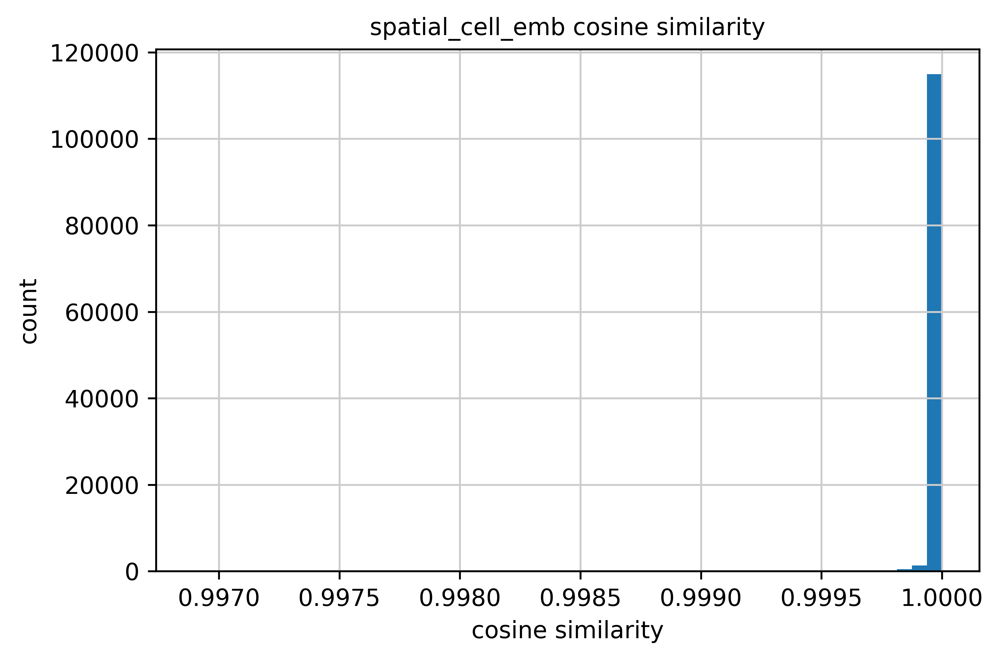

neighborhood_emb: mean=0.999996  min=0.999588


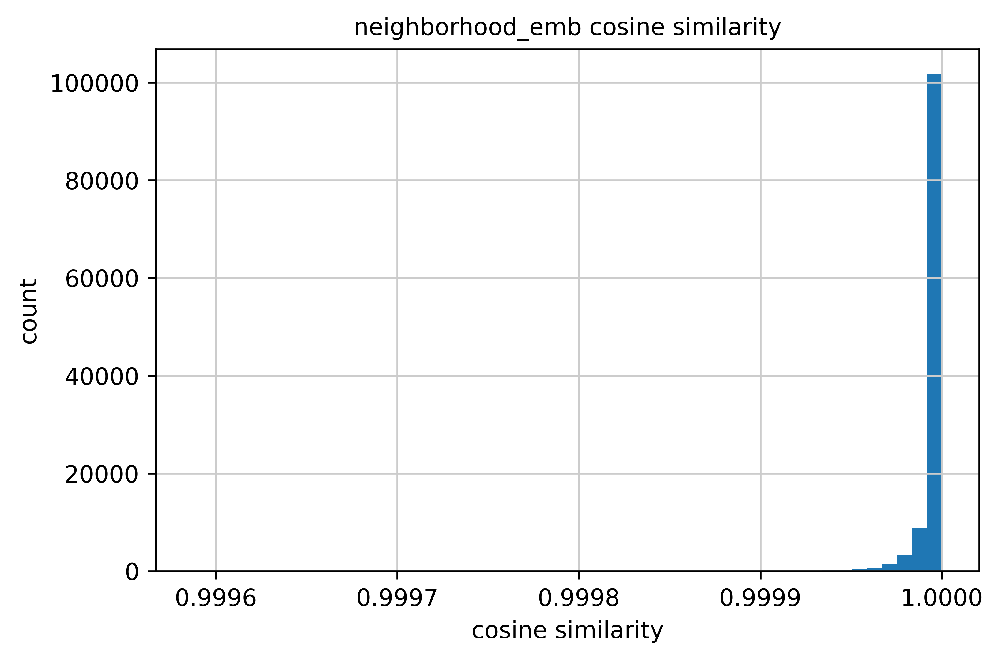

In [411]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [412]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Plasmacytoid dendritic cell,12,0.999953,0.999970,0.999976
1,Memory B cell,292,0.999729,0.999957,0.999981
2,CD4+ T cell,1750,0.999579,0.999962,0.999982
3,Naive B cell,586,0.999913,0.999984,0.999986
4,Neuron,159,0.999710,0.999967,0.999986
5,CD8+ T cell,2134,0.999730,0.999981,0.999989
6,Plasma cell,122,0.999896,0.999985,0.999989
7,Lymphatic endothelium,148,0.999949,0.999988,0.999991
8,Descending thin limb,1398,0.999884,0.999984,0.999991
9,Proximal tubule segment 2,1309,0.999883,0.999982,0.999992


In [413]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Injured proximal nephron neighborhood,825,0.998980,0.999938,0.999977
1,Fibrovascular neighborhood,2529,0.998973,0.999943,0.999993
2,Loop of Henle neighborhood,1019,0.998633,0.999933,0.999996
3,Proximal nephron neighborhood,3330,0.999078,0.999939,0.999996
4,Distal nephron neighborhood,2834,0.999478,0.999981,0.999997
5,Glomerular neighborhood,1758,0.999410,0.999977,0.999998


In [414]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.9999114
Spatial cell embedding average: 0.99999154
Neighborhood embedding average: 0.9999955
Lowest cell embedding average per cell type: 0.9995786547660828
Lowest spatial cell embedding average per cell type: 0.9999568462371826
Lowest neighborhood embedding average per cell type: 0.9999762177467346
Lowest cell embedding average per niche: 0.9986332058906555
Lowest spatial cell embedding average per niche: 0.9999325275421143
Lowest neighborhood embedding average per niche: 0.9999769330024719


### 2.5.12 Perturbation Case 12 (RET Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - RET (ENSG00000165731)
    - GDNF (ENSG00000168621)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [415]:
pert_case = 12
pert_genes = [
    'RET',
    'GDNF'
]

In [416]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

          ensembl_id  highly_variable  highly_variable_rank     means  \
RET  ENSG00000165731            False                   NaN  0.005962   

     variances  variances_norm  
RET   0.006655        1.027731  
           ensembl_id  highly_variable  highly_variable_rank     means  \
GDNF  ENSG00000168621            False                   NaN  0.001582   

      variances  variances_norm  
GDNF   0.001682        0.991379  


In [417]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.12.1 Cell Perturbations

In [418]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

Filter: 100%|█████████████████████████████████████████████| 58926/58926 [00:11<00:00, 4970.88 examples/s]


In [419]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

5676


In [420]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.999265  min=0.968483


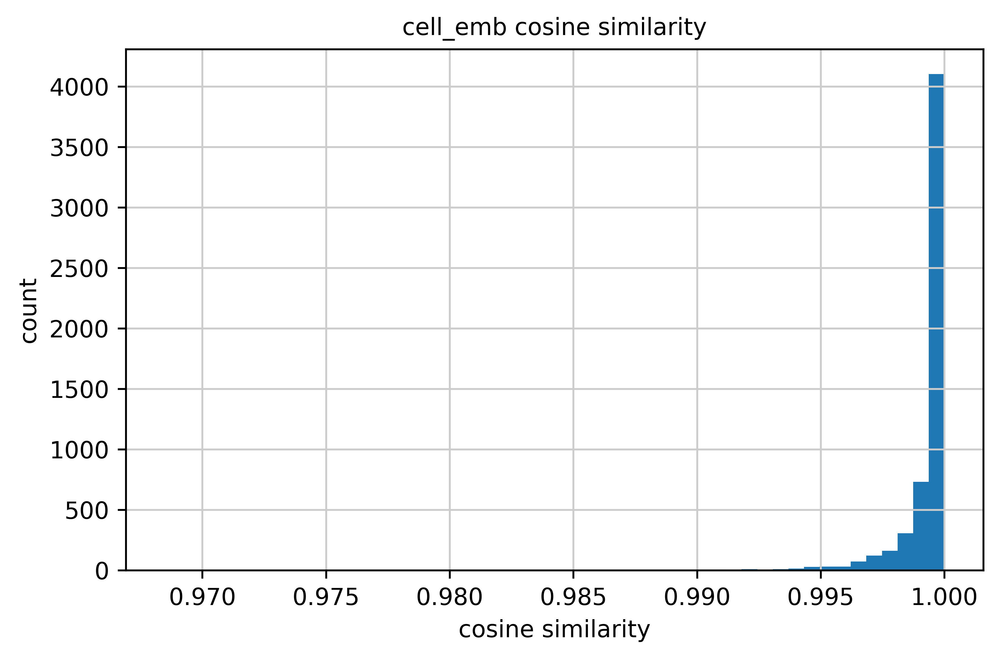

spatial_cell_emb: mean=0.999925  min=0.995937


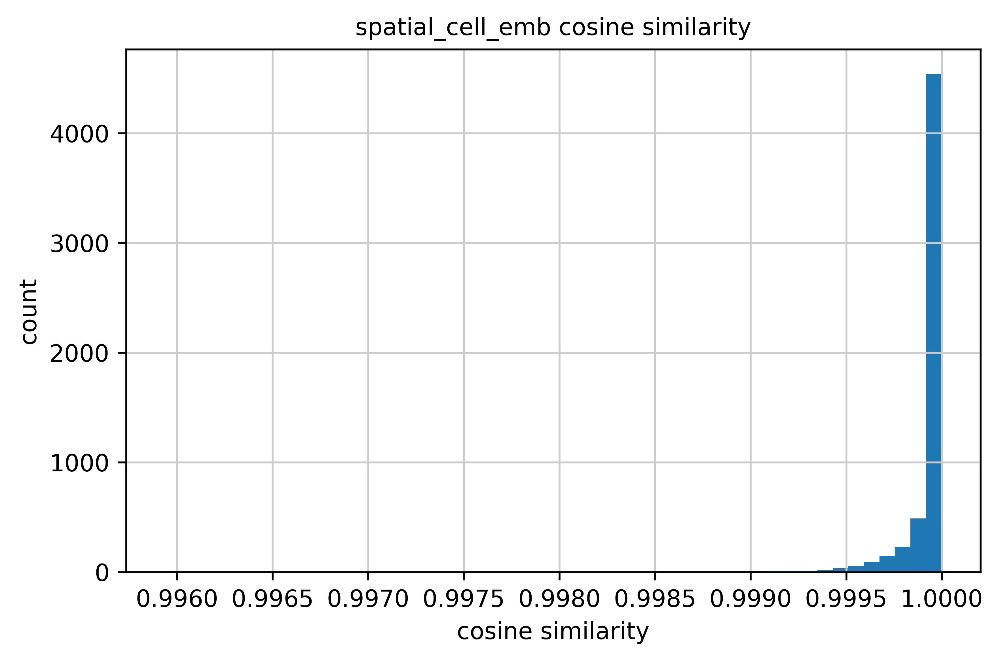

neighborhood_emb: mean=0.999991  min=0.997011


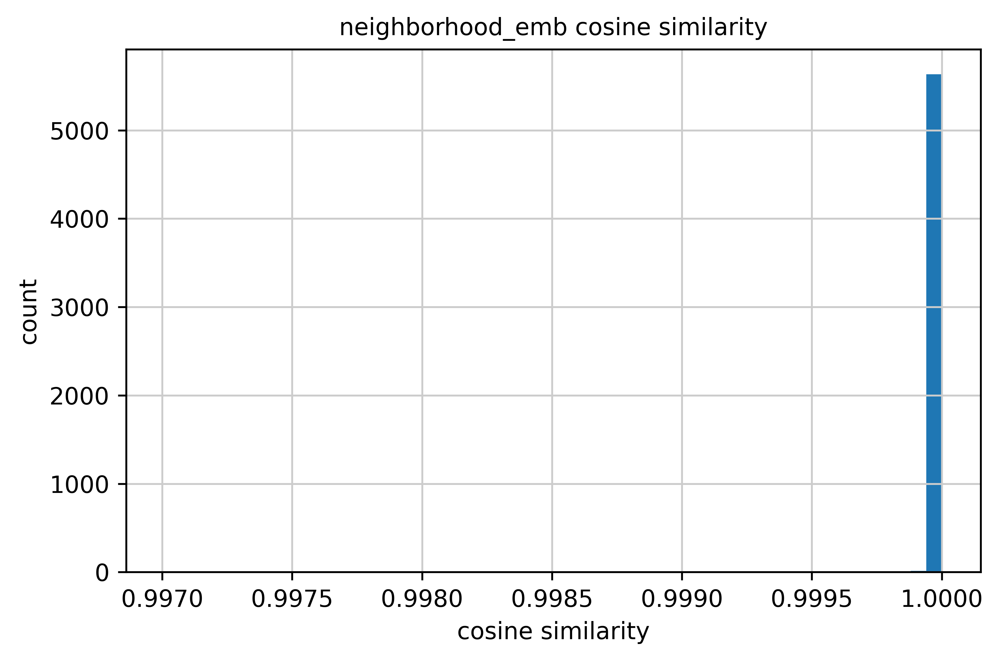

In [421]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [422]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Memory B cell,11,0.992672,0.999157,0.999982
1,CD4+ T cell,36,0.995256,0.999425,0.999988
2,Ascending thin limb,1,0.996668,0.999630,0.999987
3,Conventional dendritic cell,14,0.997613,0.999758,0.999994
4,Neuron,28,0.997732,0.999634,0.999988
5,Plasmacytoid dendritic cell,2,0.997732,0.999966,0.999997
6,Principal cell,147,0.997810,0.999737,0.999846
7,Descending thin limb,29,0.998061,0.999796,0.999992
8,Basophil / Mast cell,1,0.998484,0.999965,0.999997
9,CD14+ monocyte,4,0.998496,0.999869,0.999982


In [423]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Injured proximal nephron neighborhood,144,0.998893,0.999908,0.999969
1,Loop of Henle neighborhood,440,0.999073,0.999915,0.999997
2,Fibrovascular neighborhood,1055,0.999252,0.999920,0.999994
3,Proximal nephron neighborhood,2558,0.999261,0.999919,0.999996
4,Glomerular neighborhood,637,0.999297,0.999942,0.999997
5,Distal nephron neighborhood,842,0.999434,0.999941,0.999966


In [424]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99926525
Spatial cell embedding average: 0.99992454
Neighborhood embedding average: 0.9999909
Lowest cell embedding average per cell type: 0.9926716089248657
Lowest spatial cell embedding average per cell type: 0.9991569519042969
Lowest neighborhood embedding average per cell type: 0.9998459815979004
Lowest cell embedding average per niche: 0.9988933205604553
Lowest spatial cell embedding average per niche: 0.9999077916145325
Lowest neighborhood embedding average per niche: 0.9999657273292542


#### 2.5.12.2 Neighborhood Perturbations

In [425]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

Filter: 100%|████████████████████████████████████████████| 58926/58926 [00:01<00:00, 33110.91 examples/s]


In [426]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

58926


In [427]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999929  min=0.968483


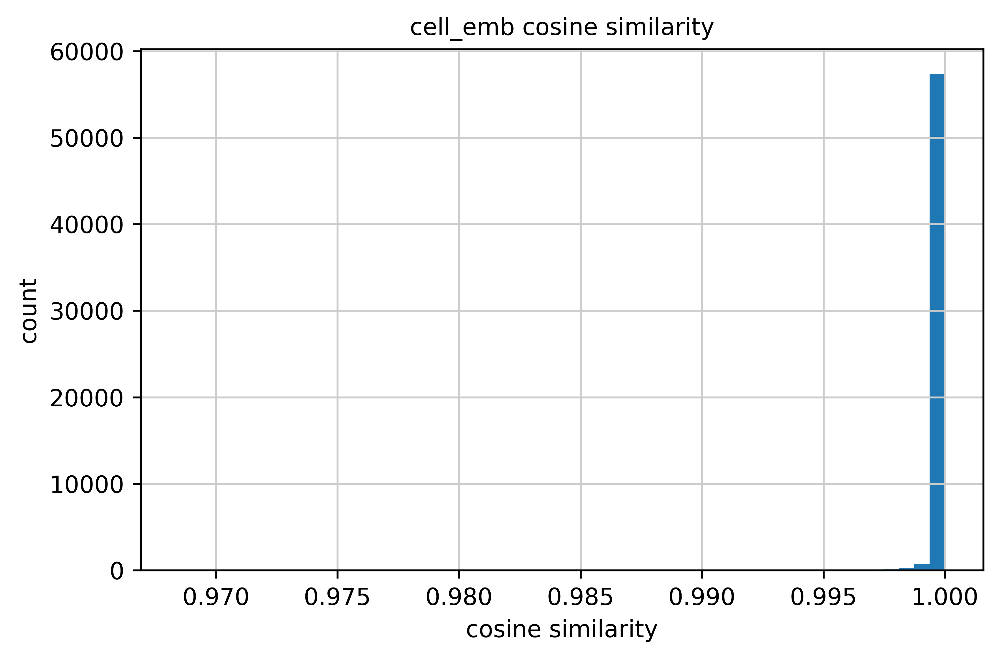

spatial_cell_emb: mean=0.999989  min=0.995937


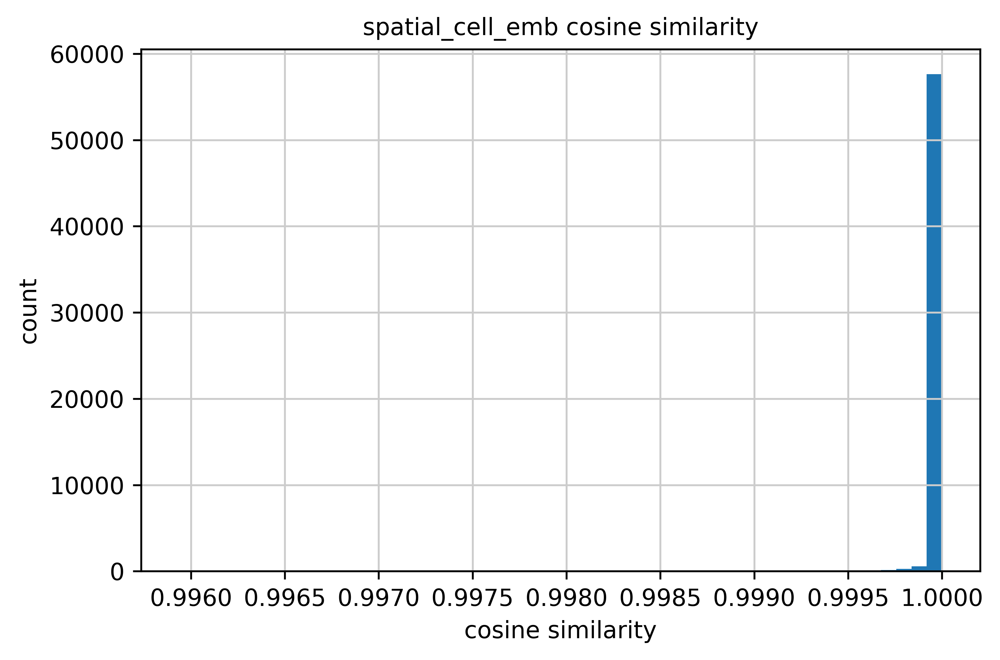

neighborhood_emb: mean=0.999995  min=0.996886


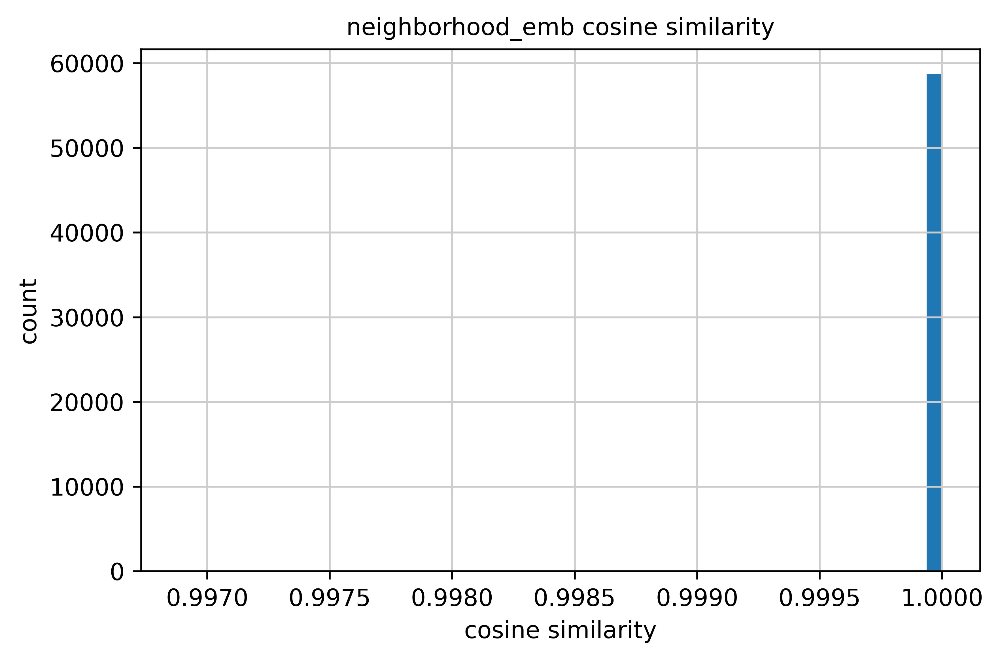

In [428]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [429]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Principal cell,1237,0.999740,0.999960,0.999973
1,Naive B cell,120,0.999945,0.999981,0.999983
2,Memory B cell,145,0.999444,0.999925,0.999986
3,CD4+ T cell,655,0.999739,0.999957,0.999987
4,CD8+ T cell,574,0.999864,0.999979,0.999990
5,Neuron,160,0.999603,0.999929,0.999990
6,Descending thin limb,566,0.999901,0.999982,0.999991
7,Intercalated cell type A,2038,0.999942,0.999985,0.999992
8,Lymphatic endothelium,63,0.999928,0.999990,0.999993
9,CD14+ monocyte,16,0.999624,0.999965,0.999994


In [430]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Distal nephron neighborhood,842,0.999434,0.999941,0.999966
1,Injured proximal nephron neighborhood,144,0.998893,0.999908,0.999969
2,Fibrovascular neighborhood,1055,0.999252,0.999920,0.999994
3,Proximal nephron neighborhood,2558,0.999261,0.999919,0.999996
4,Loop of Henle neighborhood,440,0.999073,0.999915,0.999997
5,Glomerular neighborhood,637,0.999297,0.999942,0.999997


In [431]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99992925
Spatial cell embedding average: 0.9999892
Neighborhood embedding average: 0.9999953
Lowest cell embedding average per cell type: 0.9988660216331482
Lowest spatial cell embedding average per cell type: 0.9999250769615173
Lowest neighborhood embedding average per cell type: 0.9999725818634033
Lowest cell embedding average per niche: 0.9988933205604553
Lowest spatial cell embedding average per niche: 0.9999077916145325
Lowest neighborhood embedding average per niche: 0.9999657273292542


### 2.5.13 Perturbation Case 13 (CSF1R Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - CSF1R (ENSG00000182578)
    - CSF1 (ENSG00000184371)
    - IL34 (ENSG00000157368)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 13
pert_genes = [
    'CSF1R',
    'CSF1',
    'IL34'
]

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [467]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.13.1 Cell Perturbations

In [468]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

Filter: 100%|███████████████████████████████████████████| 304343/304343 [01:05<00:00, 4678.95 examples/s]


In [469]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

41633


In [470]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [471]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

KeyError: 'cell_emb_perturb_case13'

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

#### 2.5.13.2 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

### 2.5.14 Perturbation Case 14 (All Signaling Axes)

Knockout Perturbation:
- Cell & Neighborhood:
    'KDR',
    'VEGFA',
    'VEGFB',
    'FLT4',
    'VEGFC',
    'VEGFD',
    'PDGFRA',
    'PDGFA',
    'PDGFC',
    'PDGFRB',
    'PDGFB',
    'PDGFD',
    'KIT',
    'KITLG',
    'FLT3',
    'FLT3LG',
    'RET',
    'GDNF',
    'CSF1R',
    'CSF1',
    'IL34',
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [118]:
pert_case = 14
pert_genes = [
    'KDR',
    'VEGFA',
    'VEGFB',
    'FLT4',
    'VEGFC',
    'VEGFD',
    'PDGFRA',
    'PDGFA',
    'PDGFC',
    'PDGFRB',
    'PDGFB',
    'PDGFD',
    'KIT',
    'KITLG',
    'FLT3',
    'FLT3LG',
    'RET',
    'GDNF',
    'CSF1R',
    'CSF1',
    'IL34',
]

In [119]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

          ensembl_id
KDR  ENSG00000128052
            ensembl_id
VEGFA  ENSG00000112715
            ensembl_id
VEGFB  ENSG00000173511
           ensembl_id
FLT4  ENSG00000037280
            ensembl_id
VEGFC  ENSG00000150630
            ensembl_id
VEGFD  ENSG00000165197
             ensembl_id
PDGFRA  ENSG00000134853
            ensembl_id
PDGFA  ENSG00000197461
            ensembl_id
PDGFC  ENSG00000145431
             ensembl_id
PDGFRB  ENSG00000113721
            ensembl_id
PDGFB  ENSG00000100311
            ensembl_id
PDGFD  ENSG00000170962
          ensembl_id
KIT  ENSG00000157404
            ensembl_id
KITLG  ENSG00000049130
           ensembl_id
FLT3  ENSG00000122025
             ensembl_id
FLT3LG  ENSG00000090554
          ensembl_id
RET  ENSG00000165731
           ensembl_id
GDNF  ENSG00000168621
            ensembl_id
CSF1R  ENSG00000182578
           ensembl_id
CSF1  ENSG00000184371
           ensembl_id
IL34  ENSG00000157368


In [448]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [449]:
perturbed_dataset[530383]
adata_cell = adata[adata.obs['cell_id'] == 'CV6-KID-0-FT-5-S3_1007_batch24_47039-slice9']
cosine_sim_per_row(adata_cell.obsm['cell_emb'], adata_cell.obsm['cell_emb_perturb_case14'])

array([0.99783015], dtype=float32)

#### 2.5.14.1 Cell Perturbations

In [450]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [451]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

395248


In [452]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.998045  min=0.874611


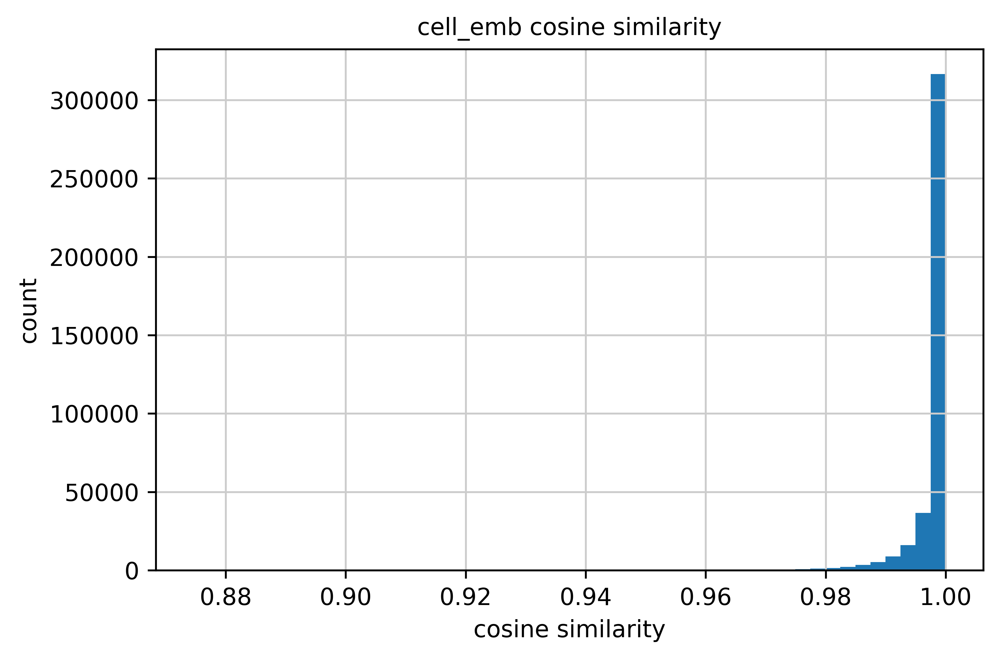

spatial_cell_emb: mean=0.999521  min=0.958161


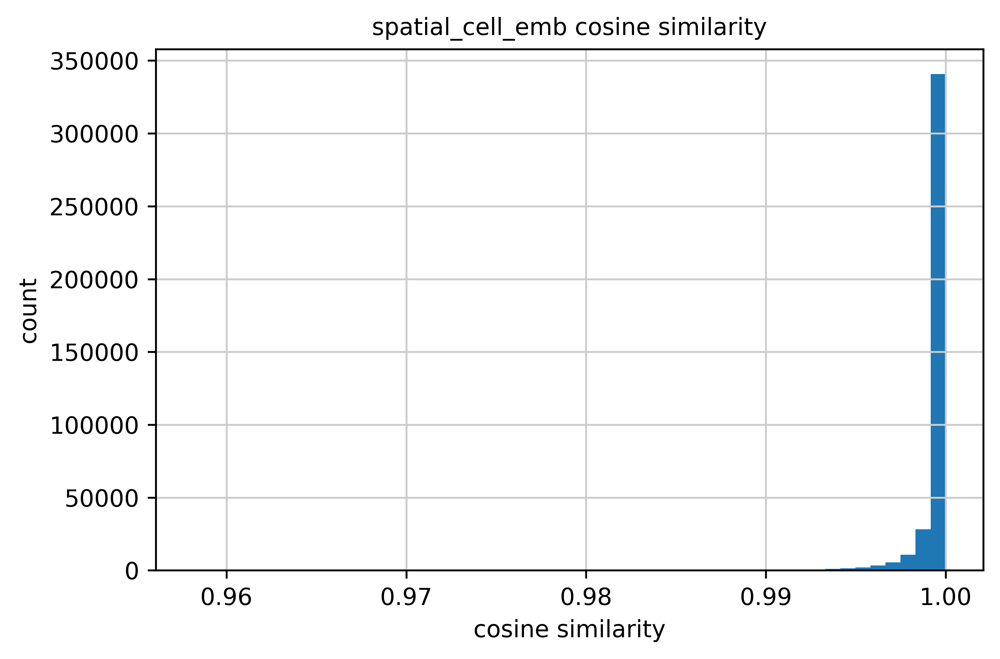

neighborhood_emb: mean=0.999638  min=0.961471


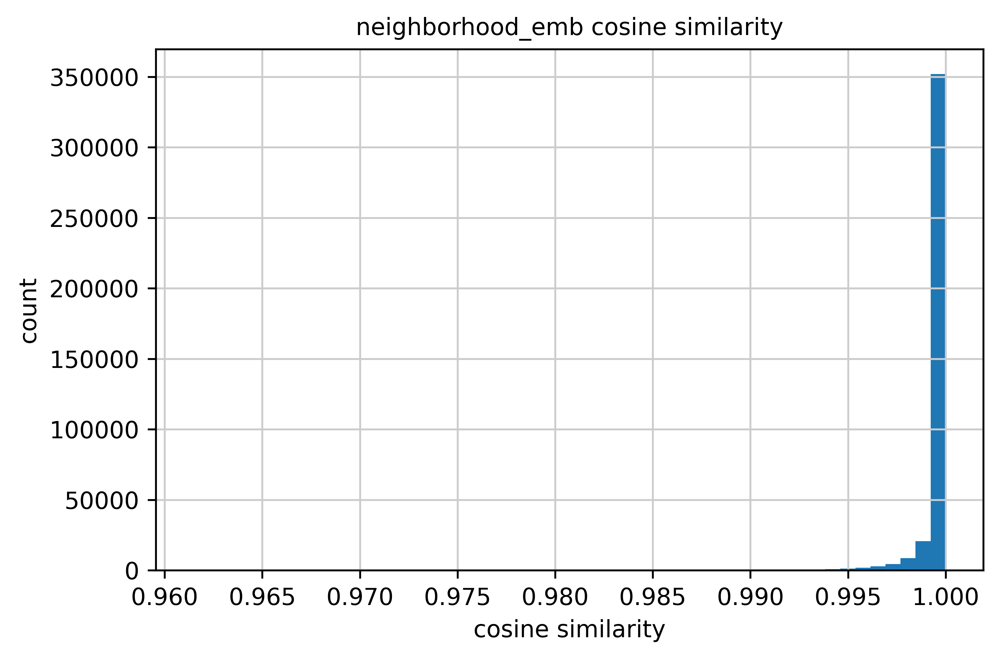

In [453]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [454]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Memory B cell,353,0.993178,0.998981,0.999535
1,Neuron,692,0.993759,0.999145,0.999576
2,CD16+ monocyte,35,0.993795,0.999018,0.999653
3,CD4+ T cell,1722,0.994121,0.998995,0.999411
4,Fibroblast,696,0.995280,0.999178,0.999287
5,Vascular mural cell,35426,0.995312,0.999400,0.999631
6,CD8+ T cell,2704,0.995956,0.999229,0.999374
7,Myofibroblast,45940,0.996491,0.999173,0.999283
8,Natural killer cell,109,0.996604,0.999513,0.999582
9,CD14+ monocyte,94,0.996640,0.999479,0.999678


In [455]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Injured proximal nephron neighborhood,9754,0.997538,0.999270,0.999406
1,Fibrovascular neighborhood,69252,0.997591,0.999361,0.999513
2,Glomerular neighborhood,68840,0.997887,0.999749,0.999831
3,Proximal nephron neighborhood,125322,0.997964,0.999717,0.999859
4,Loop of Henle neighborhood,40797,0.998169,0.999665,0.999768
5,Distal nephron neighborhood,81283,0.998691,0.999119,0.999201


In [456]:
print(f"Cell embedding average: {str(results['cell_emb'][results['cell_emb'] != 0].mean())}")
print(f"Spatial cell embedding average: {str(results['spatial_cell_emb'][results['spatial_cell_emb'] != 0].mean())}")
print(f"Neighborhood embedding average: {str(results['neighborhood_emb'][results['neighborhood_emb'] != 0].mean())}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99804527
Spatial cell embedding average: 0.9995207
Neighborhood embedding average: 0.99963754
Lowest cell embedding average per cell type: 0.9931782484054565
Lowest spatial cell embedding average per cell type: 0.998698890209198
Lowest neighborhood embedding average per cell type: 0.9987568259239197
Lowest cell embedding average per niche: 0.9975375533103943
Lowest spatial cell embedding average per niche: 0.9991186261177063
Lowest neighborhood embedding average per niche: 0.9992008209228516


#### 2.5.14.2 Neighborhood Perturbations

In [457]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [458]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

973830


In [459]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999207  min=0.874611


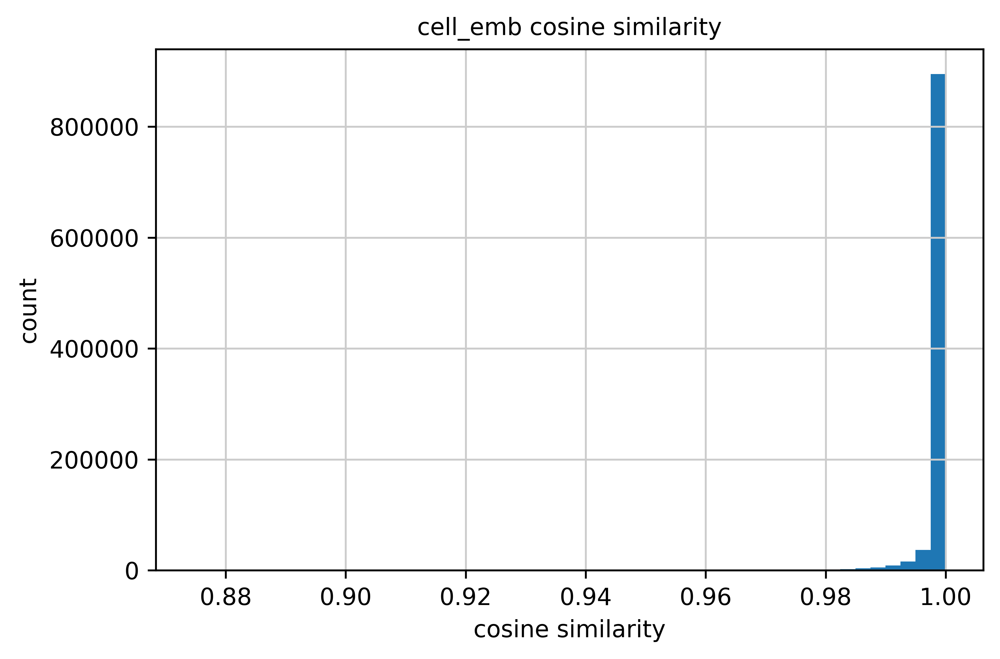

spatial_cell_emb: mean=0.999675  min=0.958161


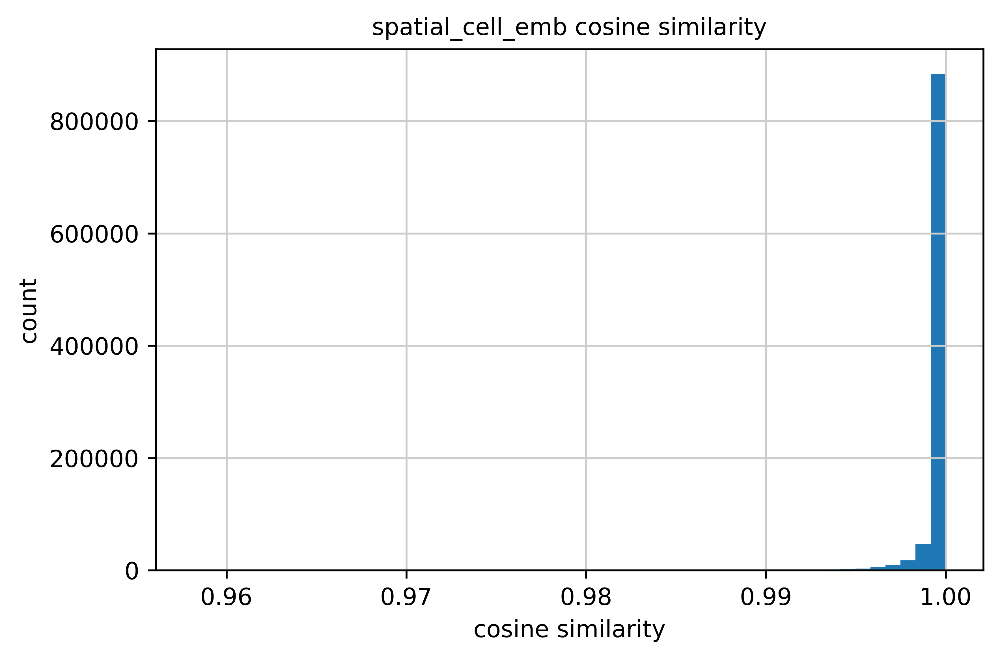

neighborhood_emb: mean=0.999732  min=0.961471


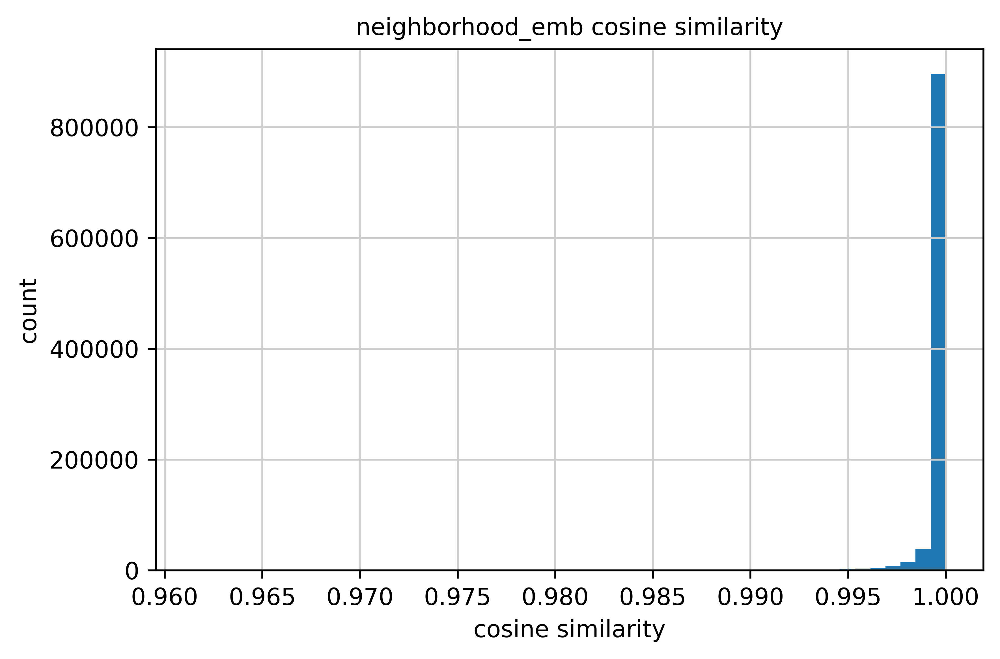

In [460]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [462]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Basophil / Mast cell,56,0.998671,0.998825,0.998862
1,Macula densa,14150,0.999661,0.999142,0.999233
2,Fibroblast,855,0.996158,0.999293,0.999383
3,Ascending thin limb,751,0.999696,0.999303,0.999387
4,Myofibroblast,69740,0.997688,0.999360,0.999433
5,Naive B cell,1754,0.999108,0.999378,0.999440
6,Conventional dendritic cell,3325,0.998653,0.999406,0.999496
7,Macrophage,35737,0.998459,0.999438,0.999510
8,Principal cell,27248,0.999490,0.999462,0.999531
9,Distal convoluted tubule 2,10173,0.999560,0.999466,0.999542


In [463]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Distal nephron neighborhood,81283,0.998691,0.999119,0.999201
1,Injured proximal nephron neighborhood,9754,0.997538,0.999270,0.999406
2,Fibrovascular neighborhood,69252,0.997591,0.999361,0.999513
3,Loop of Henle neighborhood,40797,0.998169,0.999665,0.999768
4,Glomerular neighborhood,68840,0.997887,0.999749,0.999831
5,Proximal nephron neighborhood,125322,0.997964,0.999717,0.999859


In [464]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.9992066
Spatial cell embedding average: 0.9996751
Neighborhood embedding average: 0.9997324
Lowest cell embedding average per cell type: 0.996157705783844
Lowest spatial cell embedding average per cell type: 0.9988247156143188
Lowest neighborhood embedding average per cell type: 0.9988621473312378
Lowest cell embedding average per niche: 0.9975375533103943
Lowest spatial cell embedding average per niche: 0.9991186261177063
Lowest neighborhood embedding average per niche: 0.9992008209228516


### 2.5.15 Perturbation Case 15 (50% Random Genes)

Knockout Perturbation:
- Cell & Neighborhood
    - 50% Random Genes
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [33]:
random.seed(42)
all_genes = adata.var_names.tolist()
sampled_genes = random.sample(all_genes, k=len(all_genes)//2)

In [34]:
pert_case = 15
pert_genes = sampled_genes
len(pert_genes)

2474

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [35]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.15.1 Cell Perturbations

In [ ]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

Filter:  27%|██▋       | 291000/1081189 [45:02<2:01:43, 108.19 examples/s]

In [ ]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

In [ ]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.891517  min=0.000000


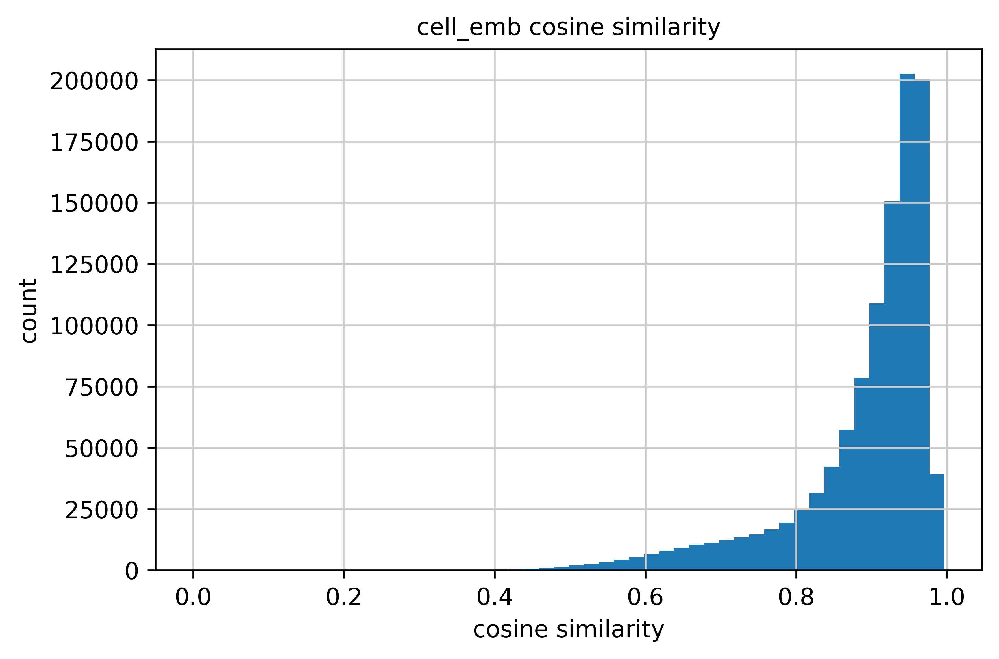

spatial_cell_emb: mean=0.920667  min=0.000000


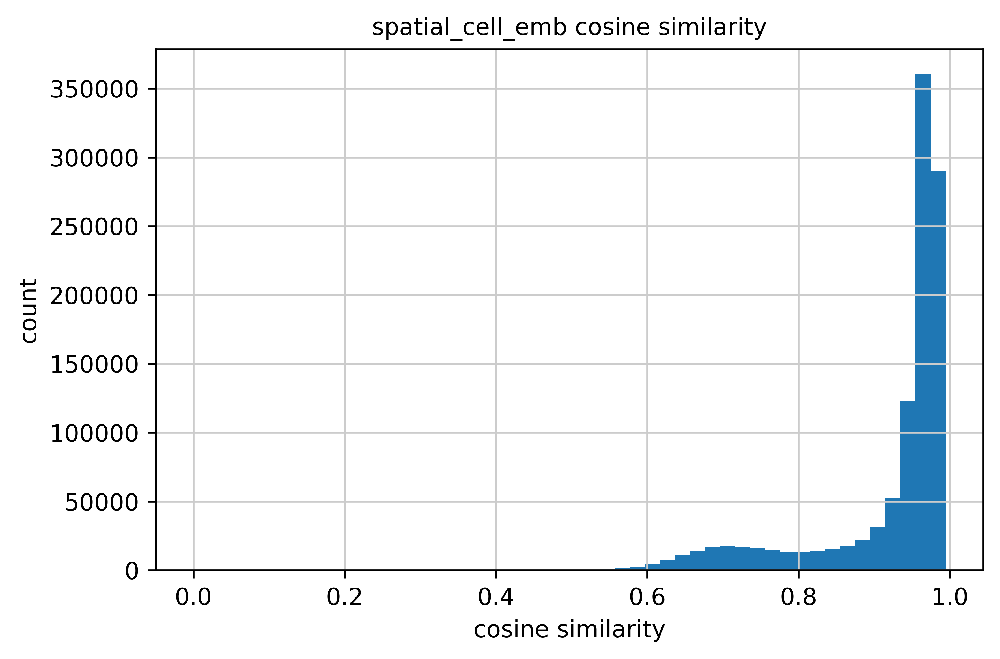

neighborhood_emb: mean=0.924916  min=0.400634


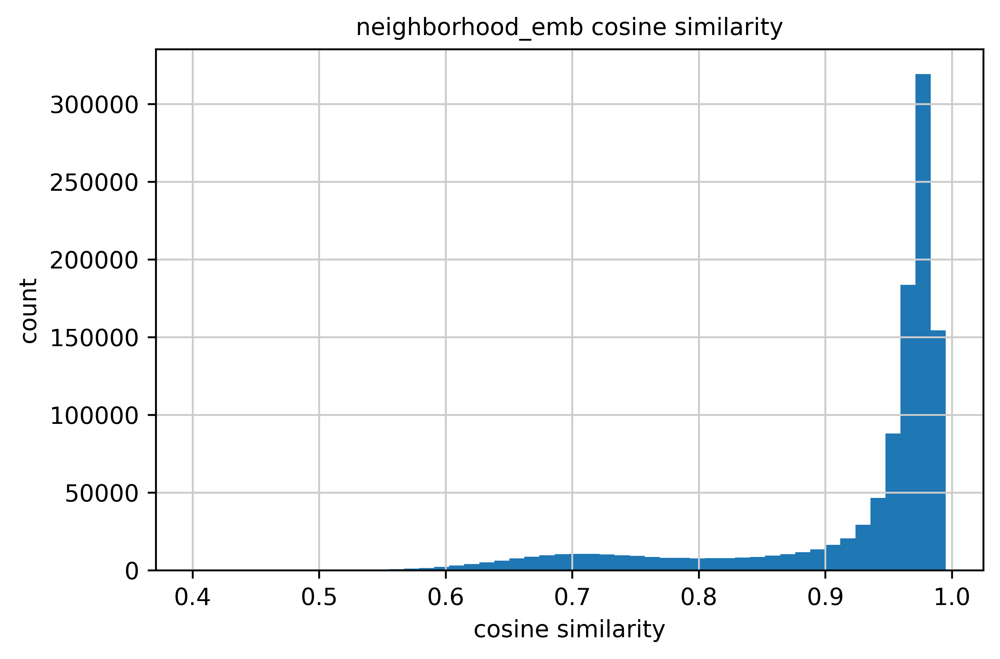

In [44]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [45]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Cortical thick ascending limb,86026,0.705831,0.739816,0.746279
1,Medullary thick ascending limb,43494,0.795226,0.822226,0.828056
2,Parietal epithelial cell,6452,0.839098,0.919286,0.922021
3,Mesangial cell,13385,0.841371,0.948766,0.951422
4,Fibroblast,865,0.850549,0.919324,0.921100
5,Plasma cell,580,0.857784,0.886231,0.892087
6,Macula densa,14831,0.858431,0.873833,0.878498
7,Basophil / Mast cell,57,0.868941,0.922811,0.921607
8,Descending thin limb,17491,0.874538,0.894334,0.900971
9,Myofibroblast,71133,0.875619,0.918806,0.921598


In [46]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Loop of Henle neighborhood,141938,0.759587,0.713668,0.715089
1,Glomerular neighborhood,105605,0.876406,0.932549,0.935712
2,Injured proximal nephron neighborhood,21174,0.901391,0.937685,0.942154
3,Fibrovascular neighborhood,161045,0.903055,0.949970,0.955658
4,Distal nephron neighborhood,155325,0.911494,0.946137,0.948663
5,Proximal nephron neighborhood,496094,0.922059,0.959149,0.964500


In [47]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.89151686
Spatial cell embedding average: 0.9206665
Neighborhood embedding average: 0.92491585
Lowest cell embedding average per cell type: 0.7058306932449341
Lowest spatial cell embedding average per cell type: 0.7398163676261902
Lowest neighborhood embedding average per cell type: 0.7462794184684753
Lowest cell embedding average per niche: 0.7595872282981873
Lowest spatial cell embedding average per niche: 0.713668167591095
Lowest neighborhood embedding average per niche: 0.7150892019271851


#### 2.5.15.2 Neighborhood Perturbations

In [353]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [354]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

546150


In [355]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999639  min=0.922568


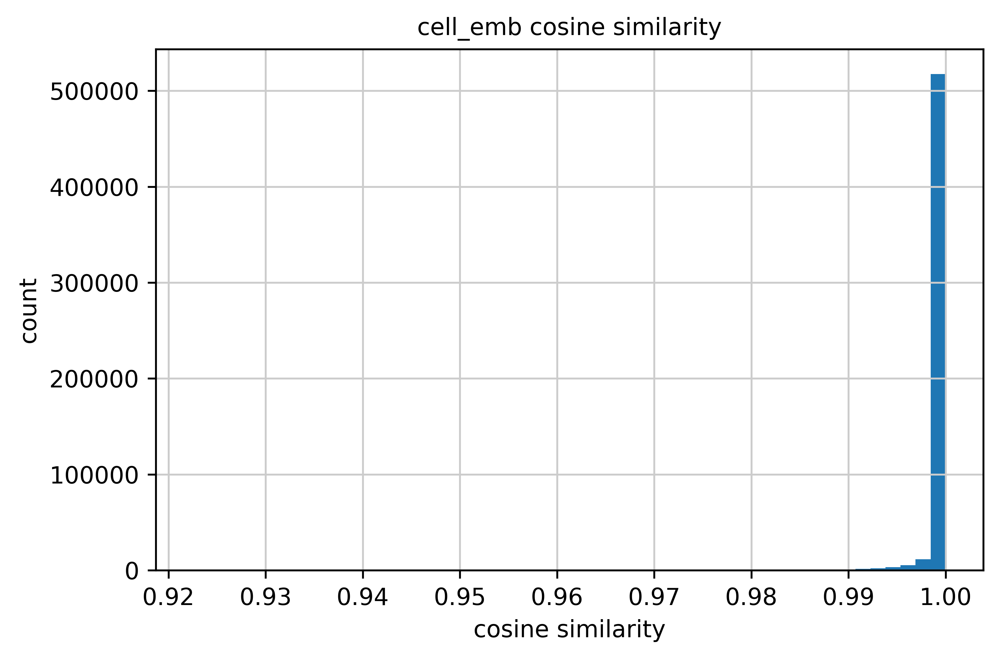

spatial_cell_emb: mean=0.999924  min=0.991752


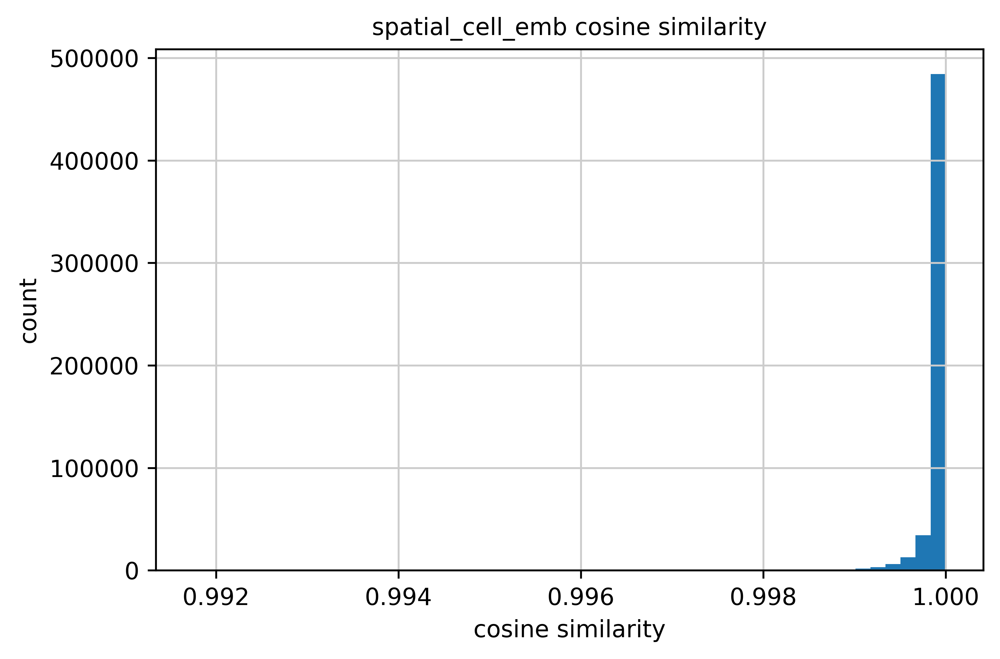

neighborhood_emb: mean=0.999945  min=0.995517


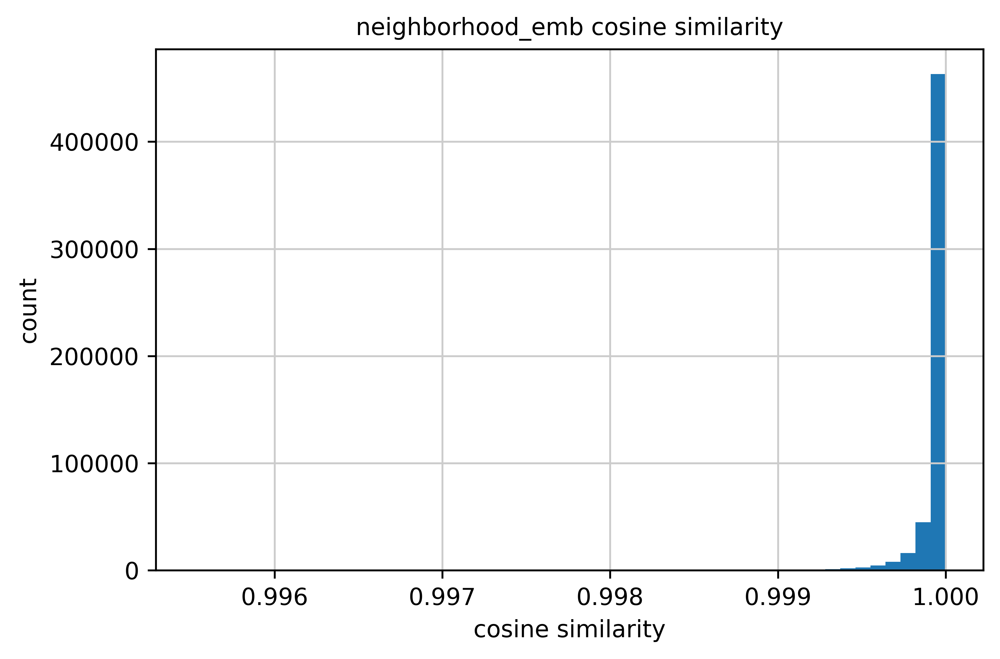

In [356]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [357]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,CD16+ monocyte,65,0.999924,0.999902,0.999894
1,Neuron,1396,0.998847,0.999838,0.999898
2,CD4+ T cell,6097,0.999862,0.999901,0.999904
3,Proximal tubule segment 1,34921,0.999911,0.999893,0.999912
4,Memory B cell,1397,0.999812,0.999906,0.999915
5,Proximal tubule segment 2,8670,0.999828,0.999898,0.999915
6,Proximal tubule segment 3,56159,0.999903,0.999900,0.999917
7,CDH13+ stromal cell,4953,0.999406,0.999890,0.999918
8,Injured proximal tubule,28684,0.999922,0.999911,0.999925
9,Vascular mural cell,51415,0.998213,0.999833,0.999928


In [358]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Proximal nephron neighborhood,24684,0.997284,0.999748,0.999889
1,Fibrovascular neighborhood,24215,0.998136,0.999813,0.999929
2,Injured proximal nephron neighborhood,3117,0.998840,0.999878,0.999946
3,Glomerular neighborhood,30801,0.998484,0.999903,0.999958
4,Distal nephron neighborhood,16718,0.999022,0.999931,0.999970
5,Loop of Henle neighborhood,8143,0.997718,0.999859,0.999974


In [359]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.9996386
Spatial cell embedding average: 0.9999245
Neighborhood embedding average: 0.99994504
Lowest cell embedding average per cell type: 0.9982132315635681
Lowest spatial cell embedding average per cell type: 0.9998332262039185
Lowest neighborhood embedding average per cell type: 0.9998935461044312
Lowest cell embedding average per niche: 0.9972838759422302
Lowest spatial cell embedding average per niche: 0.9997475743293762
Lowest neighborhood embedding average per niche: 0.9998888969421387


### 2.5.16 Perturbation Case 16 (10% Random Genes)

Knockout Perturbation:
- Cell & Neighborhood
    - 10% Random Genes
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [361]:
random.seed(42)
all_genes = adata.var_names.tolist()
sampled_genes = random.sample(all_genes, k=len(all_genes)//10)

In [ ]:
pert_case = 16
pert_genes = sampled_genes
len(pert_genes)

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [365]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.16.1 Cell Perturbations

In [372]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [373]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

1060314


In [374]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb: mean=0.990914  min=0.465491


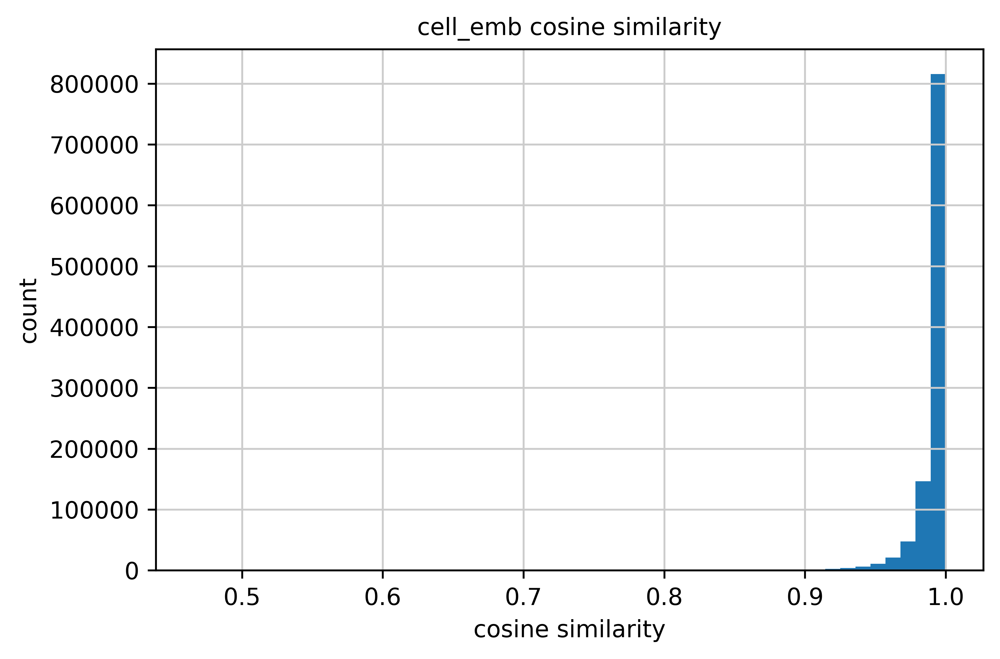

spatial_cell_emb: mean=0.995080  min=0.791256


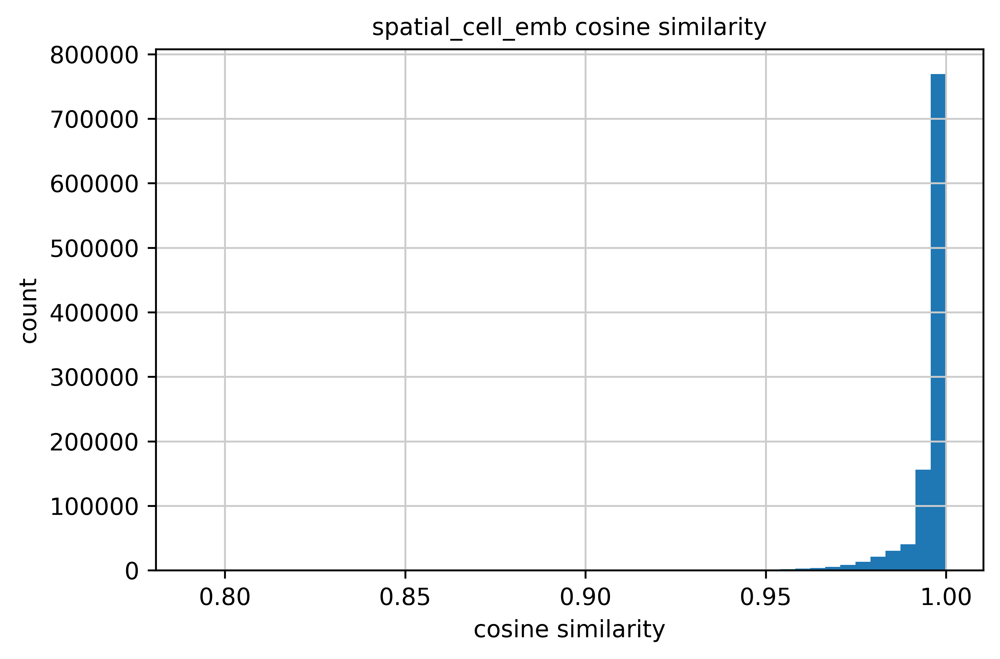

neighborhood_emb: mean=0.995469  min=0.786606


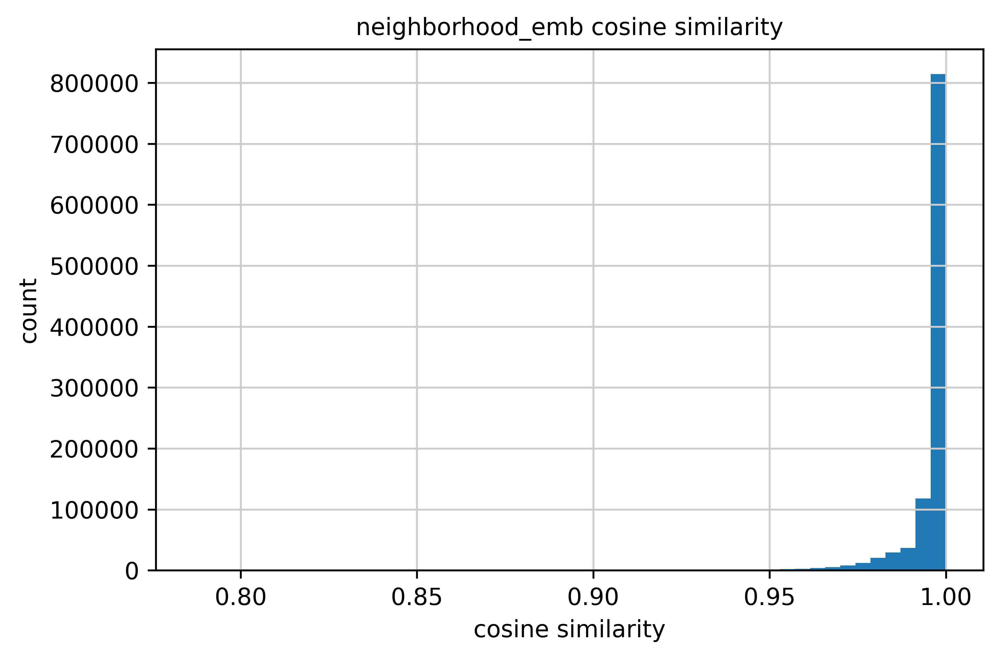

In [375]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [376]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Podocyte,32096,0.951359,0.979725,0.979802
1,Plasmacytoid dendritic cell,31,0.982479,0.982316,0.982216
2,Plasma cell,580,0.983550,0.993552,0.993948
3,Parietal epithelial cell,6402,0.983975,0.981506,0.981773
4,Naive B cell,1827,0.985660,0.990203,0.989766
5,Glomerular endothelial cell,47637,0.986083,0.989726,0.990209
6,CD14+ monocyte,264,0.986634,0.991508,0.992035
7,Basophil / Mast cell,57,0.987245,0.996004,0.995712
8,Mesangial cell,13304,0.988382,0.984840,0.985117
9,Memory B cell,3491,0.988538,0.994268,0.995159


In [377]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Glomerular neighborhood,104363,0.975444,0.979706,0.980090
1,Injured proximal nephron neighborhood,21039,0.988082,0.990728,0.990278
2,Proximal nephron neighborhood,481531,0.991671,0.996564,0.997107
3,Fibrovascular neighborhood,158617,0.992049,0.995468,0.995753
4,Distal nephron neighborhood,154714,0.994713,0.997866,0.998024
5,Loop of Henle neighborhood,140050,0.994782,0.998565,0.998936


In [378]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.9909142
Spatial cell embedding average: 0.99507964
Neighborhood embedding average: 0.99546915
Lowest cell embedding average per cell type: 0.9513590335845947
Lowest spatial cell embedding average per cell type: 0.979724645614624
Lowest neighborhood embedding average per cell type: 0.9798015356063843
Lowest cell embedding average per niche: 0.9754436612129211
Lowest spatial cell embedding average per niche: 0.9797064065933228
Lowest neighborhood embedding average per niche: 0.9800897240638733


#### 2.5.16.2 Neighborhood Perturbations

In [353]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [354]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

546150


In [355]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

cell_emb: mean=0.999639  min=0.922568


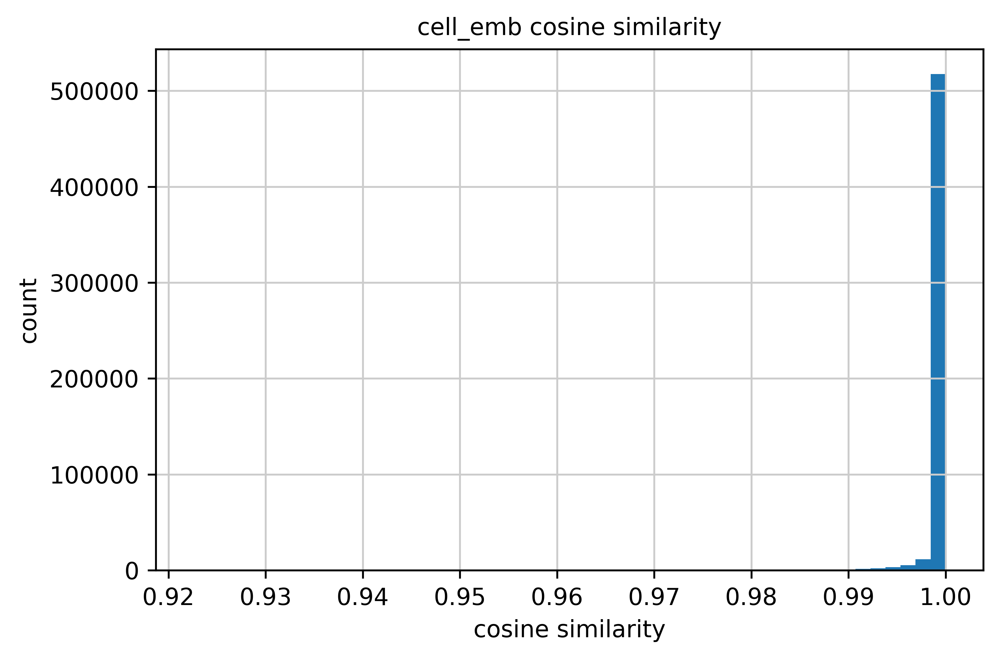

spatial_cell_emb: mean=0.999924  min=0.991752


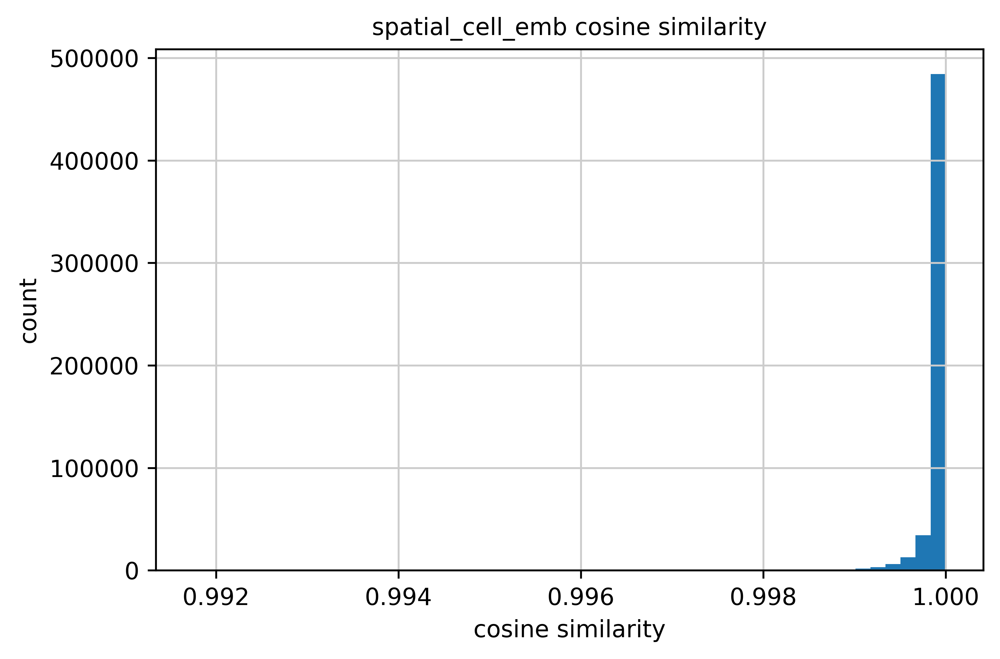

neighborhood_emb: mean=0.999945  min=0.995517


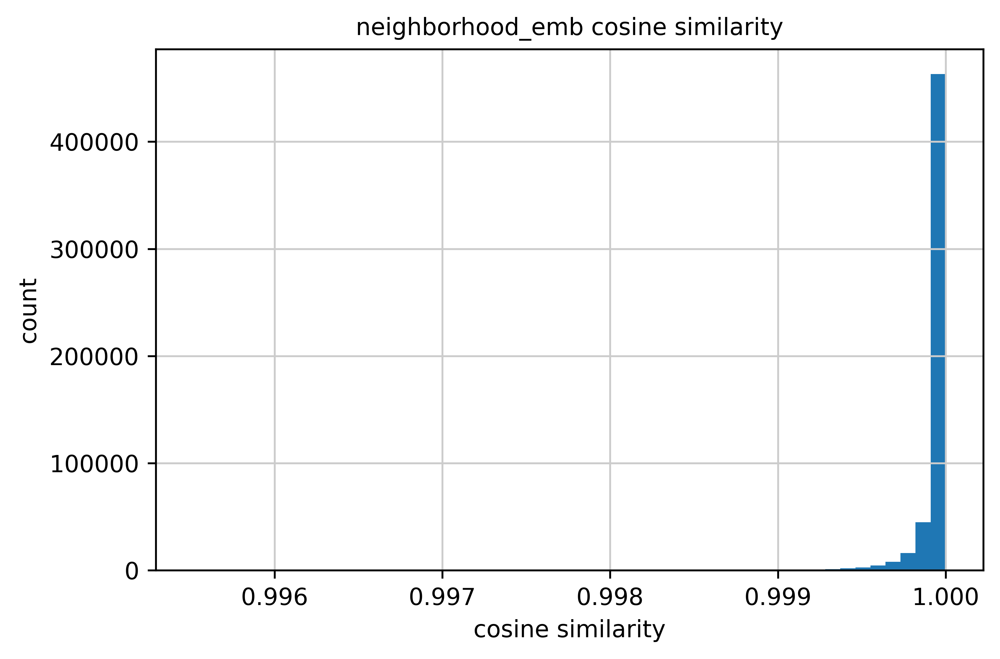

In [356]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [357]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,CD16+ monocyte,65,0.999924,0.999902,0.999894
1,Neuron,1396,0.998847,0.999838,0.999898
2,CD4+ T cell,6097,0.999862,0.999901,0.999904
3,Proximal tubule segment 1,34921,0.999911,0.999893,0.999912
4,Memory B cell,1397,0.999812,0.999906,0.999915
5,Proximal tubule segment 2,8670,0.999828,0.999898,0.999915
6,Proximal tubule segment 3,56159,0.999903,0.999900,0.999917
7,CDH13+ stromal cell,4953,0.999406,0.999890,0.999918
8,Injured proximal tubule,28684,0.999922,0.999911,0.999925
9,Vascular mural cell,51415,0.998213,0.999833,0.999928


In [358]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Proximal nephron neighborhood,24684,0.997284,0.999748,0.999889
1,Fibrovascular neighborhood,24215,0.998136,0.999813,0.999929
2,Injured proximal nephron neighborhood,3117,0.998840,0.999878,0.999946
3,Glomerular neighborhood,30801,0.998484,0.999903,0.999958
4,Distal nephron neighborhood,16718,0.999022,0.999931,0.999970
5,Loop of Henle neighborhood,8143,0.997718,0.999859,0.999974


In [359]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.9996386
Spatial cell embedding average: 0.9999245
Neighborhood embedding average: 0.99994504
Lowest cell embedding average per cell type: 0.9982132315635681
Lowest spatial cell embedding average per cell type: 0.9998332262039185
Lowest neighborhood embedding average per cell type: 0.9998935461044312
Lowest cell embedding average per niche: 0.9972838759422302
Lowest spatial cell embedding average per niche: 0.9997475743293762
Lowest neighborhood embedding average per niche: 0.9998888969421387


## 2.6 Decode Counts

In [ ]:
import anndata as ad
from app.count_decoder import apply_count_decoder
from app.count_decoder import _spot_level_metrics, _apply_metric_transform, _to_dense
import numpy as np

adata_path = "/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/kidney_perturbation/nemokidneyxeniumatlas_annotated_processed.h5ad"
checkpoint_path = "results/zinb_decoder.pt"  # or a folder with zinb_decoder.pt inside
emb_key = "cell_emb"
checkpoint_path = "results_neb/zinb_decoder.pt"  # or a folder with zinb_decoder.pt inside
emb_key="neighborhood_emb"

adata = ad.read_h5ad(adata_path)

adata = apply_count_decoder(
    adata,
    emb_key=emb_key,
    model_folder_path=checkpoint_path,  # can be folder or exact file
    decoded_counts_layer_key="decoded_counts",
    # optional overrides:
    # loss_type="nb_softplus",
    # device=0,
    # batch_size=1024,
)
 
preds = _to_dense(adata.layers["decoded_counts"])
target = _to_dense(adata.layers["counts"])
target = _to_dense(adata.layers["counts_neighborhood"])

# optional: same transform used in training metrics
preds = _apply_metric_transform(preds, "none")  # or "log1p"
target = _apply_metric_transform(target, "none")

spot_metrics = _spot_level_metrics(preds, target)
print(spot_metrics)

adata.write_h5ad("/path/to/output_with_decoded_counts.h5ad")

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='neighborhood_emb',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results_neb/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_neighborhood')

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='cell_emb',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_cell'

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='neighborhood_emb_perturb_case1',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results_neb/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_perturbed_neighborhood_case1'

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='cell_emb_perturb_case1',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_perturbed_cell_case1'

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [ ]:
diff testing dec_counts_neighborhood <-> dec_counts_perturbed_neighborhood

In [ ]:
# adata.obsm[emb_key] -> adata.layers[decoded_counts_layer_key]

In [ ]:
perturb_df = perturb_df.head(3)

In [ ]:
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    cell_gene_ids=cell_gene_ids,
    neighborhood_gene_ids=neighborhood_gene_ids,
    agg_excluded_genes=agg_excluded_genes,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

In [ ]:
adata.obsm['perturbed_cell_emb'] = perturbed_output_embed['cell_emb']
adata.obsm['perturbed_neighborhood_emb'] = perturbed_output_embed['neighborhood_emb']

In [ ]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_neighborhood_emb',
                key_added='perturbed_neighborhood')
sc.tl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           key_added='perturbed_neighborhood_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_cell_emb',
                key_added='perturbed_cell')
sc.tl.umap(adata,
           neighbors_key='perturbed_cell',
           key_added='perturbed_cell_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_cell_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_cell',
           color=label)

In [ ]:
thresh = 0.99
for i, gene in enumerate(pert_genes):
    cell_pert_indices = [i*2]
    
    filtered_dataset = perturbed_dataset.filter(
        lambda x: any(x[f"pert_flag_idx_{i}"] for i in cell_pert_indices)
    )
    
    cell_pert_cell_ids = list(filtered_dataset['cell_id'])
    
    adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]
    
    A = adata_sub_cell_pert.obsm['cell_emb']
    B = adata_sub_cell_pert.obsm['cell_emb_perturb_case2']
    
    A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
    B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)
    
    cos_sim = np.sum(A_norm * B_norm, axis=1)
    print(f"Gene: {gene}")
    print(f"Mean cosine similarity: {np.mean(cos_sim)}")
    print(f"Min cosine similarity: {np.min(cos_sim)}")
    print(f"Smaller than {thresh}: {int((cos_sim < thresh).sum())}/{cos_sim.shape[0]}")